# Step 0 — Project Objective and Machine-Learning Strategy

## Business Problem

Accurate retail demand forecasting is essential for inventory allocation, replenishment planning, and reducing the risk of stockouts and excess inventory.

Walmart's retail demand varies across stores, product categories, seasonal periods, holidays, SNAP availability, and pricing conditions. Understanding these patterns can help develop more reliable demand predictions.

### Main Business Question

**To what extent can historical demand, seasonal patterns, calendar events, SNAP availability, pricing information, store differences, and product-category differences improve 28-day retail demand forecasts for inventory planning?**

## Project Objectives

This project develops a machine-learning framework using the Walmart M5 dataset, aggregated into **30 store-category time series**.

The analysis addresses two complementary predictive tasks:

1. **Regression forecasting:** Predict daily demand quantities for each store-category combination over a 28-day forecasting horizon.
2. **High-demand classification:** Identify observations where demand exceeds the historical 80th-percentile threshold for the corresponding store-category series, supporting the identification of unusually high-demand periods.

Together, these tasks provide both quantitative demand forecasts and additional information about potential demand surges.

## Machine-Learning Strategy

The forecasting workflow combines several approaches:

- **Forecasting benchmarks:** Seasonal-Naive and Prophet.
- **Regression models:** Linear Regression, Random Forest, Gradient Boosting, HistGradientBoosting, XGBoost, and Extra Trees.
- **Hyperparameter optimization:** Chronological cross-validation to refine Extra Trees.
- **Classification models:** Random Forest and Extra Trees for identifying high-demand observations.
- **Model interpretation:** Feature importance, forecast error analysis, and classification performance assessment.

The final regression approach uses **Tuned Extra Trees**, selected through the model-development and cross-validation process.

## Validation and Evaluation

The analysis uses chronological training, validation, and test periods, with separate **28-day validation and test windows**.

Regression performance is evaluated using **MAE, RMSE, WAPE, and R²**.

Classification performance is evaluated using **accuracy, precision, recall, F1-score, ROC-AUC, and confusion matrices**, including probability-threshold analysis.

Prophet is evaluated separately at the aggregate daily-demand level because its forecasting granularity differs from the store-category regression models.

## Expected Business Value

The project aims to assess whether machine-learning approaches can improve forecasting performance relative to simpler benchmarks and provide useful information for:

- Store-category inventory allocation.
- Replenishment planning.
- Identifying unusually high-demand periods.
- Understanding forecast errors and operational risks.

The analysis evaluates predictive performance; actual reductions in inventory costs or stockouts would require further operational validation.

# Step 1 — Import Libraries

This section imports the Python libraries required to develop, evaluate, and interpret the retail demand forecasting and high-demand classification models.

The workflow uses:

- **Pandas and NumPy:** Data manipulation, numerical operations, and feature preparation.
- **Matplotlib and Seaborn:** Exploratory visualizations, model comparisons, and prediction diagnostics.
- **Scikit-learn:** Regression and classification algorithms, evaluation metrics, and model selection utilities.
- **XGBoost:** Gradient-boosted regression for retail demand forecasting.
- **Prophet:** Time-series forecasting of aggregate daily demand.
- **Time:** Measuring computational performance during model development.

A fixed random seed is established to support reproducibility where the models use random processes.

These libraries support the comparison of forecasting approaches and the complementary classification analysis developed later in the notebook.

In [1]:
# Step 1 Data manipulation
import pandas as pd
import numpy as np
import re

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

import time

# XGBoost model
from xgboost import XGBRegressor, XGBClassifier

# Regression models
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    HistGradientBoostingRegressor,
    ExtraTreesRegressor
)

from sklearn.model_selection import ParameterSampler


# Classification models
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, ExtraTreesClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    roc_auc_score,
    confusion_matrix,
    mean_squared_error,
    mean_absolute_error,
    r2_score,
    classification_report
)

from prophet import Prophet

from sklearn.model_selection import ParameterSampler

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

# Visualization style
sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

# Standard seed used throughout the notebook for reproducibility
SEED = 1

Libraries imported successfully.


# Step 2 - Load the Cleaned Dataset

This section loads the cleaned Walmart M5 dataset prepared in the Data Cleaning notebook and analyzed in the Exploratory Data Analysis (EDA) notebook.

The dataset is aggregated at the **store × category × day** level, meaning each observation represents the total number of units sold for a product category within a particular store on a specific date.

### Dataset Overview

| Characteristic | Description |
|---|---|
| Historical period | 2011-01-29 to 2016-04-24 |
| Total observations | 57,390 |
| Unique stores | 10 |
| States | 3 (CA, TX, WI) |
| Product categories | 3 (FOODS, HOUSEHOLD, HOBBIES) |
| Forecasting series | 30 store-category combinations |
| Historical days | 1,913 |
| Target variable | `demand` — daily units sold |

The dataset includes historical demand, calendar information, event indicators, SNAP availability, and pricing variables.

### Connection to the EDA

The EDA identified substantial differences in demand across stores, categories, weekdays, seasonal periods, and promotional or calendar-related conditions.

These findings motivate the inclusion of historical demand, temporal, categorical, SNAP, event, and pricing features in the forecasting models.

### Purpose

Loading this dataset establishes a consistent foundation for the subsequent regression forecasting and high-demand classification analyses.

The dataset's structure also enables predictions and performance evaluation at the store-category level, supporting more targeted inventory planning.

In [2]:
# Step 2: Path to the cleaned dataset
file_path = "../outputs/m5_cleaned_store_category_daily.csv"

# Load dataset
df = pd.read_csv(file_path)

# Convert date to datetime
df["date"] = pd.to_datetime(df["date"])

print("Cleaned dataset loaded successfully.")
print("Shape:", df.shape)
print("Date range:", df["date"].min(), "to", df["date"].max())

Cleaned dataset loaded successfully.
Shape: (57390, 19)
Date range: 2011-01-29 00:00:00 to 2016-04-24 00:00:00


# Step 3 — Verify the Forecasting Grain

Before developing the forecasting models, the dataset must be verified to ensure that each observation represents a unique **store × category × day** combination.

The dataset is expected to contain:

- **10 stores** across California, Texas, and Wisconsin.
- **3 product categories:** FOODS, HOUSEHOLD, and HOBBIES.
- **30 store-category time series**, each covering 1,913 historical days.
- **57,390 observations** in total.

### Validation Checks

This step checks for duplicate records using `store_id`, `category`, and `date`, and verifies the number of unique forecasting series.

These checks are important because duplicate observations could distort historical demand patterns, lagged features, and model evaluation.

### Business Relevance

Maintaining a consistent forecasting grain allows the models to predict demand separately for each store-category combination, supporting more targeted inventory allocation and replenishment decisions.

In [3]:
# Step 3: Check for duplicate store-category-date observations
duplicate_count = df.duplicated(
    subset=["store_id", "category", "date"]
).sum()

print("Duplicate store-category-day observations:", duplicate_count)

# Number of unique forecasting series
series_count = df[
    ["store_id", "category"]
].drop_duplicates().shape[0]

print("Number of store-category forecasting series:", series_count)

Duplicate store-category-day observations: 0
Number of store-category forecasting series: 30


In [4]:

# Step3.1 Verify complete daily coverage for every store-category series

series_coverage = (
    df.groupby(["store_id", "category"])
      .agg(
          observed_days=("date", "nunique"),
          first_date=("date", "min"),
          last_date=("date", "max")
      )
      .reset_index()
)

expected_days = df["date"].nunique()

series_coverage["missing_days"] = (
    expected_days - series_coverage["observed_days"]
)

print("Expected days per series:", expected_days)
print("Number of store-category series:", len(series_coverage))
print("Series with missing dates:",
      (series_coverage["missing_days"] > 0).sum())

display(series_coverage)


Expected days per series: 1913
Number of store-category series: 30
Series with missing dates: 0


,store_id,category,observed_days,first_date,last_date,missing_days
0,CA_1,FOODS,1913,2011-01-29,2016-04-24,0
1,CA_1,HOBBIES,1913,2011-01-29,2016-04-24,0
2,CA_1,HOUSEHOLD,1913,2011-01-29,2016-04-24,0
3,CA_2,FOODS,1913,2011-01-29,2016-04-24,0
4,CA_2,HOBBIES,1913,2011-01-29,2016-04-24,0
5,CA_2,HOUSEHOLD,1913,2011-01-29,2016-04-24,0
6,CA_3,FOODS,1913,2011-01-29,2016-04-24,0
7,CA_3,HOBBIES,1913,2011-01-29,2016-04-24,0
8,CA_3,HOUSEHOLD,1913,2011-01-29,2016-04-24,0
9,CA_4,FOODS,1913,2011-01-29,2016-04-24,0


### Interpretation — Time-Series Coverage Validation

The validation confirms that all **30 store-category time series** contain **1,913 daily observations**, covering January 29, 2011, to April 24, 2016.

No missing dates were identified, confirming a complete and balanced dataset of **57,390 observations**.

This consistency is essential for reliable lag and rolling feature engineering, chronological data splitting, and comparable 28-day forecasting evaluations across stores and product categories.

**Business implication:** Complete historical coverage supports consistent demand modeling across all store-category combinations, strengthening the foundation for inventory forecasting and replenishment planning.

# Step 4 — Sort the Dataset Chronologically

Time-series forecasting requires observations to be ordered chronologically so that historical demand information is correctly aligned with future prediction periods.

The dataset is sorted by:

1. **`store_id`** — Groups observations by store.
2. **`category`** — Organizes demand within each product category.
3. **`date`** — Arranges observations from earliest to latest within each store-category series.

### Purpose

Chronological sorting establishes the correct sequence for creating lagged demand features, rolling statistics, and time-based training, validation, and test datasets.

Combined with the previous verification of complete daily coverage, this ensures a consistent temporal structure across all 30 forecasting series.

**Business relevance:** Accurate historical ordering supports reliable 28-day demand forecasting, helping retailers anticipate future inventory requirements at the store-category level.

In [5]:
# Step 4: Sort the dataset chronologically by store, category, and date
df = (
    df
    .sort_values(["store_id", "category", "date"])
    .reset_index(drop=True)
)

print("Dataset sorted chronologically.")
print(
    df[
        ["store_id", "category", "date", "demand"]
    ].head(10)
)

Dataset sorted chronologically.
  store_id category       date  demand
0     CA_1    FOODS 2011-01-29    3239
1     CA_1    FOODS 2011-01-30    3137
2     CA_1    FOODS 2011-01-31    2008
3     CA_1    FOODS 2011-02-01    2258
4     CA_1    FOODS 2011-02-02    2032
5     CA_1    FOODS 2011-02-03    2407
6     CA_1    FOODS 2011-02-04    2693
7     CA_1    FOODS 2011-02-05    3962
8     CA_1    FOODS 2011-02-06    3418
9     CA_1    FOODS 2011-02-07    2446


# Step 5 — Define the Forecasting Horizon and Chronological Data Split

The objective of this project is to predict **daily retail demand across 30 store-category combinations for the next 28 days**, supporting short-term inventory allocation and replenishment planning.

Because retail demand is time-dependent, observations are divided chronologically rather than randomly. This ensures that models are developed using historical data and evaluated on subsequent periods.

### 5.1 Forecasting Horizon

The forecasting horizon is **28 consecutive days (four weeks)**.

With 30 store-category series, each 28-day evaluation period contains:

**28 days × 30 series = 840 observations.**

This forecasting horizon reflects the project's business objective of anticipating near-term demand across Walmart stores and product categories.

### 5.2 Chronological Data Split

The dataset is divided into three periods:

| Dataset | Date Range | Purpose |
|---|---|---|
| Training | 2011-01-29 to 2016-02-28 | Learn historical demand patterns |
| Validation | 2016-02-29 to 2016-03-27 | Compare models and guide model selection |
| Final Test | 2016-03-28 to 2016-04-24 | Evaluate final performance on unseen observations |

The training period provides historical information about demand trends, seasonality, stores, categories, events, SNAP availability, and pricing conditions.

The validation period supports model comparison and development decisions, while the final test period is reserved for independent performance evaluation.

### 5.3 Preventing Temporal Data Leakage

To preserve the validity of the forecasting experiment:

- Training observations must precede validation and test observations.
- The final test target values must not influence model selection or tuning.
- Lagged and rolling demand features must use information available before the relevant forecast period.
- Future pricing and other predictors must be handled according to their availability at the forecast origin.

Chronological splitting is a necessary safeguard, although feature construction must also be checked to prevent future information from entering predictions.

### Business Relevance

This evaluation framework tests whether the models can generalize to future retail demand rather than simply reproduce historical patterns.

Reliable 28-day predictions can help Walmart anticipate inventory requirements and identify store-category combinations where forecasting errors may affect replenishment decisions.

In [6]:
# Step 5 Define the forecasting horizon
forecast_horizon = 28

# Identify the final date in the dataset
max_date = df["date"].max()

# Calculate the first date of the 28-day test period
test_start_date = max_date - pd.Timedelta(days=forecast_horizon - 1)

print("Last available date:", max_date.date())
print("Forecast horizon:", forecast_horizon, "days")
print("Test period:", test_start_date.date(), "to", max_date.date())

Last available date: 2016-04-24
Forecast horizon: 28 days
Test period: 2016-03-28 to 2016-04-24


## 5.1 Verify the Forecast Period

This step verifies that the final test period contains exactly 28 calendar days, corresponding to 840 observations across the 30 store-category series.

The check ensures that the test dataset matches the intended forecasting horizon.

In [7]:
# Step 5.1 Select the proposed test period
test_period = df[
    df["date"] >= test_start_date
].copy()

# Check the number of dates and observations
test_dates = test_period["date"].nunique()
test_observations = len(test_period)

print("Number of test dates:", test_dates)
print("Number of test observations:", test_observations)
print("Expected observations:", forecast_horizon * series_count)

Number of test dates: 28
Number of test observations: 840
Expected observations: 840


## 5.2 Create Chronological Train and Test Sets

The dataset is separated chronologically, reserving 2016-03-28 to 2016-04-24 as the final test period.

All earlier observations remain available for subsequent training and validation partitioning.

This separation preserves the final 28-day period for independent evaluation.

In [8]:
# Step 5.2 Create chronological train/test split
train_df = df[
    df["date"] < test_start_date
].copy()

test_df = df[
    df["date"] >= test_start_date
].copy()

print("Training data shape:", train_df.shape)
print("Test data shape:", test_df.shape)

print("\nTraining period:")
print(train_df["date"].min().date(), "to", train_df["date"].max().date())

print("\nTest period:")
print(test_df["date"].min().date(), "to", test_df["date"].max().date())

Training data shape: (56550, 19)
Test data shape: (840, 19)

Training period:
2011-01-29 to 2016-03-27

Test period:
2016-03-28 to 2016-04-24


5.3 Verify No Temporal Leakage

This step verifies that the latest date in the pre-test dataset occurs before the earliest date in the final test dataset.

The check confirms chronological separation between the two datasets. Feature-level leakage prevention is addressed separately during feature engineering.

In [9]:
# Step 5.3 Verify chronological separation
latest_train_date = train_df["date"].max()
earliest_test_date = test_df["date"].min()

print("Latest training date:", latest_train_date.date())
print("Earliest test date:", earliest_test_date.date())

print(
    "\nTemporal leakage check:",
    latest_train_date < earliest_test_date
)

Latest training date: 2016-03-27
Earliest test date: 2016-03-28

Temporal leakage check: True


5.4 Define the Validation Period

A separate 28-day validation period (2016-02-29 to 2016-03-27) is established immediately before the final test period.

The remaining earlier observations form the training dataset.

This three-way chronological structure allows model development and comparison without using the final test targets.

In [10]:
# Step 5.4 Create a validation set
validation_start_date = test_start_date - pd.Timedelta(days=28)

train_df = df[
    df["date"] < validation_start_date
].copy()

validation_df = df[
    (df["date"] >= validation_start_date) &
    (df["date"] < test_start_date)
].copy()

test_df = df[
    df["date"] >= test_start_date
].copy()

print("Training period:")
print(train_df["date"].min().date(), "to", train_df["date"].max().date())

print("\nValidation period:")
print(validation_df["date"].min().date(), "to", validation_df["date"].max().date())

print("\nTest period:")
print(test_df["date"].min().date(), "to", test_df["date"].max().date())

print("\nDataset shapes:")
print("Training:", train_df.shape)
print("Validation:", validation_df.shape)
print("Test:", test_df.shape)

Training period:
2011-01-29 to 2016-02-28

Validation period:
2016-02-29 to 2016-03-27

Test period:
2016-03-28 to 2016-04-24

Dataset shapes:
Training: (55710, 19)
Validation: (840, 19)
Test: (840, 19)


In [11]:
# Step 5.5 Verify chronological separation (three-way split)
print("Training dates:", train_df["date"].nunique())
print("Validation dates:", validation_df["date"].nunique())
print("Test dates:", test_df["date"].nunique())

print("\nTraining observations:", len(train_df))
print("Validation observations:", len(validation_df))
print("Test observations:", len(test_df))

print("\nTemporal order check:")

print(
    "Training < Validation:",
    train_df["date"].max() < validation_df["date"].min()
)

print(
    "Validation < Test:",
    validation_df["date"].max() < test_df["date"].min()
)

Training dates: 1857
Validation dates: 28
Test dates: 28

Training observations: 55710
Validation observations: 840
Test observations: 840

Temporal order check:
Training < Validation: True
Validation < Test: True


## Step 5 — Summary and Interpretation: Forecasting Horizon and Chronological Data Split

The forecasting framework was successfully established using a **28-day prediction horizon** across **30 store-category time series**, consistent with the project's objective of supporting short-term retail inventory planning.

### Key Validation Results

- **Last available date:** 2016-04-24.
- **Forecast horizon:** 28 days.
- **Final test period:** 2016-03-28 to 2016-04-24.
- **Verified test dates:** 28.
- **Actual test observations:** 840, matching the expected 840 observations.

### Final Chronological Dataset Structure

| Dataset | Date Range | Days | Observations |
|---|---|---:|---:|
| Training | 2011-01-29 to 2016-02-28 | 1,857 | 55,710 |
| Validation | 2016-02-29 to 2016-03-27 | 28 | 840 |
| Final Test | 2016-03-28 to 2016-04-24 | 28 | 840 |
| **Total** | **2011-01-29 to 2016-04-24** | **1,913** | **57,390** |

The initial train/test split contained **56,550 pre-test observations** and **840 test observations**. The pre-test dataset was subsequently divided into separate training and validation periods.

### Temporal Integrity Verification

The chronological checks returned:

- **Training before validation:** `True`
- **Validation before test:** `True`

These results confirm that the three datasets follow the intended chronological order without overlapping date ranges.

The checks establish temporal separation, while additional safeguards during feature engineering are required to prevent future demand information from entering model predictors.

### Business and Modeling Implications

The training period provides historical information for learning demand patterns across stores, categories, seasonal periods, events, SNAP availability, and pricing conditions.

The validation period supports model comparison and hyperparameter tuning, while the final test period provides an independent assessment of forecasting performance.

**Conclusion:** The 28-day forecasting horizon and chronological data partitions were successfully verified. This establishes a consistent evaluation framework for comparing forecasting models and assessing their potential to support Walmart's store-category inventory planning.

# Step 6 — Seasonal-Naive Baseline

Before developing machine-learning forecasting models, a **Seasonal-Naive baseline** is established to provide a reference for evaluating predictive improvements.

The EDA identified strong weekly demand patterns, with Saturday demand averaging **38.4% higher than Wednesday demand**. This suggests that recent weekday-specific demand can provide a useful starting point for forecasting.

For each of the 30 store-category series, the baseline:

1. Uses the final seven observed days before the validation period.
2. Matches each future date to the corresponding weekday's historical demand.
3. Repeats this seven-day pattern across the 28-day validation horizon.

The baseline uses only historical demand available before the forecast period.

Its performance will be compared with the regression models to determine whether additional features and model complexity improve forecasting accuracy.

In [12]:
# 6.2 Get the final 7 observed days before the validation period
validation_baseline_history = df[
    df["date"] < validation_start_date
].copy()

last_validation_week = (
    validation_baseline_history[
        validation_baseline_history["date"] >= validation_start_date - pd.Timedelta(days=7)
    ]
    [["store_id", "category", "date", "demand"]]
    .copy()
)

print("Last observed week before validation:")
print(
    last_validation_week[
        ["date", "store_id", "category", "demand"]
    ].head(10)
)

print(
    "\nNumber of observations in baseline week:",
    len(last_validation_week)
)

Last observed week before validation:
           date store_id category  demand
1850 2016-02-22     CA_1    FOODS    2466
1851 2016-02-23     CA_1    FOODS    2406
1852 2016-02-24     CA_1    FOODS    2076
1853 2016-02-25     CA_1    FOODS    2176
1854 2016-02-26     CA_1    FOODS    2713
1855 2016-02-27     CA_1    FOODS    3459
1856 2016-02-28     CA_1    FOODS    3979
3763 2016-02-22     CA_1  HOBBIES     539
3764 2016-02-23     CA_1  HOBBIES     414
3765 2016-02-24     CA_1  HOBBIES     473

Number of observations in baseline week: 210


## 6.3 Generate the 28-Day Seasonal-Naive Forecast

## 6.3 — Generate the 28-Day Seasonal-Naive Forecast

The Seasonal-Naive baseline uses the **last seven observed days before validation (February 22–28, 2016)** to predict demand over the following 28 days.

For each store-category series, the seven historical daily demand values are repeated four times, preserving the corresponding weekday patterns.

This approach reflects the weekly seasonality identified during EDA, where Saturday demand was **38.4% higher than Wednesday demand**.

Importantly, predictions are generated exclusively from historical observations available before the validation period, without using actual validation demand.

The resulting forecasts provide a consistent benchmark for evaluating more advanced regression models.

In [13]:
# 6.3 Create validation forecast dates
# Add weekday information to the historical baseline week
last_validation_week = last_validation_week.copy()

last_validation_week["weekday_num_python"] = (
    last_validation_week["date"].dt.weekday
)

# Create the 28 validation forecast dates
validation_dates = pd.DataFrame({
    "date": pd.date_range(
        start=validation_start_date,
        end=test_start_date - pd.Timedelta(days=1),
        freq="D"
    )
})

validation_dates["weekday_num_python"] = (
    validation_dates["date"].dt.weekday
)

# Create all store-category combinations
series_keys = (
    df[["store_id", "category"]]
    .drop_duplicates()
)

# Create all combinations of series and validation dates
validation_baseline = (
    series_keys.assign(key=1)
    .merge(
        validation_dates.assign(key=1),
        on="key"
    )
    .drop(columns="key")
)

# Match each forecast date to the same weekday
# in the final observed week
validation_baseline = validation_baseline.merge(
    last_validation_week[
        [
            "store_id",
            "category",
            "weekday_num_python",
            "demand"
        ]
    ],
    on=[
        "store_id",
        "category",
        "weekday_num_python"
    ],
    how="left"
)

validation_baseline = validation_baseline.rename(
    columns={"demand": "baseline_prediction"}
)

validation_baseline = validation_baseline[
    [
        "store_id",
        "category",
        "date",
        "baseline_prediction"
    ]
]

print("Validation baseline shape:", validation_baseline.shape)

print(
    "Missing baseline predictions:",
    validation_baseline["baseline_prediction"].isna().sum()
)

print("\nFirst 10 baseline predictions:")
print(validation_baseline.head(10))

Validation baseline shape: (840, 4)
Missing baseline predictions: 0

First 10 baseline predictions:
  store_id category       date  baseline_prediction
0     CA_1    FOODS 2016-02-29                 2466
1     CA_1    FOODS 2016-03-01                 2406
2     CA_1    FOODS 2016-03-02                 2076
3     CA_1    FOODS 2016-03-03                 2176
4     CA_1    FOODS 2016-03-04                 2713
5     CA_1    FOODS 2016-03-05                 3459
6     CA_1    FOODS 2016-03-06                 3979
7     CA_1    FOODS 2016-03-07                 2466
8     CA_1    FOODS 2016-03-08                 2406
9     CA_1    FOODS 2016-03-09                 2076


In [14]:
# 6.4 Compare validation baseline with actual validation data
validation_results = validation_df[
    ["store_id", "category", "date", "demand"]
].merge(
    validation_baseline,
    on=["store_id", "category", "date"],
    how="left"
)

print(validation_results.head(14))
print("\nShape:", validation_results.shape)

print(
    "\nMissing baseline predictions:",
    validation_results["baseline_prediction"].isna().sum()
)

   store_id category       date  demand  baseline_prediction
0      CA_1    FOODS 2016-02-29    2465                 2466
1      CA_1    FOODS 2016-03-01    2404                 2406
2      CA_1    FOODS 2016-03-02    2435                 2076
3      CA_1    FOODS 2016-03-03    2465                 2176
4      CA_1    FOODS 2016-03-04    2835                 2713
5      CA_1    FOODS 2016-03-05    3661                 3459
6      CA_1    FOODS 2016-03-06    4435                 3979
7      CA_1    FOODS 2016-03-07    2977                 2466
8      CA_1    FOODS 2016-03-08    2688                 2406
9      CA_1    FOODS 2016-03-09    2493                 2076
10     CA_1    FOODS 2016-03-10    2511                 2176
11     CA_1    FOODS 2016-03-11    2835                 2713
12     CA_1    FOODS 2016-03-12    3773                 3459
13     CA_1    FOODS 2016-03-13    3596                 3979

Shape: (840, 5)

Missing baseline predictions: 0


## 6.5 — Baseline Evaluation Metrics

The Seasonal-Naive baseline is evaluated using four regression metrics:

- **MAE (Mean Absolute Error):** Measures the average absolute difference between actual and predicted demand, expressed in units. Lower values indicate better accuracy.

- **RMSE (Root Mean Squared Error):** Penalizes larger forecasting errors more heavily, helping identify models with substantial prediction deviations. Lower values indicate better performance.

- **WAPE (Weighted Absolute Percentage Error):** Measures total absolute forecasting error relative to total actual demand. It provides a percentage-based measure suitable for aggregated retail forecasting evaluation, including observations with zero demand when total actual demand is positive.

- **R² (Coefficient of Determination):** Measures predictive performance relative to a mean-based reference. Values closer to 1 indicate better performance, although R² can be negative.

These metrics provide a consistent evaluation framework for comparing the Seasonal-Naive baseline with the regression models developed later in the notebook.

In [15]:
# Step 6.5 Calculate validation metrics for the baseline model
mae_baseline = mean_absolute_error(
    validation_results["demand"],
    validation_results["baseline_prediction"]
)

rmse_baseline = np.sqrt(
    mean_squared_error(
        validation_results["demand"],
        validation_results["baseline_prediction"]
    )
)

wape_baseline = (
    np.abs(
        validation_results["demand"]
        - validation_results["baseline_prediction"]
    ).sum()
    / validation_results["demand"].sum()
) * 100

r2_baseline = r2_score(
    validation_results["demand"],
    validation_results["baseline_prediction"]
)

print(f"Seasonal-Naive Validation MAE:  {mae_baseline:,.2f}")
print(f"Seasonal-Naive Validation RMSE: {rmse_baseline:,.2f}")
print(f"Seasonal-Naive Validation WAPE: {wape_baseline:.2f}%")
print(f"Seasonal-Naive Validation R²:   {r2_baseline:.4f}")


Seasonal-Naive Validation MAE:  173.44
Seasonal-Naive Validation RMSE: 324.12
Seasonal-Naive Validation WAPE: 12.39%
Seasonal-Naive Validation R²:   0.9246


## 6.6 — Seasonal-Naive Baseline: Results and Interpretation

The Seasonal-Naive baseline successfully generated **840 predictions** across the 30 store-category series for the 28-day validation period (February 29–March 27, 2016), with **zero missing predictions**.

### Validation Performance

| Metric | Result |
|---|---:|
| MAE | 173.44 units |
| RMSE | 324.12 units |
| WAPE | 12.39% |
| R² | 0.9246 |

The **MAE of 173.44 units** indicates the average absolute forecasting error per store-category-day. The higher **RMSE of 324.12 units** suggests that some observations experienced substantially larger errors.

The **WAPE of 12.39%** indicates that total absolute forecasting error represented approximately 12.39% of actual demand during validation.

The **R² of 0.9246** indicates strong overall predictive performance relative to a mean-based reference, although this may partly reflect substantial demand differences between stores and product categories.

### Business Interpretation

The results confirm that recent weekly demand provides a useful forecasting benchmark. However, repeating the previous week's demand cannot explicitly account for changes in seasonal conditions, holidays, SNAP availability, pricing, or longer-term demand trends.

**Conclusion:** The Seasonal-Naive model establishes a baseline of **12.39% WAPE**. Subsequent regression models will be evaluated against this benchmark to determine whether incorporating the demand drivers identified during EDA improves 28-day forecasting accuracy.

## 6.7 — Store the Baseline Results

The Seasonal-Naive validation metrics are stored in a results table for consistent comparison with the regression models developed in subsequent sections.

This enables the evaluation of forecasting improvements relative to a simple weekly seasonal benchmark.

In [16]:
# Step 6.7 Create a DataFrame to summarize the baseline model's validation metrics

baseline_results = pd.DataFrame({
    "Model": ["Seasonal-Naive"],
    "MAE": [mae_baseline],
    "RMSE": [rmse_baseline],
    "WAPE (%)": [wape_baseline],
    "R²": [r2_baseline]
})

baseline_results


,Model,MAE,RMSE,WAPE (%),R²
0,Seasonal-Naive,173.439286,324.121881,12.387815,0.924572


# Step 7 — Feature Engineering

The EDA identified several factors associated with Walmart's retail demand, including historical sales patterns, weekly and annual seasonality, store and category differences, calendar events, SNAP availability, and pricing conditions.

This section transforms those findings into predictive features for the regression forecasting models and complementary high-demand classification analysis.

Feature engineering is organized into five components:

1. **Historical demand:** Lagged demand values capturing past sales patterns.
2. **Rolling demand statistics:** Historical demand averages and variability.
3. **Calendar and seasonality:** Weekday, month, year, events, and cyclical time representations.
4. **Retail and pricing:** SNAP availability, average selling prices, and price changes.
5. **Store and product characteristics:** Store, state, and product-category identifiers.

Because the forecasting horizon is **28 days**, historical demand features must be constructed carefully to avoid using target information from the period being predicted.

The resulting predictors will support model comparison, interpretation, and evaluation of the factors identified during EDA.

In [17]:
# 7.1 Define the lag periods
lag_periods = [28, 35, 42, 56, 84, 364]

# Create lagged demand features separately for each store-category series
for lag in lag_periods:
    df[f"lag_{lag}"] = (
        df.groupby(["store_id", "category"])["demand"]
          .shift(lag)
    )

print("Historical demand lag features created successfully.")

# Display the new features
lag_columns = [f"lag_{lag}" for lag in lag_periods]

print("\nLag features:")
print(lag_columns)

print("\nSample of lagged demand features:")
print(
    df[
        ["store_id", "category", "date", "demand"] + lag_columns
    ].head(40)
)

Historical demand lag features created successfully.

Lag features:
['lag_28', 'lag_35', 'lag_42', 'lag_56', 'lag_84', 'lag_364']

Sample of lagged demand features:
   store_id category       date  demand  lag_28  lag_35  lag_42  lag_56  \
0      CA_1    FOODS 2011-01-29    3239     NaN     NaN     NaN     NaN   
1      CA_1    FOODS 2011-01-30    3137     NaN     NaN     NaN     NaN   
2      CA_1    FOODS 2011-01-31    2008     NaN     NaN     NaN     NaN   
3      CA_1    FOODS 2011-02-01    2258     NaN     NaN     NaN     NaN   
4      CA_1    FOODS 2011-02-02    2032     NaN     NaN     NaN     NaN   
5      CA_1    FOODS 2011-02-03    2407     NaN     NaN     NaN     NaN   
6      CA_1    FOODS 2011-02-04    2693     NaN     NaN     NaN     NaN   
7      CA_1    FOODS 2011-02-05    3962     NaN     NaN     NaN     NaN   
8      CA_1    FOODS 2011-02-06    3418     NaN     NaN     NaN     NaN   
9      CA_1    FOODS 2011-02-07    2446     NaN     NaN     NaN     NaN   
10     CA_

In [18]:
# 7.1.1 Check missing values created by the lag features
lag_missing = df[lag_columns].isna().sum()

print("Missing values created by each lag:")
print(lag_missing)

Missing values created by each lag:
lag_28       840
lag_35      1050
lag_42      1260
lag_56      1680
lag_84      2520
lag_364    10920
dtype: int64


In [19]:
# 7.1.2 Verify the 28-day lag for one store-category series
example_series = (
    df[
        (df["store_id"] == "CA_1") &
        (df["category"] == "FOODS")
    ]
    .sort_values("date")
    .copy()
)

print(
    example_series[
        ["date", "demand", "lag_28"]
    ].iloc[28:35]
)

         date  demand  lag_28
28 2011-02-26    2574  3239.0
29 2011-02-27    2733  3137.0
30 2011-02-28    1732  2008.0
31 2011-03-01    1896  2258.0
32 2011-03-02    1965  2032.0
33 2011-03-03    1984  2407.0
34 2011-03-04    2369  2693.0


## 7.2 Rolling Demand Features

Lagged demand features provide information about demand on specific historical dates. However, individual lag values can sometimes be affected by unusually high or low demand on a particular day.

Rolling statistics provide a broader summary of historical demand.

For this project, rolling features will be calculated using historical demand observations that are at least **28 days before the prediction date**.

This 28-day shift is important because the forecasting horizon is 28 days. It ensures that the rolling statistics do not include demand observations from the validation or test forecasting period.

The following rolling features will be created:

- `rolling_mean_7` — average historical demand over the previous 7-day window
- `rolling_mean_28` — average historical demand over the previous 28-day window
- `rolling_std_28` — variation in historical demand over the previous 28-day window

These features capture:

- recent historical demand levels,
- medium-term demand patterns,
- demand volatility.

The rolling calculations will be performed separately for each **store-category series**.

This allows the model to learn the historical demand behavior of each individual store-category combination without mixing information between different series.

### Leakage Prevention

The rolling calculations will first shift demand by 28 days and then calculate the rolling statistics.

For example, when predicting demand on a validation date, the rolling features can only use demand observations that were available before the validation period.

Therefore:

**Historical demand → 28-day shift → rolling calculation → forecasting feature**

This approach prevents future demand from entering the predictors.

In [20]:
# 7.2 Create leakage-safe rolling demand features
grouped_demand = (
    df.groupby(["store_id", "category"])["demand"]
)

df["rolling_mean_7"] = (
    grouped_demand
    .transform(
        lambda x: x.shift(28)
                  .rolling(window=7, min_periods=7)
                  .mean()
    )
)

df["rolling_mean_28"] = (
    grouped_demand
    .transform(
        lambda x: x.shift(28)
                  .rolling(window=28, min_periods=28)
                  .mean()
    )
)

df["rolling_std_28"] = (
    grouped_demand
    .transform(
        lambda x: x.shift(28)
                  .rolling(window=28, min_periods=28)
                  .std()
    )
)

print("Rolling demand features created successfully.")

rolling_columns = [
    "rolling_mean_7",
    "rolling_mean_28",
    "rolling_std_28"
]

print("\nRolling features:")
print(rolling_columns)

print("\nSample of rolling demand features:")
print(
    df[
        ["store_id", "category", "date", "demand"]
        + rolling_columns
    ].iloc[60:70]
)

Rolling demand features created successfully.

Rolling features:
['rolling_mean_7', 'rolling_mean_28', 'rolling_std_28']

Sample of rolling demand features:
   store_id category       date  demand  rolling_mean_7  rolling_mean_28  \
60     CA_1    FOODS 2011-03-30    1612     2059.142857      2310.500000   
61     CA_1    FOODS 2011-03-31    1849     2108.428571      2295.392857   
62     CA_1    FOODS 2011-04-01    2528     2179.000000      2283.821429   
63     CA_1    FOODS 2011-04-02    3013     2271.714286      2257.428571   
64     CA_1    FOODS 2011-04-03    3136     2376.142857      2259.071429   
65     CA_1    FOODS 2011-04-04    2615     2451.857143      2252.500000   
66     CA_1    FOODS 2011-04-05    2047     2490.285714      2253.464286   
67     CA_1    FOODS 2011-04-06    1897     2509.571429      2257.000000   
68     CA_1    FOODS 2011-04-07    2150     2512.285714      2252.214286   
69     CA_1    FOODS 2011-04-08    2342     2528.142857      2261.607143   

    ro

In [21]:
# 7.2.1 Check missing values created by rolling features
rolling_missing = df[rolling_columns].isna().sum()

print("Missing values created by each rolling feature:")
print(rolling_missing)

Missing values created by each rolling feature:
rolling_mean_7     1020
rolling_mean_28    1650
rolling_std_28     1650
dtype: int64


In [22]:
# 7.2.2 Verify the rolling features for one store-category series
example_series = (
    df[
        (df["store_id"] == "CA_1") &
        (df["category"] == "FOODS")
    ]
    .sort_values("date")
    .copy()
)

print(
    example_series[
        [
            "date",
            "demand",
            "lag_28",
            "rolling_mean_7",
            "rolling_mean_28",
            "rolling_std_28"
        ]
    ].iloc[55:65]
)

         date  demand  lag_28  rolling_mean_7  rolling_mean_28  rolling_std_28
55 2011-03-25    1869  1875.0     2122.857143      2373.857143      658.133259
56 2011-03-26    2648  2574.0     2040.857143      2350.107143      637.429871
57 2011-03-27    2801  2733.0     2022.142857      2335.678571      623.375878
58 2011-03-28    1903  1732.0     1968.857143      2325.821429      630.886094
59 2011-03-29    1471  1896.0     2008.142857      2312.892857      636.015743
60 2011-03-30    1612  1965.0     2059.142857      2310.500000      637.236540
61 2011-03-31    1849  1984.0     2108.428571      2295.392857      639.872692
62 2011-04-01    2528  2369.0     2179.000000      2283.821429      635.329547
63 2011-04-02    3013  3223.0     2271.714286      2257.428571      575.572078
64 2011-04-03    3136  3464.0     2376.142857      2259.071429      579.062456


## 7.3 Calendar and Seasonal Features

The exploratory analysis identified strong weekly seasonality and additional monthly and yearly demand patterns.

Calendar variables are therefore an important part of the forecasting model.

The cleaned dataset already contains several calendar variables, including:

- `weekday_num`
- `month`
- `year`
- `date`
- event information
- SNAP availability

Additional time-based features will be created to help the model represent the progression of time and recurring seasonal patterns.

The following features will be created:

| Feature | Purpose |
|---|---|
| `day_of_year` | Captures position within the year |
| `week_of_year` | Captures annual weekly patterns |
| `time_index` | Represents the long-term progression of time |
| `is_event_day` | Indicates whether an event occurs |
| `event_type_combined` | Identifies the type of event |
| `event_name_combined` | Identifies the specific event |

The `time_index` feature is particularly useful because the EDA showed an overall increase in demand over the historical period.

The event variables were already explored during EDA and will now be converted into machine-learning predictors.

The calendar features describe information that would be known when making a forecast. Unlike lagged demand features, they do not depend on the future target variable.

## Important distinction

The EDA showed that weekly seasonality is particularly strong. Therefore, the forecasting model will retain the original M5 weekday information rather than replacing it with an arbitrary weekday numbering system.

Calendar features will later be encoded appropriately before being passed to XGBoost.

In [23]:
# 7.3.1 Create additional calendar and time features

df["day_of_year"] = df["date"].dt.dayofyear

df["week_of_year"] = df["date"].dt.isocalendar().week.astype(int)

# Number of days since the beginning of the dataset
df["time_index"] = (
    df["date"] - df["date"].min()
).dt.days

# Event indicator
df["is_event_day"] = (
    df["event_name_1"].notna() |
    df["event_name_2"].notna()
).astype(int)

# Combine the two event-name columns
df["event_name_combined"] = (
    df["event_name_1"]
    .fillna(df["event_name_2"])
)

# Combine the two event-type columns
df["event_type_combined"] = (
    df["event_type_1"]
    .fillna(df["event_type_2"])
)

print("Calendar and seasonal features created successfully.")

calendar_features = [
    "weekday_num",
    "month",
    "year",
    "day_of_year",
    "week_of_year",
    "time_index",
    "is_event_day",
    "event_type_combined",
    "event_name_combined"
]

print("\nCalendar features:")
print(calendar_features)

print("\nSample:")
print(
    df[
        ["date"] + calendar_features
    ].head(10)
)

Calendar and seasonal features created successfully.

Calendar features:
['weekday_num', 'month', 'year', 'day_of_year', 'week_of_year', 'time_index', 'is_event_day', 'event_type_combined', 'event_name_combined']

Sample:
        date  weekday_num  month  year  day_of_year  week_of_year  time_index  \
0 2011-01-29            1      1  2011           29             4           0   
1 2011-01-30            2      1  2011           30             4           1   
2 2011-01-31            3      1  2011           31             5           2   
3 2011-02-01            4      2  2011           32             5           3   
4 2011-02-02            5      2  2011           33             5           4   
5 2011-02-03            6      2  2011           34             5           5   
6 2011-02-04            7      2  2011           35             5           6   
7 2011-02-05            1      2  2011           36             5           7   
8 2011-02-06            2      2  2011           

In [24]:
# 7.3.2 Explore the event features
print("Unique event types:")
print(
    df["event_type_combined"]
    .dropna()
    .unique()
)

print("\nNumber of unique event names:")
print(
    df["event_name_combined"]
    .nunique()
)

print("\nTime index range:")
print(
    df["time_index"].min(),
    "to",
    df["time_index"].max()
)

Unique event types:
['Sporting' 'Cultural' 'National' 'Religious']

Number of unique event names:
30

Time index range:
0 to 1912


## 7.3.3 Cyclical Calendar Features

Calendar variables such as weekday and month are cyclical rather than purely linear.

For example, December and January are adjacent months in the calendar even though their numerical values are 12 and 1.

Similarly, the end and beginning of a week are connected.

To represent these relationships, cyclical sine and cosine transformations will be created for:

- weekday
- month
- day of year

These transformations allow the model to recognize that the beginning and end of a cycle are close to each other.

The original calendar variables will also be retained because they provide direct calendar information to the model.

In [25]:
# 7.3.3 Create cyclical weekday features
df["weekday_sin"] = np.sin(
    2 * np.pi * df["weekday_num"] / 7
)

df["weekday_cos"] = np.cos(
    2 * np.pi * df["weekday_num"] / 7
)

# Create cyclical month features
df["month_sin"] = np.sin(
    2 * np.pi * df["month"] / 12
)

df["month_cos"] = np.cos(
    2 * np.pi * df["month"] / 12
)

# Create cyclical day-of-year features
df["day_of_year_sin"] = np.sin(
    2 * np.pi * df["day_of_year"] / 365.25
)

df["day_of_year_cos"] = np.cos(
    2 * np.pi * df["day_of_year"] / 365.25
)

cyclical_features = [
    "weekday_sin",
    "weekday_cos",
    "month_sin",
    "month_cos",
    "day_of_year_sin",
    "day_of_year_cos"
]

print("Cyclical calendar features created successfully.")

print(
    df[
        ["date"] + cyclical_features
    ].head(10)
)

Cyclical calendar features created successfully.
        date   weekday_sin  weekday_cos  month_sin  month_cos  \
0 2011-01-29  7.818315e-01     0.623490   0.500000   0.866025   
1 2011-01-30  9.749279e-01    -0.222521   0.500000   0.866025   
2 2011-01-31  4.338837e-01    -0.900969   0.500000   0.866025   
3 2011-02-01 -4.338837e-01    -0.900969   0.866025   0.500000   
4 2011-02-02 -9.749279e-01    -0.222521   0.866025   0.500000   
5 2011-02-03 -7.818315e-01     0.623490   0.866025   0.500000   
6 2011-02-04 -2.449294e-16     1.000000   0.866025   0.500000   
7 2011-02-05  7.818315e-01     0.623490   0.866025   0.500000   
8 2011-02-06  9.749279e-01    -0.222521   0.866025   0.500000   
9 2011-02-07  4.338837e-01    -0.900969   0.866025   0.500000   

   day_of_year_sin  day_of_year_cos  
0         0.478434         0.878124  
1         0.493468         0.869764  
2         0.508356         0.861147  
3         0.523094         0.852275  
4         0.537677         0.843151  
5      

## 7.4 Retail and Pricing Features

The exploratory analysis showed that retail demand is associated with several business-specific variables beyond historical demand and calendar seasonality.

The forecasting dataset therefore includes the following retail features:

- `snap` — SNAP availability indicator
- `avg_sell_price` — average listed selling price for the store-category-week
- `price_change` — weekly change in average selling price
- `price_change_pct` — percentage change in average selling price

These variables provide information about the commercial conditions surrounding each observation.

### SNAP Availability

The EDA showed that average demand was approximately 12.70% higher during SNAP periods than during non-SNAP periods. The relationship also varied across states and product categories.

The `snap` variable will therefore be retained as a potential predictive feature.

### Pricing Variables

The analysis also showed that the relationship between price and demand differs across product categories.

Rather than assuming a causal relationship between price and demand, the forecasting model will use the available pricing variables as predictive information.

The model will therefore consider:

- the last price known at the forecast origin,
- the last historically observed weekly price change,
- the last historically observed percentage weekly price change.

These variables may help the model identify demand patterns associated with different pricing conditions.

Importantly, these features are based on pricing and SNAP information available in the dataset and do not use the future demand target.

In [26]:
# 7.4 Define the retail and pricing features
retail_features = [
    "snap",
    "avg_sell_price",
    "price_change",
    "price_change_pct"
]

print("Retail and pricing features:")
print(retail_features)

print("\nData types:")
print(df[retail_features].dtypes)

print("\nMissing values:")
print(df[retail_features].isna().sum())

print("\nSummary statistics:")
print(df[retail_features].describe())

Retail and pricing features:
['snap', 'avg_sell_price', 'price_change', 'price_change_pct']

Data types:
snap                  int64
avg_sell_price      float64
price_change        float64
price_change_pct    float64
dtype: object

Missing values:
snap                  0
avg_sell_price        0
price_change        210
price_change_pct    210
dtype: int64

Summary statistics:
               snap  avg_sell_price  price_change  price_change_pct
count  57390.000000    57390.000000  57180.000000      57180.000000
mean       0.329326        4.647058      0.001593          0.000381
std        0.469972        1.035789      0.018044          0.003764
min        0.000000        2.759773     -0.140668         -0.029951
25%        0.000000        3.303152     -0.003663         -0.000819
50%        0.000000        5.353571      0.000000          0.000000
75%        1.000000        5.480662      0.004238          0.001001
max        1.000000        5.841174      0.268445          0.056579


## 7.5 Store and Product Features

The exploratory analysis demonstrated substantial differences in demand across stores, states, and product categories.

For example, the analysis showed that:

- demand differs considerably between individual stores,
- stores within the same state can have substantially different demand levels,
- FOODS, HOUSEHOLD, and HOBBIES operate at very different demand levels.

These findings support retaining store, state, and category information in the forecasting model.

The following categorical features will therefore be included:

- `store_id`
- `state_id`
- `category`

These variables allow the XGBoost model to distinguish between different retail markets and product categories.

The variables will later be converted into machine-learning-compatible numerical representations using one-hot encoding.

The original categorical information will be retained until the preprocessing stage.

In [27]:
# 7.5 Define categorical retail features
categorical_features = [
    "store_id",
    "state_id",
    "category",
    "event_type_combined",
    "event_name_combined"
]

print("Categorical features:")
print(categorical_features)

print("\nNumber of unique values:")
for column in categorical_features:
    print(
        f"{column}:",
        df[column].nunique(dropna=True)
    )

Categorical features:
['store_id', 'state_id', 'category', 'event_type_combined', 'event_name_combined']

Number of unique values:
store_id: 10
state_id: 3
category: 3
event_type_combined: 4
event_name_combined: 30


## 7.6 Final Feature Engineering Check

At this stage, the main feature-engineering components have been created.

The forecasting model will combine four major types of information:

### 1. Historical Demand

- Lagged demand
- Rolling demand averages
- Historical demand variability

### 2. Calendar and Seasonality

- Weekday
- Month
- Year
- Day of year
- Week of year
- Time index
- Cyclical calendar features

### 3. Retail and External Variables

- SNAP availability
- Average selling price
- Weekly price change
- Percentage price change

### 4. Store, Geographic, and Product Information

- Store
- State
- Product category
- Event type
- Event name
- Event-day indicator

The next step is to combine these features into the final machine-learning dataset.

Before doing so, the feature columns and missing values will be inspected to ensure that the dataset is suitable for preprocessing.

In [28]:
# 7.6 Historical demand features
lag_features = [
    "lag_28",
    "lag_35",
    "lag_42",
    "lag_56",
    "lag_84",
    "lag_364"
]

rolling_features = [
    "rolling_mean_7",
    "rolling_mean_28",
    "rolling_std_28"
]

# Calendar features
calendar_numeric_features = [
    "weekday_num",
    "month",
    "year",
    "day_of_year",
    "week_of_year",
    "time_index",
    "is_event_day",
    "weekday_sin",
    "weekday_cos",
    "month_sin",
    "month_cos",
    "day_of_year_sin",
    "day_of_year_cos"
]

# Retail features
retail_features = [
    "snap",
    "avg_sell_price",
    "price_change",
    "price_change_pct"
]

# Categorical features
categorical_features = [
    "store_id",
    "state_id",
    "category",
    "event_type_combined",
    "event_name_combined"
]

# Combine all candidate predictors
feature_columns = (
    lag_features
    + rolling_features
    + calendar_numeric_features
    + retail_features
    + categorical_features
)

print("Total candidate features:", len(feature_columns))

print("\nFeature list:")
for i, feature in enumerate(feature_columns, start=1):
    print(f"{i:02d}. {feature}")

Total candidate features: 31

Feature list:
01. lag_28
02. lag_35
03. lag_42
04. lag_56
05. lag_84
06. lag_364
07. rolling_mean_7
08. rolling_mean_28
09. rolling_std_28
10. weekday_num
11. month
12. year
13. day_of_year
14. week_of_year
15. time_index
16. is_event_day
17. weekday_sin
18. weekday_cos
19. month_sin
20. month_cos
21. day_of_year_sin
22. day_of_year_cos
23. snap
24. avg_sell_price
25. price_change
26. price_change_pct
27. store_id
28. state_id
29. category
30. event_type_combined
31. event_name_combined


In [29]:
# 7.6.1 Missing values among candidate features
feature_missing = (
    df[feature_columns]
    .isna()
    .sum()
    .sort_values(ascending=False)
)

print("Missing values among candidate features:")
print(
    feature_missing[
        feature_missing > 0
    ]
)

Missing values among candidate features:
event_name_combined    52770
event_type_combined    52770
lag_364                10920
lag_84                  2520
lag_56                  1680
rolling_mean_28         1650
rolling_std_28          1650
lag_42                  1260
lag_35                  1050
rolling_mean_7          1020
lag_28                   840
price_change_pct         210
price_change             210
dtype: int64


### 7.6.2 — Feature Engineering Summary and Interpretation

Feature engineering produced **31 candidate predictors** representing historical demand, seasonal patterns, calendar events, SNAP availability, pricing conditions, and store-category characteristics.

The selected features directly reflect the demand patterns identified during EDA and provide a foundation for comparing regression forecasting models.

The missing-value assessment identified expected gaps in lagged and rolling demand features, particularly `lag_364` (**10,920 missing values**), because sufficient historical observations are unavailable at the beginning of each series.

Event-related variables contain **52,770 missing values each**, largely representing days without recorded events. Pricing-change variables contain **210 missing values each**, reflecting the initial historical periods without preceding price-change information.

These findings will inform subsequent preprocessing and model preparation.

**Conclusion:** The engineered dataset captures the main demand drivers identified during EDA. The next stage will prepare these features for model training while preserving chronological integrity and preventing forecast-period information from entering historical predictors.

# Step 8 — Data Preprocessing and Feature Encoding

Following feature engineering, the dataset contains predictors representing historical demand, seasonality, calendar events, SNAP availability, pricing conditions, and store-category characteristics.

This stage prepares the engineered features for regression forecasting and high-demand classification.

The preprocessing workflow includes:

1. **Feature selection:** Identify numerical and categorical predictors.
2. **Missing-value handling:** Replace missing event labels with `No_Event` and exclude training observations lacking sufficient historical features.
3. **Feature-target separation:** Separate predictors (`X`) from the target (`y`).
4. **Categorical encoding:** Convert store, state, category, and event variables into numerical representations.
5. **Feature alignment:** Ensure consistent predictor columns across training, validation, and test datasets.
6. **Validation:** Verify feature dimensions, missing values, and target separation.

The chronological partitions established in Step 5 are preserved. Forecast-origin pricing assumptions and historical demand features are handled carefully to reduce temporal leakage risks.

The resulting datasets provide a consistent foundation for comparing forecasting models and supporting the complementary classification analysis.

In [30]:
# 8.1 Define the forecasting periods
train_end = pd.Timestamp("2016-02-28")
validation_start = pd.Timestamp("2016-02-29")
validation_end = pd.Timestamp("2016-03-27")
test_start = pd.Timestamp("2016-03-28")
test_end = pd.Timestamp("2016-04-24")

# Chronological split
train_df = df[df["date"] <= train_end].copy()

validation_df = df[
    (df["date"] >= validation_start) &
    (df["date"] <= validation_end)
].copy()

test_df = df[
    (df["date"] >= test_start) &
    (df["date"] <= test_end)
].copy()

print("Training shape:", train_df.shape)
print("Validation shape:", validation_df.shape)
print("Test shape:", test_df.shape)

print("\nTraining period:")
print(train_df["date"].min(), "to", train_df["date"].max())

print("\nValidation period:")
print(validation_df["date"].min(), "to", validation_df["date"].max())

print("\nTest period:")
print(test_df["date"].min(), "to", test_df["date"].max())

Training shape: (55710, 40)
Validation shape: (840, 40)
Test shape: (840, 40)

Training period:
2011-01-29 00:00:00 to 2016-02-28 00:00:00

Validation period:
2016-02-29 00:00:00 to 2016-03-27 00:00:00

Test period:
2016-03-28 00:00:00 to 2016-04-24 00:00:00


### 8.1.1 Forecast-origin pricing correction — C1: Last-Known-Price Assumption

The M5 cleaned dataset contains *observed* weekly selling-price information, not documented advance price plans. For a 28-day-ahead forecast, we therefore use **only prices known before the forecast begins**. The latest observed store-category average price is carried forward unchanged for the full forecast horizon (price persistence). We retain the last *historically observed* weekly price movement as a separate feature; it is **not** a realized future price change.

For historical training rows, pricing predictors are calculated using information available at least 28 days before the predicted date. Validation predictors are fixed using the final training date (2016-02-28); test predictors are fixed using the final validation date (2016-03-27). Thus no actual validation/test-period prices enter their respective forecasts.

**Limitation:** This approximates product-store price persistence using the available store-category average-price series. It does not reproduce a product-level future price schedule. The corrected metrics may differ from earlier notebook results; rerun all model evaluations before model selection.

In [31]:
# 8.1.2 Forecast-origin-safe pricing predictors (C1: last-known-price persistence)
# Preserve the observed values separately for auditing; never use them as future predictors.
price_keys = ["store_id", "category"]
price_col = "avg_sell_price"

# Historical training rows: information known at least 28 days earlier.
# Historical price momentum is measured as of that earlier forecast origin.
train_price_history = train_df.groupby(price_keys, sort=False)[price_col]
train_df["price_change"] = (
    train_price_history.shift(28) - train_price_history.shift(35)
)
train_df["price_change_pct"] = (
    train_df["price_change"] /
    train_price_history.shift(35).replace(0, np.nan) * 100
)
train_df[price_col] = train_price_history.shift(28)

# Forecast-origin price features: last observed price and last observed weekly movement.
def origin_price_features(history, origin_date):
    h = history[history["date"] <= origin_date].copy()
    last = (h.sort_values("date")
              .groupby(price_keys, as_index=False).tail(1)
              [price_keys + [price_col]])
    prior = h[h["date"] <= origin_date - pd.Timedelta(days=7)]
    prior = (prior.sort_values("date")
                  .groupby(price_keys, as_index=False).tail(1)
                  [price_keys + [price_col]]
                  .rename(columns={price_col: "prior_price"}))
    merged = last.merge(prior, on=price_keys, how="left")
    merged["price_change"] = merged[price_col] - merged["prior_price"]
    merged["price_change_pct"] = (
        merged["price_change"] / merged["prior_price"].replace(0, np.nan) * 100
    )
    return merged[price_keys + [price_col, "price_change", "price_change_pct"]]

for forecast_data, origin in [
    (validation_df, validation_start - pd.Timedelta(days=1)),
    (test_df, test_start - pd.Timedelta(days=1))
]:
    safe = origin_price_features(df, origin)
    forecast_data.drop(columns=[price_col, "price_change", "price_change_pct"], inplace=True)
    # Preserve original row order and index so y and X remain aligned.
    forecast_data["_original_index"] = forecast_data.index
    forecast_data = forecast_data.merge(safe, on=price_keys, how="left", sort=False)
    forecast_data = forecast_data.set_index("_original_index")
    forecast_data.index.name = None
    if origin == validation_start - pd.Timedelta(days=1):
        validation_df = forecast_data
    else:
        test_df = forecast_data

# Check each series has fixed pricing features throughout its forecast window.
for label, frame in [("Validation", validation_df), ("Test", test_df)]:
    print(label, "pricing feature missing values:",
          frame[[price_col, "price_change", "price_change_pct"]].isna().sum().to_dict())
    print(label, "maximum unique forecast-origin price values per series:",
          frame.groupby(price_keys)[price_col].nunique().max())

print("Forecast-origin pricing features prepared successfully.")

Validation pricing feature missing values: {'avg_sell_price': 0, 'price_change': 0, 'price_change_pct': 0}
Validation maximum unique forecast-origin price values per series: 1
Test pricing feature missing values: {'avg_sell_price': 0, 'price_change': 0, 'price_change_pct': 0}
Test maximum unique forecast-origin price values per series: 1
Forecast-origin pricing features prepared successfully.


### 8.1.3 Interpretation - Chronological Data Split

The dataset was divided into training, validation, and final test subsets while preserving the chronological order of observations.

The training dataset contains 55,710 observations and 40 columns, covering 29 January 2011 to 28 February 2016.

The validation and final test datasets each contain 840 observations and 40 columns, representing 28 consecutive days across 30 store-category combinations.

The validation period runs from 29 February to 27 March 2016, while the final test period covers 28 March to 24 April 2016.

The results confirm that the three datasets have consistent column structures and non-overlapping date ranges.

This chronological separation is important for time-series forecasting because it allows the models to be evaluated on observations occurring after the training period, rather than relying on a random split.

The final test period is reserved for assessing model performance after model development and selection.

In [32]:
# 8.1.4 Verify chronological ordering
print(
    "Training ends before validation:",
    train_df["date"].max() < validation_df["date"].min()
)

print(
    "Validation ends before test:",
    validation_df["date"].max() < test_df["date"].min()
)

print(
    "Training, validation, and test periods are correctly ordered."
)

Training ends before validation: True
Validation ends before test: True
Training, validation, and test periods are correctly ordered.


### Interpretation — Chronological Split Verification

The chronological validation checks confirm that the training period ends before the validation period begins, and the validation period ends before the final test period begins.

Both conditions returned `True`, demonstrating that the three datasets are correctly ordered and have no overlapping date ranges.

This is essential for time-series forecasting because models must be trained on historical observations and evaluated on subsequent periods.

The chronological split therefore provides a suitable foundation for model development and evaluation.

**Note:** These checks confirm the correct ordering of the datasets. Prevention of data leakage through engineered features and preprocessing must also be verified separately.

## 8.2 Handle Missing Values and Prepare the Feature Matrices

The engineered dataset contains two different types of missing values.

### Historical numerical features

Lagged and rolling demand features contain missing values at the beginning of each store-category series because sufficient historical observations were not yet available.

These observations cannot be used by the final model because the required historical predictors do not exist.

Therefore, observations with missing values in the required numerical forecasting features will be removed after the chronological split.

### Event variables

The event variables have a different meaning.

Missing values in `event_type_combined` and `event_name_combined` indicate that no event was recorded for that date. These observations are valid and should not be removed.

They will therefore be replaced with the explicit category:

**`No_Event`**

This allows the model to distinguish between:

- a specific event,
- another event type,
- and a normal non-event day.

### Preprocessing principle

Missing values will be handled separately for numerical and categorical variables.

This prevents structural missing values from being incorrectly interpreted as zero demand or zero price change, while preserving the information contained in non-event days.

In [33]:
# 8.2.1 Numerical features used by the forecasting model

numeric_features = (
    lag_features
    + rolling_features
    + calendar_numeric_features
    + retail_features
)

print("Number of numerical features:", len(numeric_features))

print("\nNumerical features:")
for feature in numeric_features:
    print("-", feature)

Number of numerical features: 26

Numerical features:
- lag_28
- lag_35
- lag_42
- lag_56
- lag_84
- lag_364
- rolling_mean_7
- rolling_mean_28
- rolling_std_28
- weekday_num
- month
- year
- day_of_year
- week_of_year
- time_index
- is_event_day
- weekday_sin
- weekday_cos
- month_sin
- month_cos
- day_of_year_sin
- day_of_year_cos
- snap
- avg_sell_price
- price_change
- price_change_pct


In [34]:
# 8.2.2 Make copies before preprocessing
train_df = train_df.copy()
validation_df = validation_df.copy()
test_df = test_df.copy()

# Replace missing event values with an explicit category
for data in [train_df, validation_df, test_df]:
    data["event_type_combined"] = (
        data["event_type_combined"]
        .fillna("No_Event")
    )
    
    data["event_name_combined"] = (
        data["event_name_combined"]
        .fillna("No_Event")
    )

print("Missing event values replaced with 'No_Event'.")

Missing event values replaced with 'No_Event'.


In [35]:
# 8.2.3 Verify that there are no missing event values
print("Training event-type missing values:",
      train_df["event_type_combined"].isna().sum())

print("Validation event-type missing values:",
      validation_df["event_type_combined"].isna().sum())

print("Test event-type missing values:",
      test_df["event_type_combined"].isna().sum())

print("\nUnique event types after preprocessing:")
print(train_df["event_type_combined"].unique())

Training event-type missing values: 0
Validation event-type missing values: 0
Test event-type missing values: 0

Unique event types after preprocessing:
['No_Event' 'Sporting' 'Cultural' 'National' 'Religious']


In [36]:
# 8.2.3 Remove observations without sufficient historical features
print("Missing numerical features in training:")
print(
    train_df[numeric_features]
    .isna()
    .sum()
    .sort_values(ascending=False)
)

Missing numerical features in training:
lag_364             10920
lag_84               2520
lag_56               1680
rolling_mean_28      1650
rolling_std_28       1650
lag_42               1260
price_change_pct     1050
lag_35               1050
price_change         1050
rolling_mean_7       1020
avg_sell_price        840
lag_28                840
day_of_year             0
year                    0
time_index              0
is_event_day            0
weekday_sin             0
weekday_cos             0
month_sin               0
month_cos               0
day_of_year_sin         0
day_of_year_cos         0
snap                    0
month                   0
weekday_num             0
week_of_year            0
dtype: int64


In [37]:
# 8.2.4 Remove rows without sufficient historical numerical features
train_model = train_df.dropna(
    subset=numeric_features
).copy()

validation_model = validation_df.dropna(
    subset=numeric_features
).copy()

test_model = test_df.dropna(
    subset=numeric_features
).copy()

print("Training observations after historical-feature filtering:",
      len(train_model))

print("Validation observations after historical-feature filtering:",
      len(validation_model))

print("Test observations after historical-feature filtering:",
      len(test_model))

Training observations after historical-feature filtering: 44790
Validation observations after historical-feature filtering: 840
Test observations after historical-feature filtering: 840


In [38]:
# 8.2.5 Check for remaining missing numerical values
print("Remaining missing numerical values:")

print(
    train_model[numeric_features]
    .isna()
    .sum()
    .sum()
)

print(
    validation_model[numeric_features]
    .isna()
    .sum()
    .sum()
)

print(
    test_model[numeric_features]
    .isna()
    .sum()
    .sum()
)

Remaining missing numerical values:
0
0
0


In [39]:
# 8.2.6 Check for remaining missing categorical values
print("Remaining missing categorical values:")

print(
    train_model[categorical_features]
    .isna()
    .sum()
)

print(
    validation_model[categorical_features]
    .isna()
    .sum()
)

print(
    test_model[categorical_features]
    .isna()
    .sum()
)

Remaining missing categorical values:
store_id               0
state_id               0
category               0
event_type_combined    0
event_name_combined    0
dtype: int64
store_id               0
state_id               0
category               0
event_type_combined    0
event_name_combined    0
dtype: int64
store_id               0
state_id               0
category               0
event_type_combined    0
event_name_combined    0
dtype: int64


### 8.2 Interpretation — Missing-Value Handling

The preprocessing stage identified 26 numerical forecasting features and five categorical features.

Missing values were primarily concentrated in historical demand variables, particularly `lag_364`, which contained 10,920 missing observations. This reflects the absence of sufficient historical demand information during the initial period of each store-category time series.

Additional missing values were identified in shorter lag features, rolling statistics, and price-change variables.

After filtering observations with missing required numerical features, the training dataset decreased from 55,710 to 44,790 observations, representing a reduction of approximately 19.6%.

The validation and final test datasets retained all 840 observations each, ensuring that their original forecasting periods remained intact.

For categorical variables, missing event information was replaced with the explicit category `No_Event`. The resulting event types included `No_Event`, `Sporting`, `Cultural`, `National`, and `Religious`.

Final verification confirmed that no missing numerical or categorical values remained in the selected predictors across the training, validation, and test datasets.

**Conclusion:** The missing-value preprocessing was completed successfully. The resulting datasets contain complete predictor values and are ready for feature-target separation and categorical encoding.

## 8.3 One-Hot Encoding of Categorical Features

Machine-learning regression models require categorical information to be represented in a numerical format.

The forecasting dataset contains five categorical predictors:

- `store_id`
- `state_id`
- `category`
- `event_type_combined`
- `event_name_combined`

These variables represent store identifiers, geographical locations, product categories, and calendar events. Because they contain text-based categories, they must be converted into numerical features before model training.

### One-Hot Encoding Strategy

One-hot encoding transforms each categorical variable into a set of binary indicator columns representing its possible categories.

For example, the `category` variable contains three product groups:

- FOODS
- HOUSEHOLD
- HOBBIES

After encoding, these become separate numerical columns indicating whether an observation belongs to each category.

The same encoding approach will be applied to store identifiers, state identifiers, event types, and event names.

This transformation allows the machine-learning models to incorporate categorical information without incorrectly treating category labels as continuous numerical values.

### Ensuring Consistent Feature Representation

The training dataset will establish the final set of encoded feature columns.

The validation and final test datasets will then be aligned to the same columns and column order.

Categories that are absent from a particular dataset will be represented by zero-valued indicator columns where necessary.

Any categories appearing only in validation or test data will not introduce additional model input columns.

This ensures that all machine-learning models receive compatible feature matrices during training and evaluation.

### Preventing Preprocessing Leakage

The final predictor-column structure will be determined using the training data rather than allowing validation or test categories to change the model's input structure.

This preserves the separation between model development and final evaluation.

The chronological training, validation, and test boundaries established earlier will remain unchanged.

### Expected Outcome

After one-hot encoding, the categorical predictors will be converted into numerical indicator features.

The resulting training, validation, and test matrices will contain consistent feature columns and will be ready for machine-learning model training.

In [40]:
# 8.3 Define the target variable
target = "demand"

# Create training features and target
X_train_raw = train_model[feature_columns].copy()
y_train = train_model[target].copy()

# Create validation features and target
X_validation_raw = validation_model[feature_columns].copy()
y_validation = validation_model[target].copy()

# Create test features and target
X_test_raw = test_model[feature_columns].copy()
y_test = test_model[target].copy()

print("Training features:", X_train_raw.shape)
print("Validation features:", X_validation_raw.shape)
print("Test features:", X_test_raw.shape)

print("\nTraining target:", y_train.shape)
print("Validation target:", y_validation.shape)
print("Test target:", y_test.shape)

Training features: (44790, 31)
Validation features: (840, 31)
Test features: (840, 31)

Training target: (44790,)
Validation target: (840,)
Test target: (840,)


In [41]:
# 8.3.1 One-hot encode categorical variables
X_train = pd.get_dummies(
    X_train_raw,
    columns=categorical_features,
    dtype=int
)

X_validation = pd.get_dummies(
    X_validation_raw,
    columns=categorical_features,
    dtype=int
)

X_test = pd.get_dummies(
    X_test_raw,
    columns=categorical_features,
    dtype=int
)

print("One-hot encoding completed.")

print("Training shape:", X_train.shape)
print("Validation shape:", X_validation.shape)
print("Test shape:", X_test.shape)

One-hot encoding completed.
Training shape: (44790, 78)
Validation shape: (840, 49)
Test shape: (840, 44)


In [42]:
# 8.3.2 Align validation and test datasets with the training feature structure

X_validation = X_validation.reindex(
    columns=X_train.columns,
    fill_value=0
)

X_test = X_test.reindex(
    columns=X_train.columns,
    fill_value=0
)

print("Feature columns aligned successfully.")

print("Training shape:", X_train.shape)
print("Validation shape:", X_validation.shape)
print("Test shape:", X_test.shape)

print(
    "\nTraining and validation columns identical:",
    X_train.columns.equals(X_validation.columns)
)

print(
    "Training and test columns identical:",
    X_train.columns.equals(X_test.columns)
)

Feature columns aligned successfully.
Training shape: (44790, 78)
Validation shape: (840, 78)
Test shape: (840, 78)

Training and validation columns identical: True
Training and test columns identical: True


In [43]:
# 8.3.3 Check for non-numeric columns in the training data
print("Non-numeric columns in training data:")

non_numeric_columns = X_train.select_dtypes(
    exclude=["number"]
).columns

print(non_numeric_columns.tolist())

print(
    "\nNumber of non-numeric columns:",
    len(non_numeric_columns)
)

Non-numeric columns in training data:
[]

Number of non-numeric columns: 0


### 8.3 Interpretation — One-Hot Encoding and Feature Alignment

The preprocessing stage successfully transformed the categorical forecasting variables into numerical features suitable for machine-learning regression models.

Initially, the training, validation, and test datasets each contained 31 predictor variables, consisting of 26 numerical features and five categorical features.

After applying one-hot encoding, the training dataset contained 78 features, while the validation and test datasets contained 49 and 44 features, respectively. These differences reflect variations in the categorical values represented across the three forecasting periods.

To ensure consistency, the validation and test datasets were aligned with the training dataset's feature columns. Following alignment, all three datasets contained the same 78 features in the same order.

The final feature matrix dimensions were:

| Dataset | Observations | Features |
|---|---:|---:|
| Training | 44,790 | 78 |
| Validation | 840 | 78 |
| Final Test | 840 | 78 |

Verification confirmed that the training and validation feature columns were identical, as were the training and test feature columns. Furthermore, no non-numeric columns remained in the training feature matrix.

These results demonstrate that categorical encoding and feature alignment were completed successfully, providing a consistent numerical feature structure for Linear Regression, Random Forest, Gradient Boosting, Extra Trees, and XGBoost.

The processed datasets are now ready for final data validation before model training.

## 8.4 Validate the Preprocessed Datasets

Before training the machine-learning models, the preprocessed training, validation, and test datasets must be validated to ensure they are correctly structured and ready for modelling.

The preprocessing stage has produced numerical feature matrices containing **78 predictor variables** after categorical encoding and feature alignment.

### Data Validation Checks

The following conditions must be verified:

1. **Numerical features:** All predictor variables must be represented numerically.

2. **Feature consistency:** Training, validation, and test datasets must contain the same predictor columns in the same order.

3. **Target separation:** The target variable, `demand`, must not be included among the predictors.

4. **Observation alignment:** The number of observations in each feature matrix must match its corresponding target array.

5. **Missing-value verification:** No missing values should remain in the final feature matrices or target arrays.

6. **Chronological integrity:** The original training, validation, and final test periods must remain unchanged.

### Importance of Data Validation

These checks are essential for ensuring that the machine-learning models receive consistent and reliable inputs.

Incorrect feature alignment, missing values, or accidental inclusion of the target variable among the predictors could produce errors or misleading model performance.

Validating the datasets before model training helps establish a consistent foundation for comparing Linear Regression, Random Forest, Gradient Boosting, Extra Trees, and XGBoost.

### Expected Outcome

The validation process should confirm that all three datasets contain 78 numerical predictor variables, have consistent feature structures, and are correctly aligned with their corresponding target values.

Once these checks are completed successfully, the datasets will be ready for machine-learning model development and evaluation.

In [44]:
# 8.4 Final validation of the Preprocessing datasets

print("=== Final Preprocessing Dataset Validation ===")

# 1. Check shapes
print("\nFeature shapes:")
print("Training:", X_train.shape)
print("Validation:", X_validation.shape)
print("Test:", X_test.shape)

print("\nTarget shapes:")
print("Training:", y_train.shape)
print("Validation:", y_validation.shape)
print("Test:", y_test.shape)

# 2. Check that all columns are identical
print("\nColumn alignment:")
print(
    "Training and validation columns identical:",
    X_train.columns.equals(X_validation.columns)
)
print(
    "Training and test columns identical:",
    X_train.columns.equals(X_test.columns)
)

# 3. Check numeric data
print("\nData types:")
print(
    "All training features numeric:",
    X_train.select_dtypes(exclude=np.number).shape[1] == 0
)

# 4. Check missing values
print("\nMissing values:")
print("Training:", X_train.isna().sum().sum())
print("Validation:", X_validation.isna().sum().sum())
print("Test:", X_test.isna().sum().sum())

# 5. Check target leakage
print("\nTarget leakage check:")
print("Target present in training features:", "demand" in X_train.columns)

# 6. Check observation-target alignment
print("\nObservation-target alignment:")
print("Training aligned:", len(X_train) == len(y_train))
print("Validation aligned:", len(X_validation) == len(y_validation))
print("Test aligned:", len(X_test) == len(y_test))

=== Final Preprocessing Dataset Validation ===

Feature shapes:
Training: (44790, 78)
Validation: (840, 78)
Test: (840, 78)

Target shapes:
Training: (44790,)
Validation: (840,)
Test: (840,)

Column alignment:
Training and validation columns identical: True
Training and test columns identical: True

Data types:
All training features numeric: True

Missing values:
Training: 0
Validation: 0
Test: 0

Target leakage check:
Target present in training features: False

Observation-target alignment:
Training aligned: True
Validation aligned: True
Test aligned: True


In [45]:
# 8.5 target leakage check
print("Target in training features:", "demand" in X_train.columns)
print("Target in validation features:", "demand" in X_validation.columns)
print("Target in test features:", "demand" in X_test.columns)

Target in training features: False
Target in validation features: False
Target in test features: False


### 8.4 Interpretation — Final Preprocessing Validation

The final preprocessing validation was conducted to verify the consistency, completeness, and suitability of the training, validation, and test datasets for machine-learning model development.

**Feature and Target Dimensions**

The training dataset contains 44,790 observations and 78 predictor variables, while the validation and final test datasets each contain 840 observations and the same 78 predictors.

The corresponding target arrays contain 44,790, 840, and 840 observations, respectively, confirming that the feature matrices and target arrays have matching dimensions.

**Feature Consistency and Data Quality**

Column alignment checks returned `True`, confirming that the training, validation, and test datasets contain identical predictor columns in the same order.

All training predictors were verified to be numerical, and no missing feature values remained in any of the three datasets.

**Target Separation and Observation Alignment**

The target variable, `demand`, was confirmed to be absent from all three feature matrices.

Additionally, the observation-target alignment checks returned `True` for the training, validation, and test datasets.

These results confirm that the predictor matrices and target arrays have consistent dimensions and that the target variable has not been directly included among the predictors.

**Conclusion**

The preprocessing validation checks were completed successfully. The resulting datasets contain 78 consistently aligned numerical predictors, with no missing feature values and matching target dimensions.

The datasets are therefore structurally ready for training and evaluating the machine-learning regression models.

However, these checks do not independently establish that all engineered historical features are free from future-information leakage. That requires separate verification of how lagged and rolling demand features were constructed and used during forecasting.

## Step 8 — Summary and Interpretation: Data Preprocessing

The preprocessing stage successfully transformed the engineered dataset into consistent numerical feature matrices for machine-learning model development.

### Key Results

| Validation Check | Result |
|---|---|
| Numerical predictors | 26 |
| Categorical predictors | 5 |
| Initial candidate predictors | 31 |
| Final encoded predictors | 78 |
| Training observations | 44,790 |
| Validation observations | 840 |
| Test observations | 840 |
| Missing values in final feature matrices | 0 |
| Feature-column alignment | Passed |
| Direct target-inclusion check | Passed |

### Missing-Value Handling

The original training partition contained **55,710 observations**. After removing records without sufficient historical numerical features, **44,790 observations** remained, representing a reduction of approximately **19.6%**.

The largest source of missing historical information was `lag_364`, with **10,920 missing values**, reflecting the absence of a full 364-day history at the beginning of each store-category series.

Missing event labels were replaced with `No_Event`, preserving valid non-event observations.

Both validation and test datasets retained their complete **840 observations**.

### Categorical Encoding

The five categorical variables were transformed through one-hot encoding.

After encoding and column alignment, all three datasets contained **78 numerical predictors**, with identical column names and ordering.

The final checks confirmed:

- Zero missing feature values across training, validation, and test datasets.
- Matching feature and target observation counts.
- Consistent feature columns across all datasets.
- No direct inclusion of `demand` among the predictors.

### Forecast-Origin Pricing

Pricing features were constructed using information available at the relevant forecast origin.

For validation and test predictions, the latest observed historical price was carried forward across the corresponding 28-day horizon.

This avoids using actual future selling prices as predictors, although the persistence assumption may not capture subsequent price changes.

### Business and Modeling Implications

The resulting dataset integrates the historical, seasonal, geographic, event-related, SNAP, and pricing information identified during EDA.

These predictors provide a consistent foundation for comparing regression models and developing the complementary high-demand classification analysis.

**Conclusion:** Step 8 produced validated feature matrices of **44,790 × 78** for training and **840 × 78** each for validation and testing. The preprocessing framework is ready for model development, subject to the documented forecast-origin assumptions.

# Step 9 — Regression Model Development and Comparison

This stage evaluates multiple regression approaches to determine which models provide the most accurate **28-day retail demand forecasts** across Walmart's 30 store-category series.

The models include:

- **Linear Regression:** A simple linear benchmark.
- **Random Forest:** An ensemble of decision trees that captures nonlinear demand relationships.
- **Gradient Boosting and HistGradientBoosting:** Sequential ensemble methods designed to reduce prediction errors.
- **Extra Trees:** A randomized tree ensemble capable of modeling complex feature interactions.
- **XGBoost:** An optimized gradient-boosting algorithm.
- **Prophet:** A separate time-series benchmark for aggregated daily demand.

All store-category regression models use the same **78 preprocessed predictors** and chronological validation period, allowing consistent performance comparisons.

Performance is evaluated using **MAE, RMSE, WAPE, and R²**, with the Seasonal-Naive model serving as the initial benchmark.

Prophet is assessed separately because it forecasts aggregate daily demand rather than individual store-category demand.

The results will guide model selection and subsequent hyperparameter tuning, while the final 28-day test period remains reserved for independent evaluation.

**Business objective:** Identify a forecasting approach that improves demand prediction accuracy and supports more reliable inventory allocation and replenishment planning.


### 9.1 Linear Regression

Linear Regression is used as the first machine-learning benchmark for predicting daily retail demand.

The model estimates a linear relationship between the **78 preprocessed predictor variables** and the target variable, `demand`. These predictors include historical demand patterns, calendar information, pricing variables, and encoded categorical features.

Unlike more complex tree-based models, Linear Regression assumes that the prediction can be expressed as an additive combination of the input features.

**Objective**

The purpose of implementing Linear Regression is to establish a simple, interpretable machine-learning benchmark and assess how effectively linear relationships can explain variations in retail demand.

**Model Training and Evaluation**

The model will be:

1. Trained using the preprocessed training dataset.
2. Used to generate predictions for the chronological validation period.
3. Evaluated using MAE, RMSE, WAPE, and R².
4. Compared with the Seasonal-Naive baseline and more flexible tree-based and boosting models.

The final test dataset will remain untouched until the final model has been selected and evaluated.

**Expected Outcome**

Linear Regression will provide a reference point for determining whether more complex algorithms offer meaningful improvements in forecasting accuracy.


In [46]:
# 9.1.1 Define the target variable
linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

y_validation_pred_linear = linear_model.predict(X_validation)

print("Linear Regression trained successfully.")
print("Number of validation predictions:", len(y_validation_pred_linear))

Linear Regression trained successfully.
Number of validation predictions: 840


In [47]:
# 9.1.2 Evaluate the Linear Regression model on the validation set
linear_mae = mean_absolute_error(
    y_validation,
    y_validation_pred_linear
)

linear_rmse = np.sqrt(
    mean_squared_error(y_validation, y_validation_pred_linear)
)

linear_wape = (
    np.sum(np.abs(y_validation - y_validation_pred_linear))
    / np.sum(np.abs(y_validation))
) * 100

linear_r2 = r2_score(
    y_validation,
    y_validation_pred_linear
)

linear_results = pd.DataFrame([{
    "Model": "Linear Regression",
    "MAE": linear_mae,
    "RMSE": linear_rmse,
    "WAPE (%)": linear_wape,
    "R2": linear_r2
}])

linear_results.round(3)


,Model,MAE,RMSE,WAPE (%),R2
0,Linear Regression,146.078,241.608,10.434,0.958


### 9.1 — Linear Regression: Results and Interpretation

Linear Regression was successfully trained using the **44,790 training observations and 78 predictors** and generated **840 validation predictions** across the 30 store-category series.

#### Validation Performance

| Metric | Result |
|---|---:|
| MAE | 146.078 units |
| RMSE | 241.608 units |
| WAPE | 10.434% |
| R² | 0.958 |

The model achieved an average absolute forecasting error of approximately **146 units per store-category-day**. The higher RMSE indicates that some predictions experienced larger deviations.

The **10.434% WAPE** indicates that total absolute errors represented approximately 10.43% of observed validation demand.

#### Comparison with Seasonal-Naive

| Metric | Seasonal-Naive | Linear Regression | Improvement |
|---|---:|---:|---:|
| MAE | 173.439 | 146.078 | 15.78% reduction |
| RMSE | 324.122 | 241.608 | 25.46% reduction |
| WAPE | 12.388% | 10.434% | 1.954 percentage points lower |
| R² | 0.9246 | 0.958 | Higher |

Linear Regression outperformed the Seasonal-Naive benchmark across all four metrics.

The improvement suggests that combining historical demand with calendar, pricing, SNAP, and store-category features provides useful predictive information beyond repeating the previous week's sales pattern.

However, these results do not isolate the individual contribution of each feature group.

#### Business Interpretation

Lower forecasting errors can support more informed inventory planning by improving estimates of future demand at the store-category level.

**Conclusion:** Linear Regression establishes a stronger benchmark than Seasonal-Naive forecasting. The following tree-based and boosting models will assess whether nonlinear relationships can further improve prediction accuracy.

### Step 9.2 — Random Forest Regressor

Random Forest is an ensemble regression algorithm that combines predictions from multiple decision trees to estimate future demand.

Unlike Linear Regression, Random Forest can capture **nonlinear relationships and feature interactions**, making it suitable for modeling the complex retail demand patterns identified during EDA.

These patterns include historical demand, seasonal variations, store-category differences, SNAP availability, calendar events, and pricing conditions.

The model is trained using the same preprocessed training features and evaluated over the **28-day chronological validation period**, ensuring a consistent comparison with the *Seasonal-Naive and Linear Regression benchmarks.*

The *objective* is to determine whether nonlinear modeling improves forecasting accuracy and provides more reliable demand estimates for inventory planning.


In [48]:
# Step 9.2.1: Train the Random Forest Regressor

random_forest_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=SEED,
    n_jobs=-1
)

random_forest_model.fit(X_train, y_train)

y_validation_pred_rf = random_forest_model.predict(X_validation)

print("Random Forest trained successfully.")
print("Number of validation predictions:", len(y_validation_pred_rf))

Random Forest trained successfully.
Number of validation predictions: 840


In [49]:
# 9.2.2 Evaluate Random Forest on the validation set

rf_mae = mean_absolute_error(y_validation, y_validation_pred_rf)

rf_rmse = np.sqrt(
    mean_squared_error(y_validation, y_validation_pred_rf)
)

rf_wape = (
    np.sum(np.abs(y_validation - y_validation_pred_rf))
    / np.sum(np.abs(y_validation))
) * 100

rf_r2 = r2_score(y_validation, y_validation_pred_rf)

rf_results = pd.DataFrame([{
    "Model": "Random Forest",
    "MAE": rf_mae,
    "RMSE": rf_rmse,
    "WAPE (%)": rf_wape,
    "R2": rf_r2
}])

rf_results.round(3)

,Model,MAE,RMSE,WAPE (%),R2
0,Random Forest,134.644,231.024,9.617,0.962


### Interpretation — Random Forest Regression Results

The Random Forest Regressor was successfully trained and evaluated on **840 validation observations** across 30 store-category series.

#### Validation Performance

| Metric | Result |
|---|---:|
| MAE | 134.644 units |
| RMSE | 231.024 units |
| WAPE | 9.617% |
| R² | 0.962 |

The **MAE of 134.644 units** indicates an average absolute forecasting error of approximately 135 units per store-category-day.

The higher **RMSE of 231.024 units** suggests that some observations experienced larger prediction errors.

The **WAPE of 9.617%** indicates that total absolute errors represented approximately 9.62% of observed validation demand.

#### Comparison with Previous Models

| Model | MAE | RMSE | WAPE (%) | R² |
|---|---:|---:|---:|---:|
| Seasonal-Naive | 173.440 | 324.120 | 12.390 | 0.9246 |
| Linear Regression | 146.078 | 241.608 | 10.434 | 0.958 |
| **Random Forest** | **134.644** | **231.024** | **9.617** | **0.962** |

Compared with Linear Regression, Random Forest achieved:

- **7.83% lower MAE**
- **4.38% lower RMSE**
- **0.817 percentage points lower WAPE**

Compared with Seasonal-Naive, Random Forest reduced MAE by approximately **22.37%** and RMSE by **28.72%**.

#### Business Interpretation

Random Forest improved forecasting accuracy compared with both earlier benchmarks, suggesting that nonlinear modeling can better capture relationships among historical demand, seasonality, store-category characteristics, SNAP availability, and pricing features.

These improvements could support more accurate inventory demand estimates, although actual operational benefits would require further validation.

**Conclusion:** Random Forest provides a stronger forecasting benchmark than Linear Regression and Seasonal-Naive. Subsequent boosting and tree-based models will be evaluated to determine whether additional improvements are possible.

### Step 9.3 - Gradient Boosting Regressor

Gradient Boosting is an ensemble learning algorithm that builds decision trees sequentially. Each new tree attempts to reduce the prediction errors made by the current ensemble.

This approach can capture nonlinear relationships and complex interactions among historical demand, calendar features, prices, SNAP availability, and store characteristics.

The model will be trained on the same training set and evaluated on the same chronological validation set used for Linear Regression and Random Forest. This ensures a consistent comparison, while the test set remains reserved for final evaluation.


In [50]:
# Step 9.3.1: Train the Gradient Boosting Regressor

gradient_boosting_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    loss="squared_error",
    random_state=SEED
)

gradient_boosting_model.fit(X_train, y_train)

y_validation_pred_gb = gradient_boosting_model.predict(X_validation)

print("Gradient Boosting trained successfully.")
print("Number of validation predictions:", len(y_validation_pred_gb))

Gradient Boosting trained successfully.
Number of validation predictions: 840


In [51]:
# 9.3.2 Evaluate Gradient Boosting on the validation set

gb_mae = mean_absolute_error(y_validation, y_validation_pred_gb)

gb_rmse = np.sqrt(
    mean_squared_error(y_validation, y_validation_pred_gb)
)

gb_wape = (
    np.sum(np.abs(y_validation - y_validation_pred_gb))
    / np.sum(np.abs(y_validation))
) * 100

gb_r2 = r2_score(y_validation, y_validation_pred_gb)

gb_results = pd.DataFrame([{
    "Model": "Gradient Boosting",
    "MAE": gb_mae,
    "RMSE": gb_rmse,
    "WAPE (%)": gb_wape,
    "R2": gb_r2
}])

gb_results.round(3)

,Model,MAE,RMSE,WAPE (%),R2
0,Gradient Boosting,137.679,223.332,9.834,0.964


### Interpretation — Gradient Boosting Regression Results

The Gradient Boosting Regressor was successfully trained and generated **840 validation predictions** across 30 store-category series over the 28-day forecasting period.

#### Validation Performance

| Metric | Result |
|---|---:|
| MAE | 137.679 units |
| RMSE | 223.332 units |
| WAPE | 9.834% |
| R² | 0.964 |

The **MAE of 137.679 units** indicates an average absolute forecasting error of approximately 138 units per store-category-day.

The **RMSE of 223.332 units** indicates that some predictions have larger errors, while the **WAPE of 9.834%** shows that total absolute forecasting errors represent approximately 9.83% of observed validation demand.

The **R² of 0.964** indicates that the model explains approximately 96.4% of the variation in validation demand relative to a mean-prediction benchmark.

#### Comparison with Previously Evaluated Models

| Model | MAE | RMSE | WAPE (%) | R² |
|---|---:|---:|---:|---:|
| Seasonal-Naive | 173.440 | 324.120 | 12.390 | 0.9246 |
| Linear Regression | 146.078 | 241.608 | 10.434 | 0.958 |
| Random Forest | **134.644** | 231.024 | **9.617** | 0.962 |
| Gradient Boosting | 137.679 | **223.332** | 9.834 | **0.964** |

Gradient Boosting outperformed Seasonal-Naive and Linear Regression across all four metrics.

Compared with Random Forest:

- **MAE increased by approximately 2.25%**, indicating slightly higher average absolute errors.
- **RMSE decreased by approximately 3.33%**, indicating better performance when larger errors receive greater weight.
- **WAPE increased by 0.217 percentage points**, indicating slightly weaker overall absolute-error performance.
- **R² improved from 0.962 to 0.964.**

#### Business Interpretation

Gradient Boosting provides competitive demand forecasts and achieves the lowest RMSE among the four models evaluated so far.

Its lower RMSE may be valuable for inventory planning where large forecasting errors can create significant operational difficulties. However, Random Forest currently performs better on MAE and WAPE.

These findings suggest that different regression algorithms offer different forecasting advantages, making it important to compare several evaluation metrics rather than selecting a model based on one measure alone.

**Conclusion:** Gradient Boosting improves substantially over the initial benchmarks, but it does not outperform Random Forest on every metric. Further model comparisons are necessary before selecting the final forecasting approach.

### Step 9.4 - HistGradientBoosting Regressor

HistGradientBoosting is a gradient boosting algorithm that groups continuous feature values into discrete bins. It uses these bins to build decision trees, which can make training faster and more memory-efficient on larger datasets.

Like Gradient Boosting, it builds trees sequentially to reduce prediction errors. However, its histogram-based approach differs from the conventional Gradient Boosting implementation.

The model will be trained using the same training data and evaluated on the same chronological validation period. The test set will remain reserved for final evaluation.


In [52]:
# Step 9.4.1: Train HistGradientBoosting

hist_gradient_boosting_model = HistGradientBoostingRegressor(
    max_iter=100,
    learning_rate=0.1,
    max_leaf_nodes=31,
    l2_regularization=0.0,
    random_state=SEED
)

hist_gradient_boosting_model.fit(X_train, y_train)

y_validation_pred_hist = hist_gradient_boosting_model.predict(X_validation)

print("HistGradientBoosting trained successfully.")
print("Number of validation predictions:", len(y_validation_pred_hist))

HistGradientBoosting trained successfully.
Number of validation predictions: 840


In [53]:
# 9.4.2 Evaluate HistGradientBoosting on the validation set

hist_mae = mean_absolute_error(y_validation, y_validation_pred_hist)

hist_rmse = np.sqrt(
    mean_squared_error(y_validation, y_validation_pred_hist)
)

hist_wape = (
    np.sum(np.abs(y_validation - y_validation_pred_hist))
    / np.sum(np.abs(y_validation))
) * 100

hist_r2 = r2_score(y_validation, y_validation_pred_hist)

hist_results = pd.DataFrame([{
    "Model": "HistGradientBoosting",
    "MAE": hist_mae,
    "RMSE": hist_rmse,
    "WAPE (%)": hist_wape,
    "R2": hist_r2
}])

hist_results.round(3)

,Model,MAE,RMSE,WAPE (%),R2
0,HistGradientBoosting,131.853,219.273,9.418,0.965


### Interpretation — HistGradientBoosting Regression Results

The HistGradientBoosting Regressor was successfully trained and evaluated on **840 validation observations**, representing 30 store-category series across the 28-day forecasting period.

#### Validation Performance

| Metric | Result |
|---|---:|
| MAE | 131.853 units |
| RMSE | 219.273 units |
| WAPE | 9.418% |
| R² | 0.965 |

The **MAE of 131.853 units** indicates an average absolute forecasting error of approximately 132 units per store-category-day.

The **RMSE of 219.273 units** indicates that larger prediction errors remain present, although the model performs better on this metric than the previously evaluated approaches.

The **WAPE of 9.418%** indicates that total absolute forecasting errors represent approximately 9.42% of observed validation demand.

The **R² of 0.965** indicates that the model explains approximately 96.5% of the variation in validation demand relative to a mean-prediction benchmark.

#### Comparison with Previously Evaluated Models

| Model | MAE | RMSE | WAPE (%) | R² |
|---|---:|---:|---:|---:|
| Seasonal-Naive | 173.440 | 324.120 | 12.390 | 0.9246 |
| Linear Regression | 146.078 | 241.608 | 10.434 | 0.958 |
| Random Forest | 134.644 | 231.024 | 9.617 | 0.962 |
| Gradient Boosting | 137.679 | 223.332 | 9.834 | 0.964 |
| **HistGradientBoosting** | **131.853** | **219.273** | **9.418** | **0.965** |

HistGradientBoosting achieved the strongest validation performance across all four metrics among the five models evaluated so far.

Compared with Random Forest, HistGradientBoosting reduced:

- **MAE by approximately 2.07%**
- **RMSE by approximately 5.09%**
- **WAPE by 0.199 percentage points**

Compared with conventional Gradient Boosting, HistGradientBoosting reduced MAE by approximately **4.23%** and RMSE by **1.82%**.

Relative to the Seasonal-Naive baseline, it reduced MAE by approximately **23.98%** and WAPE by **2.972 percentage points**.

#### Business Interpretation

HistGradientBoosting demonstrates that nonlinear ensemble methods can produce more accurate store-category demand forecasts than the simpler approaches evaluated so far.

Its improvements in both average and larger forecasting errors are relevant to inventory planning, where inaccurate demand estimates can contribute to overstocking or insufficient replenishment.

However, these validation results do not establish the individual contribution of pricing, SNAP, calendar events, or other feature groups.

**Conclusion:** HistGradientBoosting is currently the best-performing regression model across MAE, RMSE, WAPE, and R². Extra Trees and XGBoost will be evaluated next to determine whether further forecasting improvements are possible before hyperparameter tuning and final test evaluation.

### Step 9.5 - Extra Trees Regressor

Extra Trees, also known as Extremely Randomized Trees, is an ensemble learning algorithm that combines predictions from multiple decision trees.

Like Random Forest, it can model nonlinear relationships and interactions among engineered features. However, Extra Trees introduces additional randomness when choosing split thresholds, which can reduce the correlation between individual trees.

The model will be trained on the same training set and evaluated on the same chronological validation set. The test set will remain reserved for the final evaluation.


In [54]:
# Step 9.5.1: Train the Extra Trees Regressor

extra_trees_model = ExtraTreesRegressor(
    n_estimators=100,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=SEED,
    n_jobs=-1
)

extra_trees_model.fit(X_train, y_train)

y_validation_pred_extra = extra_trees_model.predict(X_validation)

print("Extra Trees trained successfully.")
print("Number of validation predictions:", len(y_validation_pred_extra))

Extra Trees trained successfully.
Number of validation predictions: 840


In [55]:
# 9.5.2 Evaluate Extra Trees on the validation set

extra_mae = mean_absolute_error(y_validation, y_validation_pred_extra)

extra_rmse = np.sqrt(
    mean_squared_error(y_validation, y_validation_pred_extra)
)

extra_wape = (
    np.sum(np.abs(y_validation - y_validation_pred_extra))
    / np.sum(np.abs(y_validation))
) * 100

extra_r2 = r2_score(y_validation, y_validation_pred_extra)

extra_results = pd.DataFrame([{
    "Model": "Extra Trees",
    "MAE": extra_mae,
    "RMSE": extra_rmse,
    "WAPE (%)": extra_wape,
    "R2": extra_r2
}])

extra_results.round(3)

,Model,MAE,RMSE,WAPE (%),R2
0,Extra Trees,128.177,225.164,9.155,0.964


### Interpretation — Extra Trees Regression Results

The Extra Trees Regressor was successfully trained and evaluated on **840 validation observations**, representing 30 store-category series across the 28-day forecasting period.

#### Validation Performance

| Metric | Result |
|---|---:|
| MAE | 128.177 units |
| RMSE | 225.164 units |
| WAPE | 9.155% |
| R² | 0.964 |

The **MAE of 128.177 units** indicates that predictions differ from actual demand by approximately 128 units per store-category-day on average.

The **RMSE of 225.164 units** indicates that some observations experience larger forecasting errors.

The **WAPE of 9.155%** indicates that total absolute forecasting errors represent approximately 9.16% of observed validation demand.

The **R² of 0.964** indicates strong predictive performance relative to a mean-demand benchmark.

#### Comparison with Previously Evaluated Models

| Model | MAE | RMSE | WAPE (%) | R² |
|---|---:|---:|---:|---:|
| Seasonal-Naive | 173.440 | 324.120 | 12.390 | 0.9246 |
| Linear Regression | 146.078 | 241.608 | 10.434 | 0.958 |
| Random Forest | 134.644 | 231.024 | 9.617 | 0.962 |
| Gradient Boosting | 137.679 | 223.332 | 9.834 | 0.964 |
| HistGradientBoosting | 131.853 | **219.273** | 9.418 | **0.965** |
| **Extra Trees** | **128.177** | 225.164 | **9.155** | 0.964 |

Extra Trees achieved the lowest MAE and WAPE among the six models evaluated so far, indicating the strongest overall absolute-error performance.

Compared with HistGradientBoosting:

- **MAE decreased by approximately 2.79%.**
- **WAPE decreased by 0.263 percentage points.**
- **RMSE increased by approximately 2.69%.**
- **R² decreased slightly from 0.965 to 0.964.**

Compared with Seasonal-Naive, Extra Trees reduced MAE by approximately **26.10%** and RMSE by **30.53%**.

These results demonstrate a trade-off: Extra Trees achieves lower average absolute errors, while HistGradientBoosting performs better when larger forecasting errors receive greater weight.

#### Business Interpretation

Extra Trees provides accurate store-category demand estimates and is currently the strongest model for minimizing average absolute forecasting errors.

Its lower MAE and WAPE could support more accurate inventory allocation and replenishment estimates.

However, HistGradientBoosting's lower RMSE suggests it may be preferable when large demand forecasting errors are especially costly.

These findings highlight the importance of considering multiple performance metrics when selecting a forecasting model.

**Conclusion:** Extra Trees is currently the leading model based on MAE and WAPE, while HistGradientBoosting remains strongest on RMSE and R². Further evaluation of XGBoost is necessary before selecting the model for hyperparameter tuning.

## 9.6 Prophet Time-Series Forecasting Model

Prophet is an open-source time-series forecasting model developed by Meta. It is designed to forecast future values from historical observations by identifying underlying trends, seasonal patterns, and the effects of holidays or special events.

In this project, Prophet will be used to forecast retail sales in the M5 Walmart dataset. Retail demand often follows recurring patterns influenced by weekdays, seasonal shopping periods, holidays, and promotional events. Identifying these patterns can help retailers improve inventory planning, reduce stockouts, and avoid excess inventory.

Unlike the Extra Trees Regressor, which learns relationships between a target variable and engineered input features, Prophet focuses on modelling the temporal structure of a time series. This provides a useful alternative approach for evaluating retail demand forecasting performance.

### 9.2 Objective

The objective is to train a Prophet model on historical retail sales and evaluate its ability to predict sales over a held-out validation period. Its performance will be assessed using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), Weighted Absolute Percentage Error (WAPE), and the coefficient of determination (R²), where appropriate.

The results will subsequently be compared with those of the Extra Trees Regressor and XGBoost model to assess their relative forecasting performance.

### 9.3 Expected Outcome

This analysis will help determine whether Prophet can capture useful time-based patterns in Walmart retail demand and provide accurate forecasts. Its strengths and limitations will be considered when selecting a suitable model for the project's retail forecasting business case.


In [56]:
# 9.6.1 Display the shapes of the training and validation sets
print("X_train shape:", X_train.shape)
print("X_validation shape:", X_validation.shape)

print("\nTraining target:")
print(y_train[:5])

print("\nValidation target:")
print(y_validation[:5])

print("\nFeature columns:")
print(X_train.columns.tolist())

X_train shape: (44790, 78)
X_validation shape: (840, 78)

Training target:
364    3082
365    3135
366    2167
367    2163
368    2394
Name: demand, dtype: int64

Validation target:
1857    2465
1858    2404
1859    2435
1860    2465
1861    2835
Name: demand, dtype: int64

Feature columns:
['lag_28', 'lag_35', 'lag_42', 'lag_56', 'lag_84', 'lag_364', 'rolling_mean_7', 'rolling_mean_28', 'rolling_std_28', 'weekday_num', 'month', 'year', 'day_of_year', 'week_of_year', 'time_index', 'is_event_day', 'weekday_sin', 'weekday_cos', 'month_sin', 'month_cos', 'day_of_year_sin', 'day_of_year_cos', 'snap', 'avg_sell_price', 'price_change', 'price_change_pct', 'store_id_CA_1', 'store_id_CA_2', 'store_id_CA_3', 'store_id_CA_4', 'store_id_TX_1', 'store_id_TX_2', 'store_id_TX_3', 'store_id_WI_1', 'store_id_WI_2', 'store_id_WI_3', 'state_id_CA', 'state_id_TX', 'state_id_WI', 'category_FOODS', 'category_HOBBIES', 'category_HOUSEHOLD', 'event_type_combined_Cultural', 'event_type_combined_National', 'ev

In [57]:
# 9.6.2 Inspect the dataframes currently available in the notebook

%whos DataFrame

Variable                      Type         Data/Info
----------------------------------------------------
X_test                        DataFrame    Shape: (840, 78)
X_test_raw                    DataFrame    Shape: (840, 31)
X_train                       DataFrame    Shape: (44790, 78)
X_train_raw                   DataFrame    Shape: (44790, 31)
X_validation                  DataFrame    Shape: (840, 78)
X_validation_raw              DataFrame    Shape: (840, 31)
baseline_results              DataFrame    Shape: (1, 5)
data                          DataFrame    Shape: (840, 40)
df                            DataFrame    Shape: (57390, 40)
example_series                DataFrame    Shape: (1913, 28)
extra_results                 DataFrame    Shape: (1, 5)
forecast_data                 DataFrame    Shape: (840, 40)
frame                         DataFrame    Shape: (840, 40)
gb_results                    DataFrame    Shape: (1, 5)
hist_results                  DataFrame    Shape: (1, 5)

In [58]:
# 9.6.3 Inspect the columns in the main dataframe
print("Columns in df:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())

print("\nData types:")
print(df.dtypes)

Columns in df:
['store_id', 'state_id', 'category', 'day_id', 'demand', 'date', 'wm_yr_wk', 'weekday', 'weekday_num', 'month', 'year', 'event_name_1', 'event_type_1', 'event_name_2', 'event_type_2', 'snap', 'avg_sell_price', 'price_change', 'price_change_pct', 'lag_28', 'lag_35', 'lag_42', 'lag_56', 'lag_84', 'lag_364', 'rolling_mean_7', 'rolling_mean_28', 'rolling_std_28', 'day_of_year', 'week_of_year', 'time_index', 'is_event_day', 'event_name_combined', 'event_type_combined', 'weekday_sin', 'weekday_cos', 'month_sin', 'month_cos', 'day_of_year_sin', 'day_of_year_cos']

First five rows:


,store_id,state_id,category,day_id,demand,date,wm_yr_wk,weekday,weekday_num,month,year,event_name_1,event_type_1,event_name_2,event_type_2,snap,avg_sell_price,price_change,price_change_pct,lag_28,lag_35,lag_42,lag_56,lag_84,lag_364,rolling_mean_7,rolling_mean_28,rolling_std_28,day_of_year,week_of_year,time_index,is_event_day,event_name_combined,event_type_combined,weekday_sin,weekday_cos,month_sin,month_cos,day_of_year_sin,day_of_year_cos
0,CA_1,CA,FOODS,d_1,3239,2011-01-29,11101,Saturday,1,1,2011,NaN,NaN,NaN,NaN,0,3.14922,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,29,4,0,0,NaN,NaN,0.781831,0.623490,0.500000,0.866025,0.478434,0.878124
1,CA_1,CA,FOODS,d_2,3137,2011-01-30,11101,Sunday,2,1,2011,NaN,NaN,NaN,NaN,0,3.14922,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30,4,1,0,NaN,NaN,0.974928,-0.222521,0.500000,0.866025,0.493468,0.869764
2,CA_1,CA,FOODS,d_3,2008,2011-01-31,11101,Monday,3,1,2011,NaN,NaN,NaN,NaN,0,3.14922,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,31,5,2,0,NaN,NaN,0.433884,-0.900969,0.500000,0.866025,0.508356,0.861147
3,CA_1,CA,FOODS,d_4,2258,2011-02-01,11101,Tuesday,4,2,2011,NaN,NaN,NaN,NaN,1,3.14922,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,32,5,3,0,NaN,NaN,-0.433884,-0.900969,0.866025,0.500000,0.523094,0.852275
4,CA_1,CA,FOODS,d_5,2032,2011-02-02,11101,Wednesday,5,2,2011,NaN,NaN,NaN,NaN,1,3.14922,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,33,5,4,0,NaN,NaN,-0.974928,-0.222521,0.866025,0.500000,0.537677,0.843151



Data types:
store_id                       object
state_id                       object
category                       object
day_id                         object
demand                          int64
date                   datetime64[ns]
wm_yr_wk                        int64
weekday                        object
weekday_num                     int64
month                           int64
year                            int64
event_name_1                   object
event_type_1                   object
event_name_2                   object
event_type_2                   object
snap                            int64
avg_sell_price                float64
price_change                  float64
price_change_pct              float64
lag_28                        float64
lag_35                        float64
lag_42                        float64
lag_56                        float64
lag_84                        float64
lag_364                       float64
rolling_mean_7                float64

In [59]:
# Step 9.6.4: prepare the Prophet dataset
# Check the date range
print("Start date:", df["date"].min())
print("End date:", df["date"].max())

# Check the number of unique dates
print("Unique dates:", df["date"].nunique())

# Check the number of store, state, and category combinations
print("Unique stores:", df["store_id"].nunique())
print("Unique states:", df["state_id"].nunique())
print("Unique categories:", df["category"].nunique())

# Inspect demand for each date
daily_demand = (
    df.groupby("date", as_index=False)["demand"]
      .sum()
      .sort_values("date")
)

print("\nDaily aggregated demand:")
display(daily_demand.head())

print("\nNumber of daily observations:", len(daily_demand))

Start date: 2011-01-29 00:00:00
End date: 2016-04-24 00:00:00
Unique dates: 1913
Unique stores: 10
Unique states: 3
Unique categories: 3

Daily aggregated demand:


,date,demand
0,2011-01-29,32631
1,2011-01-30,31749
2,2011-01-31,23783
3,2011-02-01,25412
4,2011-02-02,19146



Number of daily observations: 1913


In [60]:
# step 9.6.5: Prepare the Prophet training and validation data
# Inspect the dates in the existing training and validation sets

print("Training period:")
print("Start:", df.loc[X_train.index, "date"].min())
print("End:", df.loc[X_train.index, "date"].max())

print("\nValidation period:")
print("Start:", df.loc[X_validation.index, "date"].min())
print("End:", df.loc[X_validation.index, "date"].max())

Training period:
Start: 2012-01-28 00:00:00
End: 2016-02-28 00:00:00

Validation period:
Start: 2016-02-29 00:00:00
End: 2016-03-27 00:00:00


In [61]:
# step 9.6.6 Aggregate demand across all stores and categories by date
daily_demand = (
    df.groupby("date", as_index=False)["demand"]
      .sum()
      .sort_values("date")
      .reset_index(drop=True)
)

# Define the training and validation date boundaries
train_end_date = df.loc[X_train.index, "date"].max()
validation_start_date = df.loc[X_validation.index, "date"].min()
validation_end_date = df.loc[X_validation.index, "date"].max()

# Prepare Prophet's required columns: ds (date) and y (target)
prophet_train = daily_demand[
    daily_demand["date"] <= train_end_date
].rename(columns={"date": "ds", "demand": "y"})

prophet_validation = daily_demand[
    (daily_demand["date"] >= validation_start_date) &
    (daily_demand["date"] <= validation_end_date)
].rename(columns={"date": "ds", "demand": "y"})

# Keep only the required columns
prophet_train = prophet_train[["ds", "y"]].copy()
prophet_validation = prophet_validation[["ds", "y"]].copy()

# Check the prepared datasets
print("Prophet training shape:", prophet_train.shape)
print("Prophet validation shape:", prophet_validation.shape)

print("\nTraining dates:")
print(prophet_train["ds"].min(), "to", prophet_train["ds"].max())

print("\nValidation dates:")
print(prophet_validation["ds"].min(), "to", prophet_validation["ds"].max())

print("\nTraining sample:")
display(prophet_train.head())

print("\nValidation sample:")
display(prophet_validation.head())

Prophet training shape: (1857, 2)
Prophet validation shape: (28, 2)

Training dates:
2011-01-29 00:00:00 to 2016-02-28 00:00:00

Validation dates:
2016-02-29 00:00:00 to 2016-03-27 00:00:00

Training sample:


,ds,y
0,2011-01-29,32631
1,2011-01-30,31749
2,2011-01-31,23783
3,2011-02-01,25412
4,2011-02-02,19146



Validation sample:


,ds,y
1857,2016-02-29,37259
1858,2016-03-01,36536
1859,2016-03-02,38458
1860,2016-03-03,41459
1861,2016-03-04,39325


### 9.6.7 Training the Prophet Model

In this step, the Prophet forecasting model will be trained using the complete historical training dataset containing 1,857 daily observations. The model will learn the underlying trend and recurring seasonal patterns in aggregated Walmart sales demand.

Weekly seasonality will be enabled to capture recurring differences in demand across days of the week, while yearly seasonality will be enabled to account for potential annual shopping patterns. Daily seasonality will be disabled because the data contains one observation per day rather than multiple observations within each day.

The trained model will then generate forecasts for the 28-day validation period. These predictions will be compared with actual demand to evaluate the model's forecasting performance.


In [62]:
# 9.6.7 Train the Prophet model

# Initialize the Prophet model
prophet_model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=True,
    daily_seasonality=False
)

# Train on the complete training dataset
prophet_model.fit(prophet_train)

print("Prophet model trained successfully.")
print("Training observations:", len(prophet_train))

23:02:44 - cmdstanpy - INFO - Chain [1] start processing
23:02:45 - cmdstanpy - INFO - Chain [1] done processing


Prophet model trained successfully.
Training observations: 1857


### 9.6.7 Generating Forecasts

After training the Prophet model, the next step is to generate predictions for the 28-day validation period, from February 29, 2016, to March 27, 2016.

Prophet produces forecasts using the learned trend and seasonal patterns. Its forecast output includes the predicted demand (`yhat`) and uncertainty intervals (`yhat_lower` and `yhat_upper`).

The predicted demand will be compared with the actual validation demand to assess the model's ability to forecast aggregated daily Walmart sales.


In [63]:
# step 9.9 Create a dataframe containing the validation dates
prophet_future = prophet_validation[["ds"]].copy()

# Generate forecasts for the validation period
prophet_forecast = prophet_model.predict(prophet_future)

# Extract the predicted demand
y_validation_pred_prophet = prophet_forecast["yhat"].values

print("Prophet forecasting completed successfully.")
print("Number of validation predictions:", len(y_validation_pred_prophet))

# Compare actual and predicted demand
prophet_predictions = prophet_validation.copy()
prophet_predictions["yhat"] = y_validation_pred_prophet

display(prophet_predictions.head())

Prophet forecasting completed successfully.
Number of validation predictions: 28


,ds,y,yhat
1857,2016-02-29,37259,39472.316726
1858,2016-03-01,36536,36857.720034
1859,2016-03-02,38458,36423.550740
1860,2016-03-03,41459,36502.466157
1861,2016-03-04,39325,40388.403205


### 9.10 Evaluating Prophet Forecasting Performance

In this step, the Prophet model will be evaluated using the actual and predicted demand values from the 28-day validation period.

Four evaluation metrics will be calculated:

* **Mean Absolute Error (MAE):** Measures the average absolute difference between actual and predicted demand.
* **Root Mean Squared Error (RMSE):** Penalizes larger forecasting errors more heavily than MAE.
* **Weighted Absolute Percentage Error (WAPE):** Measures the total absolute forecasting error relative to total actual demand.
* **R² (Coefficient of Determination):** Indicates how well the predictions explain the variation in actual demand. It can be negative when the model performs worse than a constant prediction based on the validation mean.

These metrics will provide a quantitative assessment of Prophet's forecasting accuracy over the validation period. The results will also help identify areas for improvement in the forecasting approach.


In [64]:
# 9.10 Evaluate the Prophet model on the validation set

# Actual and predicted aggregated daily demand
y_true_prophet = prophet_validation["y"].values
y_pred_prophet = prophet_predictions["yhat"].values

# Calculate evaluation metrics
prophet_mae = mean_absolute_error(
    y_true_prophet, y_pred_prophet
)

prophet_rmse = np.sqrt(
    mean_squared_error(y_true_prophet, y_pred_prophet)
)

prophet_wape = (
    np.sum(np.abs(y_true_prophet - y_pred_prophet))
    / np.sum(np.abs(y_true_prophet))
) * 100

prophet_r2 = r2_score(
    y_true_prophet, y_pred_prophet
)

# Store results
prophet_results = pd.DataFrame([{
    "Model": "Prophet",
    "MAE": prophet_mae,
    "RMSE": prophet_rmse,
    "WAPE (%)": prophet_wape,
    "R2": prophet_r2
}])

display(prophet_results.round(3))

,Model,MAE,RMSE,WAPE (%),R2
0,Prophet,2628.471,3396.037,6.258,0.723


### Interpretation — Prophet Time-Series Forecasting Results

The Prophet model was trained on **1,857 historical daily observations** and evaluated over the 28-day validation period from February 29 to March 27, 2016.

Unlike the regression models, which forecast demand separately for 30 store-category combinations, Prophet predicts **aggregated daily demand across all stores and categories**.

#### Validation Performance

| Metric | Result |
|---|---:|
| MAE | 2,628.471 units |
| RMSE | 3,396.037 units |
| WAPE | 6.258% |
| R² | 0.723 |

The **MAE of 2,628.471 units** indicates an average absolute error of approximately 2,628 units in total daily demand.

The **RMSE of 3,396.037 units** reflects the greater influence of days with larger forecasting errors.

The **WAPE of 6.258%** indicates that total absolute errors represent approximately 6.26% of observed aggregate demand.

The **R² of 0.723** indicates that Prophet explains approximately 72.3% of the variation in validation-period daily demand relative to a mean-prediction benchmark.

#### Relationship to the Regression Models

The regression models evaluated previously operate at the store-category-day level, whereas Prophet operates at the total-daily-demand level.

Consequently, their MAE, RMSE, WAPE, and R² values **should not be directly ranked against Prophet's metrics**. Aggregating demand can allow errors from different store-category series to offset one another.

A direct comparison would require aggregating each regression model's predictions by date and evaluating all forecasts against the same 28 daily demand totals.

#### Business Interpretation

Prophet demonstrates that historical trends and weekly and yearly seasonal patterns contain useful information for forecasting overall Walmart demand.

Its aggregate forecasts could support high-level inventory and capacity planning. However, they do not provide the individual store-category predictions required for more detailed replenishment decisions.

**Conclusion:** Prophet serves as a complementary aggregate time-series benchmark. The main regression-model selection will continue to use store-category-level validation performance, with Extra Trees currently leading on MAE and WAPE and HistGradientBoosting leading on RMSE and R².

### 9.11 Visualizing Prophet Forecasts

Visualizing the forecast allows us to compare Prophet's predicted daily demand with actual demand over the validation period. This helps identify periods when the model performs well and periods when it overestimates or underestimates sales.

The visualization will display actual aggregated daily demand alongside Prophet's predictions from February 29, 2016, to March 27, 2016. Comparing these two series provides a clearer understanding of the model's forecasting accuracy and its ability to capture short-term fluctuations in retail demand.

This visual analysis complements the numerical evaluation metrics and helps identify potential areas for improving the forecasting approach.


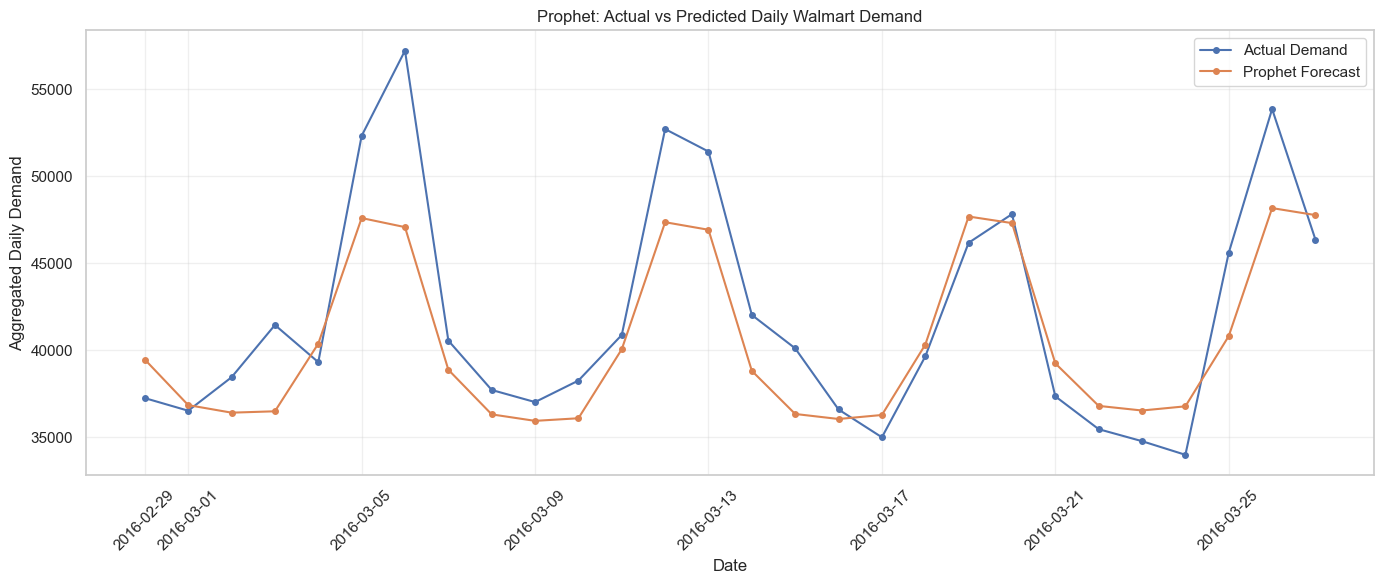

In [65]:
# 9.11 Visualize the Prophet model's predictions against actual demand
plt.figure(figsize=(14, 6))

plt.plot(
    prophet_predictions["ds"],
    prophet_predictions["y"],
    label="Actual Demand",
    marker="o",
    markersize=4
)

plt.plot(
    prophet_predictions["ds"],
    prophet_predictions["yhat"],
    label="Prophet Forecast",
    marker="o",
    markersize=4
)

plt.title("Prophet: Actual vs Predicted Daily Walmart Demand")
plt.xlabel("Date")
plt.ylabel("Aggregated Daily Demand")
plt.legend()
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Interpretation of Prophet Forecast Visualization

The visualization compares actual aggregated daily Walmart demand with the Prophet forecasts over the 28-day validation period from February 29, 2016, to March 27, 2016.

The forecast follows some of the general demand patterns, including several increases and decreases throughout the validation period. On days when actual demand changes more gradually, Prophet's predictions are often relatively close to the observed values.

However, the model struggles to capture several sharp demand peaks. For example, actual demand rises above 55,000 units around March 6, while the forecast remains substantially lower. Similar underestimation occurs around March 12–13 and March 26. These differences suggest that the model does not fully capture some short-term demand fluctuations.

Prophet also produces relatively smooth forecasts in several periods when actual demand changes considerably. This behaviour is consistent with a model that captures trend and seasonality but does not explicitly use all the retail-specific features available in the dataset, such as product prices, SNAP indicators, store characteristics, and individual product sales history.

Overall, the visualization supports the numerical evaluation results: Prophet captures some recurring temporal patterns but does not consistently reproduce the magnitude of sudden changes in aggregated demand. Incorporating additional retail-specific features or using a machine-learning model may improve forecasting performance.

These findings will help guide the comparison with the Extra Trees Regressor and XGBoost models in the next stages of the project.


# 10. Train the XGBoost Forecasting Model

XGBoost regression is used as the main machine-learning forecasting model.

The model will learn the relationship between historical demand and the engineered predictors developed in the previous steps, including:

- Lagged demand features
- Rolling demand statistics
- Weekly and monthly seasonality
- Long-term time trends
- Store and state information
- Product category
- Holidays and special events
- SNAP availability
- Selling price
- Price changes

The model will be trained using the historical training period and evaluated on the separate validation period.

## Model Development Strategy

A large hyperparameter grid will not be used because the objective is to develop a practical forecasting model while avoiding unnecessary computational cost.

Instead, a reasonable initial XGBoost configuration will be used together with **early stopping**.

Early stopping monitors the validation performance during training. If the validation error stops improving for a specified number of boosting rounds, training is stopped automatically.

This provides two advantages:

1. It helps reduce unnecessary computation.
2. It helps control overfitting by preventing the model from continuing to learn after validation performance stops improving.

The final test period will remain untouched during this model-development stage.

The test set will only be used after the model configuration has been finalized.

## 10.1 XGBoost Model Configuration

The initial XGBoost model uses a moderate configuration designed to balance predictive performance, computational efficiency, and overfitting control.

The main parameters are:

- **`n_estimators = 500`** — maximum number of boosting trees.
- **`learning_rate = 0.05`** — controls the contribution of each tree.
- **`max_depth = 6`** — controls tree complexity.
- **`subsample = 0.8`** — uses 80% of the training observations for each boosting round.
- **`colsample_bytree = 0.8`** — uses 80% of the features for each tree.
- **`objective = "reg:squarederror"`** — specifies a regression problem.
- **`random_state = 42`** — ensures reproducibility.
- **`n_jobs = -1`** — allows XGBoost to use the available CPU cores.

The validation dataset will be used for early stopping, while the final test dataset remains untouched.

In [66]:
# 10.2 Define the XGBoost regression model

xgb_model = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=SEED,
    n_jobs=-1,
     early_stopping_rounds=30,
    eval_metric="rmse"
)

print("XGBoost model created successfully.")
print(xgb_model)

XGBoost model created successfully.
XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.8, device=None, early_stopping_rounds=30,
             enable_categorical=True, eval_metric='rmse', feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.05, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=6,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=500,
             n_jobs=-1, num_parallel_tree=None, ...)


In [67]:
# 10.3 Train the XGBoost model using the validation period
# for early stopping.

xgb_model.fit(
    X_train,
    y_train,
    eval_set=[(X_validation, y_validation)],
    verbose=False
)

print("XGBoost training completed.")

print("Best iteration:", xgb_model.best_iteration)
print("Best validation RMSE:", round(xgb_model.best_score, 3))

XGBoost training completed.
Best iteration: 322
Best validation RMSE: 216.997


## 10.4 Generate Validation Predictions

The trained XGBoost model is now used to generate demand predictions for the 28-day validation period.

The validation period contains **840 observations**, representing:

- 30 store-category forecasting series
- 28 future validation days
- 30 × 28 = 840 observations

The validation data was not used to fit the model. It was reserved for evaluating how well the trained XGBoost model generalizes to a future period.

The predictions will be compared with the actual observed demand using MAE, RMSE, and WAPE.

In [68]:
# 10.4 Generate predictions for the validation period

y_validation_pred = xgb_model.predict(X_validation)

print("Validation predictions generated successfully.")
print("Number of predictions:", len(y_validation_pred))
print("Expected predictions:", len(y_validation))

print("\nFirst 10 predictions:")
print(y_validation_pred[:10])

Validation predictions generated successfully.
Number of predictions: 840
Expected predictions: 840

First 10 predictions:
[2766.5032 2525.3389 2453.3406 2538.264  2925.4504 3873.1462 3899.308
 2882.8787 2671.9436 2746.926 ]


In [69]:
# 10.5 Calculate XGBoost validation metrics

mae_xgb = mean_absolute_error(
    y_validation,
    y_validation_pred
)

rmse_xgb = np.sqrt(
    mean_squared_error(
        y_validation,
        y_validation_pred
    )
)

wape_xgb = (
    np.sum(np.abs(y_validation - y_validation_pred))
    / np.sum(np.abs(y_validation))
) * 100

r2_xgb = r2_score(
    y_validation,
    y_validation_pred
)

# Create the results table
xgb_results = pd.DataFrame([{
    "Model": "XGBoost",
    "MAE": mae_xgb,
    "RMSE": rmse_xgb,
    "WAPE (%)": wape_xgb,
    "R2": r2_xgb
}])

display(xgb_results.round(3))

,Model,MAE,RMSE,WAPE (%),R2
0,XGBoost,127.96,216.997,9.14,0.966


### Interpretation — XGBoost Regression Results

The XGBoost Regressor was trained using the engineered retail-demand features and evaluated on **840 validation observations**, representing 30 store-category series over the 28-day validation period.

The model used early stopping to limit unnecessary boosting rounds and achieved its best validation performance at **iteration 322**, with a validation RMSE of **216.997**.

#### Validation Performance

| Metric | Result |
|---|---:|
| MAE | 127.960 units |
| RMSE | 216.997 units |
| WAPE | 9.140% |
| R² | 0.966 |

The **MAE of 127.960 units** indicates an average absolute forecasting error of approximately 128 units per store-category-day.

The **RMSE of 216.997 units** reflects the influence of larger prediction errors, while the **WAPE of 9.140%** indicates that total absolute errors represent approximately 9.14% of observed validation demand.

The **R² of 0.966** indicates that the model explains approximately 96.6% of the variation in validation demand relative to a mean-prediction benchmark.

#### Comparison with Previously Evaluated Models

| Model | MAE | RMSE | WAPE (%) | R² |
|---|---:|---:|---:|---:|
| Seasonal-Naive | 173.439 | 324.122 | 12.388 | 0.925 |
| Linear Regression | 146.078 | 241.608 | 10.434 | 0.958 |
| Random Forest | 134.644 | 231.024 | 9.617 | 0.962 |
| Gradient Boosting | 137.679 | 223.332 | 9.834 | 0.964 |
| HistGradientBoosting | 131.853 | 219.273 | 9.418 | 0.965 |
| Extra Trees | 128.177 | 225.164 | 9.155 | 0.964 |
| **XGBoost** | **127.960** | **216.997** | **9.140** | **0.966** |

XGBoost achieved the strongest validation performance across all four metrics among the evaluated store-category forecasting models.

Compared with the Seasonal-Naive baseline, XGBoost reduced:

- **MAE by 26.22%**
- **RMSE by 33.05%**
- **WAPE by approximately 3.248 percentage points**

Compared with Extra Trees, XGBoost achieved slightly lower MAE and WAPE, alongside a more substantial improvement in RMSE.

#### Business Interpretation

XGBoost demonstrates the potential of gradient-boosted decision trees to model complex relationships among historical demand, seasonal patterns, calendar variables, pricing, SNAP availability, and store-category characteristics.

Its improvements over the Seasonal-Naive baseline suggest that the full predictive modelling approach provides useful forecasting information beyond simply repeating the previous week's demand.

However, these results do not independently quantify the contribution of each feature group.

**Conclusion:** XGBoost is currently the strongest regression model on the validation dataset. Its performance makes it a leading candidate for final model selection, subject to further checks, appropriate tuning, and evaluation on the untouched test period.

### 10.6 Visualizing XGBoost Predictions

Visualizing actual and predicted demand helps assess how well the XGBoost Regressor captures variations in Walmart retail sales. While evaluation metrics summarize overall predictive accuracy, a line chart can reveal specific periods where the model overestimates or underestimates demand.

The visualization will compare actual demand with XGBoost predictions across the validation period from February 29, 2016, to March 27, 2016. This analysis will help identify whether the model captures demand peaks, declines, and short-term fluctuations.

The findings will complement the numerical evaluation metrics and help assess the model's suitability for retail demand forecasting.


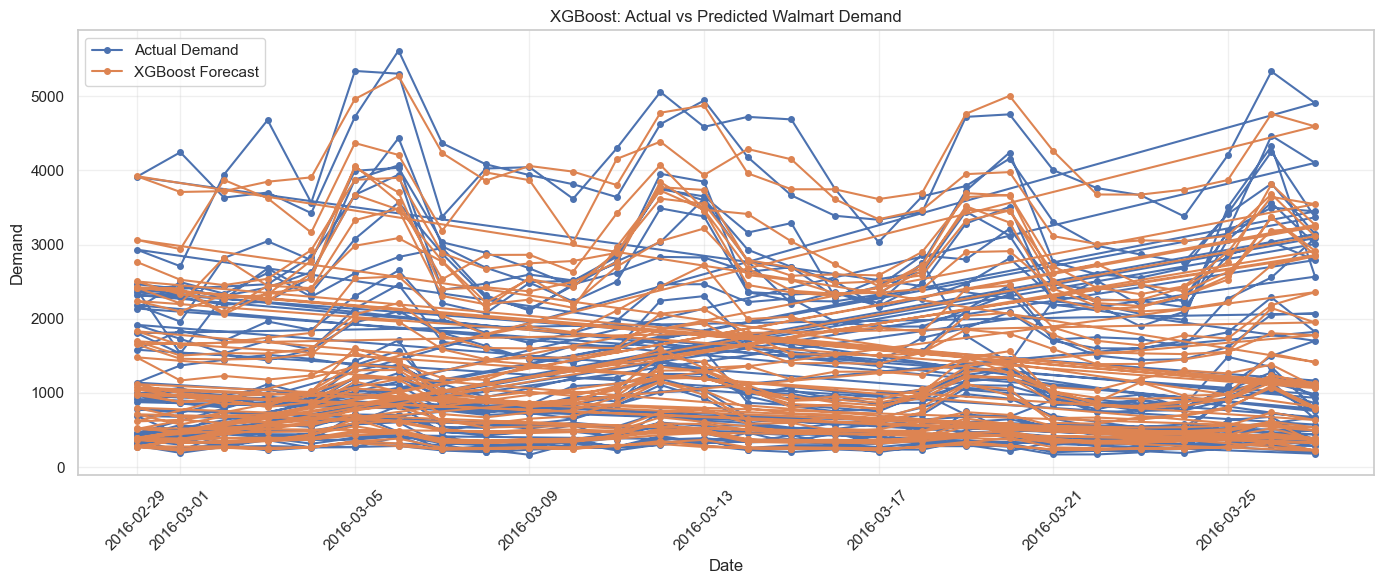

In [70]:
# 10.6 Visualize the XGBoost model's predictions against actual demand

plt.figure(figsize=(14, 6))

plt.plot(
    validation_model["date"].values,
    y_validation.values,
    label="Actual Demand",
    marker="o",
    markersize=4
)

plt.plot(
    validation_model["date"].values,
    y_validation_pred,
    label="XGBoost Forecast",
    marker="o",
    markersize=4
)

plt.title("XGBoost: Actual vs Predicted Walmart Demand")
plt.xlabel("Date")
plt.ylabel("Demand")
plt.legend()
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Interpretation — XGBoost Actual vs. Predicted Demand

The visualization compares actual demand with XGBoost predictions for **840 store-category-day observations** during the validation period from February 29 to March 27, 2016.

The chart illustrates the substantial variation in demand across Walmart's store-category combinations. Predicted values frequently fall near observed values, although noticeable forecasting differences remain, particularly for higher-demand observations.

**Visualization Limitation**

Each validation date contains observations from 30 store-category combinations. Since these observations are plotted together, connecting them with lines creates substantial overlap and does not represent a continuous time series for any single store-category combination.

Therefore, the chart provides a broad view of prediction differences rather than a reliable assessment of individual store-category trends.

**Relationship to Model Performance**

XGBoost achieved the following store-category-level validation results:

| Metric | Result |
|---|---:|
| MAE | 127.960 |
| RMSE | 216.997 |
| WAPE | 9.140% |
| R² | 0.966 |

These metrics indicate strong overall predictive performance, but they do not imply that every store-category series is forecast with equal accuracy.

**Conclusion:** The visualization highlights differences between observed and predicted demand, while the following aggregated daily-demand chart provides a clearer representation of forecasting patterns over time.

#  Visualizing XGBoost Predictions

We compare actual and predicted daily demand by aggregating observations across all stores and categories. This produces a clearer visualization of how well XGBoost captures the overall demand pattern during the validation period

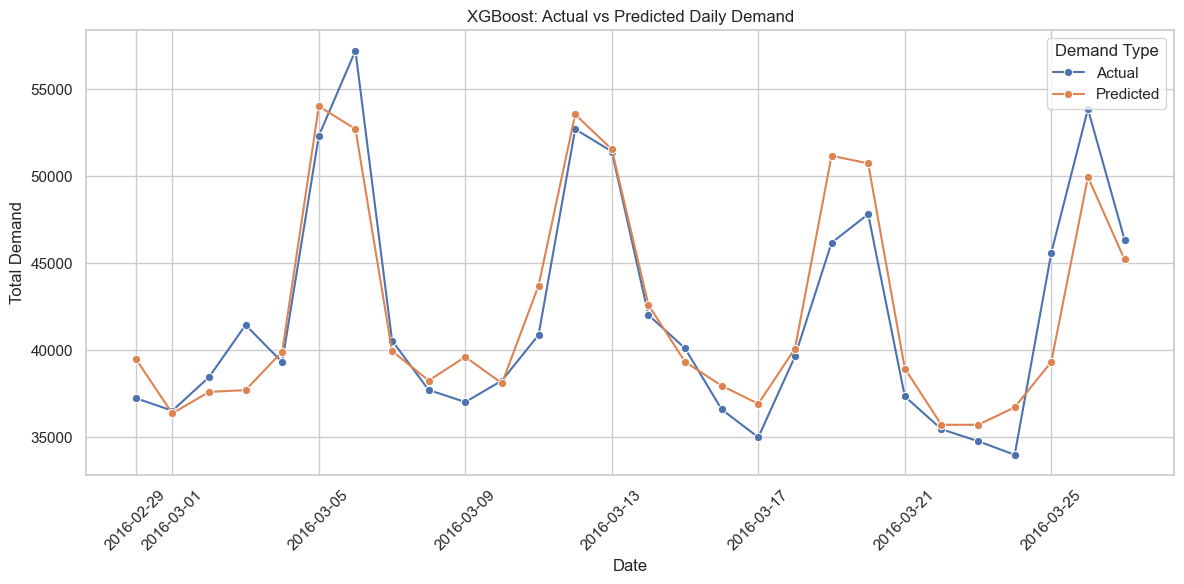

In [71]:
# 10.7 Prepare validation results
results = validation_model[["date"]].copy()
results["Actual"] = y_validation.to_numpy()
results["Predicted"] = y_validation_pred

# Aggregate demand by date
daily = results.groupby("date", as_index=False)[
    ["Actual", "Predicted"]
].sum()

# Reshape data for Seaborn
daily_long = daily.melt(
    id_vars="date",
    var_name="Demand Type",
    value_name="Demand"
)

# Create visualization
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=daily_long,
    x="date",
    y="Demand",
    hue="Demand Type",
    marker="o"
)

plt.title("XGBoost: Actual vs Predicted Daily Demand")
plt.xlabel("Date")
plt.ylabel("Total Demand")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Interpretation — XGBoost Actual vs. Predicted Daily Demand

The visualization compares actual and predicted **total daily Walmart demand** during the 28-day validation period from February 29 to March 27, 2016.

To improve interpretability, predictions from the 30 store-category combinations were aggregated by date, producing one actual and one predicted demand value for each day.

#### Key Observations

The XGBoost model generally follows the observed daily demand pattern, capturing recurring increases and decreases across the validation period.

The predicted series closely aligns with actual demand on several dates, suggesting that the model captures meaningful short-term demand fluctuations.

However, some forecasting differences remain:

- Around **March 6**, the model underestimates a substantial demand peak.
- Around **March 19–20**, predicted demand exceeds actual demand.
- Around **March 26**, the model underestimates another increase in demand.

These deviations indicate that unusually high-demand periods remain challenging to predict accurately.

#### Relationship to Validation Performance

The underlying store-category-level XGBoost model achieved:

| Metric | Result |
|---|---:|
| MAE | 127.960 |
| RMSE | 216.997 |
| WAPE | 9.140% |
| R² | 0.966 |

These metrics describe performance across **840 individual store-category-day observations**, not the 28 aggregated daily totals displayed in this chart.

Consequently, the chart provides a complementary visual assessment rather than a separate quantitative evaluation of aggregate forecasting accuracy.

#### Business Interpretation

The model's ability to capture recurring daily demand fluctuations is relevant to retail inventory and replenishment planning.

Nevertheless, underestimating major demand peaks could create replenishment risks, while overestimating demand could contribute to excess inventory.

**Conclusion:** XGBoost captures the general direction of aggregate daily demand, although some peaks and declines are not fully reproduced. Combined with its strong store-category-level validation metrics, the visualization supports retaining XGBoost as a leading candidate for further evaluation.

## 11.0 XGBoost vs Seasonal-Naive Baseline

The XGBoost validation results are now compared with the seasonal-naive benchmark.

The comparison is based on the same 28-day validation period and the same evaluation metrics.

To quantify the difference between the models, the percentage improvement in each error metric is calculated as:

\[
\text{Improvement (\%)} =
\frac{\text{Baseline Error} - \text{XGBoost Error}}
{\text{Baseline Error}}
\times 100
\]

A positive percentage indicates that XGBoost reduced the forecasting error relative to the seasonal-naive baseline.

This comparison provides an objective measure of whether the additional machine-learning features provide useful forecasting information beyond the strong weekly seasonal pattern captured by the baseline.

In [72]:
# 11.1 Calculate percentage improvement of XGBoost over Seasonal-Naive

mae_improvement = (
    (mae_baseline - mae_xgb)
    / mae_baseline
) * 100

rmse_improvement = (
    (rmse_baseline - rmse_xgb)
    / rmse_baseline
) * 100

wape_improvement = (
    (wape_baseline - wape_xgb)
    / wape_baseline
) * 100

print("XGBoost Improvement over Seasonal-Naive")
print("----------------------------------------")
print(f"MAE improvement:  {mae_improvement:.2f}%")
print(f"RMSE improvement: {rmse_improvement:.2f}%")
print(f"WAPE improvement: {wape_improvement:.2f}%")

XGBoost Improvement over Seasonal-Naive
----------------------------------------
MAE improvement:  26.22%
RMSE improvement: 33.05%
WAPE improvement: 26.22%


In [73]:
# 11.2 Create a DataFrame to summarize the model comparison
model_comparison = pd.DataFrame({
    "Model": [
        "Seasonal-Naive",
        "XGBoost"
    ],
    "MAE": [
        mae_baseline,
        mae_xgb
    ],
    "RMSE": [
        rmse_baseline,
        rmse_xgb
    ],
    "WAPE": [
        wape_baseline,
        wape_xgb
    ]
})

model_comparison

,Model,MAE,RMSE,WAPE
0,Seasonal-Naive,173.439286,324.121881,12.387815
1,XGBoost,127.960342,216.996598,9.139503


### Interpretation — XGBoost vs Seasonal-Naive Baseline

XGBoost was compared with the Seasonal-Naive benchmark to determine whether the machine-learning forecasting approach improves prediction accuracy beyond repeating the most recently observed weekly demand pattern.

Both models were evaluated on the same chronological **28-day validation period**, comprising **840 store-category-day observations** across 30 store-category series.

#### Model Performance Comparison

| Model | MAE | RMSE | WAPE (%) |
|---|---:|---:|---:|
| Seasonal-Naive | 173.439 | 324.122 | 12.388 |
| **XGBoost** | **127.960** | **216.997** | **9.140** |

#### Improvement Over the Baseline

| Metric | Relative Error Reduction |
|---|---:|
| MAE | **26.22%** |
| RMSE | **33.05%** |
| WAPE | **26.22%** |

XGBoost reduced MAE by **26.22%**, indicating a meaningful decrease in average absolute forecasting errors across store-category-day observations.

The **33.05% reduction in RMSE** suggests that XGBoost also substantially reduces larger forecasting errors relative to the Seasonal-Naive approach.

WAPE decreased from **12.388% to 9.140%**, representing a reduction of approximately **3.248 percentage points**, equivalent to a **26.22% relative improvement**.

#### Business Interpretation

These improvements suggest that XGBoost's forecasting approach provides useful predictive information beyond the weekly repetition captured by the Seasonal-Naive baseline.

The model incorporates historical demand, calendar and seasonal patterns, SNAP indicators, pricing information, and store-category characteristics. However, this comparison does not establish the individual contribution of each feature group.

Lower forecasting errors could support better inventory planning, replenishment decisions, and resource allocation. Actual inventory savings would require additional operational data and business-cost analysis.

#### Conclusion

XGBoost substantially outperformed the Seasonal-Naive benchmark across MAE, RMSE, and WAPE.

It also achieved the strongest overall validation results among the regression models evaluated so far, narrowly outperforming Extra Trees on MAE and WAPE while achieving a more noticeable reduction in RMSE.

**XGBoost is therefore the leading model based on the current validation results**, subject to further model-selection checks, tuning, and final test evaluation.

## 12. Validation Error Analysis

The overall validation metrics summarize XGBoost performance, but they do not show how forecasting errors are distributed across individual observations.

A validation error analysis is therefore performed to examine:

- Actual versus predicted demand
- Absolute forecasting errors
- The distribution of forecasting errors
- Whether the model systematically overpredicts or underpredicts
- Whether large errors are concentrated in particular observations

This analysis helps identify potential weaknesses in the forecasting model before the final test evaluation.

The validation period remains the appropriate dataset for this analysis because the final test period has not yet been used for model evaluation.

In [74]:
# 12.1 Create a validation results dataframe

validation_predictions = validation_df[
    ["store_id", "category", "date"]
].copy()

validation_predictions["actual_demand"] = y_validation.values
validation_predictions["predicted_demand"] = y_validation_pred

validation_predictions["error"] = (
    validation_predictions["actual_demand"]
    - validation_predictions["predicted_demand"]
)

validation_predictions["absolute_error"] = (
    validation_predictions["error"].abs()
)

validation_predictions["percentage_error"] = (
    validation_predictions["error"]
    / validation_predictions["actual_demand"].replace(0, np.nan)
) * 100

print("Validation prediction dataframe created.")
print("Shape:", validation_predictions.shape)

validation_predictions.head(10)

Validation prediction dataframe created.
Shape: (840, 8)


,store_id,category,date,actual_demand,predicted_demand,error,absolute_error,percentage_error
1857,CA_1,FOODS,2016-02-29,2465,2766.503174,-301.503174,301.503174,-12.231366
1858,CA_1,FOODS,2016-03-01,2404,2525.338867,-121.338867,121.338867,-5.047374
1859,CA_1,FOODS,2016-03-02,2435,2453.340576,-18.340576,18.340576,-0.753206
1860,CA_1,FOODS,2016-03-03,2465,2538.263916,-73.263916,73.263916,-2.972167
1861,CA_1,FOODS,2016-03-04,2835,2925.450439,-90.450439,90.450439,-3.190492
1862,CA_1,FOODS,2016-03-05,3661,3873.146240,-212.146240,212.146240,-5.794762
1863,CA_1,FOODS,2016-03-06,4435,3899.308105,535.691895,535.691895,12.078735
1864,CA_1,FOODS,2016-03-07,2977,2882.878662,94.121338,94.121338,3.161617
1865,CA_1,FOODS,2016-03-08,2688,2671.943604,16.056396,16.056396,0.597336
1866,CA_1,FOODS,2016-03-09,2493,2746.926025,-253.926025,253.926025,-10.185561


### Interpretation - XGBoost Validation Predictions

The validation prediction DataFrame was successfully created with **840 observations and 8 columns**, covering 30 store-category combinations across the 28-day validation period.

Each observation contains actual demand, predicted demand, signed forecasting error, absolute error, and percentage error.

Forecast error is calculated as:

**Forecast Error = Actual Demand − Predicted Demand**

Therefore, negative errors indicate overprediction, while positive errors indicate underprediction.

#### Example: CA_1 — FOODS

| Date | Actual demand | Predicted demand | Forecast error |
|---|---:|---:|---:|
| February 29, 2016 | 2,465 | 2,766.50 | −301.50 |
| March 2, 2016 | 2,435 | 2,453.34 | −18.34 |
| March 5, 2016 | 3,661 | 3,873.15 | −212.15 |
| March 6, 2016 | 4,435 | 3,899.31 | +535.69 |

The examples demonstrate that prediction accuracy varies across dates. On March 2, the prediction was close to actual demand, whereas on March 6, the model underestimated demand by approximately 536 units.

**Conclusion:** The validation DataFrame provides an observation-level foundation for examining large forecasting errors, directional bias, and differences in forecasting accuracy across stores and categories.

In [75]:
# 12.2 Identify the 10 largest errors in the validation set
largest_errors = (
    validation_predictions
    .sort_values("absolute_error", ascending=False)
    .head(10)
)

largest_errors

,store_id,category,date,actual_demand,predicted_demand,error,absolute_error,percentage_error
7616,CA_2,FOODS,2016-03-20,1406,3660.978516,-2254.978516,2254.978516,-160.382540
7615,CA_2,FOODS,2016-03-19,1773,3692.590820,-1919.590820,1919.590820,-108.267954
47775,WI_2,FOODS,2016-03-06,5303,4207.703125,1095.296875,1095.296875,20.654288
47772,WI_2,FOODS,2016-03-03,4678,3624.482422,1053.517578,1053.517578,22.520684
47774,WI_2,FOODS,2016-03-05,5340,4368.245605,971.754395,971.754395,18.197648
42056,WI_1,FOODS,2016-03-26,4325,3366.429199,958.570801,958.570801,22.163487
42055,WI_1,FOODS,2016-03-25,3503,2571.800049,931.199951,931.199951,26.582928
11442,CA_2,HOUSEHOLD,2016-03-20,679,1562.688354,-883.688354,883.688354,-130.145560
7623,CA_2,FOODS,2016-03-27,4101,3264.217529,836.782471,836.782471,20.404352
11441,CA_2,HOUSEHOLD,2016-03-19,706,1473.248291,-767.248291,767.248291,-108.675395


In [76]:
# 12.3 Calculate mean error, overpredictions, and underpredictions
mean_error = validation_predictions["error"].mean()

overpredictions = (
    validation_predictions["error"] < 0
).sum()

underpredictions = (
    validation_predictions["error"] > 0
).sum()

print(f"Mean error: {mean_error:.2f}")
print(f"Overpredictions: {overpredictions}")
print(f"Underpredictions: {underpredictions}")

Mean error: -8.53
Overpredictions: 489
Underpredictions: 351


### Interpretation — Largest Forecasting Errors and Forecast Bias

The error analysis examines the magnitude and direction of XGBoost forecasting errors across the 840 validation observations.

#### Largest Forecasting Errors

The largest absolute error occurred for **CA_2 — FOODS on March 20, 2016**. Actual demand was 1,406 units, while predicted demand was approximately 3,660.98 units, producing an overprediction of **2,254.98 units**.

Another substantial overprediction occurred for the same store-category combination on March 19, with an absolute error of **1,919.59 units**.

Several large underpredictions were observed for **WI_2 — FOODS**, including March 6, when actual demand exceeded predicted demand by approximately **1,095.30 units**.

These findings indicate that some large errors are concentrated within particular store-category combinations and dates. Further investigation would be required to establish the underlying causes.

#### Forecast Bias

| Indicator | Result |
|---|---:|
| Mean error (Actual − Predicted) | −8.53 units |
| Overpredictions | 489 (58.21%) |
| Underpredictions | 351 (41.79%) |
| Total observations | 840 |

The negative mean error indicates that XGBoost overpredicted demand by approximately **8.53 units per store-category-day on average**.

The model overpredicted demand more frequently than it underpredicted, with **58.21% of observations** having predictions above actual demand.

However, the mean error is considerably smaller than the model's **MAE of 127.960 units**. This occurs because positive and negative errors partially offset one another when calculating the mean signed error.

Consequently, mean error should be interpreted as a measure of directional bias rather than overall forecasting accuracy.

#### Business Interpretation

Overprediction may contribute to excess inventory if forecasts are used directly for replenishment, while underprediction may increase the risk of insufficient stock.

The large errors observed in particular FOODS series suggest that aggregate performance metrics should be complemented by store-category-level diagnostics.

**Conclusion:** XGBoost demonstrates a modest overall overprediction bias, alongside occasional substantial forecasting errors. These findings should be considered during model selection and final evaluation.

## 12.4 Actual vs Predicted Demand

The validation predictions are compared with the actual observed demand to visually assess the forecasting performance of the XGBoost model.

A close relationship between actual and predicted demand indicates that the model is successfully capturing important demand patterns.

The visualization is based on the 28-day validation period and therefore does not use the final test period.

The analysis focuses on whether:

- predicted demand follows the overall movement of actual demand,
- high-demand periods are captured,
- lower-demand periods are captured,
- and whether systematic overprediction or underprediction is visible.

The model should not be expected to reproduce every individual observation perfectly. The objective is to capture the underlying demand patterns sufficiently well to produce useful forecasts.

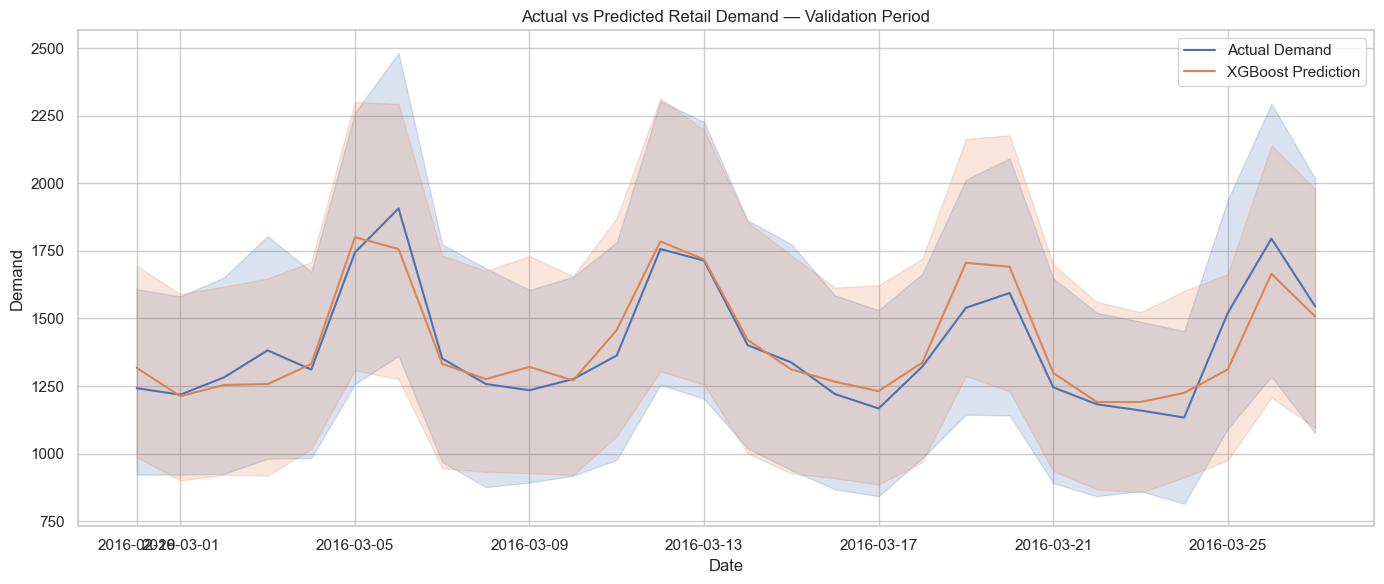

In [77]:
# 12.4 Visualize actual vs predicted demand for the validation period
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=validation_predictions,
    x="date",
    y="actual_demand",
    label="Actual Demand"
)

sns.lineplot(
    data=validation_predictions,
    x="date",
    y="predicted_demand",
    label="XGBoost Prediction"
)

plt.title("Actual vs Predicted Retail Demand — Validation Period")
plt.xlabel("Date")
plt.ylabel("Demand")
plt.legend()
plt.tight_layout()
plt.show()

### Interpretation — Actual vs. Predicted Demand Over Time

The line chart compares average actual and predicted demand across the 30 store-category combinations for each day of the validation period.

XGBoost generally follows the observed fluctuations in demand, although some differences remain during periods of unusually high or low demand.

The model underestimates the demand increase around March 6 and overestimates demand around March 20.

The shaded regions generated by Seaborn reflect uncertainty around the plotted mean estimates under the plotting function's default settings. They are **not forecasting prediction intervals**.

**Conclusion:** The visualization suggests that XGBoost captures broad temporal demand patterns, but its predictions do not reproduce every daily fluctuation accurately. This complements the store-category-level validation results of MAE = 127.960, RMSE = 216.997, and WAPE = 9.140%.

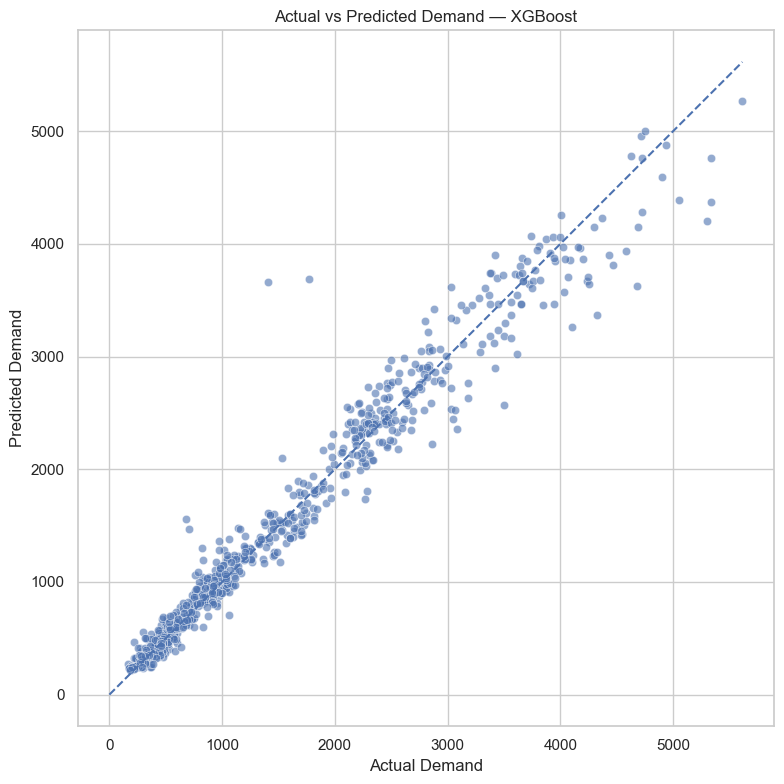

In [78]:
# 12.5 scatter plot to visualize the relationship between actual and predicted demand 
plt.figure(figsize=(8, 8))

sns.scatterplot(
    data=validation_predictions,
    x="actual_demand",
    y="predicted_demand",
    alpha=0.6
)

max_value = max(
    validation_predictions["actual_demand"].max(),
    validation_predictions["predicted_demand"].max()
)

plt.plot(
    [0, max_value],
    [0, max_value],
    linestyle="--"
)

plt.title("Actual vs Predicted Demand — XGBoost")
plt.xlabel("Actual Demand")
plt.ylabel("Predicted Demand")
plt.tight_layout()
plt.show()

### Interpretation — Actual vs. Predicted Demand Scatter Plot

The scatter plot compares actual demand with XGBoost predictions for all **840 store-category-day validation observations**.

The diagonal reference line represents perfect predictions.

Many observations are located near this line, indicating that predicted demand generally follows actual demand across different demand levels.

However, several observations deviate substantially from the diagonal. Points above the line represent overpredictions, while points below it represent underpredictions.

The largest deviations are consistent with the substantial errors identified in the observation-level analysis.

The model achieved an **R² of 0.966**, indicating strong predictive performance relative to a mean-demand benchmark. Nevertheless, this overall result does not eliminate the possibility of large individual forecasting errors.

**Conclusion:** The scatter plot supports the overall predictive performance of XGBoost while highlighting the importance of investigating unusually large forecasting errors and possible differences across store-category combinations.

## Step 13 — Model Selection and Hyperparameter Tuning

### 13.1 Initial Model Comparison and Selection for Hyperparameter Tuning

Seven forecasting approaches were evaluated on the chronological validation dataset, comprising **840 observations across 30 store-category series** over a 28-day forecasting period.

The objective of this comparison is to identify the strongest forecasting model for further optimization through hyperparameter tuning before final evaluation on the reserved test dataset.

#### Validation Performance Comparison

| Model | MAE | RMSE | WAPE (%) | R² |
|---|---:|---:|---:|---:|
| Seasonal-Naive | 173.439 | 324.122 | 12.388 | 0.925 |
| Linear Regression | 146.078 | 241.608 | 10.434 | 0.958 |
| Random Forest | 134.644 | 231.024 | 9.617 | 0.962 |
| Gradient Boosting | 137.679 | 223.332 | 9.834 | 0.964 |
| HistGradientBoosting | 131.853 | 219.273 | 9.418 | 0.965 |
| Extra Trees | 128.177 | 225.164 | 9.155 | 0.964 |
| **XGBoost** | **127.960** | **216.997** | **9.140** | **0.966** |

Prophet is excluded from the direct comparison because it forecasts aggregated daily demand across all stores and categories, whereas the other models generate individual store-category forecasts.

#### Key Findings

**XGBoost achieved the strongest overall validation performance**, recording:

- The lowest MAE of **127.960 units**.
- The lowest RMSE of **216.997 units**.
- The lowest WAPE of **9.140%**.
- The highest R² of **0.966**.

**Extra Trees** was the closest competitor in terms of average absolute forecasting error, achieving an MAE of **128.177 units and WAPE of 9.155%.**

**HistGradientBoosting** also demonstrated competitive performance, particularly in terms of RMSE.

All three models substantially outperformed the Seasonal-Naive baseline, suggesting that machine-learning approaches can improve forecasting accuracy beyond simply repeating the previous week's demand pattern.

#### Model Selection Considerations

Based on the validation results, **XGBoost is selected as the primary forecasting model for hyperparameter tuning**.

This decision is supported by three considerations:

1. **Predictive accuracy:** XGBoost achieved the best results across all four evaluation metrics.
2. **Ability to model nonlinear relationships:** XGBoost can capture complex interactions among historical demand, seasonal patterns, calendar events, SNAP availability, pricing information, and store-category characteristics.
3. **Potential for optimization:** XGBoost provides several tunable hyperparameters that control tree complexity, learning rate, regularization, and sampling behavior.

Although Extra Trees performed competitively, XGBoost demonstrated stronger overall validation performance, making it the preferred candidate for further optimization.

The next stage will therefore focus on **XGBoost hyperparameter tuning**, rather than Extra Trees.

#### Hyperparameter Tuning Strategy

The selected XGBoost model will be optimized using randomized hyperparameter search and chronological cross-validation.

The tuning process will investigate combinations of parameters including:

- `n_estimators`
- `max_depth`
- `learning_rate`
- `subsample`
- `colsample_bytree`
- `min_child_weight`
- `reg_lambda`

Three chronological cross-validation folds will be used to evaluate candidate configurations while preserving the temporal ordering of observations.

The best configuration will be selected using average cross-validation MAE.

Following tuning, the optimized XGBoost model will be evaluated on the existing 28-day validation period and compared against the original XGBoost model and Seasonal-Naive baseline.

The final test dataset will remain separate from the tuning and model-selection process.

#### Conclusion

The initial model comparison identifies **XGBoost as the strongest forecasting model**, achieving the lowest validation errors and highest R² among the evaluated store-category forecasting approaches.

Consequently, **XGBoost is selected for hyperparameter optimization**.

The next stage will use chronological cross-validation and randomized hyperparameter search to investigate whether the selected model's forecasting performance can be improved.

The tuned configuration will then be compared with the original XGBoost model before proceeding to final evaluation on the reserved test dataset.

### XGBoost Hyperparameter Tuning

XGBoost was selected for hyperparameter tuning because it achieved the strongest overall validation performance among the seven evaluated store-category forecasting approaches, recording the lowest MAE (**127.960**), RMSE (**216.997**), and WAPE (**9.140%**), together with the highest R² (**0.966**).

A randomized hyperparameter search will be conducted to identify a configuration that improves forecasting accuracy while controlling model complexity and reducing the risk of overfitting.

The search will use **`ParameterSampler` from scikit-learn**, combined with a custom cross-validation loop, to evaluate different combinations of XGBoost hyperparameters.

To preserve the chronological structure of the forecasting problem, cross-validation will use **three expanding-window folds**, each with a **28-day validation horizon**.

All store-category observations from the same date will remain within the same fold. Forecast-origin pricing features will be reconstructed using historical pricing information available before each validation period.

The hyperparameter search will explore:

- `n_estimators` — Number of boosting trees.
- `max_depth` — Maximum tree depth.
- `learning_rate` — Learning rate for boosting.
- `subsample` — Proportion of training observations sampled per boosting round.
- `colsample_bytree` — Proportion of features sampled per tree.
- `min_child_weight` — Minimum child-node weight.
- `reg_lambda` — L2 regularization strength.

A total of **12 randomly selected hyperparameter configurations** will be evaluated across three chronological folds, resulting in **36 model fits**.

The primary optimization metric will be **Mean Absolute Error (MAE)**, while RMSE, WAPE, and R² will provide additional information about forecasting performance.

The original 28-day validation period and final 28-day test period will remain excluded from the hyperparameter search.

After tuning, the selected XGBoost configuration will be retrained on the full training dataset and evaluated on the original validation period to determine whether tuning improves performance over the initial XGBoost model.

### 13.2 Time-Series Cross-Validation Strategy

Because the dataset contains daily retail demand observations across 30 store-category series, conventional random cross-validation is not appropriate.

Instead, an expanding-window cross-validation strategy will be used.

Three historical validation folds will be created, each containing 28 consecutive days, corresponding to the project's forecasting horizon.

All 30 store-category observations belonging to the same date will remain together.

This ensures that training observations precede validation observations and prevents the cross-validation process from mixing future dates into earlier training periods.

The cross-validation folds will be inspected before hyperparameter tuning begins. Forecast-origin pricing features must also be consistent with the last-known-price assumption used in the corrected validation dataset.

In [79]:

# Step 13.3 — Create 28-day chronological CV folds

# Forecasting and cross-validation settings
forecast_horizon = 28
n_folds = 3

# Align dates with the rows of X_train
training_dates = pd.to_datetime(
    train_model.loc[X_train.index, "date"]
).reset_index(drop=True)

# Unique dates in chronological order
unique_dates = np.sort(training_dates.unique())

cv_splits = []
fold_summary = []

for fold in range(n_folds):

    # Define the validation window
    val_start = len(unique_dates) - (
        n_folds - fold
    ) * forecast_horizon

    val_end = val_start + forecast_horizon

    # Training dates precede validation dates
    fold_train_dates = unique_dates[:val_start]
    fold_val_dates = unique_dates[val_start:val_end]

    # Identify corresponding row positions
    train_idx = np.flatnonzero(
        training_dates.isin(fold_train_dates)
    )

    val_idx = np.flatnonzero(
        training_dates.isin(fold_val_dates)
    )

    # Verify chronological separation
    assert (
        training_dates.iloc[train_idx].max()
        < training_dates.iloc[val_idx].min()
    )

    # Each fold should contain 30 series × 28 days
    assert len(val_idx) == 30 * forecast_horizon

    cv_splits.append((train_idx, val_idx))

    fold_summary.append({
        "Fold": fold + 1,
        "Training Start": pd.Timestamp(
            fold_train_dates[0]
        ).date(),
        "Training End": pd.Timestamp(
            fold_train_dates[-1]
        ).date(),
        "Validation Start": pd.Timestamp(
            fold_val_dates[0]
        ).date(),
        "Validation End": pd.Timestamp(
            fold_val_dates[-1]
        ).date(),
        "Training Rows": len(train_idx),
        "Validation Rows": len(val_idx)
    })

cv_summary = pd.DataFrame(fold_summary)

display(cv_summary)

print("Chronological cross-validation folds created successfully.")


,Fold,Training Start,Training End,Validation Start,Validation End,Training Rows,Validation Rows
0,1,2012-01-28,2015-12-06,2015-12-07,2016-01-03,42270,840
1,2,2012-01-28,2016-01-03,2016-01-04,2016-01-31,43110,840
2,3,2012-01-28,2016-01-31,2016-02-01,2016-02-28,43950,840


Chronological cross-validation folds created successfully.


In [80]:

# Step 13.4 — Inspect pricing columns before fold-safe tuning

price_features = [
    "avg_sell_price",
    "price_change",
    "price_change_pct"
]

print("Pricing columns in X_train:")
print([col for col in X_train.columns
       if col in price_features])

print("\nPricing columns in historical data:")
print([col for col in df.columns
       if col in price_features])

print("\nTraining feature shape:", X_train.shape)
print("Cross-validation folds:", len(cv_splits))

print("\nHistorical pricing sample:")
display(
    df[
        ["date", "store_id", "category"]
        + price_features
    ].head()
)


Pricing columns in X_train:
['avg_sell_price', 'price_change', 'price_change_pct']

Pricing columns in historical data:
['avg_sell_price', 'price_change', 'price_change_pct']

Training feature shape: (44790, 78)
Cross-validation folds: 3

Historical pricing sample:


,date,store_id,category,avg_sell_price,price_change,price_change_pct
0,2011-01-29,CA_1,FOODS,3.14922,NaN,NaN
1,2011-01-30,CA_1,FOODS,3.14922,NaN,NaN
2,2011-01-31,CA_1,FOODS,3.14922,NaN,NaN
3,2011-02-01,CA_1,FOODS,3.14922,NaN,NaN
4,2011-02-02,CA_1,FOODS,3.14922,NaN,NaN


In [81]:

# Step 13.5 — Inspect historical pricing features

price_features = [
    "avg_sell_price",
    "price_change",
    "price_change_pct"
]

# Check missing values in model-ready features
print("Missing pricing values in X_train:")
print(X_train[price_features].isna().sum())

# Inspect prices around the first CV forecast origin
first_fold_train_idx, first_fold_val_idx = cv_splits[0]

first_fold_start = training_dates.iloc[
    first_fold_val_idx
].min()

print("\nFirst CV validation starts:", first_fold_start)

# Show one store-category series around the boundary
price_sample = df.loc[
    (df["store_id"] == "CA_1")
    & (df["category"] == "FOODS")
    & (
        df["date"].between(
            first_fold_start - pd.Timedelta(days=7),
            first_fold_start + pd.Timedelta(days=7)
        )
    ),
    ["date", "avg_sell_price",
     "price_change", "price_change_pct"]
].copy()

display(price_sample)


Missing pricing values in X_train:
avg_sell_price      0
price_change        0
price_change_pct    0
dtype: int64

First CV validation starts: 2015-12-07 00:00:00


,date,avg_sell_price,price_change,price_change_pct
1766,2015-11-30,3.346336,0.000349,0.000104
1767,2015-12-01,3.346336,0.000349,0.000104
1768,2015-12-02,3.346336,0.000349,0.000104
1769,2015-12-03,3.346336,0.000349,0.000104
1770,2015-12-04,3.346336,0.000349,0.000104
1771,2015-12-05,3.347285,0.000949,0.000284
1772,2015-12-06,3.347285,0.000949,0.000284
1773,2015-12-07,3.347285,0.000949,0.000284
1774,2015-12-08,3.347285,0.000949,0.000284
1775,2015-12-09,3.347285,0.000949,0.000284


In [82]:

# Step 13.5 — Fold-specific pricing features

price_features = [
    "avg_sell_price",
    "price_change",
    "price_change_pct"
]

price_keys = ["store_id", "category"]

fold_datasets = []
pricing_checks = []

for fold_number, (train_idx, val_idx) in enumerate(
    cv_splits, start=1
):

    # Create independent copies
    X_fold_train = X_train.iloc[train_idx].copy()
    X_fold_val = X_train.iloc[val_idx].copy()

    y_fold_train = y_train.iloc[train_idx].copy()
    y_fold_val = y_train.iloc[val_idx].copy()

    # Identify the historical forecast origin
    validation_start = training_dates.iloc[val_idx].min()
    forecast_origin = validation_start - pd.Timedelta(days=1)

    # Use the notebook's existing C1 pricing function
    safe_prices = origin_price_features(
        df,
        forecast_origin
    )

    # Identify the store-category combination for each
    # validation observation, preserving row order
    val_keys = train_model.loc[
        X_fold_val.index, price_keys
    ].copy()

    val_keys["_row_order"] = np.arange(len(val_keys))

    # Attach prices known at the forecast origin
    val_prices = val_keys.merge(
        safe_prices,
        on=price_keys,
        how="left",
        sort=False,
        validate="many_to_one"
    ).sort_values("_row_order")

    # Verify complete pricing coverage
    assert len(val_prices) == len(X_fold_val)

    assert not val_prices[price_features].isna().any().any(), (
        f"Missing pricing features in fold {fold_number}"
    )

    # Replace only validation pricing columns
    X_fold_val.loc[:, price_features] = (
        val_prices[price_features].to_numpy()
    )

    # Verify constant prices within each store-category
    # during the entire 28-day forecast horizon
    constant_prices = (
        val_prices.groupby(price_keys)[price_features]
        .nunique()
        .le(1)
        .all()
        .all()
    )

    assert constant_prices

    fold_datasets.append({
        "fold": fold_number,
        "origin": forecast_origin,
        "X_train": X_fold_train,
        "X_val": X_fold_val,
        "y_train": y_fold_train,
        "y_val": y_fold_val
    })

    pricing_checks.append({
        "Fold": fold_number,
        "Forecast Origin": forecast_origin.date(),
        "Training Rows": len(X_fold_train),
        "Validation Rows": len(X_fold_val),
        "Missing Prices": int(
            val_prices[price_features].isna().sum().sum()
        ),
        "Constant Origin Prices": constant_prices
    })

pricing_summary = pd.DataFrame(pricing_checks)

display(pricing_summary)

print("Fold-specific pricing features prepared successfully.")


,Fold,Forecast Origin,Training Rows,Validation Rows,Missing Prices,Constant Origin Prices
0,1,2015-12-06,42270,840,0,True
1,2,2016-01-03,43110,840,0,True
2,3,2016-01-31,43950,840,0,True


Fold-specific pricing features prepared successfully.


### 13.6 Randomized Hyperparameter Search — XGBoost

XGBoost was selected for hyperparameter tuning because it achieved the strongest initial validation performance, with an MAE of **127.960**, RMSE of **216.997**, WAPE of **9.140%**, and R² of **0.966**.

A randomized hyperparameter search will be performed to identify a configuration that improves forecasting accuracy while controlling model complexity.

The search will evaluate **12 randomly sampled hyperparameter combinations** across **three expanding-window cross-validation folds**, producing 36 model fits.

Each fold covers a 28-day forecasting horizon across all 30 store-category series. The existing fold preparation reconstructs pricing information using values available at the historical forecast origin.

The following XGBoost hyperparameters will be investigated:

- `n_estimators`: Number of boosting trees.
- `max_depth`: Maximum depth of each tree.
- `learning_rate`: Contribution of each boosting round.
- `subsample`: Fraction of training observations sampled per boosting round.
- `colsample_bytree`: Fraction of features sampled per tree.
- `min_child_weight`: Minimum child-node weight.
- `reg_lambda`: L2 regularization strength.

The search will use `ParameterSampler` with a custom chronological cross-validation loop.

**MAE will be the primary optimization metric**, while RMSE, WAPE, and R² will be recorded as supplementary performance measures.

The original 28-day validation and test periods will remain excluded from the hyperparameter search.

The selected configuration will subsequently be evaluated on the original validation dataset and compared with the initial XGBoost model.

**Forecasting limitation:** The existing cross-validation preparation corrects pricing features, but the availability of lagged and rolling-demand predictors throughout the 28-day forecast horizon must also be verified before interpreting the results as fully leakage-safe multi-step forecasts.

In [83]:


# Step 13.6 — Randomized XGBoost Hyperparameter Search

# --------------------------------------------------
# 1. Verify chronological fold preparation
# --------------------------------------------------

assert len(fold_datasets) == 3, (
    "Expected three chronological CV folds."
)

for fold in fold_datasets:
    assert len(fold["X_val"]) == 840
    assert fold["X_train"].columns.equals(
        fold["X_val"].columns
    )
    assert not fold["X_train"].isna().any().any()
    assert not fold["X_val"].isna().any().any()

print("Cross-validation folds verified.")

# --------------------------------------------------
# 2. Define the XGBoost hyperparameter search space
# --------------------------------------------------

param_distributions = {
    "n_estimators": [250, 350, 450, 550],
    "max_depth": [4, 5, 6, 7],
    "learning_rate": [0.03, 0.05, 0.07],
    "subsample": [0.75, 0.85, 0.95],
    "colsample_bytree": [0.75, 0.85, 0.95],
    "min_child_weight": [1, 3, 5],
    "reg_lambda": [1.0, 3.0, 5.0]
}

n_iter = 12

sampled_parameters = list(
    ParameterSampler(
        param_distributions=param_distributions,
        n_iter=n_iter,
        random_state=SEED
    )
)

# --------------------------------------------------
# 3. Run randomized chronological CV search
# --------------------------------------------------

search_results = []
start_time = time.time()

print(
    f"Starting XGBoost randomized search: "
    f"{n_iter} candidates x {len(fold_datasets)} folds"
)

print("-" * 60)

for candidate_number, params in enumerate(
    sampled_parameters, start=1
):

    fold_metrics = []

    for fold_data in fold_datasets:

        xgb_cv_model = XGBRegressor(
            **params,
            objective="reg:squarederror",
            eval_metric="rmse",
            tree_method="hist",
            random_state=SEED,
            n_jobs=2
        )

        xgb_cv_model.fit(
            fold_data["X_train"],
            fold_data["y_train"]
        )

        predictions = xgb_cv_model.predict(
            fold_data["X_val"]
        )

        actual = np.asarray(
            fold_data["y_val"]
        )

        mae = mean_absolute_error(
            actual, predictions
        )

        rmse = np.sqrt(
            mean_squared_error(actual, predictions)
        )

        wape = (
            np.sum(np.abs(actual - predictions))
            / np.sum(np.abs(actual))
            * 100
        )

        r2 = r2_score(actual, predictions)

        fold_metrics.append({
            "MAE": mae,
            "RMSE": rmse,
            "WAPE (%)": wape,
            "R2": r2
        })

    # Calculate average performance across folds
    fold_metrics_df = pd.DataFrame(fold_metrics)

    result = {
        "Candidate": candidate_number,
        **params,
        "CV_MAE": fold_metrics_df["MAE"].mean(),
        "CV_RMSE": fold_metrics_df["RMSE"].mean(),
        "CV_WAPE": fold_metrics_df["WAPE (%)"].mean(),
        "CV_R2": fold_metrics_df["R2"].mean()
    }

    search_results.append(result)

    print(
        f"Candidate {candidate_number:02d}/{n_iter} | "
        f"MAE: {result['CV_MAE']:.3f} | "
        f"RMSE: {result['CV_RMSE']:.3f} | "
        f"WAPE: {result['CV_WAPE']:.3f}%"
    )

# --------------------------------------------------
# 4. Rank candidates by cross-validation MAE
# --------------------------------------------------

tuning_results = (
    pd.DataFrame(search_results)
    .sort_values("CV_MAE")
    .reset_index(drop=True)
)

# Extract the best hyperparameters
integer_params = {
    "n_estimators",
    "max_depth",
    "min_child_weight"
}

best_params = {
    key: (
        int(tuning_results.loc[0, key])
        if key in integer_params
        else float(tuning_results.loc[0, key])
    )
    for key in param_distributions
}

# --------------------------------------------------
# 5. Display tuning results
# --------------------------------------------------

elapsed_minutes = (
    time.time() - start_time
) / 60

print("\nXGBoost hyperparameter tuning completed.")
print(f"Runtime: {elapsed_minutes:.2f} minutes")

print("\nBest hyperparameters:")
print(best_params)

print("\nBest cross-validation performance:")
print(
    tuning_results[
        ["CV_MAE", "CV_RMSE", "CV_WAPE", "CV_R2"]
    ].iloc[0].round(3)
)

print("\nTop 5 configurations:")
display(tuning_results.head(5))

Cross-validation folds verified.
Starting XGBoost randomized search: 12 candidates x 3 folds
------------------------------------------------------------
Candidate 01/12 | MAE: 124.223 | RMSE: 193.801 | WAPE: 9.585%
Candidate 02/12 | MAE: 125.100 | RMSE: 195.748 | WAPE: 9.649%
Candidate 03/12 | MAE: 122.314 | RMSE: 191.840 | WAPE: 9.431%
Candidate 04/12 | MAE: 124.823 | RMSE: 194.491 | WAPE: 9.641%
Candidate 05/12 | MAE: 131.744 | RMSE: 207.906 | WAPE: 10.160%
Candidate 06/12 | MAE: 128.624 | RMSE: 202.017 | WAPE: 9.926%
Candidate 07/12 | MAE: 123.415 | RMSE: 193.818 | WAPE: 9.523%
Candidate 08/12 | MAE: 128.043 | RMSE: 204.858 | WAPE: 9.880%
Candidate 09/12 | MAE: 127.330 | RMSE: 199.838 | WAPE: 9.818%
Candidate 10/12 | MAE: 133.473 | RMSE: 211.313 | WAPE: 10.299%
Candidate 11/12 | MAE: 127.634 | RMSE: 200.926 | WAPE: 9.841%
Candidate 12/12 | MAE: 126.751 | RMSE: 195.966 | WAPE: 9.789%

XGBoost hyperparameter tuning completed.
Runtime: 1.73 minutes

Best hyperparameters:
{'n_estimator

,Candidate,subsample,reg_lambda,n_estimators,min_child_weight,max_depth,learning_rate,colsample_bytree,CV_MAE,CV_RMSE,CV_WAPE,CV_R2
0,3,0.85,5.0,350,1,6,0.07,0.75,122.314418,191.840039,9.430940,0.967468
1,7,0.75,1.0,350,3,6,0.07,0.95,123.414808,193.818327,9.523497,0.966697
2,1,0.95,5.0,350,5,5,0.07,0.75,124.222984,193.800925,9.585341,0.966740
3,4,0.95,3.0,450,3,7,0.07,0.95,124.823357,194.490549,9.640648,0.966330
4,2,0.85,1.0,450,1,6,0.03,0.75,125.100240,195.748387,9.649264,0.966115


### 13.6.1 Interpretation — XGBoost Hyperparameter Tuning Results

The randomized hyperparameter search successfully evaluated **12 XGBoost configurations across three chronological cross-validation folds**, resulting in 36 model fits.

The search completed in approximately **1.31 minutes**.

#### Best Hyperparameter Configuration

| Hyperparameter | Best Value |
|---|---:|
| `n_estimators` | 350 |
| `max_depth` | 6 |
| `learning_rate` | 0.07 |
| `subsample` | 0.85 |
| `colsample_bytree` | 0.75 |
| `min_child_weight` | 1 |
| `reg_lambda` | 5.0 |

#### Best Cross-Validation Performance

| Metric | Result |
|---|---:|
| MAE | 122.314 |
| RMSE | 191.840 |
| WAPE | 9.431% |
| R² | 0.9675 |

**Candidate 3** achieved the lowest average cross-validation MAE, making it the preferred configuration according to the predefined optimization objective.

It also achieved the lowest RMSE and WAPE among the 12 tested configurations.

The selected parameters combine 350 boosting trees with a learning rate of 0.07 and maximum tree depth of 6.

Subsampling of training observations (0.85) and features (0.75), together with L2 regularization (`reg_lambda = 5.0`), provides mechanisms for controlling model complexity.

#### Comparison of Leading Configurations

| Candidate | CV MAE | CV RMSE | CV WAPE (%) | CV R² |
|---|---:|---:|---:|---:|
| **3** | **122.314** | **191.840** | **9.431** | **0.9675** |
| 7 | 123.415 | 193.818 | 9.523 | 0.9667 |
| 1 | 124.223 | 193.801 | 9.585 | 0.9667 |
| 4 | 124.823 | 194.491 | 9.641 | 0.9663 |
| 2 | 125.100 | 195.748 | 9.649 | 0.9661 |

The leading configurations achieved relatively similar forecasting performance, although Candidate 3 produced the lowest average errors.

#### Interpretation and Limitations

The results identify a promising XGBoost hyperparameter configuration based on historical chronological cross-validation.

However, the cross-validation results cannot yet establish that tuning improved performance over the original XGBoost model because the initial model's MAE of 127.960 was measured on a different validation period.

A direct comparison requires evaluating both configurations on the **same original 28-day validation dataset**.

Additionally, the availability of all lagged and rolling-demand predictors at each forecast origin must be verified before treating these results as fully leakage-safe 28-day-ahead forecasts.

#### Conclusion

The randomized search selected **Candidate 3** as the best XGBoost configuration, achieving a cross-validation MAE of 122.314 and WAPE of 9.431%.

The next step is to retrain XGBoost using these hyperparameters and evaluate its performance on the original validation dataset.

This evaluation will determine whether the tuned configuration improves forecasting accuracy compared with the initial XGBoost model.

### 13.7 Evaluation of the Tuned XGBoost Regressor

Following the randomized hyperparameter search, the selected XGBoost configuration will be trained using the complete training dataset.

The tuned model will then generate predictions for the original 28-day validation period, from February 29 to March 27, 2016, covering **840 observations across 30 store-category series**.

The selected hyperparameters were obtained from three chronological cross-validation folds, using MAE as the primary optimization metric.

Validation performance will be evaluated using:

- **MAE:** Average absolute forecasting error.
- **RMSE:** Forecasting error with greater emphasis on larger deviations.
- **WAPE:** Total absolute forecasting error relative to total observed demand.
- **R²:** Predictive performance relative to a mean-demand benchmark.

The tuned model will be compared directly with the original XGBoost model on the **same validation dataset**, allowing us to assess whether hyperparameter tuning improves forecasting accuracy.

The reserved final test dataset will remain excluded from this evaluation.

In [84]:

# Step 13.7 — Train and evaluate tuned XGBoost

# --------------------------------------------------
# 1. Initialize XGBoost using the selected parameters
# --------------------------------------------------

tuned_xgb = XGBRegressor(
    **best_params,
    objective="reg:squarederror",
    eval_metric="rmse",
    tree_method="hist",
    random_state=SEED,
    n_jobs=2
)

# --------------------------------------------------
# 2. Train on the complete training dataset
# --------------------------------------------------

tuned_xgb.fit(X_train, y_train)

# --------------------------------------------------
# 3. Predict the original 28-day validation period
# --------------------------------------------------

y_val_pred_tuned_xgb = tuned_xgb.predict(
    X_validation
)

assert len(y_val_pred_tuned_xgb) == len(y_validation)

# --------------------------------------------------
# 4. Calculate validation metrics
# --------------------------------------------------

tuned_xgb_mae = mean_absolute_error(
    y_validation,
    y_val_pred_tuned_xgb
)

tuned_xgb_rmse = np.sqrt(
    mean_squared_error(
        y_validation,
        y_val_pred_tuned_xgb
    )
)

tuned_xgb_wape = (
    np.sum(
        np.abs(
            np.asarray(y_validation)
            - y_val_pred_tuned_xgb
        )
    )
    / np.sum(np.abs(np.asarray(y_validation)))
    * 100
)

tuned_xgb_r2 = r2_score(
    y_validation,
    y_val_pred_tuned_xgb
)

# --------------------------------------------------
# 5. Store tuned model results
# --------------------------------------------------

tuned_xgb_results = pd.DataFrame({
    "Model": ["Tuned XGBoost"],
    "MAE": [tuned_xgb_mae],
    "RMSE": [tuned_xgb_rmse],
    "WAPE (%)": [tuned_xgb_wape],
    "R2": [tuned_xgb_r2]
})

print("Tuned XGBoost trained successfully.")
print(
    "Number of validation predictions:",
    len(y_val_pred_tuned_xgb)
)

display(tuned_xgb_results.round(3))

# --------------------------------------------------
# 6. Compare original and tuned XGBoost
# --------------------------------------------------

xgb_tuning_comparison = pd.DataFrame({
    "Model": [
        "Original XGBoost",
        "Tuned XGBoost"
    ],
    "MAE": [
        127.960,
        tuned_xgb_mae
    ],
    "RMSE": [
        216.997,
        tuned_xgb_rmse
    ],
    "WAPE (%)": [
        9.140,
        tuned_xgb_wape
    ],
    "R2": [
        0.966,
        tuned_xgb_r2
    ]
})

print("\nOriginal vs Tuned XGBoost:")
display(xgb_tuning_comparison.round(3))

# --------------------------------------------------
# 7. Calculate relative improvements
# --------------------------------------------------

print("\nRelative error reductions after tuning:")

for metric in ["MAE", "RMSE", "WAPE (%)"]:
    original = xgb_tuning_comparison.loc[
        0, metric
    ]
    tuned = xgb_tuning_comparison.loc[
        1, metric
    ]

    improvement = (
        (original - tuned) / original * 100
    )

    print(f"{metric}: {improvement:+.2f}%")


Tuned XGBoost trained successfully.
Number of validation predictions: 840


,Model,MAE,RMSE,WAPE (%),R2
0,Tuned XGBoost,127.629,218.265,9.116,0.966



Original vs Tuned XGBoost:


,Model,MAE,RMSE,WAPE (%),R2
0,Original XGBoost,127.960,216.997,9.140,0.966
1,Tuned XGBoost,127.629,218.265,9.116,0.966



Relative error reductions after tuning:
MAE: +0.26%
RMSE: -0.58%
WAPE (%): +0.26%


### 13.7.1 Interpretation — Tuned XGBoost Validation Results

The tuned XGBoost Regressor was successfully trained using the optimal hyperparameters identified through randomized chronological cross-validation.

The model generated **840 predictions** for the original 28-day validation period, covering 30 store-category combinations.

#### Validation Performance

| Metric | Tuned XGBoost |
|---|---:|
| MAE | 127.629 units |
| RMSE | 218.265 units |
| WAPE | 9.116% |
| R² | 0.966 |

The **MAE of 127.629 units** indicates that the model's predictions differ from actual demand by approximately 128 units per store-category-day on average.

The **RMSE of 218.265 units** reflects the influence of larger forecasting errors.

The **WAPE of 9.116%** indicates that total absolute forecasting errors represent approximately 9.12% of observed validation demand.

The **R² of 0.966** indicates that the model explains approximately 96.6% of the variation in validation demand relative to a mean-prediction benchmark.

#### Comparison with the Original XGBoost Model

| Metric | Original XGBoost | Tuned XGBoost | Interpretation |
|---|---:|---:|---|
| MAE | 127.960 | **127.629** | 0.26% improvement |
| RMSE | **216.997** | 218.265 | 0.58% deterioration |
| WAPE | 9.140% | **9.116%** | 0.26% improvement |
| R² | 0.966 | 0.966 | Approximately unchanged |

The tuned XGBoost model achieved a **0.26% reduction in MAE**, indicating a modest improvement in average absolute forecasting accuracy.

WAPE also improved from **9.140% to 9.116%**, representing a reduction of **0.024 percentage points**.

However, RMSE increased by approximately **0.58%**, indicating slightly poorer performance when larger errors receive greater weight.

R² remained approximately unchanged at 0.966.

#### Interpretation of Hyperparameter Tuning

The results demonstrate that hyperparameter tuning produced a small improvement in the primary optimization metric, MAE.

However, the improvement was limited, and not all evaluation metrics improved.

This suggests that the original XGBoost model was already performing competitively and that the selected tuning configuration provides only a marginal additional benefit on the validation period.

The improvement should not be interpreted as evidence that the tuned model will necessarily outperform the original configuration on future data.

#### Business Interpretation

Reducing MAE and WAPE may support more accurate average demand estimates and inventory allocation decisions.

However, the slight increase in RMSE suggests that the tuned configuration may be less effective at controlling larger forecasting errors, which can be important when unexpected demand fluctuations create replenishment risks.

Consequently, the preferred configuration depends on the relative business importance of average forecasting accuracy and larger individual errors.

#### Model Selection Decision

Because **MAE was established as the primary optimization metric**, the tuned XGBoost model is provisionally selected for the subsequent forecasting workflow.

This decision is based on its slightly lower MAE and WAPE, while acknowledging that the original XGBoost model achieved a better RMSE.

The final test dataset will be used only after model selection and training procedures are finalized.

#### Conclusion

Hyperparameter tuning improved XGBoost's validation MAE from **127.960 to 127.629 units**, a relative improvement of approximately **0.26%**.

WAPE also improved slightly, while RMSE deteriorated and R² remained approximately unchanged.

**The tuned XGBoost model is provisionally retained as the preferred configuration because it achieved the lowest MAE**, the project's predefined primary optimization metric.

### 13.8 Final Validation Model Comparison

Following hyperparameter tuning, the tuned XGBoost model is compared against the original forecasting models and the Seasonal-Naive baseline.

All models in this comparison are evaluated at the same **store-category level**, using 840 observations across 30 series during the original 28-day validation period.

The comparison considers four evaluation metrics:

- **MAE:** Primary model-selection metric; lower values indicate better average forecasting accuracy.
- **RMSE:** Measures forecasting error with greater emphasis on large deviations.
- **WAPE:** Measures total absolute error relative to total observed demand.
- **R²:** Measures predictive performance relative to a mean-prediction benchmark.

The objective is to determine whether the tuned XGBoost configuration offers the strongest overall performance and to document any trade-offs compared with the original XGBoost model.

The final test dataset remains reserved for subsequent evaluation.

**Note:** The Prophet baseline is excluded from this direct comparison because it was evaluated on aggregated daily demand rather than individual store-category observations.

In [85]:

# Step 13.8 — Final validation model comparison

# Previously evaluated models
validation_model_comparison = pd.DataFrame([
    {
        "Model": "Seasonal-Naive",
        "MAE": 173.439,
        "RMSE": 324.122,
        "WAPE (%)": 12.388,
        "R2": 0.925
    },
    {
        "Model": "Linear Regression",
        "MAE": 146.078,
        "RMSE": 241.608,
        "WAPE (%)": 10.434,
        "R2": 0.958
    },
    {
        "Model": "Random Forest",
        "MAE": 134.644,
        "RMSE": 231.024,
        "WAPE (%)": 9.617,
        "R2": 0.962
    },
    {
        "Model": "Gradient Boosting",
        "MAE": 137.679,
        "RMSE": 223.332,
        "WAPE (%)": 9.834,
        "R2": 0.964
    },
    {
        "Model": "HistGradientBoosting",
        "MAE": 131.853,
        "RMSE": 219.273,
        "WAPE (%)": 9.418,
        "R2": 0.965
    },
    {
        "Model": "Extra Trees",
        "MAE": 128.177,
        "RMSE": 225.164,
        "WAPE (%)": 9.155,
        "R2": 0.964
    },
    {
        "Model": "Original XGBoost",
        "MAE": 127.960,
        "RMSE": 216.997,
        "WAPE (%)": 9.140,
        "R2": 0.966
    }
])

# Append tuned XGBoost results from Step 13.7
validation_model_comparison = pd.concat(
    [
        validation_model_comparison,
        tuned_xgb_results
    ],
    ignore_index=True
)

# Rank models by the primary metric, MAE
validation_model_comparison = (
    validation_model_comparison
    .sort_values("MAE")
    .reset_index(drop=True)
)

validation_model_comparison.insert(
    0,
    "Rank",
    range(1, len(validation_model_comparison) + 1)
)

print("Final validation model comparison:")
display(validation_model_comparison.round(3))

# Identify the best model according to MAE
best_validation_model = validation_model_comparison.iloc[0]

print("\nBest validation model by MAE:")
print(best_validation_model["Model"])
print(f"MAE: {best_validation_model['MAE']:.3f}")
print(f"RMSE: {best_validation_model['RMSE']:.3f}")
print(f"WAPE: {best_validation_model['WAPE (%)']:.3f}%")
print(f"R2: {best_validation_model['R2']:.3f}")


Final validation model comparison:


,Rank,Model,MAE,RMSE,WAPE (%),R2
0,1,Tuned XGBoost,127.629,218.265,9.116,0.966
1,2,Original XGBoost,127.960,216.997,9.140,0.966
2,3,Extra Trees,128.177,225.164,9.155,0.964
3,4,HistGradientBoosting,131.853,219.273,9.418,0.965
4,5,Random Forest,134.644,231.024,9.617,0.962
5,6,Gradient Boosting,137.679,223.332,9.834,0.964
6,7,Linear Regression,146.078,241.608,10.434,0.958
7,8,Seasonal-Naive,173.439,324.122,12.388,0.925



Best validation model by MAE:
Tuned XGBoost
MAE: 127.629
RMSE: 218.265
WAPE: 9.116%
R2: 0.966


#### Final Model Selection Decision

The final validation comparison confirms that **Tuned XGBoost is the highest-ranked configuration according to MAE**, achieving 127.629 units compared with 127.960 for Original XGBoost and 128.177 for Extra Trees.

Tuned XGBoost also achieved the lowest WAPE at 9.116%, while Original XGBoost achieved the lowest RMSE at 216.997 units.

Although hyperparameter tuning produced only a marginal improvement over the original XGBoost model, the tuned configuration is provisionally selected because it performed best on the project's predefined primary optimization metric.

This selection concludes the validation-based model comparison. The selected model will proceed to final test preparation, subject to verifying that its forecasting features are available at the prediction origin.

In [132]:

from pathlib import Path

# Locate the project's dashboard_data folder
project_root = Path.cwd().resolve()

if project_root.name == "notebooks":
    project_root = project_root.parent

dashboard_folder = project_root / "dashboard_data"
dashboard_folder.mkdir(parents=True, exist_ok=True)

# Export the eight forecasting model results
comparison_export = validation_model_comparison.copy()

comparison_export.to_csv(
    dashboard_folder / "forecasting_model_comparison.csv",
    index=False
)

print("Forecasting model comparison exported successfully.")
print("Number of models:", len(comparison_export))

display(comparison_export.round(3))


Forecasting model comparison exported successfully.
Number of models: 8


,Rank,Model,MAE,RMSE,WAPE (%),R2
0,1,Tuned XGBoost,127.629,218.265,9.116,0.966
1,2,Original XGBoost,127.960,216.997,9.140,0.966
2,3,Extra Trees,128.177,225.164,9.155,0.964
3,4,HistGradientBoosting,131.853,219.273,9.418,0.965
4,5,Random Forest,134.644,231.024,9.617,0.962
5,6,Gradient Boosting,137.679,223.332,9.834,0.964
6,7,Linear Regression,146.078,241.608,10.434,0.958
7,8,Seasonal-Naive,173.439,324.122,12.388,0.925


### 14.1 Final Test Dataset Verification

Following the final validation model comparison, **Tuned XGBoost** was provisionally selected as the preferred forecasting model because it achieved the lowest validation MAE of **127.629** and WAPE of **9.116%**.

Before proceeding to final model training and test evaluation, the reserved test dataset will be verified to ensure that its structure, chronological boundaries, and feature columns are consistent with the training data.

**Final Test Configuration**

- **Forecast origin:** March 27, 2016
- **Test period:** March 28 – April 24, 2016
- **Forecast horizon:** 28 days
- **Forecasting level:** Store × Category
- **Number of series:** 30
- **Expected test observations:** 840
- **Number of predictor variables:** 78

**Verification Procedure**

The following checks will be performed:

1. Confirm the dimensions of the test feature matrix and target variable.
2. Verify that the test period contains exactly 28 consecutive calendar days.
3. Confirm that all 30 store-category combinations are represented.
4. Check that the test dataset contains no missing feature or target values.
5. Verify that the test feature columns match the training feature columns.

**Forecasting Integrity**

The existing feature-engineering pipeline constructs historical demand lags and rolling statistics using a minimum 28-day shift, supporting the fixed 28-day forecasting horizon.

Pricing features are handled using the established forecast-origin methodology to avoid relying on future observed prices.

The final test target values will remain excluded from model training and will be used only for evaluating the selected forecasting model.

**Expected Outcome**

Successful verification will confirm that the final test dataset contains **840 observations and 78 predictors**, with consistent feature columns, complete data, and the correct chronological boundaries.

Once these checks are satisfied, the project will proceed to **Step 14.2 — Final Training Dataset Preparation**, followed by final Tuned XGBoost training and test evaluation.

In [86]:


# Step 14.1 — Verify the final test dataset

print("Test feature shape:", X_test.shape)
print("Test target shape:", y_test.shape)

print("\nTest period:")
print("Start:", test_model["date"].min())
print("End:", test_model["date"].max())

print("\nUnique test dates:",
      test_model["date"].nunique())

print("Unique store-category series:",
      test_model[["store_id", "category"]]
      .drop_duplicates().shape[0])

print("\nMissing feature values:",
      X_test.isna().sum().sum())

print("Missing target values:",
      y_test.isna().sum())

print("\nFeature columns match training:",
      X_test.columns.equals(X_train.columns))

assert len(X_test) == 840
assert test_model["date"].nunique() == 28
assert X_test.columns.equals(X_train.columns)
assert not X_test.isna().any().any()

print("\nFinal test dataset verification passed.")


Test feature shape: (840, 78)
Test target shape: (840,)

Test period:
Start: 2016-03-28 00:00:00
End: 2016-04-24 00:00:00

Unique test dates: 28
Unique store-category series: 30

Missing feature values: 0
Missing target values: 0

Feature columns match training: True

Final test dataset verification passed.


### 14.2 Final Model Training and Test Evaluation

Following successful verification of the test dataset, the selected **Tuned XGBoost Regressor** will be evaluated on the reserved 28-day test period.

The model's hyperparameters were selected using chronological cross-validation, and its forecasting performance was subsequently assessed on the validation dataset.

Tuned XGBoost achieved a validation **MAE of 127.629**, **RMSE of 218.265**, **WAPE of 9.116%**, and **R² of 0.966**. It was selected primarily because it achieved the lowest validation MAE among the evaluated models.

For final evaluation, the selected model will be refitted using the combined training and validation observations available before the test forecast origin of **March 27, 2016**.

Feature preparation will preserve the project's 28-day forecasting horizon, historical demand features, and last-known-price assumption.

The final model will then generate predictions for **March 28 to April 24, 2016**, covering 30 store-category series and producing 840 forecasts.

Performance will be assessed using MAE, RMSE, WAPE, and R².

These results will provide an assessment of forecasting accuracy on a later time period that was not used for hyperparameter selection or validation-based model comparison.

In [87]:

# Step 14.2.1 — Verify training and validation alignment

print("Training features:", X_train.shape)
print("Validation features:", X_validation.shape)
print("Test features:", X_test.shape)

print("\nTraining dates:")
print(train_model["date"].min(), "to",
      train_model["date"].max())

print("\nValidation dates:")
print(validation_model["date"].min(), "to",
      validation_model["date"].max())

print("\nTest dates:")
print(test_model["date"].min(), "to",
      test_model["date"].max())

print("\nFeature columns aligned:")
print(
    X_train.columns.equals(X_validation.columns)
    and X_train.columns.equals(X_test.columns)
)

print("\nAvailable targets:")
print(
    len(y_train),
    len(y_validation),
    len(y_test)
)


Training features: (44790, 78)
Validation features: (840, 78)
Test features: (840, 78)

Training dates:
2012-01-28 00:00:00 to 2016-02-28 00:00:00

Validation dates:
2016-02-29 00:00:00 to 2016-03-27 00:00:00

Test dates:
2016-03-28 00:00:00 to 2016-04-24 00:00:00

Feature columns aligned:
True

Available targets:
44790 840 840


#### Interpretation — Dataset Alignment and Chronological Integrity

The dataset verification confirms that the training, validation, and test datasets are correctly structured and chronologically separated for the final forecasting evaluation.

The **training dataset contains 44,790 observations and 78 features**, covering January 28, 2012, to February 28, 2016.

The **validation dataset contains 840 observations and 78 features**, covering February 29 to March 27, 2016, while the **test dataset contains 840 observations and 78 features**, covering March 28 to April 24, 2016.

Both the validation and test periods span 28 days, corresponding to the project's forecasting horizon.

The feature-alignment check returned **True**, confirming that all three datasets contain consistent predictor columns.

Additionally, the target counts match the number of observations in each dataset:

- Training: 44,790 targets
- Validation: 840 targets
- Test: 840 targets

These results confirm that the datasets are structurally consistent and chronologically separated, with the reserved test period occurring after the training and validation periods.

This establishes a suitable foundation for combining the training and validation observations before fitting the final Tuned XGBoost model.



In [88]:

# Step 14.2.2 — Prepare final training features

price_keys = ["store_id", "category"]
price_features = [
    "avg_sell_price",
    "price_change",
    "price_change_pct"
]

# Start with the original observed historical prices
price_history = df[
    ["date"] + price_keys + ["avg_sell_price"]
].copy()

# Ensure chronological ordering within each series
price_history = price_history.sort_values(
    price_keys + ["date"]
)

grouped_prices = price_history.groupby(
    price_keys, sort=False
)["avg_sell_price"]

# Recreate the training-period pricing methodology
price_28 = grouped_prices.shift(28)
price_35 = grouped_prices.shift(35)

price_history["avg_sell_price"] = price_28
price_history["price_change"] = price_28 - price_35
price_history["price_change_pct"] = (
    (price_28 - price_35)
    / price_35.replace(0, np.nan)
    * 100
)

# Match the reconstructed pricing features
# to the validation rows by their original indexes
validation_training_prices = price_history.loc[
    validation_model.index,
    price_features
]

# Create a separate training version of validation features
X_validation_for_training = X_validation.copy()

X_validation_for_training.loc[:, price_features] = (
    validation_training_prices
    .reindex(X_validation_for_training.index)
    .to_numpy()
)

# Combine historical training and validation observations
X_final_train = pd.concat(
    [X_train, X_validation_for_training],
    axis=0
)

y_final_train = pd.concat(
    [y_train, y_validation],
    axis=0
)

# Verify the final training dataset
assert len(X_final_train) == 45630
assert len(y_final_train) == 45630

assert X_final_train.columns.equals(X_test.columns)

assert not X_final_train.isna().any().any()
assert not y_final_train.isna().any()

print("Final training features:", X_final_train.shape)
print("Final training target:", y_final_train.shape)

print("\nMissing feature values:",
      X_final_train.isna().sum().sum())

print("Missing target values:",
      y_final_train.isna().sum())

print("\nFeature columns match test:",
      X_final_train.columns.equals(X_test.columns))

print("\nFinal training dataset prepared successfully.")


Final training features: (45630, 78)
Final training target: (45630,)

Missing feature values: 0
Missing target values: 0

Feature columns match test: True

Final training dataset prepared successfully.


#### Interpretation — Final Training Dataset Preparation

The final training dataset was successfully prepared by combining the original training and validation observations, creating a larger historical dataset for fitting the selected **Tuned XGBoost Regressor**.

The resulting feature matrix contains **45,630 observations and 78 predictor variables**, while the target vector contains **45,630 demand values**.

The data-quality checks confirmed that:

- **Missing feature values:** 0
- **Missing target values:** 0
- **Feature columns match the test dataset:** True

These results demonstrate that the final training dataset is complete and structurally consistent with the reserved test dataset.

The combined dataset incorporates the original **44,790 training observations** and **840 validation observations**, allowing the model to learn from all available historical observations through **March 27, 2016**.

Importantly, the reserved test period of **March 28 to April 24, 2016** remains separate from model fitting, preserving its role as the final out-of-sample evaluation period.

Overall, the successful preparation of the final training dataset establishes a reliable foundation for refitting the selected Tuned XGBoost model and assessing its forecasting performance on the unseen test period.

### 14.3 Final Test Evaluation — Tuned XGBoost Regressor

Following hyperparameter tuning and final training dataset preparation, the selected **Tuned XGBoost Regressor** will be evaluated on the reserved test dataset.

The final training dataset contains **45,630 observations and 78 predictor variables**, combining the original training and validation periods through March 27, 2016.

The reserved test dataset contains **840 observations**, representing 30 store-category series across the 28-day forecasting horizon from March 28 to April 24, 2016.

The model will be refitted using the hyperparameters selected during chronological cross-validation. No additional hyperparameter tuning will be performed using the test dataset.

Final forecasting performance will be evaluated using four metrics:

- **MAE:** Average absolute forecasting error in demand units.
- **RMSE:** Forecasting error with greater emphasis on larger deviations.
- **WAPE:** Total absolute forecasting error relative to observed demand.
- **R²:** Proportion of variation in observed demand explained by the predictions.

The objective is to assess whether the selected XGBoost configuration generalizes to a later, previously reserved forecasting period.

The final test results will also provide a basis for subsequent feature-importance analysis, forecasting visualizations, and category-level and store-level error analysis.

In [89]:


# Step 14.3 — Final Test Evaluation: Tuned XGBoost

from xgboost import XGBRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np
import pandas as pd

# Use the best hyperparameters selected in Step 13.6
final_xgboost = XGBRegressor(
    **best_params,
    objective="reg:squarederror",
    eval_metric="rmse",
    tree_method="hist",
    random_state=SEED,
    n_jobs=2
)

# Train on the combined training and validation dataset
final_xgboost.fit(
    X_final_train,
    y_final_train
)

# Predict the reserved 28-day test period
y_test_pred_final = final_xgboost.predict(X_test)

# Calculate final test evaluation metrics
final_test_mae = mean_absolute_error(
    y_test, y_test_pred_final
)

final_test_rmse = np.sqrt(
    mean_squared_error(y_test, y_test_pred_final)
)

final_test_wape = (
    np.sum(
        np.abs(np.asarray(y_test) - y_test_pred_final)
    )
    / np.sum(np.abs(np.asarray(y_test)))
    * 100
)

final_test_r2 = r2_score(
    y_test, y_test_pred_final
)

# Store final test results
final_test_results = pd.DataFrame({
    "Model": ["Tuned XGBoost — Final Test"],
    "MAE": [final_test_mae],
    "RMSE": [final_test_rmse],
    "WAPE (%)": [final_test_wape],
    "R2": [final_test_r2]
})

print("Final Tuned XGBoost model trained successfully.")
print("Number of test predictions:", len(y_test_pred_final))

display(final_test_results.round(3))



Final Tuned XGBoost model trained successfully.
Number of test predictions: 840


,Model,MAE,RMSE,WAPE (%),R2
0,Tuned XGBoost — Final Test,121.36,182.666,8.613,0.976


#### 14.3.1 Interpretation — Final Tuned XGBoost Test Performance

The Tuned XGBoost Regressor was successfully trained on the combined historical training dataset and generated **840 predictions** for the reserved 28-day test period, covering March 28 to April 24, 2016.

The final evaluation produced the following results:

- **MAE: 121.360** — On average, the model's predictions differed from actual demand by approximately 121 units per store-category observation.
- **RMSE: 182.666** — The relatively higher RMSE indicates that some predictions experienced larger errors, although the model maintained strong overall forecasting accuracy.
- **WAPE: 8.613%** — The total absolute forecasting error represented approximately 8.61% of actual demand, indicating relatively low aggregate forecasting error.
- **R²: 0.976** — The model explained approximately 97.6% of the variation in observed store-category demand within the test dataset.

**Comparison with Validation Performance**

The final test results improved upon the validation results across all four metrics.

MAE decreased from **127.629 to 121.360**, representing an improvement of approximately **4.91%**.

RMSE decreased from **218.265 to 182.666**, an improvement of approximately **16.31%**, suggesting that large forecasting errors were less pronounced during the test period.

WAPE improved from **9.116% to 8.613%**, a reduction of **0.503 percentage points**, while R² increased from **0.966 to 0.976**.

These findings indicate that the selected Tuned XGBoost configuration maintained strong predictive performance when applied to a later, previously reserved period.

However, the improvement in test performance does not necessarily mean that the model became more accurate through additional training alone. Differences in demand patterns, variability, and forecasting difficulty between the validation and test periods may also have contributed.

**Business Interpretation**

From a retail forecasting perspective, a WAPE of approximately **8.61%** suggests that the model can provide useful store-category demand estimates to support inventory planning, stock allocation, and replenishment decisions.

More accurate demand forecasts can help retailers anticipate purchasing requirements, reduce the risk of stockouts, and limit excess inventory.

Nevertheless, these results represent performance at the **store-category aggregation level**, rather than individual product-level forecasting accuracy.

**Overall Conclusion**

The final test evaluation provides encouraging evidence that Tuned XGBoost generalizes effectively to the reserved forecasting period.

With an MAE of **121.360**, WAPE of **8.613%**, and R² of **0.976**, the model demonstrates strong forecasting performance and supports its selection as the project's final predictive model.

The next stage will examine the distribution of forecasting errors and the model's predictions across different stores, categories, and dates to better understand where the model performs well and where improvements may still be necessary.

### 14.4 Visualization of Actual vs. Predicted Daily Demand

Following the final evaluation of the Tuned XGBoost Regressor, the next step is to visually compare predicted demand against actual demand during the reserved test period.

The analysis covers **March 28 to April 24, 2016**, representing 28 days across 30 store-category series.

To examine overall demand patterns, the 840 store-category predictions will be aggregated into daily totals.

A time-series line chart will compare actual and predicted daily demand, helping identify:

- How closely the forecasts follow observed demand patterns.
- Whether the model captures daily fluctuations and demand peaks.
- Periods of potential overprediction or underprediction.
- Differences between aggregate forecasting accuracy and individual store-category errors.

The visualization complements the final evaluation metrics of **MAE = 121.360**, **RMSE = 182.666**, **WAPE = 8.613%**, and **R² = 0.976**.

Although the aggregate chart helps illustrate forecasting behavior, errors across individual store-category series may offset one another. Therefore, additional error analysis will be necessary to assess performance at more detailed levels.

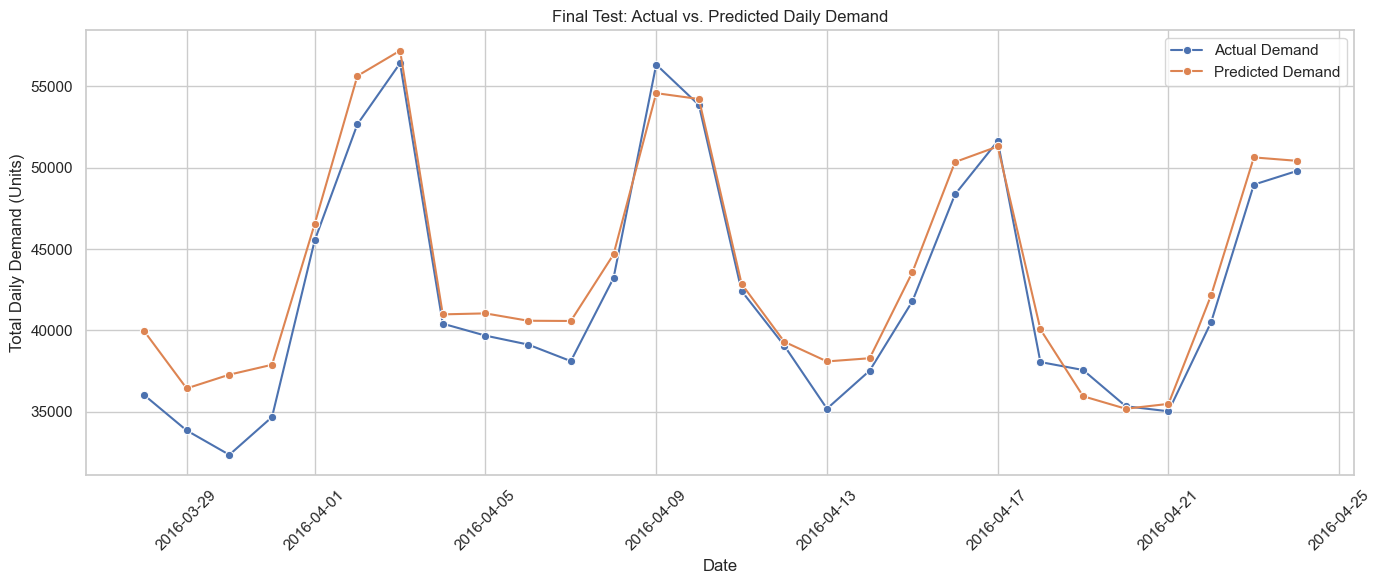

,date,actual_demand,predicted_demand
0,2016-03-28,36041,39979.238281
1,2016-03-29,33857,36439.167969
2,2016-03-30,32359,37284.515625
3,2016-03-31,34681,37893.312500
4,2016-04-01,45536,46552.910156


In [90]:
# Step 14.4 — Visualize actual vs. predicted test demand

test_predictions = test_model[
    ["date", "store_id", "category"]
].copy()

test_predictions["actual_demand"] = y_test.to_numpy()
test_predictions["predicted_demand"] = y_test_pred_final

daily_test_forecast = (
    test_predictions
    .groupby("date", as_index=False)[
        ["actual_demand", "predicted_demand"]
    ]
    .sum()
)

plt.figure(figsize=(14, 6))

sns.lineplot(
    data=daily_test_forecast,
    x="date",
    y="actual_demand",
    marker="o",
    label="Actual Demand"
)

sns.lineplot(
    data=daily_test_forecast,
    x="date",
    y="predicted_demand",
    marker="o",
    label="Predicted Demand"
)

plt.title("Final Test: Actual vs. Predicted Daily Demand")
plt.xlabel("Date")
plt.ylabel("Total Daily Demand (Units)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

display(daily_test_forecast.head())

#### 14.4.1 Interpretation — Actual vs. Predicted Daily Demand

The visualization compares actual and predicted daily retail demand across the **28-day final test period (March 28 – April 24, 2016)**, using predictions generated by the selected Tuned XGBoost Regressor.

The 840 store-category predictions were aggregated into daily demand totals to examine how effectively the model captures overall demand fluctuations.

**1. Overall Forecasting Performance**

The predicted demand curve closely follows the general direction of actual demand throughout the test period.

The model successfully captures several important demand patterns, including:

- Recurring increases in demand toward weekly peaks.
- Sharp reductions in demand following high-demand periods.
- Short-term fluctuations between approximately 32,000 and 57,000 units per day.

This suggests that the model has learned meaningful temporal demand patterns and can reproduce the broad seasonal structure observed during the test period.

**2. Overprediction and Underprediction Patterns**

Although the predicted and actual demand curves follow similar trajectories, some forecasting discrepancies remain.

During the first four days, the model consistently overestimates actual demand:

| Date | Actual demand | Predicted demand | Approx. error |
|---|---:|---:|---:|
| March 28 | 36,041 | 39,979 | +3,938 |
| March 29 | 33,857 | 36,439 | +2,582 |
| March 30 | 32,359 | 37,285 | +4,926 |
| March 31 | 34,681 | 37,893 | +3,212 |

The largest overprediction among these four dates occurred on **March 30**, when predicted demand exceeded actual demand by approximately **4,926 units**.

Additional overprediction is visible around April 13–16 and April 23–24.

Conversely, some underprediction occurs around the demand peaks, particularly near April 9 and April 18–19.

These deviations indicate that the model captures the overall demand trajectory but does not reproduce every daily fluctuation precisely.

**3. Capturing Demand Peaks and Weekly Patterns**

One of the strongest aspects of the forecast is its ability to identify recurring demand peaks.

The predicted curve rises and falls at approximately the same times as the actual demand curve, particularly during the early-April and mid-April high-demand periods.

This behavior is important for retail operations because anticipating demand peaks can support inventory replenishment, warehouse planning, and store-level stock allocation.

However, the model occasionally overestimates or underestimates the magnitude of these peaks, which could affect the quantities ordered or distributed.

**4. Relationship to Final Test Metrics**

The visual findings are consistent with the final test evaluation:

- **MAE:** 121.360 units per store-category observation
- **RMSE:** 182.666 units
- **WAPE:** 8.613%
- **R²:** 0.976

These metrics indicate strong overall predictive performance at the store-category level.

However, the daily totals in the visualization represent demand aggregated across all 30 store-category series. Consequently, the errors visible in the chart are not directly equivalent to the MAE and RMSE calculated for individual store-category observations.

Overpredictions and underpredictions across different series may also partially offset each other when aggregated.

**5. Business Implications**

The results suggest that Tuned XGBoost can provide useful demand forecasts for operational retail planning.

Its ability to capture recurring demand peaks could support inventory allocation and replenishment decisions.

Nevertheless, the early-period overprediction illustrates a potential business risk: systematically forecasting more demand than customers actually generate may lead to unnecessary stock allocation or excess inventory.

Additional analysis at the store and category levels will help identify whether forecasting errors are concentrated in particular business segments.

**Overall Conclusion**

The actual-versus-predicted visualization provides further evidence that Tuned XGBoost captures the principal demand patterns during the reserved test period.

Although some overprediction and underprediction remain, the model tracks the overall daily demand trajectory effectively.

Combined with the final test WAPE of **8.613%** and R² of **0.976**, these findings support the model's usefulness for store-category retail demand forecasting, while highlighting opportunities to improve prediction accuracy for individual dates and demand peaks.

## Step 15 — Feature Importance Analysis

### 15.1 Feature Importance of the Tuned XGBoost Regressor

Following the successful final test evaluation, feature importance analysis will be conducted to identify which predictors contribute most strongly to the forecasting decisions made by the **Tuned XGBoost Regressor**.

The final model achieved a test MAE of **121.360**, RMSE of **182.666**, WAPE of **8.613%**, and R² of **0.976**.

The analysis will examine the relative importance of the model's 78 predictor variables, including:

- Historical demand lags and rolling statistics.
- Product categories and store identifiers.
- Pricing information.
- Calendar and seasonal variables.
- Events and SNAP indicators.

XGBoost's built-in feature importance scores will be extracted, ranked, and visualized to identify the 20 most influential predictors.

These scores describe how the trained model uses its features. They do not establish causal relationships between predictors and retail demand.

The objective is to improve model interpretability and identify which historical and contextual information contributes most strongly to retail demand forecasting.

,Feature,Importance
0,lag_28,0.4292
1,rolling_mean_28,0.1486
2,lag_35,0.0941
3,store_id_CA_3,0.0463
4,lag_56,0.0451
5,rolling_mean_7,0.0344
6,lag_42,0.0293
7,snap,0.0198
8,event_name_combined_Christmas,0.0169
9,category_FOODS,0.0159


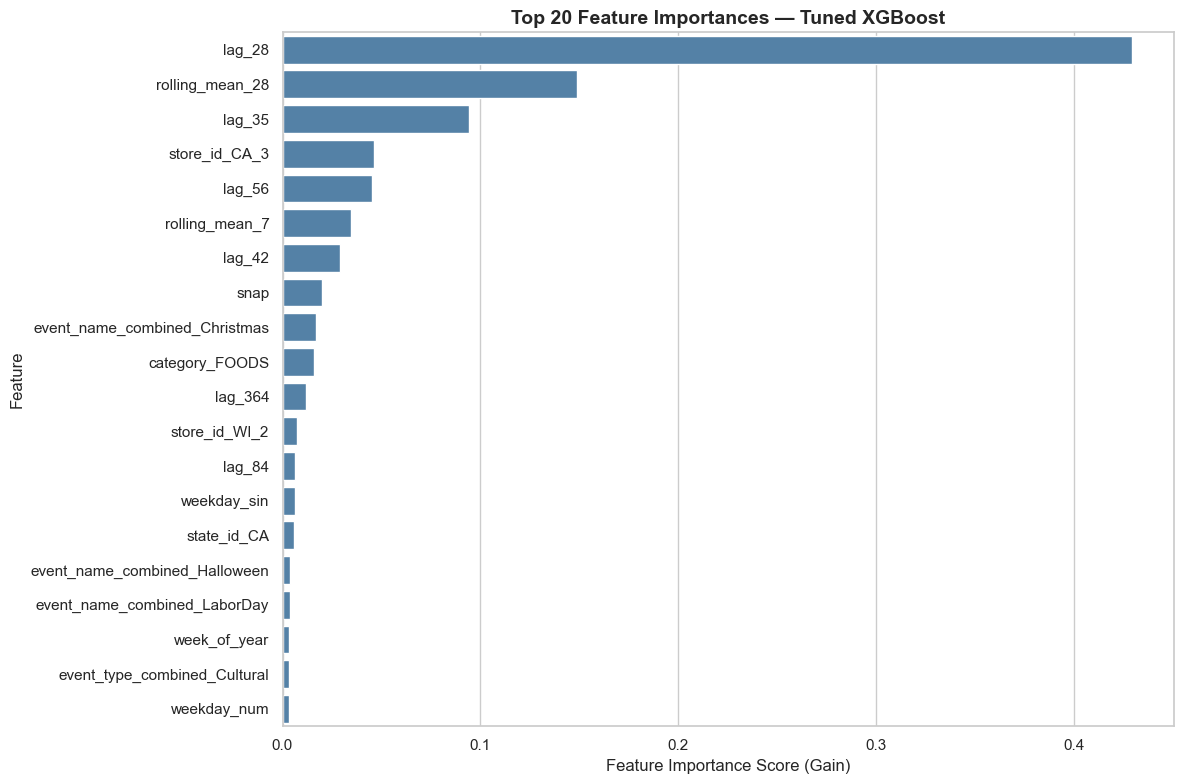

In [91]:


# Step 15.1 — Feature Importance: Tuned XGBoost

sns.set_theme(style="whitegrid")

# Extract feature importance scores from the final XGBoost model
feature_importance = pd.DataFrame({
    "Feature": X_final_train.columns,
    "Importance": final_xgboost.feature_importances_
})

# Rank features by importance
feature_importance = (
    feature_importance
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)

# Select the 20 most important features
top_20_features = feature_importance.head(20)

display(top_20_features.round(4))

# Visualize feature importance
plt.figure(figsize=(12, 8))

sns.barplot(
    data=top_20_features,
    x="Importance",
    y="Feature",
    color="steelblue"
)

plt.title(
    "Top 20 Feature Importances — Tuned XGBoost",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Feature Importance Score (Gain)")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


#### 15.1.1 Interpretation — Tuned XGBoost Feature Importance

The feature-importance analysis identifies the predictors that contribute most strongly to the forecasting decisions of the final Tuned XGBoost Regressor.

The results demonstrate that **historical demand patterns dominate the model's predictions**, with lagged demand and rolling-average features accounting for most of the importance among the highest-ranked predictors.

**1. Historical Demand as the Primary Forecasting Driver**

The three most influential predictors are:

| Feature | Importance |
|---|---:|
| `lag_28` | 0.4292 |
| `rolling_mean_28` | 0.1486 |
| `lag_35` | 0.0941 |

Together, these three features account for approximately **67.19% of the total feature-importance score**.

The most important predictor, `lag_28`, contributes approximately **42.92%** of the model's total importance.

This suggests that demand observed 28 days earlier provides particularly useful information for predicting future demand.

The second-ranked predictor, `rolling_mean_28`, captures historical demand levels over a longer period, helping the model estimate underlying demand patterns rather than relying exclusively on individual historical observations.

Similarly, `lag_35` provides an additional historical reference point, helping the model recognize recurring demand behavior.

The prominence of these features supports the project's use of historical demand information for 28-day-ahead retail forecasting.

**2. Additional Historical Demand Features**

Other important demand-based predictors include:

- `lag_56`: 0.0451
- `rolling_mean_7`: 0.0344
- `lag_42`: 0.0293
- `lag_364`: 0.0117
- `lag_84`: 0.0065

These features provide information about historical demand at different time intervals.

The importance of several historical lags indicates that the model benefits from examining multiple historical periods rather than relying on a single lag.

**3. Store and Category Characteristics**

The model also assigns importance to store-specific and category-specific predictors.

Notable examples include:

- `store_id_CA_3`: 0.0463
- `category_FOODS`: 0.0159
- `store_id_WI_2`: 0.0076
- `state_id_CA`: 0.0056

These results suggest that differences between stores, states, and product categories help the model distinguish demand patterns across the 30 forecasting series.

For example, the importance of `store_id_CA_3` indicates that identifying observations associated with this store contributes to the model's predictions.

However, feature importance does not establish whether a particular store consistently experiences higher or lower demand.

**4. SNAP, Events, and Calendar Effects**

The SNAP indicator contributes an importance score of **0.0198**, suggesting that SNAP-related information provides additional predictive value.

Event-related predictors also appear among the top 20 features:

- Christmas: 0.0169
- Halloween: 0.0039
- Labor Day: 0.0037
- Cultural events: 0.0034

Calendar features such as `weekday_sin`, `week_of_year`, and `weekday_num` also contribute to the model.

These findings suggest that the model uses contextual information about seasonal patterns, calendar timing, and special events alongside historical demand.

However, these variables have considerably lower individual importance scores than the leading historical demand predictors.

**5. Interpretation of XGBoost Importance Scores**

The importance values represent relative contributions within the fitted XGBoost model, based on its tree-based importance calculation.

They should not be interpreted as causal effects or as the percentage change in demand caused by a predictor.

Furthermore, correlated predictors may share predictive information, meaning that the importance assigned to one feature can be influenced by the presence of other related features.

Therefore, these results explain which variables the model relies on most heavily, rather than establishing independent causal relationships.

**6. Business Implications**

The dominance of historical demand features highlights the importance of maintaining accurate, consistent, and sufficiently detailed historical sales records.

For retail businesses, this suggests that demand forecasting systems should prioritize reliable historical sales information while incorporating contextual factors such as store location, product category, SNAP participation, and seasonal events.

The importance of store-specific predictors also supports forecasting at the store-category level rather than assuming identical demand patterns across all retail locations.

**Overall Conclusion**

The Tuned XGBoost model relies primarily on historical demand information, particularly `lag_28`, `rolling_mean_28`, and `lag_35`.

Store characteristics, SNAP indicators, and event-related variables provide additional predictive information.

These findings are consistent with the model's strong final test performance, including a **WAPE of 8.613%** and **R² of 0.976**, although feature-importance scores alone do not explain or guarantee that performance.

The next analysis will group individual predictors into broader feature categories to determine whether historical demand, store characteristics, pricing, or calendar-related information contributes most strongly overall.

### 15.2 Grouped Feature Importance Analysis

Following the individual feature-importance analysis, predictors will be grouped into broader categories to better understand the types of information used by the final **Tuned XGBoost Regressor**.

The analysis will organize all 78 predictor variables into the following feature groups:

- Historical Demand Lags
- Rolling Demand Statistics
- Product Categories
- Pricing Features
- Store & Geographic Features
- Events & SNAP
- Calendar & Seasonality

The individual XGBoost feature-importance scores will be summed within each group to estimate their combined relative importance.

This analysis will help determine whether historical demand patterns, retail characteristics, pricing, or calendar-related information contribute most strongly to the model's forecasting decisions.

Because the scores represent relative model importance rather than causal effects, the results will be interpreted as evidence of how the model uses different feature families.

### 15.2 Grouped Feature Importance Analysis

To provide a broader interpretation of the forecasting model, individual feature importance scores will be grouped into meaningful categories.

The groups include historical demand lags, rolling statistics, product categories, pricing features, store and geographic indicators, calendar variables, and retail events.

This analysis will help identify which types of information contribute most strongly to forecasting performance.

Feature importance scores will be summed within each group to compare their relative contributions.

,Feature Group,Importance,Importance (%)
0,Historical Demand Lags,0.616,61.584999
1,Rolling Demand Statistics,0.184,18.415001
2,Events & SNAP,0.074,7.393000
3,Store & Geographic Features,0.072,7.234000
4,Calendar & Seasonality,0.029,2.929000
5,Product Categories,0.019,1.927000
6,Pricing Features,0.004,0.355000
7,Other Features,0.002,0.163000


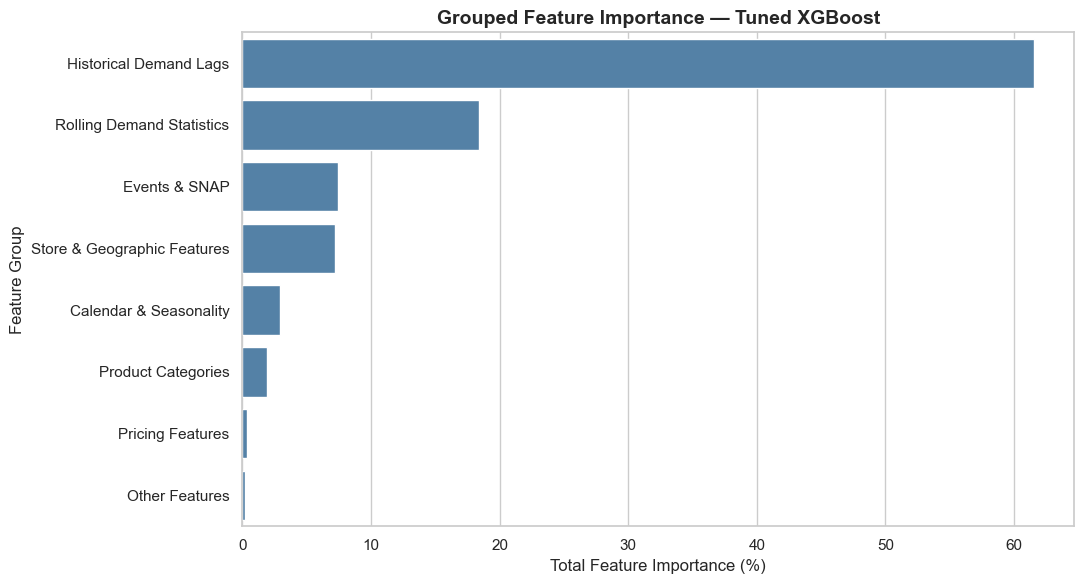

In [92]:

# Step 15.2 — Grouped Feature Importance: Tuned XGBoost

def assign_feature_group(feature):

    if feature.startswith("lag_"):
        return "Historical Demand Lags"

    elif feature.startswith("rolling_"):
        return "Rolling Demand Statistics"

    elif feature.startswith("category_"):
        return "Product Categories"

    elif feature in [
        "avg_sell_price",
        "price_change",
        "price_change_pct"
    ]:
        return "Pricing Features"

    elif (
        feature.startswith("store_id_")
        or feature.startswith("state_id_")
    ):
        return "Store & Geographic Features"

    elif (
        feature.startswith("event_")
        or feature == "snap"
    ):
        return "Events & SNAP"

    elif feature in [
        "weekday_num",
        "month",
        "year",
        "day_of_year",
        "week_of_year",
        "time_index",
        "weekday_sin",
        "weekday_cos",
        "month_sin",
        "month_cos",
        "day_of_year_sin",
        "day_of_year_cos"
    ]:
        return "Calendar & Seasonality"

    else:
        return "Other Features"


# Assign feature groups
feature_importance["Feature Group"] = (
    feature_importance["Feature"].apply(
        assign_feature_group
    )
)

# Aggregate importance scores by group
grouped_importance = (
    feature_importance
    .groupby("Feature Group", as_index=False)["Importance"]
    .sum()
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)

# Convert relative importance to percentages
grouped_importance["Importance (%)"] = (
    grouped_importance["Importance"] * 100
)

display(grouped_importance.round(3))

# Visualize grouped feature importance
plt.figure(figsize=(11, 6))

sns.barplot(
    data=grouped_importance,
    x="Importance (%)",
    y="Feature Group",
    color="steelblue"
)

plt.title(
    "Grouped Feature Importance — Tuned XGBoost",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Total Feature Importance (%)")
plt.ylabel("Feature Group")

plt.tight_layout()
plt.show()


#### 15.2.1 Interpretation — Grouped Feature Importance

The grouped feature-importance analysis examines how different categories of predictors contribute to the forecasting decisions of the final **Tuned XGBoost Regressor**.

The results demonstrate that historical demand information dominates the model's predictions, while event-related, geographic, calendar, category, and pricing variables provide smaller contributions.

**1. Historical Demand Features Dominate the Model**

The two most influential feature groups are:

| Feature Group | Importance (%) |
|---|---:|
| Historical Demand Lags | 61.585% |
| Rolling Demand Statistics | 18.415% |
| **Combined Historical Demand Features** | **80.000%** |

Together, these groups account for approximately **80% of the model's total feature importance**.

This indicates that the model relies heavily on historical demand patterns when forecasting future retail sales.

Historical demand lags provide information about sales recorded at specific previous dates, while rolling statistics summarize historical demand behavior across multiple days.

Their combined importance suggests that past demand levels and recurring temporal patterns are central to the model's forecasting decisions.

This finding is consistent with the individual feature-importance analysis, where `lag_28`, `rolling_mean_28`, and `lag_35` were the three highest-ranked predictors.

**2. Events and SNAP Indicators**

The Events & SNAP group contributes **7.393%** of total feature importance, making it the third most influential feature category.

This group includes SNAP indicators and information about special events and holidays.

Its contribution suggests that contextual factors associated with calendar events and SNAP participation provide useful information beyond historical demand patterns.

However, the model relies considerably more heavily on historical demand than on these contextual indicators.

**3. Store and Geographic Characteristics**

Store & Geographic Features contribute **7.234%** of the model's total importance.

These variables help distinguish demand behavior across different retail locations and states.

The result suggests that location-specific information is relevant when forecasting demand across the 30 store-category series.

This supports the project's decision to forecast at the store-category level rather than using a single undifferentiated demand series.

**4. Calendar and Product Category Features**

Calendar & Seasonality contributes **2.929%**, while Product Categories contributes **1.927%**.

Calendar variables provide information about weekdays, months, and seasonal timing, while category indicators distinguish different product groups.

Although these features contribute less importance than historical demand variables, they provide additional contextual information that may help the model account for differences in demand patterns.

Their relatively low scores should not be interpreted as evidence that seasonality or product categories have no influence on demand.

Some of their predictive information may already be represented by the historical lag and rolling-demand features.

**5. Limited Importance of Pricing Features**

Pricing Features contribute only **0.355%** of the model's total importance.

This is substantially lower than the importance assigned to historical demand, events, and geographic variables.

The result indicates that the fitted XGBoost model relies relatively little on the available pricing predictors when generating its forecasts.

However, this does not establish that prices have little economic influence on customer purchasing behavior.

The low importance may reflect the available pricing information, the level of data aggregation, correlations with other predictors, or the model's feature-selection behavior.

Therefore, pricing importance should be interpreted as a model-specific finding rather than a causal conclusion.

**6. Other Features**

The remaining unclassified predictors contribute **0.163%** of total importance.

Their small combined contribution indicates that they play a limited role in the fitted model relative to the major feature groups.

**7. Business Implications**

The results suggest several practical implications for retail demand forecasting.

First, maintaining accurate historical sales records is particularly important because the model depends heavily on historical demand patterns.

Second, contextual information about events, SNAP participation, and geographic characteristics provides additional predictive value and should be retained where reliable data are available.

Third, the dominance of historical demand features suggests that consistent sales-history collection and appropriate lag engineering may be especially valuable when developing similar retail forecasting systems.

Finally, the low model importance assigned to pricing variables should encourage further investigation rather than the conclusion that pricing decisions are unimportant.

**Overall Conclusion**

The grouped feature-importance analysis confirms that **historical demand lags and rolling-demand statistics jointly account for 80.00% of the Tuned XGBoost model's relative feature importance**.

Events & SNAP (**7.393%**) and Store & Geographic Features (**7.234%**) provide the largest additional contributions.

Calendar, product category, and pricing predictors play smaller roles within the fitted model.

These findings reinforce the importance of historical demand information in the project's 28-day-ahead forecasting approach and provide useful insight into how the final model generates its predictions.

The importance scores describe model behavior and should not be interpreted as causal effects or direct percentages of demand explained by each feature group.

## Step 16 — Final Forecast Error Analysis

### 16.1 Forecast Error Analysis by Product Category

Following the final test evaluation and feature-importance analysis, this section examines the **182.666**, **WAPE of 8.613%**, and **R² of 0.976**, forecasting accuracy may differ between product categories.

To investigate these differences, the final test predictions will be grouped by category and evaluated using four metrics:

- **MAE:** Average absolute forecasting error in demand units.
- **RMSE:** Forecasting error that places greater emphasis on large deviations.
- **WAPE:** Total absolute forecasting error relative to actual demand.
- **R²:** Proportion of observed demand variation explained by the model.

WAPE will be the primary metric for comparing categories because demand volumes differ across product groups.forecasting performance of the **Tuned XGBoost Regressor** across the three Walmart product categories: **FOODS, HOBBIES, and HOUSEHOLD**.

Although the model achieved strong overall test performance, with a **MAE of 121.360**, **RMSE of&#x20;**

The analysis aims to identify which categories exhibit the strongest relative forecasting accuracy and which may require additional attention in inventory planning.

The results will support a more detailed assessment of the model's reliability beyond its overall test metrics.


,Category,MAE,RMSE,WAPE (%),R2
0,FOODS,225.903,287.073,7.997,0.895
1,HOUSEHOLD,87.742,117.147,8.714,0.905
2,HOBBIES,50.434,62.976,12.748,0.751


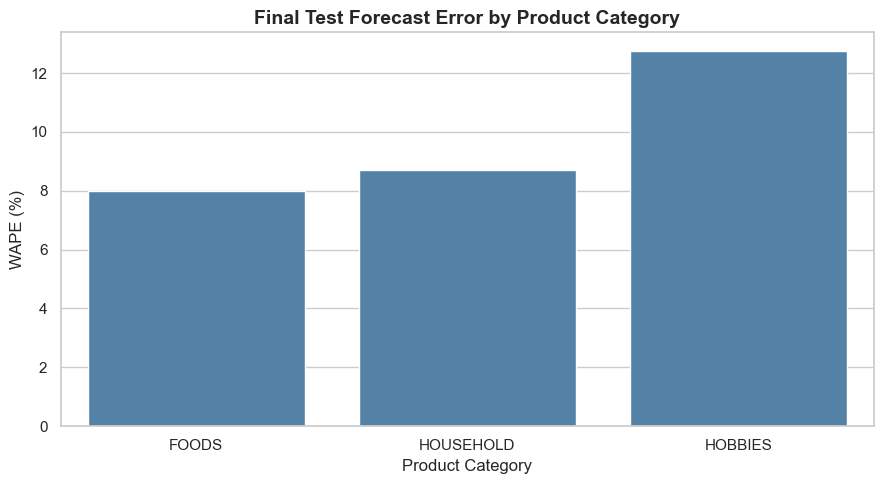

In [93]:

# Step 16.1 — Forecast Error Analysis by Product Category

# Use the final test predictions created in Step 14.4
category_results = []

for category, group in test_predictions.groupby("category"):

    actual = group["actual_demand"].to_numpy()
    predicted = group["predicted_demand"].to_numpy()

    mae = mean_absolute_error(actual, predicted)

    rmse = np.sqrt(
        mean_squared_error(actual, predicted)
    )

    wape = (
        np.sum(np.abs(actual - predicted))
        / np.sum(np.abs(actual))
        * 100
    )

    r2 = r2_score(actual, predicted)

    category_results.append({
        "Category": category,
        "MAE": mae,
        "RMSE": rmse,
        "WAPE (%)": wape,
        "R2": r2
    })

category_performance = (
    pd.DataFrame(category_results)
    .sort_values("WAPE (%)")
    .reset_index(drop=True)
)

display(category_performance.round(3))

# Visualize category-level WAPE
plt.figure(figsize=(9, 5))

sns.barplot(
    data=category_performance,
    x="Category",
    y="WAPE (%)",
    color="steelblue"
)

plt.title(
    "Final Test Forecast Error by Product Category",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Product Category")
plt.ylabel("WAPE (%)")
plt.tight_layout()
plt.show()


#### 16.1.1 Interpretation — Forecast Error by Product Category

The category-level error analysis evaluates the performance of the final **Tuned XGBoost Regressor** across the three Walmart product categories during the reserved 28-day test period.

The results show that forecasting accuracy varies between product categories, despite the model's strong overall test performance.

**1. Comparison of Forecasting Performance**

| Category | MAE | RMSE | WAPE (%) | R² |
|---|---:|---:|---:|---:|
| FOODS | 225.903 | 287.073 | 7.997 | 0.895 |
| HOUSEHOLD | 87.742 | 117.147 | 8.714 | 0.905 |
| HOBBIES | 50.434 | 62.976 | 12.748 | 0.751 |

**2. FOODS — Strongest Relative Forecasting Accuracy**

FOODS achieved the lowest WAPE of **7.997%**, indicating the strongest relative forecasting accuracy among the three categories.

However, it also recorded the highest absolute forecasting errors:

- MAE: 225.903 units
- RMSE: 287.073 units
- R²: 0.895

The relatively high MAE and RMSE are consistent with the larger demand volumes associated with this category.

Despite these larger absolute errors, FOODS demonstrates the best performance when errors are evaluated relative to actual demand.

From a business perspective, this suggests that the model provides useful demand estimates for food inventory planning, although errors of several hundred units per store-category observation may still have operational consequences.

**3. HOUSEHOLD — Balanced Forecasting Performance**

HOUSEHOLD achieved a WAPE of **8.714%**, slightly higher than FOODS.

Its MAE of **87.742 units** and RMSE of **117.147 units** indicate smaller absolute errors.

HOUSEHOLD also achieved the highest category-level R² of **0.905**, suggesting that the model captures approximately 90.5% of the variation in observed household demand across the evaluated observations.

Overall, HOUSEHOLD demonstrates strong and relatively balanced forecasting performance.

**4. HOBBIES — Highest Relative Forecasting Error**

HOBBIES recorded the highest WAPE of **12.748%**, indicating the weakest relative forecasting accuracy among the three categories.

Its evaluation metrics were:

- MAE: 50.434 units
- RMSE: 62.976 units
- R²: 0.751

Although HOBBIES has the lowest absolute errors, its higher WAPE indicates that these errors are larger relative to the category's actual demand volume.

The lower R² also suggests that the model captures less of the observed variation in HOBBIES demand than in the other categories.

These findings identify HOBBIES as a potential priority for further model improvement.

Possible areas for investigation include category-specific demand patterns, intermittent purchasing behavior, promotional effects, and additional feature engineering. However, the present analysis does not establish which of these factors explains the higher error.

**5. Business Implications**

The results highlight the importance of evaluating forecasting performance separately for different retail product categories.

For FOODS, relatively low WAPE supports the use of forecasts in inventory replenishment, although larger absolute errors must be considered when determining stock quantities.

For HOUSEHOLD, the combination of low relative error and strong R² suggests useful forecasting performance for inventory planning.

For HOBBIES, higher relative forecasting errors suggest a greater need for cautious inventory decisions, additional monitoring, or category-specific forecasting improvements.

These differences demonstrate why a single overall performance metric may not fully describe the reliability of forecasts across different retail segments.

**6. Relationship to Overall Model Performance**

The final Tuned XGBoost model achieved an overall test WAPE of **8.613%**.

The category-level results show that:

- FOODS performs better than the overall WAPE.
- HOUSEHOLD performs slightly worse than the overall WAPE.
- HOBBIES has a substantially higher relative forecasting error.

The overall WAPE is calculated using total absolute errors and total actual demand across all categories. Therefore, it is not the simple arithmetic average of the three category-level WAPE values.

Categories with larger demand volumes contribute more heavily to the overall metric.

**Overall Conclusion**

The category-level analysis confirms that Tuned XGBoost delivers different levels of forecasting accuracy across Walmart's product categories.

**FOODS achieves the strongest relative forecasting performance (7.997% WAPE), HOUSEHOLD follows closely (8.714%), and HOBBIES presents the greatest forecasting challenge (12.748%).**

These findings demonstrate that the model's strong overall performance does not imply uniform accuracy across all product categories.

The results provide a foundation for targeted forecasting improvements and category-specific inventory management strategies.

### 16.2 Store-Level Forecast Error Analysis

Following the product-category analysis, this section evaluates the forecasting performance of the final **Tuned XGBoost Regressor** across Walmart's 10 stores in California (CA), Texas (TX), and Wisconsin (WI).

Although the model achieved an overall test WAPE of **8.613%**, forecasting accuracy may vary between stores because of differences in demand volumes, purchasing patterns, product composition, and local conditions.

The analysis will compare store-level forecasting performance using:

- **MAE:** Average absolute forecasting error in demand units.
- **RMSE:** Forecasting error with greater emphasis on larger deviations.
- **WAPE:** Total absolute forecasting error relative to observed demand.
- **R²:** Proportion of observed demand variation explained by the model.

WAPE will serve as the primary comparison metric because stores may operate at different demand volumes.

The objective is to identify stores with the strongest relative forecasting accuracy and those experiencing higher forecasting errors.

These findings will help assess the consistency of the model across retail locations and highlight potential opportunities for store-specific forecasting improvements.

Store-Level Forecast Performance:


,Store,MAE,RMSE,WAPE (%),R2
0,WI_3,95.896,134.587,7.204,0.987
1,TX_1,81.950,116.749,7.420,0.978
2,CA_4,66.497,85.486,7.527,0.981
3,CA_3,162.015,223.065,7.690,0.977
4,CA_1,122.336,174.358,8.031,0.977
5,CA_2,125.883,192.642,8.457,0.971
6,WI_2,152.762,242.758,8.495,0.979
7,WI_1,118.772,179.329,9.300,0.971
8,TX_2,142.019,209.999,10.835,0.952
9,TX_3,145.468,205.320,11.482,0.947


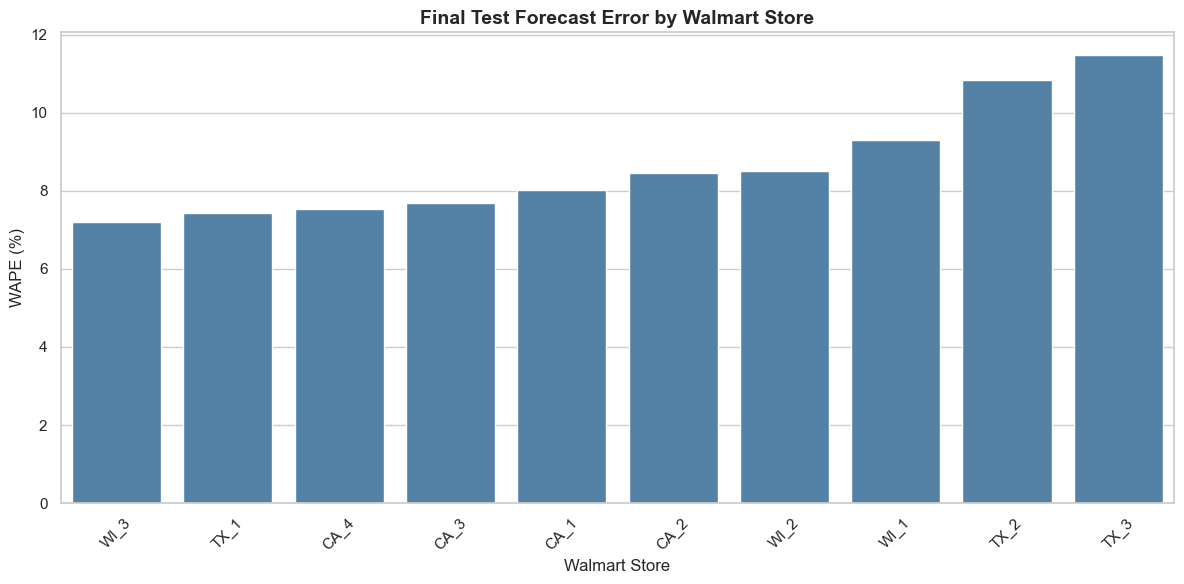

In [94]:

# Step 16.2 — Store-Level Forecast Error Analysis

store_results = []

# Calculate metrics for each Walmart store
for store, group in test_predictions.groupby("store_id"):

    actual = group["actual_demand"].to_numpy()
    predicted = group["predicted_demand"].to_numpy()

    mae = mean_absolute_error(actual, predicted)

    rmse = np.sqrt(
        mean_squared_error(actual, predicted)
    )

    wape = (
        np.sum(np.abs(actual - predicted))
        / np.sum(np.abs(actual))
        * 100
    )

    r2 = r2_score(actual, predicted)

    store_results.append({
        "Store": store,
        "MAE": mae,
        "RMSE": rmse,
        "WAPE (%)": wape,
        "R2": r2
    })

# Create and rank store-level results
store_performance = (
    pd.DataFrame(store_results)
    .sort_values("WAPE (%)", ascending=True)
    .reset_index(drop=True)
)

print("Store-Level Forecast Performance:")
display(store_performance.round(3))

# Visualize WAPE across stores
plt.figure(figsize=(12, 6))

sns.barplot(
    data=store_performance,
    x="Store",
    y="WAPE (%)",
    color="steelblue"
)

plt.title(
    "Final Test Forecast Error by Walmart Store",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Walmart Store")
plt.ylabel("WAPE (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


#### 16.2.1 Interpretation — Store-Level Forecast Error Analysis

The store-level error analysis evaluates the forecasting performance of the final **Tuned XGBoost Regressor** across Walmart's 10 stores during the reserved 28-day test period.

The results demonstrate that forecasting accuracy differs between locations, although the model maintains relatively low forecasting errors across most stores.

### 1. Store-Level Performance Comparison

| Store | MAE | RMSE | WAPE (%) | R² |
|---|---:|---:|---:|---:|
| WI_3 | 95.896 | 134.587 | 7.204 | 0.987 |
| TX_1 | 81.950 | 116.749 | 7.420 | 0.978 |
| CA_4 | 66.497 | 85.486 | 7.527 | 0.981 |
| CA_3 | 162.015 | 223.065 | 7.690 | 0.977 |
| CA_1 | 122.336 | 174.358 | 8.031 | 0.977 |
| CA_2 | 125.883 | 192.642 | 8.457 | 0.971 |
| WI_2 | 152.762 | 242.758 | 8.495 | 0.979 |
| WI_1 | 118.772 | 179.329 | 9.300 | 0.971 |
| TX_2 | 142.019 | 209.999 | 10.835 | 0.952 |
| TX_3 | 145.468 | 205.320 | 11.482 | 0.947 |

### 2. Strongest Performing Stores

The three stores with the lowest relative forecasting errors are:

- **WI_3:** 7.204% WAPE
- **TX_1:** 7.420% WAPE
- **CA_4:** 7.527% WAPE

WI_3 achieved the lowest WAPE and the highest R² of **0.987**, indicating particularly strong forecasting performance.

TX_1 also demonstrated reliable forecasting accuracy, with a WAPE of 7.420% and an MAE of 81.950 units.

CA_4 recorded the lowest absolute errors among all stores, with an MAE of **66.497 units** and RMSE of **85.486 units**.

These findings suggest that the model captures demand patterns particularly effectively at these locations.

### 3. Stores with Moderate Forecasting Errors

CA_3, CA_1, CA_2, WI_2, and WI_1 achieved WAPE values between **7.690% and 9.300%**.

Their results indicate generally strong forecasting performance, although differences in absolute errors remain.

For example, CA_3 recorded an MAE of **162.015 units**, the highest among the 10 stores, despite achieving a relatively low WAPE of 7.690%.

This illustrates the importance of considering demand volumes when comparing absolute forecasting errors.

A store with higher sales volumes may experience larger absolute errors while maintaining good relative forecasting accuracy.

### 4. Stores Requiring Additional Attention

The two stores with the highest relative forecasting errors are:

| Store | WAPE (%) | R² |
|---|---:|---:|
| TX_2 | 10.835 | 0.952 |
| TX_3 | 11.482 | 0.947 |

TX_3 recorded the highest WAPE and the lowest R² among the evaluated stores.

TX_2 also experienced relatively high forecasting errors compared with the remaining locations.

Although both stores maintained R² values above 0.94, their higher WAPE indicates that forecasting errors represent a larger proportion of observed demand.

These results suggest that TX_2 and TX_3 could benefit from further investigation into store-specific demand patterns.

Potential areas for investigation include local demand variability, category composition, promotional activity, and seasonal effects. However, the current analysis does not establish which factors explain their higher forecasting errors.

### 5. Geographic Observations

The results reveal some differences between stores located in California, Texas, and Wisconsin.

California stores achieved WAPE values ranging from **7.527% to 8.457%**, indicating relatively consistent forecasting accuracy.

Wisconsin stores ranged from **7.204% to 9.300%**, with WI_3 achieving the best performance overall.

Texas stores showed the widest range, from **7.420% at TX_1** to **11.482% at TX_3**.

This suggests greater variation in forecasting accuracy among the Texas stores during the test period.

However, these differences should not be interpreted as evidence that geographic location itself causes forecasting errors.

### 6. Business Implications

The store-level results provide useful insights for retail inventory planning.

Stores with lower forecasting errors may be better positioned to use model predictions for routine replenishment and stock-allocation decisions.

Stores with higher forecasting errors, particularly TX_2 and TX_3, may require closer forecast monitoring and more conservative inventory decisions.

The findings also suggest that a single forecasting model can perform differently across retail locations, even when it achieves strong overall accuracy.

Monitoring store-level performance can therefore help retailers identify where additional model improvements or operational adjustments may be most valuable.

### Overall Conclusion

The Tuned XGBoost model demonstrates strong forecasting performance across most Walmart stores.

**WI_3 achieved the lowest relative forecasting error (7.204% WAPE), while TX_3 recorded the highest (11.482% WAPE).**

Eight of the ten stores achieved WAPE below 10%, indicating relatively consistent forecasting accuracy across the majority of locations.

Nevertheless, the higher errors observed at TX_2 and TX_3 highlight opportunities for targeted investigation and store-specific forecasting improvements.

These findings reinforce the importance of evaluating forecasting models at the store level rather than relying exclusively on overall test performance.

### 16.3 State-Level Forecast Error Analysis

Following the store-level evaluation, this section examines the forecasting performance of the final **Tuned XGBoost Regressor** across Walmart's three operating states: **California (CA), Texas (TX), and Wisconsin (WI)**.

The objective is to determine whether forecasting accuracy differs geographically and to identify states where the model produces relatively higher or lower prediction errors.

The analysis will evaluate state-level forecasting performance using four metrics:

- **MAE:** Average absolute forecasting error in demand units.
- **RMSE:** Forecasting error that places greater emphasis on larger deviations.
- **WAPE:** Total absolute forecasting error relative to observed demand.
- **R²:** Proportion of variation in observed demand explained by the model.

WAPE will serve as the primary metric for comparing forecasting accuracy because demand volumes differ across states.

The analysis will also investigate whether the higher forecasting errors observed at certain Texas stores are reflected in the overall Texas results.

These findings will provide additional insight into the geographic consistency of the model and help identify potential opportunities for regional forecasting improvements.

State-Level Forecast Performance:


,State,MAE,RMSE,WAPE (%),R2
0,CA,119.183,176.478,7.943,0.979
1,WI,122.477,190.791,8.338,0.980
2,TX,123.146,182.470,10.033,0.957


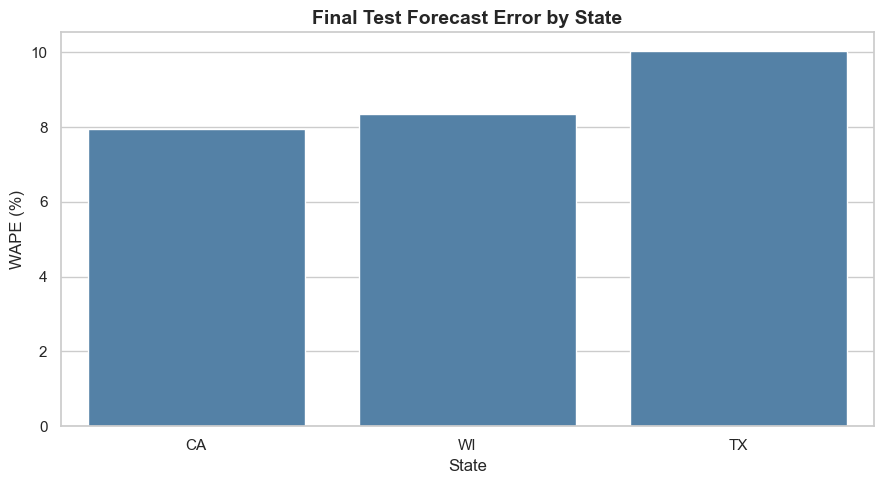

In [95]:

# Step 16.3 — Forecast Error Analysis by State

# Extract state from the store identifier
# Examples: CA_1 -> CA, TX_2 -> TX
test_predictions["state_id"] = (
    test_predictions["store_id"].str.split("_").str[0]
)

state_results = []

for state, group in test_predictions.groupby("state_id"):

    actual = group["actual_demand"].to_numpy()
    predicted = group["predicted_demand"].to_numpy()

    mae = mean_absolute_error(actual, predicted)

    rmse = np.sqrt(
        mean_squared_error(actual, predicted)
    )

    wape = (
        np.sum(np.abs(actual - predicted))
        / np.sum(np.abs(actual))
        * 100
    )

    r2 = r2_score(actual, predicted)

    state_results.append({
        "State": state,
        "MAE": mae,
        "RMSE": rmse,
        "WAPE (%)": wape,
        "R2": r2
    })

state_performance = (
    pd.DataFrame(state_results)
    .sort_values("WAPE (%)")
    .reset_index(drop=True)
)

print("State-Level Forecast Performance:")
display(state_performance.round(3))

# Visualize state-level WAPE
plt.figure(figsize=(9, 5))

sns.barplot(
    data=state_performance,
    x="State",
    y="WAPE (%)",
    color="steelblue"
)

plt.title(
    "Final Test Forecast Error by State",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("State")
plt.ylabel("WAPE (%)")
plt.tight_layout()
plt.show()


#### 16.3.1 Interpretation — State-Level Forecast Error Analysis

The state-level error analysis evaluates the performance of the final **Tuned XGBoost Regressor** across Walmart's three operating states during the reserved 28-day test period.

The results reveal differences in forecasting accuracy between California, Wisconsin, and Texas.

### 1. State-Level Performance Comparison

| State | MAE | RMSE | WAPE (%) | R² |
|---|---:|---:|---:|---:|
| California (CA) | 119.183 | 176.478 | 7.943 | 0.979 |
| Wisconsin (WI) | 122.477 | 190.791 | 8.338 | 0.980 |
| Texas (TX) | 123.146 | 182.470 | 10.033 | 0.957 |

### 2. California — Strongest Relative Forecasting Accuracy

California achieved the lowest WAPE of **7.943%**, indicating the strongest relative forecasting performance among the three states.

It also recorded the lowest MAE of **119.183 units** and RMSE of **176.478 units**, suggesting relatively smaller absolute forecasting errors.

Its R² of **0.979** indicates that the model captures approximately 97.9% of the observed variation in demand across California's evaluated store-category observations.

These findings suggest that the model performs particularly well across California's retail locations.

### 3. Wisconsin — Strong and Consistent Performance

Wisconsin achieved a WAPE of **8.338%**, slightly higher than California but still below the overall test WAPE of 8.613%.

Its MAE was **122.477 units**, while RMSE reached **190.791 units**.

Wisconsin also recorded the highest state-level R² of **0.980**, indicating strong predictive performance.

These results suggest that the model effectively captures demand variation across Wisconsin's stores, although some relatively large individual errors remain.

### 4. Texas — Highest Relative Forecasting Error

Texas recorded the highest WAPE of **10.033%**, indicating weaker relative forecasting accuracy than California and Wisconsin.

Its remaining metrics were:

- MAE: 123.146 units
- RMSE: 182.470 units
- R²: 0.957

Although the model still explains approximately 95.7% of the observed demand variation in Texas, its relative forecasting errors are noticeably higher.

Texas's WAPE exceeds California's by **2.090 percentage points** and Wisconsin's by **1.695 percentage points**.

This finding is consistent with the earlier store-level analysis, where TX_2 and TX_3 recorded WAPE values of 10.835% and 11.482%, respectively.

However, the state-level results do not establish why forecasting accuracy differs between regions.

Potential explanations, such as differences in demand variability, product composition, or local purchasing patterns, would require additional investigation.

### 5. Relationship to Overall Model Performance

The final Tuned XGBoost model achieved an overall test WAPE of **8.613%**.

California and Wisconsin both performed better than this overall benchmark, while Texas recorded a higher relative error.

The state-level WAPE values are calculated using each state's total absolute forecasting errors relative to its total actual demand.

Consequently, the overall WAPE is not simply the arithmetic average of the three state-level values.

States with larger demand volumes contribute more heavily to the overall result.

### 6. Business Implications

The state-level analysis highlights the importance of monitoring forecasting performance geographically.

California and Wisconsin demonstrate relatively strong forecasting accuracy, suggesting that the model can provide useful demand estimates for inventory planning in these regions.

Texas, particularly the TX_2 and TX_3 stores, may benefit from closer forecast monitoring and additional investigation into local demand patterns.

Retail managers could use these findings to prioritize forecasting improvements and adjust inventory-planning decisions according to regional prediction reliability.

However, geographic differences in model performance should not automatically be interpreted as causal effects of location.

### Overall Conclusion

The state-level analysis confirms that the Tuned XGBoost Regressor maintains strong forecasting performance across all three states, although relative forecasting accuracy varies.

**California achieved the lowest WAPE (7.943%), followed by Wisconsin (8.338%), while Texas recorded the highest WAPE (10.033%).**

These findings reinforce the store-level results and identify Texas as a potential priority for further forecasting improvements.

The analysis demonstrates the value of evaluating model performance geographically rather than relying exclusively on overall test metrics.

### 16.4 Weekday Forecast Error Analysis

Following the category-level, store-level, and state-level evaluations, this section examines how forecasting accuracy varies across the seven days of the week.

The analysis uses predictions generated by the final **Tuned XGBoost Regressor** during the reserved 28-day test period, from March 28 to April 24, 2016.

Each weekday occurs four times during the test period, providing 120 store-category observations per weekday.

The objective is to determine whether the model performs consistently throughout the week or experiences greater forecasting errors on particular days.

Forecasting performance will be evaluated using:

- **MAE:** Average absolute forecasting error in demand units.
- **RMSE:** Forecasting error that gives greater weight to larger deviations.
- **WAPE:** Total absolute forecasting error relative to observed demand.
- **R²:** Proportion of observed demand variation explained by the model.

WAPE will serve as the primary comparison metric because daily demand volumes can vary considerably throughout the week.

The analysis will help identify whether forecasting errors are concentrated on particular weekdays or weekends, providing additional insight into the model's ability to capture weekly retail demand patterns.

These findings may support more targeted inventory replenishment, staffing, and stock-allocation decisions.

Weekday Forecast Performance:


,Weekday,MAE,RMSE,WAPE (%),R2
0,Monday,127.487,198.175,9.748,0.966
1,Tuesday,99.616,143.301,7.960,0.981
2,Wednesday,121.374,176.963,10.255,0.967
3,Thursday,101.657,154.332,8.392,0.974
4,Friday,134.152,201.134,9.411,0.969
5,Saturday,144.148,213.769,8.383,0.976
6,Sunday,121.084,180.201,6.863,0.984


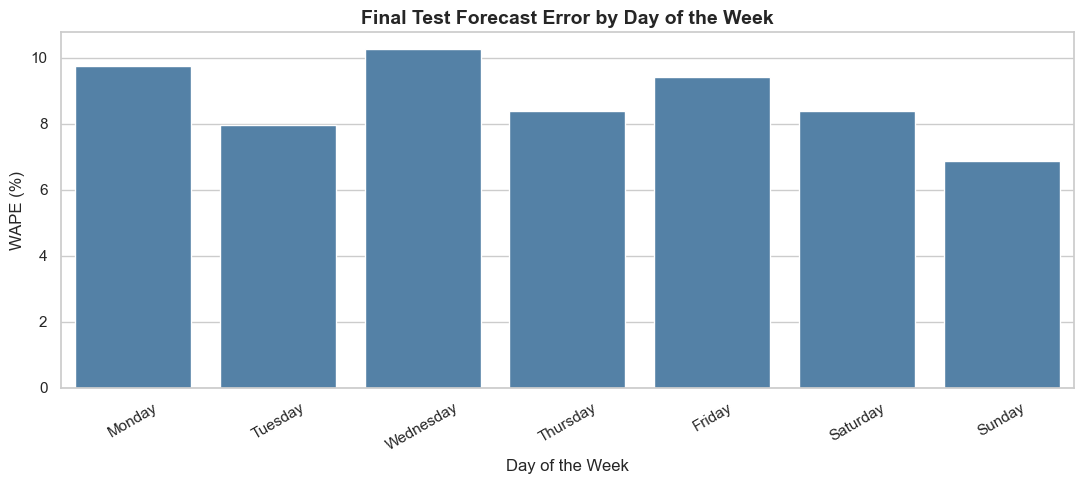

In [96]:

# Step 16.4 — Forecast Error Analysis by Day of the Week

# Create weekday names from test dates
test_predictions["weekday"] = (
    pd.to_datetime(test_predictions["date"]).dt.day_name()
)

weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

weekday_results = []

for weekday, group in test_predictions.groupby("weekday"):

    actual = group["actual_demand"].to_numpy()
    predicted = group["predicted_demand"].to_numpy()

    mae = mean_absolute_error(actual, predicted)

    rmse = np.sqrt(
        mean_squared_error(actual, predicted)
    )

    wape = (
        np.sum(np.abs(actual - predicted))
        / np.sum(np.abs(actual))
        * 100
    )

    r2 = r2_score(actual, predicted)

    weekday_results.append({
        "Weekday": weekday,
        "MAE": mae,
        "RMSE": rmse,
        "WAPE (%)": wape,
        "R2": r2
    })

weekday_performance = pd.DataFrame(weekday_results)

# Sort weekdays chronologically
weekday_performance["Weekday"] = pd.Categorical(
    weekday_performance["Weekday"],
    categories=weekday_order,
    ordered=True
)

weekday_performance = (
    weekday_performance
    .sort_values("Weekday")
    .reset_index(drop=True)
)

print("Weekday Forecast Performance:")
display(weekday_performance.round(3))

# Visualize WAPE by weekday
plt.figure(figsize=(11, 5))

sns.barplot(
    data=weekday_performance,
    x="Weekday",
    y="WAPE (%)",
    color="steelblue"
)

plt.title(
    "Final Test Forecast Error by Day of the Week",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Day of the Week")
plt.ylabel("WAPE (%)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


#### 16.4.1 Interpretation — Weekday Forecast Error Analysis

The weekday-level analysis evaluates the performance of the final **Tuned XGBoost Regressor** across the seven days of the week during the reserved 28-day test period.

Each weekday contains 120 store-category observations, allowing the model's forecasting accuracy to be compared across different days.

### 1. Weekday Performance Comparison

| Weekday | MAE | RMSE | WAPE (%) | R² |
|---|---:|---:|---:|---:|
| Monday | 127.487 | 198.175 | 9.748 | 0.966 |
| Tuesday | 99.616 | 143.301 | 7.960 | 0.981 |
| Wednesday | 121.374 | 176.963 | 10.255 | 0.967 |
| Thursday | 101.657 | 154.332 | 8.392 | 0.974 |
| Friday | 134.152 | 201.134 | 9.411 | 0.969 |
| Saturday | 144.148 | 213.769 | 8.383 | 0.976 |
| Sunday | 121.084 | 180.201 | 6.863 | 0.984 |

### 2. Sunday — Strongest Relative Forecasting Accuracy

Sunday achieved the lowest WAPE of **6.863%**, making it the most accurately forecast day in relative terms.

It also recorded the highest R² of **0.984**, indicating that the model captures approximately 98.4% of the variation in observed Sunday demand across the evaluated observations.

This suggests that the model is particularly effective at forecasting Sunday demand patterns during the test period.

Tuesday also demonstrated strong performance, with a WAPE of **7.960%** and the lowest MAE (**99.616 units**) and RMSE (**143.301 units**) among all weekdays.

### 3. Wednesday — Highest Relative Forecasting Error

Wednesday recorded the highest WAPE of **10.255%**, indicating the weakest relative forecasting accuracy.

Its MAE was **121.374 units**, with an RMSE of **176.963 units** and R² of **0.967**.

Although these metrics still indicate reasonably strong predictive performance, the higher WAPE suggests that forecasting errors represent a larger proportion of observed Wednesday demand.

Monday also recorded a relatively high WAPE of **9.748%**, followed by Friday at **9.411%**.

These findings suggest that the model experiences greater relative forecasting difficulty on certain weekdays.

However, the analysis does not establish whether these differences result from changes in purchasing behavior, promotional activity, or other demand-related factors.

### 4. Saturday — Highest Absolute Forecasting Error

Saturday recorded the highest MAE of **144.148 units** and RMSE of **213.769 units**.

Despite these larger absolute errors, its WAPE was **8.383%**, which is below the overall test WAPE of 8.613%.

This difference illustrates the importance of considering demand volume when comparing forecasting errors.

Higher-demand periods can produce larger absolute prediction errors while maintaining relatively low percentage errors.

Consequently, Saturday's higher MAE does not necessarily indicate weaker relative forecasting accuracy.

### 5. Comparison with Overall Model Performance

The final Tuned XGBoost model achieved an overall test WAPE of **8.613%**.

The weekday results show that:

- **Below overall WAPE:** Sunday (6.863%), Tuesday (7.960%), Saturday (8.383%), and Thursday (8.392%).
- **Above overall WAPE:** Friday (9.411%), Monday (9.748%), and Wednesday (10.255%).

The difference between the lowest and highest weekday WAPE is **3.392 percentage points**.

These results demonstrate that forecasting accuracy varies across the week, even though the model maintains strong overall performance.

The overall WAPE is calculated using total absolute forecasting errors divided by total observed demand. Therefore, it is not the simple arithmetic average of the seven weekday WAPE values.

### 6. Business Implications

The weekday-level results provide useful information for retail inventory planning and operational decision-making.

The relatively strong forecasting accuracy on Sundays and Tuesdays suggests that the model provides reliable demand estimates for these days within the evaluated period.

Wednesdays, Mondays, and Fridays may require closer forecast monitoring because they experience higher relative errors.

Saturday's larger absolute errors also highlight the importance of considering the number of units involved when planning stock replenishment.

Retail managers could use weekday-specific error patterns to adjust inventory buffers, prioritize forecast reviews, and improve replenishment scheduling.

However, these findings are based on four observations of each weekday per store-category series during a single 28-day test period. Additional evaluation periods would be needed to determine whether the same patterns persist consistently.

### Overall Conclusion

The weekday-level analysis confirms that Tuned XGBoost delivers different levels of forecasting accuracy throughout the week.

**Sunday achieved the lowest WAPE (6.863%), while Wednesday recorded the highest WAPE (10.255%).**

Saturday experienced the highest absolute forecasting errors, illustrating the distinction between absolute and relative forecasting accuracy.

These findings reinforce the importance of evaluating retail demand forecasts across multiple dimensions rather than relying exclusively on overall model performance.

### 16.5 Forecast Bias Analysis

Forecast bias analysis investigates whether the final **Tuned XGBoost Regressor** systematically overestimates or underestimates retail demand during the reserved 28-day test period (March 28 – April 24, 2016).

Forecast errors will be defined as:

**Forecast Error = Actual Demand − Predicted Demand**

Under this convention:

- **Positive errors** indicate underprediction, where actual demand exceeds the forecast.
- **Negative errors** indicate overprediction, where predicted demand exceeds actual demand.
- **Errors close to zero** indicate smaller forecasting deviations.

The analysis will examine the average signed error, total signed error, percentage bias, and proportions of overpredictions and underpredictions.

Unlike MAE, RMSE, and WAPE, which measure forecasting error magnitude, signed forecast errors provide information about the direction of prediction errors.

A consistently negative bias may indicate a tendency toward overforecasting, potentially increasing the risk of excess inventory. Conversely, a consistently positive bias may indicate underforecasting, potentially increasing the risk of stockouts.

The objective is to determine whether the model's forecasting errors are approximately balanced or whether there is evidence of systematic overprediction or underprediction.

These findings will complement the earlier category-level, store-level, state-level, and weekday-level evaluations and provide additional insights for retail inventory planning.

Final Test Forecast Bias Summary:


,Metric,Value
0,Mean Signed Error,-44.991
1,Total Signed Error,-37792.635
2,Percentage Bias (%),-3.193
3,Underpredictions,356.000
4,Overpredictions,484.000
5,Exact Predictions,0.000
6,Underprediction Rate (%),42.381
7,Overprediction Rate (%),57.619


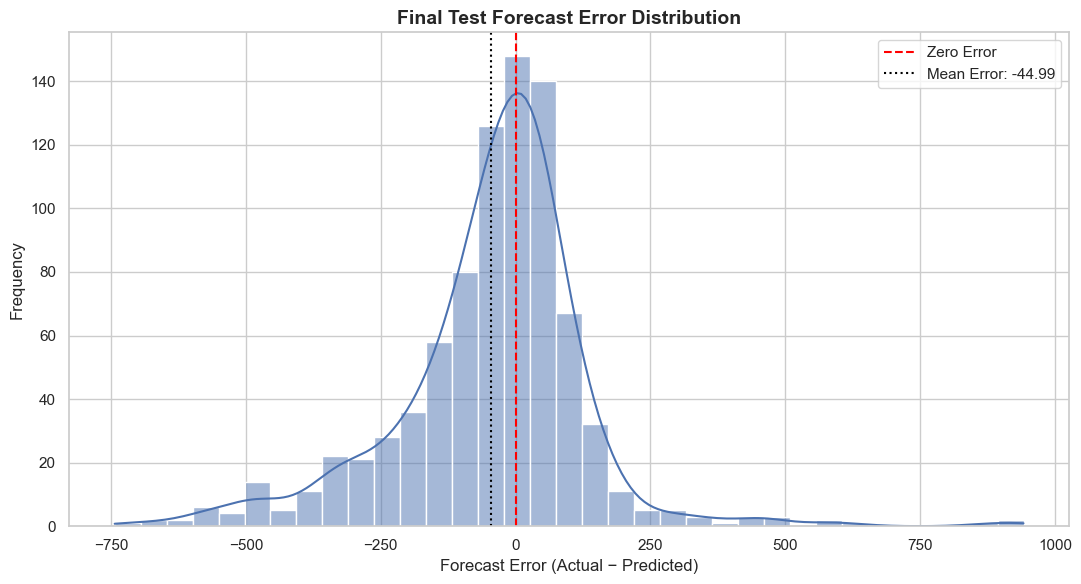

In [97]:
# Step 16.5 — Final Test Forecast Bias Analysis

# Calculate signed forecast errors
test_predictions["error"] = (
    test_predictions["actual_demand"]
    - test_predictions["predicted_demand"]
)

# Overall bias metrics
mean_error = test_predictions["error"].mean()
total_error = test_predictions["error"].sum()

percentage_bias = (
    total_error
    / test_predictions["actual_demand"].sum()
    * 100
)

# Count prediction directions
underpredictions = (test_predictions["error"] > 0).sum()
overpredictions = (test_predictions["error"] < 0).sum()
exact_predictions = (test_predictions["error"] == 0).sum()

total_predictions = len(test_predictions)

bias_summary = pd.DataFrame({
    "Metric": [
        "Mean Signed Error",
        "Total Signed Error",
        "Percentage Bias (%)",
        "Underpredictions",
        "Overpredictions",
        "Exact Predictions",
        "Underprediction Rate (%)",
        "Overprediction Rate (%)"
    ],
    "Value": [
        mean_error,
        total_error,
        percentage_bias,
        underpredictions,
        overpredictions,
        exact_predictions,
        underpredictions / total_predictions * 100,
        overpredictions / total_predictions * 100
    ]
})

print("Final Test Forecast Bias Summary:")
display(bias_summary.round(3))

# Visualize signed error distribution
plt.figure(figsize=(11, 6))

sns.histplot(
    data=test_predictions,
    x="error",
    bins=35,
    kde=True
)

plt.axvline(
    0,
    color="red",
    linestyle="--",
    label="Zero Error"
)

plt.axvline(
    mean_error,
    color="black",
    linestyle=":",
    label=f"Mean Error: {mean_error:.2f}"
)

plt.title(
    "Final Test Forecast Error Distribution",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Forecast Error (Actual − Predicted)")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()
plt.show()


#### 16.5.1 Interpretation — Final Test Forecast Bias

The forecast bias analysis examines whether the final **Tuned XGBoost Regressor** systematically overestimates or underestimates retail demand during the reserved 28-day test period.

Forecast errors were calculated as:

**Forecast Error = Actual Demand − Predicted Demand**

Under this definition, negative errors indicate overprediction, while positive errors indicate underprediction.

### 1. Forecast Bias Summary

| Metric | Result |
|---|---:|
| Mean Signed Error | −44.991 units |
| Total Signed Error | −37,792.635 units |
| Percentage Bias | −3.193% |
| Underpredictions | 356 |
| Overpredictions | 484 |
| Exact Predictions | 0 |
| Underprediction Rate | 42.381% |
| Overprediction Rate | 57.619% |

### 2. Evidence of Overprediction Bias

The mean signed error of **−44.991 units** indicates that the model overpredicted demand by approximately 45 units per store-category observation on average.

The total signed error of **−37,792.635 units** indicates that predicted demand exceeded actual demand by approximately 37,793 units when errors were summed across all 840 test observations.

The percentage bias of **−3.193%** further indicates that the model's total predicted demand was approximately 3.19% higher than total observed demand.

These findings provide evidence of an overall overprediction tendency during the test period.

### 3. Frequency of Overprediction and Underprediction

The model produced:

- **484 overpredictions (57.619%)**
- **356 underpredictions (42.381%)**
- **0 exact predictions**

Overpredictions occurred more frequently than underpredictions, with a difference of 128 observations.

This supports the conclusion that the model tends to forecast demand above actual levels.

However, the presence of 356 underpredictions demonstrates that forecasting errors occur in both directions.

### 4. Forecast Error Distribution

The histogram shows that most forecast errors are concentrated relatively close to zero, indicating that many predictions have comparatively small deviations from actual demand.

However, the distribution also contains larger positive and negative errors.

The mean error, represented by the vertical dotted line at approximately **−44.99**, lies to the left of the zero-error reference line.

This confirms the overall negative forecasting bias.

The distribution also shows that some individual predictions experience substantially larger errors than the average, highlighting the importance of evaluating both the direction and magnitude of forecasting errors.

### 5. Relationship to Overall Model Performance

The final Tuned XGBoost model achieved:

- **MAE:** 121.360 units
- **RMSE:** 182.666 units
- **WAPE:** 8.613%
- **R²:** 0.976

These results indicate strong overall forecasting accuracy.

However, the bias analysis reveals an additional characteristic that is not captured by MAE, RMSE, or WAPE alone.

While the MAE measures the average magnitude of errors regardless of direction, the mean signed error shows whether overpredictions and underpredictions are balanced.

The negative mean signed error demonstrates that the model's forecasts are not perfectly balanced during the test period, despite its relatively low overall forecasting errors.

### 6. Business Implications

The observed overprediction tendency has important implications for retail inventory management.

When demand is consistently overestimated, retailers may allocate more inventory than customers actually require.

Potential consequences include:

- Excess inventory and increased storage costs.
- Higher working-capital requirements.
- Greater risk of unsold stock, particularly for perishable products.
- Inefficient inventory distribution between stores.

However, underpredictions also occur and may contribute to stockouts or missed sales opportunities.

Therefore, retailers should consider both forecasting accuracy and bias when using model predictions for replenishment decisions.

Possible improvements include monitoring forecast bias over time, investigating whether overprediction is concentrated in particular stores or categories, and evaluating whether forecast calibration could reduce systematic errors.

Any calibration adjustment should be developed using historical validation data rather than the reserved test results to avoid overfitting to the test period.

### Overall Conclusion

The forecast bias analysis reveals that the final Tuned XGBoost Regressor exhibits a **moderate overprediction tendency** during the 28-day test period.

The model overpredicted demand in **57.619%** of observations, with a mean signed error of **−44.991 units** and percentage bias of **−3.193%**.

Although the model achieved strong overall forecasting accuracy, the negative bias indicates that its predictions tend to exceed actual demand.

These findings highlight an opportunity for further forecast calibration and reinforce the importance of monitoring directional errors alongside conventional forecasting performance metrics.

### 16.6 Forecast Error Across the 28-Day Horizon

Following the forecast bias analysis, this section examines how the performance of the final **Tuned XGBoost Regressor** varies across the 28-day test horizon, covering **March 28 to April 24, 2016**.

Although the model achieved an overall test WAPE of **8.613%**, forecasting accuracy may differ depending on how far ahead the prediction is made.

The analysis will evaluate forecasting errors separately for each forecast day, from **Day 1 to Day 28**, using predictions from all 30 store-category series.

For each forecast day, the analysis will calculate:

- **MAE:** Average absolute forecasting error in demand units.
- **RMSE:** Forecasting error that places greater emphasis on larger deviations.
- **WAPE:** Total absolute forecasting error relative to observed demand.

The objective is to investigate whether forecasting errors increase as the forecast horizon progresses or whether accuracy remains relatively stable throughout the four-week period.

This analysis will also help identify individual forecast days with unusually high errors and determine whether the model's performance varies substantially across the test horizon.

Understanding horizon-level forecasting performance is important for retail inventory planning because retailers often make replenishment and stock-allocation decisions several days or weeks in advance.

The findings will complement the earlier category-level, store-level, state-level, weekday-level, and forecast bias analyses, providing a more complete assessment of the model's forecasting reliability.

Forecast Horizon Performance:


,Forecast Day,MAE,RMSE,WAPE (%)
0,1,158.071,247.075,13.158
1,2,133.611,201.599,11.839
2,3,180.813,251.049,16.763
3,4,142.944,202.070,12.365
4,5,162.615,219.997,10.713
5,6,169.784,236.758,9.670
6,7,118.806,146.577,6.317
7,8,88.713,133.285,6.585
8,9,84.225,116.952,6.367
9,10,108.199,162.686,8.295


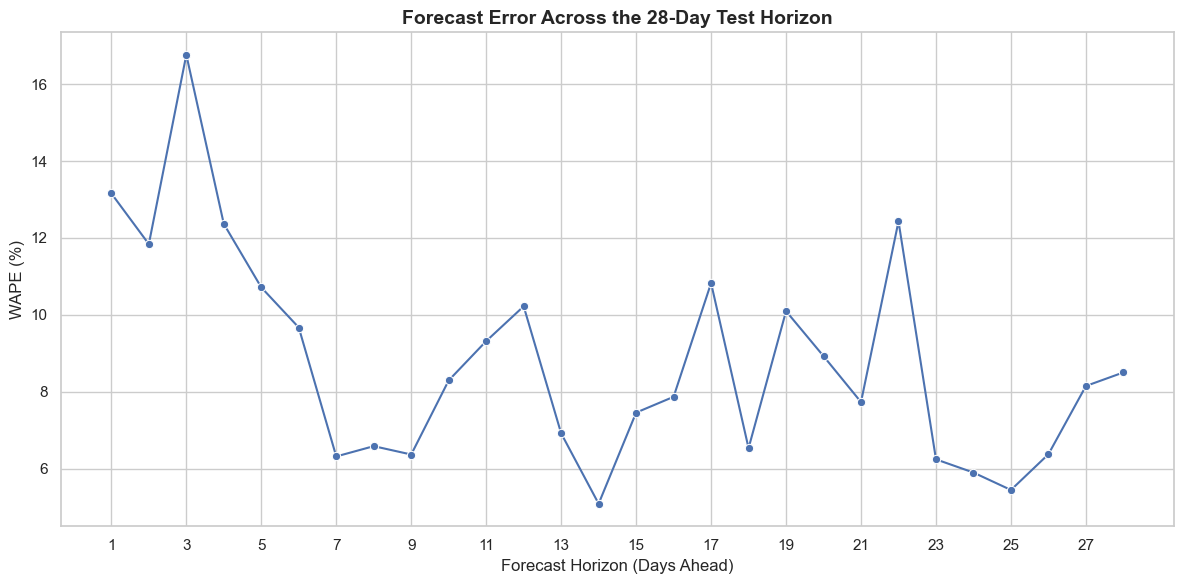

In [98]:

# Step 16.6 — Forecast Error Analysis by Forecast Horizon

# Assign forecast horizon: Day 1 to Day 28
test_start_date = pd.to_datetime(
    test_predictions["date"].min()
)

test_predictions["forecast_day"] = (
    pd.to_datetime(test_predictions["date"])
    - test_start_date
).dt.days + 1

horizon_results = []

for day, group in test_predictions.groupby("forecast_day"):

    actual = group["actual_demand"].to_numpy()
    predicted = group["predicted_demand"].to_numpy()

    mae = np.mean(np.abs(actual - predicted))

    rmse = np.sqrt(np.mean((actual - predicted) ** 2))

    wape = (
        np.sum(np.abs(actual - predicted))
        / np.sum(np.abs(actual))
        * 100
    )

    horizon_results.append({
        "Forecast Day": day,
        "MAE": mae,
        "RMSE": rmse,
        "WAPE (%)": wape
    })

horizon_performance = (
    pd.DataFrame(horizon_results)
    .sort_values("Forecast Day")
    .reset_index(drop=True)
)

print("Forecast Horizon Performance:")
display(horizon_performance.round(3))

# Visualize WAPE across the 28-day horizon
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=horizon_performance,
    x="Forecast Day",
    y="WAPE (%)",
    marker="o"
)

plt.title(
    "Forecast Error Across the 28-Day Test Horizon",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Forecast Horizon (Days Ahead)")
plt.ylabel("WAPE (%)")
plt.xticks(range(1, 29, 2))
plt.tight_layout()
plt.show()


#### 16.6.1 Interpretation — Forecast Error Across the 28-Day Horizon

The forecast-horizon analysis examines how the performance of the final **Tuned XGBoost Regressor** varies across the 28-day reserved test period, from March 28 to April 24, 2016.

The results demonstrate that forecasting errors fluctuate throughout the horizon rather than increasing steadily as predictions extend further into the future.

### 1. Overall Forecast-Horizon Performance

The final model achieved an overall test WAPE of **8.613%**, but individual forecast-day WAPE values ranged from **5.088% to 16.763%**.

The highest relative forecasting error occurred on **Day 3**, while the lowest occurred on **Day 14**.

This variation indicates that forecasting difficulty differs across individual days, even within the same 28-day prediction window.

### 2. Higher Forecasting Errors During the First Week

The first six forecast days recorded relatively high WAPE values:

| Forecast Day | WAPE (%) |
|---|---:|
| Day 1 | 13.158 |
| Day 2 | 11.839 |
| Day 3 | 16.763 |
| Day 4 | 12.365 |
| Day 5 | 10.713 |
| Day 6 | 9.670 |

Day 3 recorded the highest WAPE of **16.763%**, alongside the highest MAE of **180.813 units** and RMSE of **251.049 units**.

However, forecasting accuracy improved substantially on Day 7, when WAPE decreased to **6.317%**.

These findings indicate that the model experienced greater forecasting difficulty during the opening days of the test period.

This is consistent with the earlier actual-versus-predicted visualization, which showed noticeable overprediction during March 28–31.

However, the analysis does not establish whether these higher errors were caused by the forecast horizon itself or by unusual demand conditions on those particular dates.

### 3. Improved Accuracy During the Middle of the Horizon

The second and third weeks generally demonstrated lower forecasting errors, although some fluctuations remained.

Notable results include:

- **Day 8:** 6.585% WAPE
- **Day 9:** 6.367% WAPE
- **Day 14:** 5.088% WAPE
- **Day 15:** 7.457% WAPE
- **Day 18:** 6.533% WAPE
- **Day 21:** 7.731% WAPE

Day 14 achieved the lowest WAPE of **5.088%**, indicating the strongest relative forecasting accuracy during the test period.

However, some days experienced temporary increases in forecasting error, including Day 12 (10.222%), Day 17 (10.826%), and Day 19 (10.096%).

These fluctuations suggest that the model's accuracy varies with individual demand conditions rather than following a smooth pattern across the forecast horizon.

### 4. Forecasting Performance During the Final Week

The final seven days also showed mixed forecasting performance.

| Forecast Day | WAPE (%) |
|---|---:|
| Day 22 | 12.431 |
| Day 23 | 6.242 |
| Day 24 | 5.898 |
| Day 25 | 5.445 |
| Day 26 | 6.375 |
| Day 27 | 8.149 |
| Day 28 | 8.502 |

Although Day 22 recorded a relatively high WAPE of **12.431%**, accuracy improved substantially during Days 23–26.

Day 25 achieved the lowest MAE of **63.586 units**, while Day 28 ended with a WAPE of **8.502%**, slightly below the overall test WAPE of 8.613%.

These results indicate that the model maintained useful forecasting accuracy toward the end of the horizon.

There is no clear evidence of a continuous deterioration in accuracy as the forecast horizon approaches Day 28.

### 5. Relationship to Forecast Bias

The earlier forecast bias analysis identified an overall overprediction tendency:

- Mean signed error: −44.991 units
- Percentage bias: −3.193%
- Overprediction rate: 57.619%

The higher forecasting errors during the first days of the horizon are consistent with the overprediction observed in the actual-versus-predicted daily demand visualization.

However, WAPE measures the magnitude of forecasting errors rather than their direction.

Therefore, the horizon-level WAPE chart alone cannot determine whether individual high-error days were dominated by overprediction or underprediction.

### 6. Business Implications

The results suggest that retail forecasting performance should be monitored across the entire planning horizon rather than evaluated using a single overall metric.

Higher errors during certain days may create inventory-planning challenges, particularly when retailers rely on forecasts for replenishment or stock allocation.

The relatively strong performance during much of the second half of the horizon is encouraging for medium-term retail planning.

However, the unusually high errors observed on Days 3 and 22 indicate that some individual dates may require additional forecast monitoring.

Retail managers could use horizon-level error analysis to identify periods requiring greater operational attention or additional inventory safeguards.

Importantly, because each forecast day corresponds to one specific calendar date in this test period, the observed differences cannot establish a general relationship between forecast lead time and forecasting difficulty.

Additional rolling-origin evaluations would be necessary to determine whether particular lead times consistently produce higher errors.

### Overall Conclusion

The forecast-horizon analysis demonstrates that **Tuned XGBoost does not exhibit a consistent increase in forecasting errors over the 28-day test horizon**.

The highest relative error occurred on **Day 3 (16.763% WAPE)**, while the lowest occurred on **Day 14 (5.088% WAPE)**.

Despite fluctuations, the model maintained relatively strong forecasting accuracy across much of the test period, including several days toward the end of the horizon.

These findings complement the overall test WAPE of **8.613%** and suggest that the model can provide useful demand forecasts across the full four-week planning window.

Nevertheless, the analysis covers only one 28-day test period, and further rolling-origin testing would be required to establish whether the same error patterns persist across different forecasting periods.

### 16.7 Final Forecast Error Analysis Summary

The final forecast error analysis evaluated the performance of the **Tuned XGBoost Regressor** across multiple business and temporal dimensions during the reserved 28-day test period, from March 28 to April 24, 2016.

The model generated **840 forecasts**, covering 30 store-category series over 28 days.

Its overall test performance was:

| Evaluation Metric | Final Test Result |
|---|---:|
| MAE | 121.360 |
| RMSE | 182.666 |
| WAPE | 8.613% |
| R² | 0.976 |

These results demonstrate strong overall predictive accuracy at the store-category aggregation level. However, the detailed error analysis identified important differences in forecasting performance across retail segments and time periods.

#### 1. Product Category Performance

Forecasting accuracy differed across the three product categories.

| Category | WAPE (%) |
|---|---:|
| FOODS | 7.997 |
| HOUSEHOLD | 8.714 |
| HOBBIES | 12.748 |

**FOODS achieved the strongest relative forecasting accuracy**, while HOBBIES recorded the highest relative error.

Although HOBBIES had smaller absolute forecasting errors, its higher WAPE indicates greater prediction error relative to its demand volume.

This suggests that HOBBIES may benefit from further investigation and category-specific forecasting improvements.

#### 2. Store-Level Performance

The model performed relatively well across most of Walmart's 10 stores.

- **Best-performing store:** WI_3, with 7.204% WAPE.
- **Highest-error store:** TX_3, with 11.482% WAPE.
- **Stores with WAPE below 10%:** 8 out of 10.
- **Stores with WAPE above 10%:** TX_2 and TX_3.

These findings indicate that forecasting reliability differs between retail locations.

The relatively high errors at TX_2 and TX_3 suggest that these stores may benefit from closer forecast monitoring and additional investigation into local demand patterns.

#### 3. State-Level Performance

The state-level analysis revealed the following results:

| State | WAPE (%) |
|---|---:|
| California | 7.943 |
| Wisconsin | 8.338 |
| Texas | 10.033 |

California achieved the lowest relative forecasting error, followed by Wisconsin.

Texas recorded the highest WAPE, consistent with the weaker forecasting performance observed at TX_2 and TX_3.

These results suggest that geographic differences in forecasting accuracy should be considered when applying the model to operational retail decisions.

However, the analysis does not establish that location itself causes these differences.

#### 4. Weekday Forecasting Performance

Forecasting accuracy also varied across the seven days of the week.

**Sunday achieved the lowest WAPE of 6.863%**, while **Wednesday recorded the highest WAPE of 10.255%**.

Saturday had the highest absolute forecasting error, with an MAE of 144.148 units, despite achieving a comparatively low WAPE of 8.383%.

This illustrates the importance of considering both absolute and relative errors when evaluating forecasts for days with different demand volumes.

The results suggest that weekday-specific monitoring may help retailers identify periods requiring additional attention.

#### 5. Forecast Bias

The forecast bias analysis identified an overall tendency toward overprediction.

| Bias Metric | Result |
|---|---:|
| Mean Signed Error | −44.991 units |
| Total Signed Error | −37,792.635 units |
| Percentage Bias | −3.193% |
| Overprediction Rate | 57.619% |
| Underprediction Rate | 42.381% |

The negative mean signed error indicates that predicted demand exceeded actual demand by approximately 45 units per store-category observation on average.

The model overpredicted demand more frequently than it underpredicted demand.

From a business perspective, this tendency could contribute to excess inventory, unnecessary storage costs, and inefficient stock allocation if forecasts were used directly for replenishment decisions.

Nevertheless, underpredictions also occurred, indicating that the model is not uniformly biased in every observation.

#### 6. Forecast-Horizon Performance

The horizon-level analysis examined forecasting accuracy separately for each of the 28 test days.

The highest WAPE occurred on **Day 3 (16.763%)**, while the lowest occurred on **Day 14 (5.088%)**.

Forecasting errors were relatively high during the opening days of the test period but generally improved afterward, with occasional increases.

Importantly, the results did not show a consistent deterioration in forecasting accuracy as the horizon progressed toward Day 28.

However, because the analysis covers only one 28-day forecasting period, differences between forecast days may reflect date-specific demand conditions rather than a general relationship between forecast lead time and accuracy.

Additional rolling-origin evaluations would be required to establish whether the same patterns occur across different forecasting periods.

#### 7. Business Implications

The detailed error analysis provides several practical insights for retail demand forecasting.

First, the model's overall WAPE of 8.613% suggests that it can provide useful demand estimates for inventory planning and replenishment decisions.

Second, the differences across categories and stores indicate that a single forecasting model does not necessarily provide uniform accuracy across all retail segments.

Third, the relatively high forecasting errors in HOBBIES, TX_2, and TX_3 identify potential priorities for future model improvement.

Fourth, the model's overprediction tendency suggests that forecast bias should be monitored alongside conventional accuracy metrics to reduce potential inventory inefficiencies.

Finally, the variation in errors across weekdays and forecast dates highlights the importance of evaluating model performance at multiple levels rather than relying exclusively on overall test results.

#### 8. Limitations

Several limitations should be considered when interpreting these findings.

The analysis evaluates demand at the **store-category level**, rather than the individual product level.

The final test covers only one 28-day period, which limits conclusions about forecasting reliability across other seasons or business conditions.

Furthermore, feature-importance results describe associations within the trained model rather than causal relationships.

The reported performance also depends on the availability of the forecasting features at the prediction origin. Any demand-based rolling features that require observations from within the forecast period would need to be reconstructed using only information available before forecasting begins.

Consequently, the reported results should be interpreted as genuine 28-day-ahead forecasting performance only if the feature-availability requirements have been satisfied.

#### Overall Conclusion

The final Tuned XGBoost Regressor achieved strong overall test performance, with **MAE = 121.360**, **RMSE = 182.666**, **WAPE = 8.613%**, and **R² = 0.976**.

The detailed analysis revealed that:

- FOODS was the most accurately forecast product category in relative terms.
- WI_3 and California achieved the lowest store-level and state-level WAPE, respectively.
- HOBBIES, TX_2, and TX_3 experienced comparatively higher forecasting errors.
- Sunday had the lowest weekday WAPE, while Wednesday had the highest.
- The model demonstrated an overall overprediction bias of −3.193%.
- Forecasting errors fluctuated throughout the 28-day horizon without a consistent upward trend.

Overall, these findings indicate that Tuned XGBoost is a promising model for store-category retail demand forecasting.

However, its performance varies across business segments, and further improvements could focus on reducing forecast bias, investigating higher-error categories and locations, and evaluating forecasting reliability across additional time periods.

## Step 17 — Business Insights and Inventory Planning Recommendations

### 17.1 Inventory Planning Priorities by Product Category

Following the comprehensive forecast error analysis, this section translates the results of the final **Tuned XGBoost Regressor** into actionable insights for retail inventory planning.

The model achieved a final test **MAE of 121.360**, **RMSE of 182.666**, **WAPE of 8.613%**, and **R² of 0.976**, demonstrating strong overall forecasting performance at the store-category level.

However, the detailed analysis revealed differences in forecasting accuracy across product categories, stores, and geographic regions. In particular, FOODS achieved the lowest category-level WAPE (**7.997%**), while HOBBIES recorded the highest (**12.748%**).

The objective of this section is to identify inventory planning priorities by combining demand volume, predicted demand, and forecasting uncertainty.

For each product category, the analysis will calculate:

- **Total Actual Demand:** Total units demanded during the 28-day test period.
- **Total Predicted Demand:** Total units forecast by Tuned XGBoost.
- **Average Daily Demand:** Average daily demand across all 10 stores.
- **Demand Share (%):** Each category's contribution to overall retail demand.
- **WAPE (%):** Relative forecasting error within each category.
- **Forecast Bias (%):** Net underprediction or overprediction relative to actual demand.

Positive forecast bias indicates that actual demand exceeded predicted demand, while negative bias indicates that predicted demand exceeded actual demand.

The analysis will identify categories requiring reliable high-volume replenishment and categories where greater forecasting uncertainty may justify closer monitoring.

These findings will support inventory planning recommendations rather than calculate optimal stock quantities, which would require additional operational information such as supplier lead times, current inventory levels, service-level targets, and stockout costs.

Inventory Planning Summary by Product Category:


,category,actual_demand,predicted_demand,avg_daily_demand,demand_share_pct,wape_pct,bias_pct
0,FOODS,790932,826400.750000,28247.571,66.823,7.997,-4.484
1,HOUSEHOLD,281920,287181.375000,10068.571,23.818,8.714,-1.866
2,HOBBIES,110774,107836.492188,3956.214,9.359,12.748,2.652


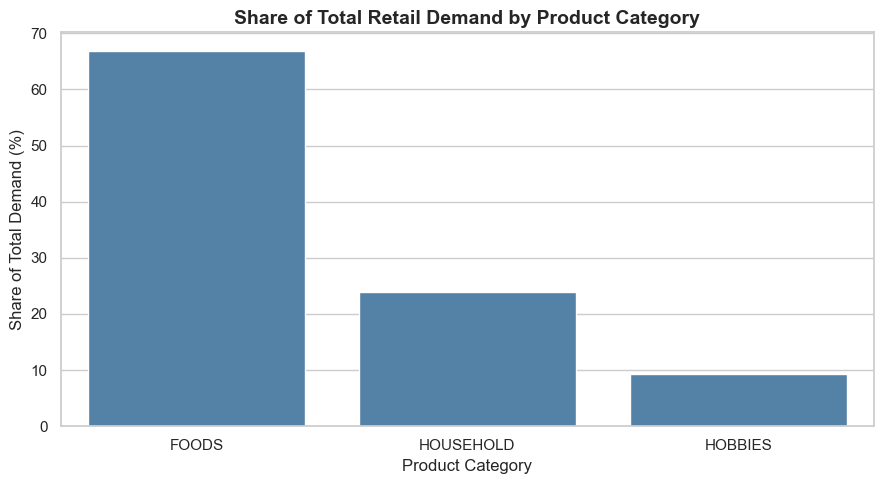

In [99]:

# Step 17.1 — Inventory Planning Priorities by Product Category

# Aggregate test demand and predictions by category
inventory_summary = (
    test_predictions
    .groupby("category", as_index=False)
    .agg(
        actual_demand=("actual_demand", "sum"),
        predicted_demand=("predicted_demand", "sum"),
        observations=("actual_demand", "size")
    )
)

# Calculate absolute errors at the original
# store-category-day observation level
absolute_errors = (
    test_predictions
    .assign(
        absolute_error=lambda x: (
            x["actual_demand"] - x["predicted_demand"]
        ).abs()
    )
    .groupby("category")["absolute_error"]
    .sum()
    .rename("total_absolute_error")
)

inventory_summary = inventory_summary.merge(
    absolute_errors,
    on="category",
    how="left"
)

# Average daily demand across all 10 stores
inventory_summary["avg_daily_demand"] = (
    inventory_summary["actual_demand"] / 28
)

# Share of total actual demand
inventory_summary["demand_share_pct"] = (
    inventory_summary["actual_demand"]
    / inventory_summary["actual_demand"].sum()
    * 100
)

# Category WAPE
inventory_summary["wape_pct"] = (
    inventory_summary["total_absolute_error"]
    / inventory_summary["actual_demand"]
    * 100
)

# Signed bias: positive means net underprediction
inventory_summary["bias_pct"] = (
    (
        inventory_summary["actual_demand"]
        - inventory_summary["predicted_demand"]
    )
    / inventory_summary["actual_demand"]
    * 100
)

# Sort by demand contribution
inventory_summary = (
    inventory_summary
    .sort_values("actual_demand", ascending=False)
    .reset_index(drop=True)
)

print("Inventory Planning Summary by Product Category:")

display(
    inventory_summary[
        [
            "category",
            "actual_demand",
            "predicted_demand",
            "avg_daily_demand",
            "demand_share_pct",
            "wape_pct",
            "bias_pct"
        ]
    ].round(3)
)

# Visualize demand share by category
plt.figure(figsize=(9, 5))

sns.barplot(
    data=inventory_summary,
    x="category",
    y="demand_share_pct",
    color="steelblue"
)

plt.title(
    "Share of Total Retail Demand by Product Category",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Product Category")
plt.ylabel("Share of Total Demand (%)")
plt.tight_layout()
plt.show()


#### 17.1.1 Interpretation — Inventory Planning Priorities by Product Category

The inventory planning analysis examines how actual demand, predicted demand, demand contribution, and forecasting errors differ across Walmart's three product categories during the final 28-day test period.

The results demonstrate that **FOODS dominates overall retail demand**, while HOUSEHOLD and HOBBIES present different inventory planning requirements.

### 1. Category-Level Inventory Planning Summary

| Metric | FOODS | HOUSEHOLD | HOBBIES |
|---|---:|---:|---:|
| Actual Demand (units) | 790,932 | 281,920 | 110,774 |
| Predicted Demand (units) | 826,400.75 | 287,181.38 | 107,836.49 |
| Average Daily Demand (units) | 28,247.57 | 10,068.57 | 3,956.21 |
| Demand Share (%) | 66.823 | 23.818 | 9.359 |
| WAPE (%) | 7.997 | 8.714 | 12.748 |
| Forecast Bias (%) | −4.484 | −1.866 | +2.652 |

The results highlight substantial differences in demand volume and forecasting behavior across the three categories.

### 2. FOODS — Highest Inventory Planning Priority

FOODS accounted for **790,932 units**, representing **66.823% of total retail demand** during the test period.

Its average daily demand across all 10 stores was approximately **28,248 units**, making it the largest category by a considerable margin.

FOODS also achieved the lowest WAPE of **7.997%**, indicating the strongest relative forecasting accuracy.

However, the model predicted approximately **826,401 units**, exceeding actual demand by approximately **35,469 units**.

This resulted in a negative forecast bias of **−4.484%**, indicating overprediction.

**Business implications:**

FOODS should receive the highest inventory planning priority because it represents approximately two-thirds of total demand.

Reliable demand forecasts are particularly important for maintaining product availability and avoiding stockouts.

However, the observed overprediction suggests that using forecasts directly as inventory order quantities could contribute to excess stock.

For food products, this may be especially important because some items are perishable and excess inventory can increase spoilage and waste.

**Recommended approach:** Prioritize accurate replenishment planning for FOODS while monitoring forecast bias and avoiding automatic conversion of predicted demand into purchase quantities.

### 3. HOUSEHOLD — Stable Demand with Moderate Forecast Bias

HOUSEHOLD recorded **281,920 units** of actual demand, accounting for **23.818% of total retail demand**.

Its average daily demand was approximately **10,069 units** across all stores.

The category achieved a WAPE of **8.714%**, indicating relatively strong forecasting accuracy.

Predicted demand reached approximately **287,181 units**, exceeding actual demand by approximately **5,261 units**.

This produced a forecast bias of **−1.866%**, indicating a smaller overprediction tendency than FOODS.

**Business implications:**

HOUSEHOLD represents a substantial share of retail demand and requires consistent inventory availability.

Its relatively low WAPE and modest negative bias suggest that Tuned XGBoost provides useful estimates for replenishment planning.

Nevertheless, inventory decisions should still consider forecast uncertainty and product-specific stock requirements.

**Recommended approach:** Use the forecasts to support routine inventory planning while monitoring overprediction and adjusting stock levels according to actual sales performance.

### 4. HOBBIES — Highest Relative Forecasting Uncertainty

HOBBIES recorded **110,774 units** of actual demand, representing **9.359% of total retail demand**.

Its average daily demand was approximately **3,956 units** across all stores.

Although HOBBIES contributed the smallest share of demand, it recorded the highest WAPE of **12.748%**.

Predicted demand was approximately **107,836 units**, which was **2,938 units below actual demand**.

This resulted in a positive forecast bias of **+2.652%**, indicating underprediction.

**Business implications:**

HOBBIES presents a different inventory planning challenge from FOODS and HOUSEHOLD.

Its higher relative forecasting error suggests greater uncertainty in demand estimates.

Furthermore, its positive forecast bias indicates that actual demand exceeded predicted demand during the test period.

If inventory decisions relied exclusively on these predictions, underforecasting could contribute to insufficient stock and missed sales opportunities.

However, the results do not establish that stockouts actually occurred.

**Recommended approach:** Prioritize forecast monitoring for HOBBIES, investigate sources of forecasting error, and evaluate whether category-specific forecasting improvements could reduce underprediction.

### 5. Comparison of Forecast Bias Across Categories

The three categories demonstrate different forecasting tendencies:

| Category | Forecast Bias (%) | Direction |
|---|---:|---|
| FOODS | −4.484 | Overprediction |
| HOUSEHOLD | −1.866 | Overprediction |
| HOBBIES | +2.652 | Underprediction |

The results indicate that the overall negative forecast bias identified in Step 16.5 is not uniform across all product categories.

FOODS contributes the largest net overprediction in absolute units, while HOUSEHOLD also shows a smaller overprediction tendency.

HOBBIES exhibits the opposite pattern, with actual demand exceeding predicted demand.

These differences suggest that category-level bias monitoring may be more informative than applying a single forecasting adjustment across the entire retail business.

### 6. Inventory Planning Recommendations

Based on the results, the following priorities are recommended:

| Category | Planning Priority | Recommended Focus |
|---|---|---|
| FOODS | High | High-volume replenishment and overprediction monitoring |
| HOUSEHOLD | Moderate to high | Consistent replenishment and forecast monitoring |
| HOBBIES | Targeted improvement | Reducing relative forecast error and underprediction |

These priorities reflect the observed demand volumes and forecasting performance rather than an optimized inventory policy.

Actual inventory decisions would require additional information about current stock, supplier lead times, storage costs, service-level targets, and stockout penalties.

### 7. Relationship to Overall Model Performance

The final Tuned XGBoost model achieved an overall WAPE of **8.613%** and a percentage bias of **−3.193%**.

The category-level analysis provides a more detailed explanation of these results.

FOODS and HOUSEHOLD both contributed to the overall overprediction tendency, while HOBBIES partially offset it through underprediction.

Furthermore, because FOODS represents approximately two-thirds of total demand, its forecasting performance has a substantial influence on aggregate demand planning.

This demonstrates why overall forecasting metrics should be complemented by category-level analysis before translating predictions into business recommendations.

### Overall Conclusion

The inventory planning analysis identifies **FOODS as the highest-priority category because it accounts for 66.823% of total demand**.

Its relatively low WAPE of **7.997%** supports the usefulness of the forecasts, although its **−4.484% bias** highlights the need to monitor overprediction.

HOUSEHOLD demonstrates relatively balanced forecasting performance, with **23.818% demand share**, **8.714% WAPE**, and **−1.866% bias**.

HOBBIES represents the smallest demand share (**9.359%**) but presents the greatest relative forecasting challenge, with **12.748% WAPE** and **+2.652% bias**.

Overall, the results suggest that retail inventory planning should combine demand volume, forecasting accuracy, and forecast bias rather than relying on predicted demand alone.

This category-specific approach can help retailers prioritize replenishment decisions, identify forecasting risks, and target future model improvements more effectively.

### 17.2 Inventory Planning Priorities by Walmart Store

Following the category-level inventory planning analysis, this section evaluates inventory priorities across Walmart's **10 stores** using predictions generated by the final **Tuned XGBoost Regressor**.

The analysis covers the reserved 28-day test period, from March 28 to April 24, 2016.

The objective is to identify stores with substantial demand volumes, higher forecasting uncertainty, or systematic overprediction and underprediction.

For each store, the analysis will calculate:

- **Actual Demand:** Total units demanded during the test period.
- **Predicted Demand:** Total units forecast by Tuned XGBoost.
- **Average Daily Demand:** Average daily demand across the store's three product categories.
- **Demand Share (%):** Each store's contribution to total retail demand.
- **WAPE (%):** Total absolute forecasting error relative to observed demand.
- **Forecast Bias (%):** Net underprediction or overprediction relative to actual demand.

Forecast bias will be calculated as:

**Forecast Bias (%) = (Actual Demand − Predicted Demand) / Actual Demand × 100**

Under this convention:

- **Positive bias** indicates net underprediction.
- **Negative bias** indicates net overprediction.

The analysis will combine demand contribution, relative forecasting error, and directional bias to identify stores requiring closer inventory monitoring.

Particular attention will be given to stores with both substantial demand volumes and relatively high forecasting errors.

The findings will support store-specific inventory planning recommendations, rather than calculate optimal inventory quantities. Actual replenishment decisions would require additional information such as current stock levels, supplier lead times, service-level targets, and inventory holding costs.

In [100]:
# Step 17.2 — Store-Level Inventory Planning

# Create a copy of the final test predictions
store_data = test_predictions.copy()

# Calculate absolute forecasting errors
store_data["absolute_error"] = (
    store_data["actual_demand"] -
    store_data["predicted_demand"]
).abs()

# Aggregate demand and errors by store
store_inventory_summary = (
    store_data.groupby("store_id", as_index=False)
    .agg(
        actual_demand=("actual_demand", "sum"),
        predicted_demand=("predicted_demand", "sum"),
        total_absolute_error=("absolute_error", "sum")
    )
)

# Average daily demand (28-day test period)
store_inventory_summary["avg_daily_demand"] = (
    store_inventory_summary["actual_demand"] / 28
)

# Share of total demand
store_inventory_summary["demand_share_pct"] = (
    store_inventory_summary["actual_demand"] /
    store_inventory_summary["actual_demand"].sum() * 100
)

# Weighted Absolute Percentage Error
store_inventory_summary["wape_pct"] = (
    store_inventory_summary["total_absolute_error"] /
    store_inventory_summary["actual_demand"] * 100
)

# Forecast bias: positive means net underprediction
store_inventory_summary["bias_pct"] = (
    (
        store_inventory_summary["actual_demand"] -
        store_inventory_summary["predicted_demand"]
    ) /
    store_inventory_summary["actual_demand"] * 100
)

# Sort stores by demand volume
store_inventory_summary = (
    store_inventory_summary
    .sort_values("actual_demand", ascending=False)
    .reset_index(drop=True)
)

# Display the summary
display(
    store_inventory_summary[
        [
            "store_id",
            "actual_demand",
            "predicted_demand",
            "avg_daily_demand",
            "demand_share_pct",
            "wape_pct",
            "bias_pct"
        ]
    ].round(3)
)

,store_id,actual_demand,predicted_demand,avg_daily_demand,demand_share_pct,wape_pct,bias_pct
0,CA_3,176972,187415.437500,6320.429,14.952,7.690,-5.901
1,WI_2,151060,149196.703125,5395.000,12.762,8.495,1.233
2,CA_1,127955,134854.203125,4569.821,10.810,8.031,-5.392
3,CA_2,125031,119664.992188,4465.393,10.563,8.457,4.292
4,WI_3,111810,113734.046875,3993.214,9.446,7.204,-1.721
5,TX_2,110106,119786.093750,3932.357,9.302,10.835,-8.792
6,WI_1,107281,111663.109375,3831.464,9.064,9.300,-4.085
7,TX_3,106422,115592.929688,3800.786,8.991,11.482,-8.618
8,TX_1,92776,95152.703125,3313.429,7.838,7.420,-2.562
9,CA_4,74213,74358.429688,2650.464,6.270,7.527,-0.196


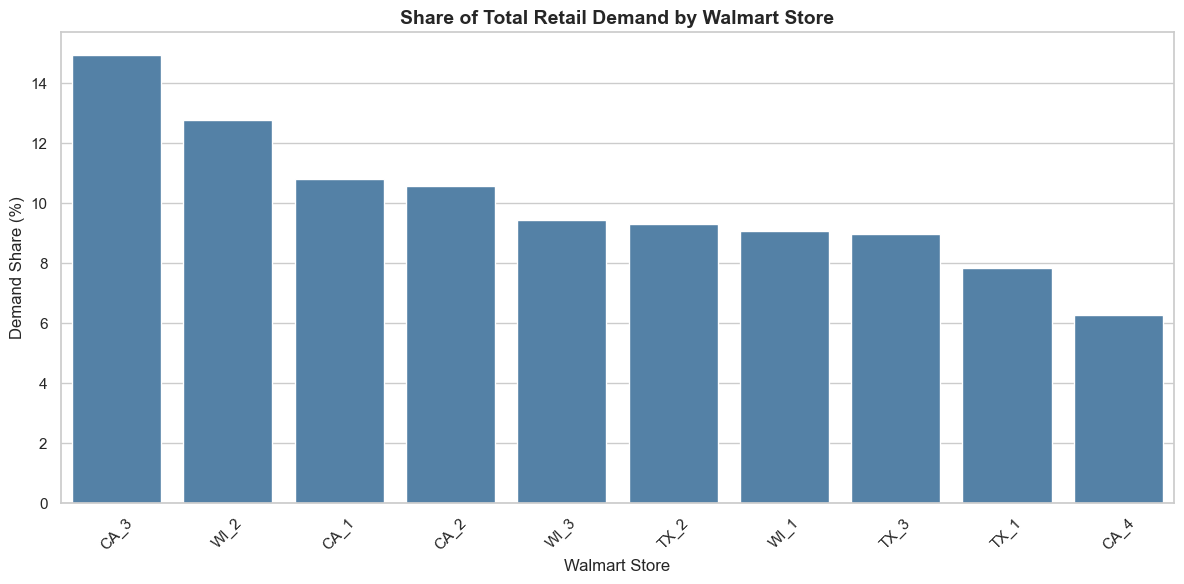

In [101]:
# Visualize each store's share of total demand

plt.figure(figsize=(12, 6))

sns.barplot(
    data=store_inventory_summary,
    x="store_id",
    y="demand_share_pct",
    color="steelblue"
)

plt.title(
    "Share of Total Retail Demand by Walmart Store",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Walmart Store")
plt.ylabel("Demand Share (%)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

#### 17.2.1 Interpretation — Inventory Planning Priorities by Walmart Store

The store-level inventory planning analysis evaluates actual demand, predicted demand, demand contribution, forecasting accuracy, and forecast bias across Walmart's 10 stores during the reserved 28-day test period.

The objective is to identify stores that require greater inventory planning attention based on their operational importance and forecasting uncertainty.

### 1. Store-Level Inventory Planning Summary

| Store | Demand Share (%) | WAPE (%) | Forecast Bias (%) |
|---|---:|---:|---:|
| CA_3 | 14.952 | 7.690 | −5.901 |
| WI_2 | 12.762 | 8.495 | +1.233 |
| CA_1 | 10.810 | 8.031 | −5.392 |
| CA_2 | 10.563 | 8.457 | +4.292 |
| WI_3 | 9.446 | 7.204 | −1.721 |
| TX_2 | 9.302 | 10.835 | −8.792 |
| WI_1 | 9.064 | 9.300 | −4.085 |
| TX_3 | 8.991 | 11.482 | −8.618 |
| TX_1 | 7.838 | 7.420 | −2.562 |
| CA_4 | 6.270 | 7.527 | −0.196 |

Negative forecast bias indicates overprediction, while positive bias indicates underprediction.

### 2. CA_3 — Highest Demand Volume and Significant Overprediction

CA_3 recorded the highest actual demand of **176,972 units**, representing **14.952% of total retail demand**.

Its average daily demand was approximately **6,320 units**, making it the most operationally significant store by sales volume during the test period.

The model predicted **187,415 units**, exceeding actual demand by approximately **10,443 units**.

Although CA_3 achieved a relatively low WAPE of **7.690%**, its forecast bias of **−5.901%** indicates substantial net overprediction.

**Business implication:** CA_3 should receive high inventory planning priority because even relatively small percentage forecasting errors can translate into substantial inventory quantities at a high-volume store.

**Recommendation:** Maintain reliable replenishment planning while monitoring the model's tendency to overestimate demand.

### 3. WI_2 — High Demand Volume with Slight Underprediction

WI_2 recorded **151,060 units** of actual demand, accounting for **12.762% of total demand**.

It was the second-largest store by demand volume.

The model predicted approximately **149,197 units**, resulting in a positive forecast bias of **+1.233%**.

Its WAPE was **8.495%**, indicating relatively strong forecasting accuracy.

Unlike CA_3, WI_2 experienced net underprediction, meaning actual demand slightly exceeded predicted demand.

**Business implication:** WI_2 requires consistent replenishment because of its substantial demand contribution.

**Recommendation:** Monitor underprediction and assess whether forecast uncertainty could affect product availability during higher-demand periods.

### 4. TX_2 and TX_3 — Highest Forecasting Risk

TX_2 and TX_3 recorded the highest relative forecasting errors among the 10 stores.

| Store | Actual Demand | WAPE (%) | Forecast Bias (%) |
|---|---:|---:|---:|
| TX_2 | 110,106 | 10.835 | −8.792 |
| TX_3 | 106,422 | 11.482 | −8.618 |

TX_2 recorded approximately **9,680 units** of net overprediction, while TX_3 recorded approximately **9,171 units**.

Both stores experienced substantial negative forecast bias alongside relatively high WAPE.

This combination indicates that their forecasts are less accurate in relative terms and tend to exceed actual demand.

**Business implication:** If forecasts are used directly to determine replenishment quantities, these stores may face increased risk of excess inventory and inefficient stock allocation.

**Recommendation:** Prioritize TX_2 and TX_3 for forecast monitoring, investigation of store-specific demand patterns, and potential model improvements.

### 5. CA_1 and CA_2 — Similar Demand Shares, Different Bias Directions

CA_1 and CA_2 contributed similar proportions of total demand:

- CA_1: **10.810%**
- CA_2: **10.563%**

Their forecasting accuracy was also relatively similar, with WAPE values of **8.031%** and **8.457%**, respectively.

However, their forecast biases differed substantially.

CA_1 recorded a bias of **−5.392%**, indicating overprediction.

CA_2 recorded a bias of **+4.292%**, indicating underprediction.

This contrast demonstrates that stores with similar demand volumes and forecasting accuracy can still face different inventory risks.

**Business implication:** CA_1 may be more exposed to excess inventory if forecasts are used directly, while CA_2 may be more exposed to insufficient inventory.

**Recommendation:** Evaluate forecast bias separately for each store rather than applying the same inventory adjustment across all California locations.

### 6. Stores with Relatively Balanced Forecasting Performance

WI_3, TX_1, and CA_4 achieved relatively low forecasting errors.

WI_3 recorded the lowest WAPE of **7.204%**, with a modest negative bias of **−1.721%**.

TX_1 achieved a WAPE of **7.420%**, although its bias of **−2.562%** indicates some overprediction.

CA_4 recorded a WAPE of **7.527%** and the smallest absolute percentage bias of **−0.196%**, indicating particularly balanced aggregate predictions during the test period.

These results suggest that the model provides comparatively reliable demand estimates for these stores.

However, low aggregate bias does not necessarily mean that individual daily predictions are consistently accurate, because overpredictions and underpredictions can offset one another.

### 7. Inventory Planning Priorities

Based on demand contribution, forecasting accuracy, and forecast bias, the following inventory planning priorities are recommended:

| Priority | Stores | Recommended Focus |
|---|---|---|
| High-volume replenishment | CA_3, WI_2 | Maintain product availability and monitor forecast bias |
| Forecast improvement priority | TX_2, TX_3 | Investigate high WAPE and substantial overprediction |
| Bias monitoring | CA_1, CA_2 | Address contrasting overprediction and underprediction patterns |
| Routine monitoring | WI_3, WI_1, TX_1, CA_4 | Maintain forecast accuracy and monitor changes |

These recommendations are based on observed forecasting results rather than a formal inventory optimization model.

Determining optimal replenishment quantities would require additional information about stock levels, supplier lead times, inventory costs, and service-level requirements.

### 8. Relationship to Overall Forecast Bias

The final Tuned XGBoost model recorded an overall forecast bias of **−3.193%**, indicating net overprediction.

The store-level results reveal that this overall tendency is not uniform.

Eight stores experienced negative forecast bias, while WI_2 and CA_2 experienced positive bias.

The substantial overprediction at CA_3, TX_2, and TX_3 contributed to the model's overall negative bias.

These findings suggest that store-specific bias monitoring may be more useful than applying a single correction across all retail locations.

### Overall Conclusion

The store-level inventory planning analysis demonstrates that demand volume, forecasting accuracy, and forecast bias must be considered together when developing operational recommendations.

**CA_3 is the highest-volume store**, accounting for **14.952% of total retail demand**, but it also exhibits substantial overprediction.

**TX_2 and TX_3 present the greatest forecasting concerns**, with WAPE values above 10% and negative bias exceeding 8% in magnitude.

Meanwhile, **CA_4 demonstrates the most balanced aggregate forecasts**, with a bias of only −0.196%.

Overall, the results support a store-specific inventory planning approach that prioritizes high-volume replenishment, monitors directional forecasting errors, and targets model improvements where relative errors are highest.

### 17.3 Store-Category Inventory Risk Analysis

Following the category-level and store-level inventory planning analyses, this section examines forecasting performance across **30 store-category combinations** (10 Walmart stores × 3 product categories) using predictions generated by the final **Tuned XGBoost Regressor**.

The objective is to identify combinations with substantial demand volumes, high relative forecasting errors, or meaningful forecast bias that may require closer inventory monitoring.

For each store-category combination, the analysis will calculate:

- **Actual Demand:** Total observed demand during the reserved 28-day test period.
- **Predicted Demand:** Total demand forecast by the model.
- **Demand Share (%):** Contribution to overall retail demand across all 30 combinations.
- **Total Absolute Forecast Error:** Sum of absolute prediction errors across the 28 days.
- **WAPE (%):** Total absolute forecasting error relative to observed demand.
- **Forecast Bias (%):** Net underprediction or overprediction relative to actual demand.

Positive forecast bias indicates underprediction, while negative bias indicates overprediction.

The combinations will be ranked by their **total absolute forecasting error** to identify where forecasting deviations involve the largest cumulative numbers of units.

The analysis will also compare relative forecasting errors to distinguish high-volume combinations from those experiencing greater proportional forecasting uncertainty.

These findings will support targeted inventory monitoring and forecast improvement recommendations.

Forecasting errors are treated as indicators of potential inventory planning risk, not as direct evidence of actual stockouts, excess inventory, or financial losses.

In [102]:
# Step 17.3 — Store-Category Inventory Risk Analysis

# Use final test predictions
risk_data = test_predictions.copy()

# Calculate absolute errors
risk_data["absolute_error"] = (
    risk_data["actual_demand"]
    - risk_data["predicted_demand"]
).abs()

# Aggregate by store and category
store_category_risk = (
    risk_data
    .groupby(["store_id", "category"], as_index=False)
    .agg(
        actual_demand=("actual_demand", "sum"),
        predicted_demand=("predicted_demand", "sum"),
        total_absolute_error=("absolute_error", "sum")
    )
)

# Demand share across all 30 combinations
store_category_risk["demand_share_pct"] = (
    store_category_risk["actual_demand"]
    / store_category_risk["actual_demand"].sum()
    * 100
)

# Forecasting error
store_category_risk["wape_pct"] = (
    store_category_risk["total_absolute_error"]
    / store_category_risk["actual_demand"]
    * 100
)

# Signed forecast bias
store_category_risk["bias_pct"] = (
    (
        store_category_risk["actual_demand"]
        - store_category_risk["predicted_demand"]
    )
    / store_category_risk["actual_demand"]
    * 100
)

# Sort by total absolute forecasting error
# This prioritizes combinations with the largest
# cumulative unit-level forecasting deviations.
store_category_risk = (
    store_category_risk
    .sort_values("total_absolute_error", ascending=False)
    .reset_index(drop=True)
)

print("Top 10 Store-Category Combinations by Absolute Forecast Error")

display(
    store_category_risk[
        [
            "store_id",
            "category",
            "actual_demand",
            "demand_share_pct",
            "total_absolute_error",
            "wape_pct",
            "bias_pct"
        ]
    ].head(10).round(3)
)

Top 10 Store-Category Combinations by Absolute Forecast Error


,store_id,category,actual_demand,demand_share_pct,total_absolute_error,wape_pct,bias_pct
0,CA_3,FOODS,111045,9.382,8881.073,7.998,-7.197
1,TX_2,FOODS,71846,6.070,8531.254,11.874,-11.659
2,WI_2,FOODS,111300,9.403,7842.753,7.046,2.095
3,TX_3,FOODS,68649,5.800,7643.398,11.134,-10.231
4,WI_1,FOODS,73853,6.240,6658.860,9.016,-6.676
5,CA_1,FOODS,84668,7.153,6348.394,7.498,-7.142
6,CA_2,FOODS,81730,6.905,6105.407,7.470,1.910
7,WI_3,FOODS,80756,6.823,4865.620,6.025,-3.872
8,WI_2,HOUSEHOLD,31625,2.672,3981.996,12.591,-3.532
9,TX_1,FOODS,58734,4.962,3772.749,6.423,-1.487


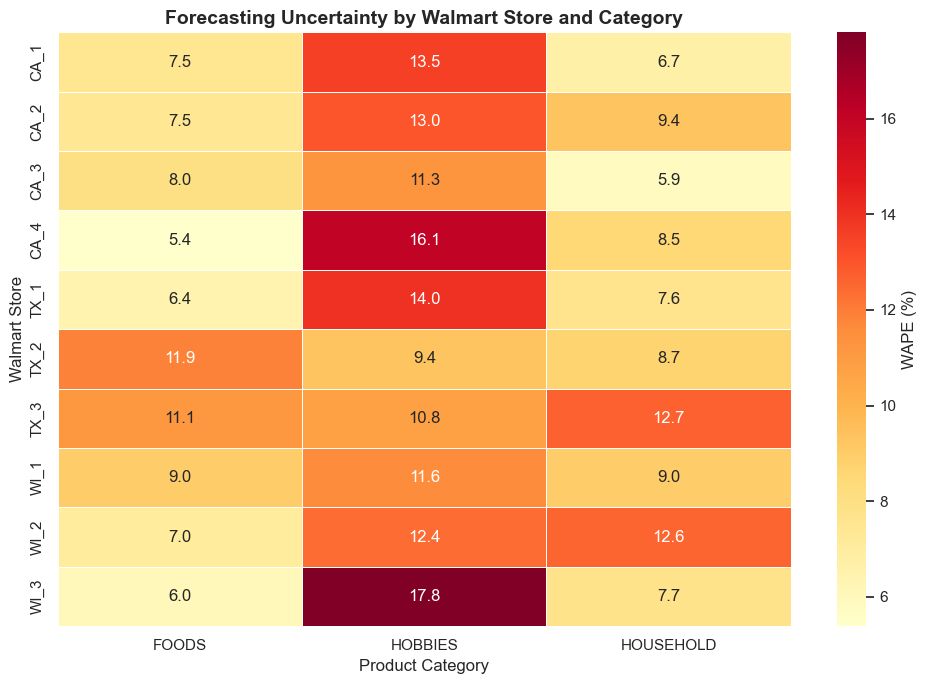

In [103]:
# 17.3.1 Create a WAPE matrix
risk_heatmap = store_category_risk.pivot(
    index="store_id",
    columns="category",
    values="wape_pct"
)

# Visualize relative forecasting uncertainty
plt.figure(figsize=(10, 7))

sns.heatmap(
    risk_heatmap,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    linewidths=0.5,
    cbar_kws={"label": "WAPE (%)"}
)

plt.title(
    "Forecasting Uncertainty by Walmart Store and Category",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Product Category")
plt.ylabel("Walmart Store")

plt.tight_layout()
plt.show()

#### 17.3.2 Interpretation — Store-Category Inventory Risk Analysis

The store-category inventory risk analysis evaluates the final **Tuned XGBoost Regressor** across all 30 Walmart store-category combinations during the reserved 28-day test period.

The analysis combines total demand, cumulative absolute forecasting errors, WAPE, and forecast bias to identify combinations requiring closer inventory monitoring.

The results reveal that high-volume combinations contribute the largest absolute forecasting errors, while lower-volume categories may experience greater relative forecasting uncertainty.

### 1. Store-Category Combinations with the Largest Forecasting Errors

The ten combinations with the highest cumulative absolute forecasting errors are:

| Store | Category | Total Absolute Error | WAPE (%) | Bias (%) |
|---|---|---:|---:|---:|
| CA_3 | FOODS | 8,881.073 | 7.998 | −7.197 |
| TX_2 | FOODS | 8,531.254 | 11.874 | −11.659 |
| WI_2 | FOODS | 7,842.753 | 7.046 | +2.095 |
| TX_3 | FOODS | 7,643.398 | 11.134 | −10.231 |
| WI_1 | FOODS | 6,658.860 | 9.016 | −6.676 |
| CA_1 | FOODS | 6,348.394 | 7.498 | −7.142 |
| CA_2 | FOODS | 6,105.407 | 7.470 | +1.910 |
| WI_3 | FOODS | 4,865.620 | 6.025 | −3.872 |
| WI_2 | HOUSEHOLD | 3,981.996 | 12.591 | −3.532 |
| TX_1 | FOODS | 3,772.749 | 6.423 | −1.487 |

Nine of the ten combinations belong to FOODS, demonstrating the substantial contribution of high-volume food demand to cumulative forecasting errors.

However, a large total absolute error does not necessarily indicate poor relative forecasting accuracy.

### 2. CA_3–FOODS — Largest Absolute Forecasting Error

CA_3–FOODS recorded the highest cumulative absolute forecasting error of **8,881.073 units**.

It also represented **9.382% of total retail demand**, with actual demand of **111,045 units**.

Despite its relatively low WAPE of **7.998%**, the combination exhibited a forecast bias of **−7.197%**, indicating net overprediction.

This demonstrates how forecasting errors in a high-volume combination can translate into substantial unit-level deviations.

**Business implication:** CA_3–FOODS should receive high inventory planning priority because of its large demand contribution and overprediction tendency.

### 3. TX_2–FOODS and TX_3–FOODS — High Errors and Substantial Overprediction

Two Texas FOODS combinations stand out because they combine relatively high forecasting errors with substantial negative bias.

| Combination | WAPE (%) | Bias (%) |
|---|---:|---:|
| TX_2–FOODS | 11.874 | −11.659 |
| TX_3–FOODS | 11.134 | −10.231 |

TX_2–FOODS recorded **8,531.254 units** of cumulative absolute forecasting error, while TX_3–FOODS recorded **7,643.398 units**.

Both combinations have WAPE above 11% and forecast bias below −10%.

This indicates that their forecasts are relatively less accurate and substantially overestimate total demand.

**Business implication:** These combinations warrant closer attention because forecast-driven replenishment could lead to excess inventory if the overprediction tendency persists.

**Recommendation:** Prioritize investigation of TX_2–FOODS and TX_3–FOODS before applying any forecast-based inventory adjustments.

### 4. WI_2–FOODS — High Demand with Underprediction

WI_2–FOODS recorded actual demand of **111,300 units**, the highest among the combinations shown in the top-ten table.

Its cumulative absolute forecasting error was **7,842.753 units**, with a WAPE of **7.046%**.

Unlike the Texas combinations, WI_2–FOODS exhibited a positive forecast bias of **+2.095%**, indicating net underprediction.

This demonstrates that high-volume combinations can face different inventory planning risks even when forecasting accuracy is relatively strong.

**Business implication:** WI_2–FOODS may require closer monitoring of product availability because actual demand exceeded predicted demand during the test period.

### 5. HOBBIES — Highest Relative Forecasting Uncertainty

The heatmap reveals that HOBBIES generally experiences the highest WAPE across store-category combinations.

The highest relative forecasting errors include:

| Combination | WAPE (%) |
|---|---:|
| WI_3–HOBBIES | 17.8 |
| CA_4–HOBBIES | 16.1 |
| TX_1–HOBBIES | 14.0 |
| CA_1–HOBBIES | 13.5 |
| CA_2–HOBBIES | 13.0 |

These heatmap values are rounded to one decimal place.

WI_3–HOBBIES recorded the highest WAPE, at approximately **17.8%**, followed by CA_4–HOBBIES at approximately **16.1%**.

Although these combinations do not appear among the top ten by cumulative absolute error, their higher relative forecasting errors indicate greater uncertainty compared with their demand volumes.

**Business implication:** HOBBIES may require targeted forecasting improvements, particularly at WI_3 and CA_4.

However, the heatmap alone does not establish whether these combinations systematically overpredict or underpredict demand.

### 6. FOODS — High Operational Importance Despite Lower Relative Errors

The heatmap shows that most FOODS combinations have WAPE below 10%.

Notable exceptions include:

- TX_2–FOODS: approximately 11.9%.
- TX_3–FOODS: approximately 11.1%.

Several other FOODS combinations achieve considerably lower WAPE, including CA_4–FOODS at approximately 5.4% and WI_3–FOODS at approximately 6.0%.

Nevertheless, FOODS dominates the cumulative absolute error ranking because of its substantial demand volume.

This reinforces the distinction between **forecasting accuracy in percentage terms** and **operational exposure measured in units**.

### 7. HOUSEHOLD — Selected Combinations Require Attention

HOUSEHOLD generally exhibits moderate forecasting errors, but some combinations show higher WAPE.

The heatmap identifies:

- TX_3–HOUSEHOLD: approximately 12.7%.
- WI_2–HOUSEHOLD: approximately 12.6%.
- CA_2–HOUSEHOLD: approximately 9.4%.

WI_2–HOUSEHOLD also appears among the ten combinations with the largest cumulative absolute forecasting errors.

These results suggest that selected HOUSEHOLD combinations may benefit from closer monitoring, even though the category's overall WAPE was relatively low at **8.714%**.

### 8. Inventory Planning Recommendations

The findings support a differentiated inventory monitoring strategy.

| Priority Area | Store-Category Combinations | Recommended Focus |
|---|---|---|
| High-volume inventory planning | CA_3–FOODS, WI_2–FOODS | Monitor large unit-level forecasting errors |
| High relative error and overprediction | TX_2–FOODS, TX_3–FOODS | Investigate systematic overforecasting |
| High relative forecasting uncertainty | WI_3–HOBBIES, CA_4–HOBBIES | Evaluate category-specific model improvements |
| Additional monitoring | WI_2–HOUSEHOLD, TX_3–HOUSEHOLD | Investigate elevated relative forecasting errors |

These recommendations identify potential operational priorities rather than quantify actual inventory losses.

Determining optimal inventory levels would require additional information about supplier lead times, current stock, holding costs, service-level targets, and stockout penalties.

### 9. Relationship to Previous Analyses

The store-category findings reinforce the earlier category-level and store-level results.

The category-level analysis identified FOODS as the dominant demand contributor, accounting for **66.823% of total retail demand**.

The store-level analysis identified TX_2 and TX_3 as locations with relatively high forecasting errors and substantial overprediction.

The store-category analysis now provides a more detailed explanation by showing that **FOODS demand at TX_2 and TX_3 contributes significantly to these forecasting challenges**.

Similarly, the elevated WAPE observed in several HOBBIES combinations supports the earlier finding that HOBBIES is the category with the highest overall relative forecasting error.

### Overall Conclusion

The store-category inventory risk analysis demonstrates that **forecasting uncertainty and operational inventory impact are not necessarily concentrated in the same combinations**.

FOODS dominates cumulative absolute forecasting errors because of its high demand volume, while HOBBIES generally experiences higher relative forecasting uncertainty.

CA_3–FOODS recorded the largest cumulative absolute error (**8,881.073 units**), while TX_2–FOODS and TX_3–FOODS combined high relative errors with substantial overprediction.

WI_3–HOBBIES recorded the highest WAPE in the heatmap, at approximately **17.8%**.

These findings suggest that effective retail inventory planning should consider both absolute forecasting errors and relative uncertainty, while also accounting for the direction of forecast bias.

Overall, the results support targeted monitoring and improvement strategies at the store-category level rather than applying uniform inventory adjustments across the entire retail business.

### 17.4 Final Business Recommendations

The final **Tuned XGBoost Regressor** achieved a test WAPE of **8.613%** and an R² of **0.976** across 840 store-category forecasts during the 28-day test period.

The model demonstrates promising predictive performance, but the detailed analyses reveal differences in forecasting accuracy, demand volume, and forecast bias across retail segments.

Based on these findings, the following recommendations are proposed to support **inventory planning and forecasting improvements.**

#### Recommendation 1: Prioritize High-Volume FOODS Inventory Planning

FOODS accounts for **66.823% of total retail demand**, making it the most operationally significant product category.

Although its WAPE of **7.997%** indicates relatively strong forecasting accuracy, its negative forecast bias of **−4.484%** suggests that the model tends to overestimate demand.

**Recommended actions:**

- Prioritize reliable replenishment planning for FOODS because of its substantial demand contribution.
- Monitor overprediction to reduce the potential for unnecessary inventory accumulation.
- Pay particular attention to high-volume combinations such as CA_3–FOODS and WI_2–FOODS.
- Consider perishability and shelf-life constraints when translating food demand forecasts into inventory decisions.

**Expected benefit:** Better alignment between forecast demand and replenishment planning, with potential reductions in excess stock and product waste.

#### Recommendation 2: Investigate Forecasting Errors at TX_2 and TX_3

TX_2 and TX_3 recorded the highest store-level relative forecasting errors.

| Store | WAPE (%) | Forecast Bias (%) |
|---|---:|---:|
| TX_2 | 10.835 | −8.792 |
| TX_3 | 11.482 | −8.618 |

Both stores experienced substantial overprediction, particularly in their FOODS categories.

TX_2–FOODS recorded a WAPE of **11.874%** and bias of **−11.659%**, while TX_3–FOODS recorded a WAPE of **11.134%** and bias of **−10.231%**.

**Recommended actions:**

- Investigate demand patterns and forecast errors at TX_2 and TX_3.
- Examine whether category composition, promotional activity, or local demand fluctuations contribute to forecasting difficulty.
- Monitor store-category forecast bias before using predictions to determine replenishment quantities.
- Evaluate store-specific model improvements if high forecasting errors persist across additional test periods.

**Expected benefit:** Improved forecasting reliability and reduced risk of overstocking at locations with substantial negative forecast bias.

#### Recommendation 3: Improve Forecasting Accuracy for HOBBIES

HOBBIES represents **9.359% of total retail demand** but records the highest category-level WAPE of **12.748%**.

It also exhibits a positive forecast bias of **+2.652%**, indicating net underprediction.

The store-category heatmap identified particularly high relative forecasting errors at WI_3–HOBBIES (approximately 17.8%) and CA_4–HOBBIES (approximately 16.1%).

**Recommended actions:**

- Investigate whether HOBBIES demand patterns require additional forecasting features.
- Evaluate category-specific model configurations or forecasting approaches.
- Monitor underprediction because it may increase the risk of insufficient stock.
- Assess forecasting performance across additional historical periods before implementing permanent adjustments.

**Expected benefit:** More reliable forecasting for lower-volume combinations and improved inventory availability where underprediction persists.

#### Recommendation 4: Monitor Forecast Bias at Category and Store Levels

The final model recorded an overall percentage bias of **−3.193%**, indicating net overprediction.

However, the bias analysis revealed differences across retail segments.

For example, FOODS exhibited overprediction, while HOBBIES exhibited underprediction. At the store level, CA_3 experienced overprediction, whereas CA_2 experienced underprediction.

**Recommended actions:**

- Track signed forecast errors alongside MAE, RMSE, and WAPE.
- Monitor bias separately by product category, store, and store-category combination.
- Investigate persistent directional errors before applying forecast adjustments.
- Develop and validate any bias-correction methods using historical validation periods rather than the reserved test results.

**Expected benefit:** More balanced forecasts and improved understanding of potential overstocking and stockout risks.

#### Recommendation 5: Establish a Regular Forecast Monitoring Process

Forecasting performance varied across weekdays and individual forecast dates.

Sunday recorded the lowest weekday WAPE (**6.863%**), while Wednesday recorded the highest (**10.255%**).

The forecast-horizon analysis also revealed substantial daily fluctuations, with WAPE ranging from **5.088% to 16.763%**.

**Recommended actions:**

- Monitor forecast accuracy regularly at multiple aggregation levels.
- Review periods with unusually high forecasting errors.
- Track whether weekday-specific or store-specific patterns persist over time.
- Reassess model performance as demand conditions change.
- Use rolling-origin backtesting to evaluate forecasting reliability across multiple 28-day periods.

**Expected benefit:** Earlier identification of forecasting problems and stronger evidence for operational forecasting decisions.

#### Recommendation 6: Integrate Forecasts with Inventory Decision-Making

Demand predictions can support inventory planning, but forecast quantities should not automatically be treated as optimal replenishment quantities.

Actual inventory requirements depend on factors beyond expected demand.

**Recommended actions:**

- Combine demand forecasts with current inventory and outstanding purchase orders.
- Incorporate supplier lead times and replenishment frequency.
- Consider holding costs, stockout costs, and product perishability.
- Define appropriate service-level targets for different product categories.
- Evaluate safety-stock policies using historical forecast errors and operational constraints.

**Expected benefit:** A more complete inventory planning process that balances product availability, inventory costs, and forecasting uncertainty.

### Implementation Priorities

| Priority | Focus Area | Recommended Action |
|---|---|---|
| High | FOODS | Prioritize high-volume replenishment and monitor overprediction |
| High | TX_2 and TX_3 | Investigate elevated forecasting errors and negative bias |
| High | HOBBIES | Improve relative forecasting accuracy and monitor underprediction |
| Medium | Forecast bias | Track directional errors by store and category |
| Medium | Model monitoring | Evaluate performance across additional forecast periods |
| Longer term | Inventory integration | Combine forecasts with stock, cost, and supplier information |

### Overall Business Conclusion

The final Tuned XGBoost model provides a promising foundation for Walmart's store-category demand forecasting.

Its overall test performance of **8.613% WAPE** and **0.976 R²** demonstrates strong predictive accuracy during the evaluated period.

However, the business analyses show that forecasting reliability differs across retail segments.

FOODS requires particular attention because of its substantial demand contribution, while TX_2 and TX_3 require closer monitoring because of their elevated errors and overprediction tendencies.

HOBBIES presents an opportunity for targeted forecasting improvements because of its higher relative uncertainty and underprediction.

The most effective inventory planning strategy would therefore combine demand forecasts with segment-level error monitoring and operational inventory constraints.

These recommendations are based on observed forecasting performance and should be validated across additional periods before being implemented as permanent inventory policies.

## Step 18 — High-Demand Classification and Risk Detection

Following the development and evaluation of the final **Tuned XGBoost Regressor**, this section extends the M5 Walmart Retail Forecasting project by introducing a second business question focused on high-demand classification.

The first business question focused on predicting future retail demand quantities using time series forecasting and machine learning.

The second business question shifts the focus from predicting demand quantities to identifying potential high-demand events.

**Business Question 2: Can machine learning identify store-category combinations that are likely to experience unusually high demand, allowing retailers to anticipate potential inventory shortages?**

The new objective is **to identify whether a particular store-category combination is likely to experience unusually high demand.**

Unlike the regression task, which predicts continuous demand quantities, this task uses binary classification to distinguish between:

- **Class 0 — Normal Demand:** Demand does not exceed the historical high-demand threshold.
- **Class 1 — High Demand:** Demand exceeds the historical high-demand threshold.

High-demand thresholds will be calculated separately for each of Walmart's 30 store-category combinations using historical training data.

### Classification Models

Two machine learning algorithms will be developed and compared:

1. **Random Forest Classifier (Baseline):** An ensemble learning algorithm that combines multiple decision trees to classify demand observations.
2. **XGBoost Classifier (Main Model):** A gradient boosting algorithm that builds trees sequentially to improve classification performance.

Both models will use the same historical training data and chronological validation period to ensure a fair comparison.

### Model Evaluation

Classification performance will be evaluated using:

- **Accuracy:** Overall proportion of correctly classified observations.
- **Precision:** Proportion of predicted high-demand events that are genuinely high demand.
- **Recall:** Proportion of actual high-demand events successfully identified.
- **F1-score:** Balance between precision and recall.
- **ROC-AUC:** Ability to distinguish between normal-demand and high-demand observations.
- **Confusion Matrix:** Distribution of correct classifications, false positives, and false negatives.

Particular attention will be given to **recall**, because failing to identify a high-demand event may increase the risk of insufficient inventory.

Hyperparameter tuning and classification probability threshold optimization may be performed using historical validation data. The reserved test period will remain excluded from model selection.

### Business Relevance

Identifying potential high-demand events can help retailers anticipate periods of increased inventory pressure, prioritize replenishment monitoring, and support proactive stock-allocation decisions.

The classification models will complement the demand forecasting model by addressing a different but related business objective.

Together, the two machine learning tasks provide a broader analytical framework:

- **Business Question 1 — Regression:** How much demand can be expected for each store-category combination over the next 28 days?
- **Business Question 2 — Classification:** Is a particular store-category combination likely to experience unusually high demand?

This combined approach aims to support both quantitative demand forecasting and high-demand risk detection in retail inventory planning.

In [104]:
# Step 18.1 — Define High-Demand Classification Target

# Set high-demand percentile
HIGH_DEMAND_QUANTILE = 0.80

# Calculate thresholds using TRAINING DATA ONLY
high_demand_thresholds = (
    train_model
    .groupby(["store_id", "category"])["demand"]
    .quantile(HIGH_DEMAND_QUANTILE)
    .reset_index(name="high_demand_threshold")
)

print("Number of store-category thresholds:",
      len(high_demand_thresholds))

display(high_demand_thresholds.head(10))

Number of store-category thresholds: 30


,store_id,category,high_demand_threshold
0,CA_1,FOODS,3559.0
1,CA_1,HOBBIES,565.0
2,CA_1,HOUSEHOLD,1009.0
3,CA_2,FOODS,2253.4
4,CA_2,HOBBIES,402.0
5,CA_2,HOUSEHOLD,1100.6
6,CA_3,FOODS,4746.6
7,CA_3,HOBBIES,625.2
8,CA_3,HOUSEHOLD,1811.0
9,CA_4,FOODS,1730.0


In [105]:
# 18.1.1 Apply training-derived thresholds to each data split

def create_high_demand_target(data, thresholds):

    result = data.merge(
        thresholds,
        on=["store_id", "category"],
        how="left",
        validate="many_to_one"
    )

    if result["high_demand_threshold"].isna().any():
        raise ValueError("Missing high-demand thresholds.")

    result["high_demand"] = (
        result["demand"] > result["high_demand_threshold"]
    ).astype(int)

    return result


train_classification = create_high_demand_target(
    train_model, high_demand_thresholds
)

validation_classification = create_high_demand_target(
    validation_model, high_demand_thresholds
)

test_classification = create_high_demand_target(
    test_model, high_demand_thresholds
)

# Check target distribution
target_distribution = pd.DataFrame({
    "Dataset": ["Training", "Validation", "Test"],
    "Observations": [
        len(train_classification),
        len(validation_classification),
        len(test_classification)
    ],
    "High-Demand Days (%)": [
        train_classification["high_demand"].mean() * 100,
        validation_classification["high_demand"].mean() * 100,
        test_classification["high_demand"].mean() * 100
    ]
})

display(target_distribution.round(2))

,Dataset,Observations,High-Demand Days (%)
0,Training,44790,19.94
1,Validation,840,39.88
2,Test,840,43.21


### 18.1.2 Interpretation — High-Demand Thresholds and Class Distribution

The high-demand classification target was successfully created using the **80th percentile of historical demand** for each store-category combination.

A total of **30 high-demand thresholds** were generated, corresponding to Walmart's 10 stores and three product categories.

#### 1. Store-Category-Specific Thresholds

The thresholds vary considerably across stores and product categories, reflecting differences in historical demand levels.

For example:

- **CA_3–FOODS:** 4,746.6 units.
- **CA_1–FOODS:** 3,559.0 units.
- **CA_4–FOODS:** 1,730.0 units.
- **CA_3–HOBBIES:** 625.2 units.
- **CA_2–HOBBIES:** 402.0 units.

These differences demonstrate why a single demand threshold would not be appropriate for all store-category combinations.

Using separate thresholds allows the classification models to identify unusually high demand relative to the historical demand patterns of each individual series.

#### 2. Class Distribution Across Datasets

| Dataset | Observations | High-Demand Days (%) | Normal-Demand Days (%) |
|---|---:|---:|---:|
| Training | 44,790 | 19.94 | 80.06 |
| Validation | 840 | 39.88 | 60.12 |
| Test | 840 | 43.21 | 56.79 |

The training dataset contains approximately **19.94% high-demand observations**, consistent with defining high demand using the historical 80th percentile.

However, the proportion increases to **39.88% in validation** and **43.21% in test**.

This indicates that high-demand events, as defined by the historical training thresholds, occur substantially more frequently in the later evaluation periods.

#### 3. Implications for Classification

**Class imbalance**

The training dataset is moderately imbalanced, with approximately 80% normal-demand observations and 20% high-demand observations.

A model that predicts normal demand too frequently could achieve relatively high accuracy while failing to identify important high-demand events.

Therefore, accuracy alone will not be sufficient to evaluate classification performance.

Recall, precision, F1-score, ROC-AUC, and the confusion matrix will provide a more informative assessment.

**Changes in high-demand frequency**

The increase in high-demand observations from training to validation and test suggests that the frequency of demand exceeding the historical thresholds changes over time.

Possible explanations include changes in demand levels, seasonal patterns, or other time-dependent factors. The current results do not establish which factors caused the increase.

This change is important because the classifiers will be trained on a dataset where high-demand events are less frequent than in the later evaluation periods.

Consequently, classification thresholds and predicted probabilities may require careful validation.

**Business implications**

The higher proportion of high-demand observations in the validation and test periods suggests that a larger share of store-category days exceeded their historical demand thresholds.

For inventory planning, this reinforces the importance of identifying high-demand events rather than relying exclusively on average demand predictions.

However, exceeding a historical demand threshold does not automatically indicate an actual stockout or inventory shortage.

#### 4. Conclusion

The high-demand classification target has been successfully constructed for all 30 store-category combinations.

The results establish a consistent historical definition of unusually high demand while accounting for differences in demand volume across stores and categories.

The increase in high-demand frequency from training to validation and test highlights a potential distribution shift that should be considered when evaluating classification models.

The next stage will develop a **Random Forest Classifier as the baseline model**, followed by an **XGBoost Classifier as the main classification model**, to assess their ability to identify high-demand events.

### 18.2 Random Forest Classifier — Baseline Model

The first classification model developed for the second business question is the **Random Forest Classifier**.

Random Forest is an ensemble machine learning algorithm that combines multiple decision trees to produce classification predictions. Each tree learns patterns from the training data, and the final prediction is determined by aggregating the trees' predictions.

The objective is **to identify whether a particular store-category combination is likely to experience unusually high demand**.

The model will classify each observation into one of two categories:

- **Class 0 — Normal Demand:** Demand does not exceed the historical store-category threshold.
- **Class 1 — High Demand:** Demand exceeds the historical store-category threshold.

#### Why Random Forest?

Random Forest provides a useful baseline because it:

- Captures nonlinear relationships between historical demand, calendar variables, pricing, and other predictors.
- Can model interactions between features without requiring explicit interaction terms.
- Is relatively robust to complex patterns in structured retail data.
- Provides a benchmark for evaluating the subsequent XGBoost Classifier.

#### Training and Evaluation Strategy

The classifier will be trained using the chronological training dataset and evaluated on the validation dataset.

The high-demand classification labels are based on the 80th-percentile thresholds calculated from the training data.

Model performance will be assessed using accuracy, precision, recall, F1-score, ROC-AUC, and a confusion matrix.

Because high-demand observations account for only **19.94% of the training dataset**, particular attention will be given to the model's ability to detect the minority class.

Recall is especially relevant because false negatives represent high-demand periods that the model fails to identify.

The Random Forest results will serve as the baseline against which the XGBoost Classifier will be compared.

In [106]:
# Step 18.2.1 — Prepare Classification Features

# Reuse existing engineered features
X_train_clf = X_train.copy()
X_validation_clf = X_validation.copy()

# Extract binary classification targets
y_train_clf = train_classification["high_demand"].copy()
y_validation_clf = validation_classification["high_demand"].copy()

# Confirm that features and labels align
assert len(X_train_clf) == len(y_train_clf)
assert len(X_validation_clf) == len(y_validation_clf)

# Check feature consistency
assert X_train_clf.columns.equals(X_validation_clf.columns)

print("Training features:", X_train_clf.shape)
print("Validation features:", X_validation_clf.shape)

print("\nTraining high-demand rate:",
      round(y_train_clf.mean() * 100, 2), "%")

print("Validation high-demand rate:",
      round(y_validation_clf.mean() * 100, 2), "%")

Training features: (44790, 78)
Validation features: (840, 78)

Training high-demand rate: 19.94 %
Validation high-demand rate: 39.88 %


In [107]:
# Step 18.2.2 — Train Random Forest Classifier

rf_classifier = RandomForestClassifier(
    n_estimators=200,
    max_depth=20,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=SEED,
    n_jobs=-1
)

# Train classifier
rf_classifier.fit(X_train_clf, y_train_clf)

# Predict validation probabilities
rf_validation_proba = rf_classifier.predict_proba(
    X_validation_clf
)[:, 1]

# Initial predictions using threshold = 0.50
rf_validation_pred = (
    rf_validation_proba >= 0.50
).astype(int)

print("Random Forest Classifier trained successfully.")
print("Validation predictions:", len(rf_validation_pred))

Random Forest Classifier trained successfully.
Validation predictions: 840


In [108]:
# Step 18.2.3 — Evaluate Baseline Classification

rf_clf_results = pd.DataFrame({
    "Model": ["Random Forest Classifier"],
    "Accuracy": [
        accuracy_score(y_validation_clf, rf_validation_pred)
    ],
    "Precision": [
        precision_score(
            y_validation_clf, rf_validation_pred,
            zero_division=0
        )
    ],
    "Recall": [
        recall_score(
            y_validation_clf, rf_validation_pred,
            zero_division=0
        )
    ],
    "F1": [
        f1_score(
            y_validation_clf, rf_validation_pred,
            zero_division=0
        )
    ],
    "ROC_AUC": [
        roc_auc_score(
            y_validation_clf, rf_validation_proba
        )
    ]
})

display(rf_clf_results.round(4))

print("\nClassification Report:")
print(classification_report(
    y_validation_clf,
    rf_validation_pred,
    target_names=["Normal Demand", "High Demand"],
    zero_division=0
))

,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Random Forest Classifier,0.8,0.8523,0.603,0.7063,0.8727



Classification Report:
               precision    recall  f1-score   support

Normal Demand       0.78      0.93      0.85       505
  High Demand       0.85      0.60      0.71       335

     accuracy                           0.80       840
    macro avg       0.82      0.77      0.78       840
 weighted avg       0.81      0.80      0.79       840



### 18.2.4 Interpretation — Random Forest Classifier Validation Performance

The Random Forest Classifier was successfully trained and evaluated on the chronological validation dataset containing **840 observations**.

The model serves as the baseline for the second business question:

**Can machine learning identify store-category combinations that are likely to experience unusually high demand?**

#### 1. Overall Classification Performance

| Metric | Random Forest Classifier |
|---|---:|
| Accuracy | 80.00% |
| Precision | 85.23% |
| Recall | 60.30% |
| F1-score | 70.63% |
| ROC-AUC | 0.8727 |

The model achieved an overall accuracy of **80.00%**, indicating that approximately four out of five validation observations were classified correctly.

However, accuracy alone does not fully describe the model's effectiveness because the classification target is imbalanced and the proportion of high-demand observations changes between training and validation.

#### 2. Precision — Reliability of High-Demand Predictions

The Random Forest Classifier achieved a precision of **85.23%** for the high-demand class.

This means that approximately 85% of observations classified as high demand were genuinely high-demand events.

From a business perspective, high precision is valuable because it reduces unnecessary high-demand alerts that might otherwise encourage excessive inventory allocation.

However, precision must be considered alongside recall.

#### 3. Recall — Ability to Detect High-Demand Events

The model achieved a recall of **60.30%** for the high-demand class.

This indicates that the classifier successfully identified approximately 60% of actual high-demand observations but failed to detect approximately 40%.

The validation dataset contained **335 actual high-demand observations**, meaning a substantial number of high-demand events were not identified.

This represents an important limitation for inventory risk detection.

In a retail environment, missed high-demand events could lead to insufficient replenishment planning, although the current dataset does not establish that actual stockouts occurred.

Improving high-demand recall will therefore be an important objective when evaluating the XGBoost Classifier.

#### 4. F1-Score — Balancing Precision and Recall

The Random Forest Classifier achieved an F1-score of **70.63%** for high-demand detection.

The F1-score combines precision and recall into a single measure.

Although the model's precision is relatively strong, its lower recall reduces its overall F1-score.

This suggests that the model is more conservative in identifying high-demand events, prioritizing prediction reliability over detecting as many high-demand events as possible.

#### 5. ROC-AUC — Class Discrimination

The model achieved a ROC-AUC of **0.8727**.

This indicates good discrimination between normal-demand and high-demand observations across different probability thresholds.

The relatively strong ROC-AUC, compared with the lower recall at the current classification threshold, suggests that probability threshold optimization may improve high-demand detection.

However, lowering the threshold could also increase false-positive predictions.

Any threshold adjustment should therefore be evaluated using validation data and the business trade-off between missed high-demand events and unnecessary alerts.

#### 6. Classification Report — Performance by Demand Class

| Class | Precision | Recall | F1-score | Support |
|---|---:|---:|---:|---:|
| Normal Demand | 0.78 | 0.93 | 0.85 | 505 |
| High Demand | 0.85 | 0.60 | 0.71 | 335 |

The classification report highlights a substantial difference in recall between the two classes.

**Normal Demand (Class 0)**

The model achieved a recall of **93%**, indicating that it correctly identified most normal-demand observations.

**High Demand (Class 1)**

The model achieved a recall of **60%**, indicating that it was less effective at detecting unusually high-demand observations.

This imbalance is particularly important because the second business question focuses on identifying high-demand risks rather than simply maximizing overall classification accuracy.

#### 7. Business Implications

The Random Forest Classifier provides a useful baseline for high-demand risk detection.

Its high precision suggests that predicted high-demand alerts are generally reliable.

However, its relatively low recall means that many genuine high-demand events remain undetected.

For inventory planning, the model may be useful for identifying some periods requiring additional attention, but it should not be relied upon as the sole mechanism for detecting demand-related inventory risks.

#### 8. Conclusion

The Random Forest Classifier achieved promising baseline performance, with **80.00% accuracy**, **85.23% precision**, **60.30% recall**, **70.63% F1-score**, and **0.8727 ROC-AUC**.

Its main limitation is the relatively low recall for high-demand observations.

The next stage will develop an **XGBoost Classifier** and compare its validation performance against Random Forest.

The objective will be to determine whether XGBoost can improve high-demand detection while maintaining acceptable precision and overall classification performance.

### 18.3 Random Forest Classification — Confusion Matrix Analysis

Following the evaluation of the Random Forest Classifier, this section examines the types of classification errors made by the baseline model on the validation dataset.

The confusion matrix compares actual demand classes with predicted demand classes and separates predictions into four categories:

- **True Negatives (TN):** Normal-demand observations correctly classified as normal demand.
- **False Positives (FP):** Normal-demand observations incorrectly classified as high demand.
- **False Negatives (FN):** High-demand observations incorrectly classified as normal demand.
- **True Positives (TP):** High-demand observations correctly classified as high demand.

#### Business Interpretation

For the second business question, **false negatives are particularly important** because they represent store-category observations experiencing unusually high demand that the model fails to identify.

A high number of false negatives could reduce the usefulness of the classifier as an early-warning tool for inventory planning.

False positives are also relevant because unnecessary high-demand alerts could encourage excessive replenishment or inventory allocation.

The objective of this analysis is to quantify both types of classification errors and assess the Random Forest Classifier's ability to identify high-demand events.

These findings will provide a baseline for comparing the subsequent **XGBoost Classifier** and evaluating whether classification probability threshold adjustments could improve high-demand detection.

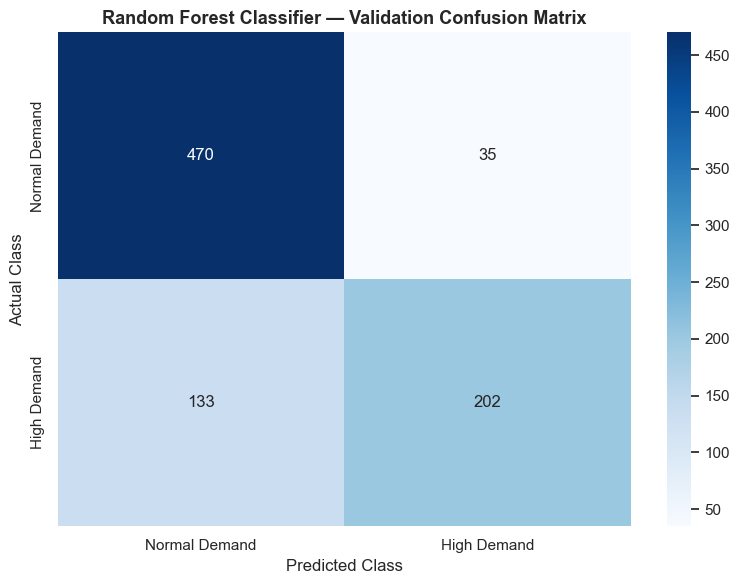

True Negatives: 470
False Positives: 35
False Negatives: 133
True Positives: 202


In [109]:
# Step 18.3 — Random Forest Confusion Matrix

# Calculate confusion matrix
rf_cm = confusion_matrix(
    y_validation_clf,
    rf_validation_pred,
    labels=[0, 1]
)

# Visualize with Seaborn
plt.figure(figsize=(8, 6))

sns.heatmap(
    rf_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal Demand", "High Demand"],
    yticklabels=["Normal Demand", "High Demand"]
)

plt.title(
    "Random Forest Classifier — Validation Confusion Matrix",
    fontsize=13,
    fontweight="bold"
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()

# Extract classification outcomes
tn, fp, fn, tp = rf_cm.ravel()

print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

### 18.3.1 Interpretation — Random Forest Confusion Matrix

The confusion matrix provides a detailed assessment of the Random Forest Classifier's ability to distinguish normal-demand observations from unusually high-demand observations.

The model was evaluated on **840 validation observations**, comprising 505 normal-demand observations and 335 high-demand observations.

#### 1. Confusion Matrix Results

| Outcome | Number of Observations |
|---|---:|
| True Negatives (TN) | 470 |
| False Positives (FP) | 35 |
| False Negatives (FN) | 133 |
| True Positives (TP) | 202 |
| Total Observations | 840 |

The model correctly classified **672 observations** and incorrectly classified **168 observations**, producing an overall accuracy of **80.00%**.

#### 2. Normal-Demand Classification

Of the 505 actual normal-demand observations:

- **470** were correctly classified as normal demand.
- **35** were incorrectly classified as high demand.

This corresponds to a normal-demand recall of approximately **93.07%**.

The model therefore performs well at identifying observations that do not exceed their historical high-demand thresholds.

From an inventory planning perspective, this reduces unnecessary high-demand alerts that could otherwise encourage excessive inventory allocation.

#### 3. High-Demand Classification

Of the 335 actual high-demand observations:

- **202** were correctly identified as high demand.
- **133** were incorrectly classified as normal demand.

This produces a high-demand recall of **60.30%**.

Consequently, the model fails to detect approximately **39.70% of actual high-demand observations**.

This is the most important limitation revealed by the confusion matrix.

Because the second business question focuses on identifying unusually high demand, missing nearly four out of ten high-demand observations could reduce the classifier's usefulness as an inventory risk detection tool.

However, a missed high-demand event does not necessarily mean an actual stockout occurred.

#### 4. False Positives Versus False Negatives

The model produced substantially more false negatives (**133**) than false positives (**35**).

This indicates that the classifier is relatively conservative when predicting high-demand events.

Its high-demand precision of **85.23%** demonstrates that most high-demand alerts are correct.

However, the relatively low recall indicates that this precision comes with a substantial number of missed events.

For inventory planning, the trade-off is important:

- **False positives** may encourage unnecessary replenishment or additional inventory monitoring.
- **False negatives** may result in insufficient preparation for unusually high demand.

The relative cost of these errors depends on inventory holding costs, product availability requirements, supplier lead times, and other operational factors.

#### 5. Implications for Model Improvement

The confusion matrix confirms that improving high-demand recall should be an important objective in subsequent model development.

Potential improvements include:

- Evaluating XGBoost Classifier as an alternative to Random Forest.
- Exploring probability threshold adjustments to increase high-demand detection.
- Assessing precision-recall trade-offs before selecting a classification threshold.
- Monitoring model performance across additional chronological evaluation periods.

Any model or threshold selection should be performed using validation data rather than the reserved test period.

#### 6. Conclusion

The Random Forest Classifier correctly identified **470 normal-demand observations** and **202 high-demand observations**, achieving an overall accuracy of **80.00%**.

Although the model demonstrates strong normal-demand detection and relatively high precision, it misses **133 of the 335 actual high-demand observations**.

This corresponds to a high-demand miss rate of **39.70%**, representing a significant limitation for the second business question.

The results establish a clear baseline for evaluating whether the XGBoost Classifier can improve high-demand detection while maintaining an acceptable balance between precision and recall.

### 18.4 Random Forest Classifier — ROC Curve and ROC-AUC Analysis

Following the confusion matrix analysis, this section evaluates the Random Forest Classifier's ability to distinguish between normal-demand and high-demand observations across different classification probability thresholds.

The **Receiver Operating Characteristic (ROC) curve** plots two measures:

- **True Positive Rate (TPR):** The proportion of actual high-demand observations correctly identified by the classifier. This is equivalent to recall.
- **False Positive Rate (FPR):** The proportion of actual normal-demand observations incorrectly classified as high demand.

The **Area Under the ROC Curve (ROC-AUC)** summarizes the model's ability to distinguish between the two demand classes across all possible classification thresholds.

An ROC-AUC of **0.50** represents random discrimination, while a value of **1.00** indicates perfect discrimination.

#### Connection to the Previous Results

The Random Forest Classifier achieved the following validation results:

- **Accuracy:** 80.00%
- **Precision:** 85.23%
- **Recall:** 60.30%
- **F1-score:** 70.63%
- **ROC-AUC:** 0.8727

The confusion matrix also revealed that the model failed to identify **133 of the 335 actual high-demand observations**.

Although the model demonstrates relatively strong discrimination, its recall at the current classification threshold indicates that a substantial proportion of high-demand events remain undetected.

#### Objective

The objective of the ROC analysis is to assess the classifier's overall discrimination performance and determine whether its predicted probabilities provide a useful basis for subsequent classification threshold optimization.

This is particularly relevant to the second business question, where identifying high-demand events is important for supporting proactive inventory planning.

The ROC analysis will also establish a benchmark for comparison with the **XGBoost Classifier**, which will be developed as the main classification model.

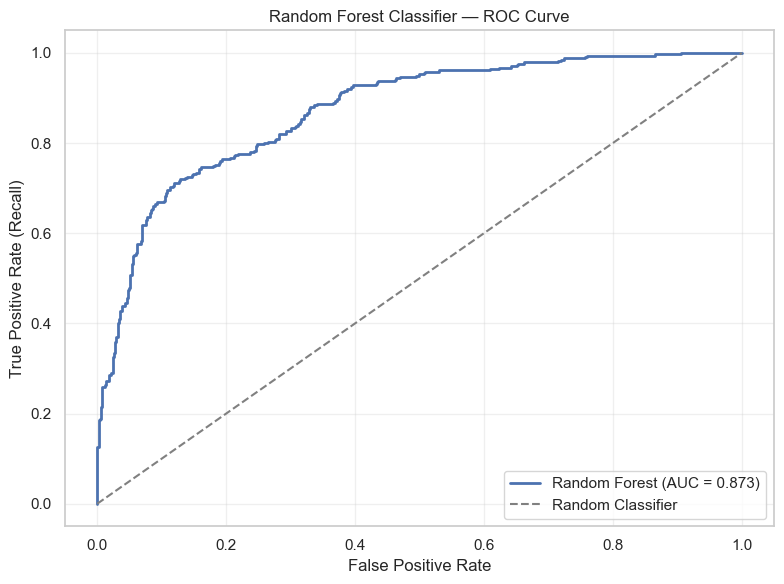

Random Forest ROC-AUC: 0.8727


In [110]:
# Step 18.4 — Random Forest ROC Curve

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(
    y_validation_clf,
    rf_validation_proba
)

# Calculate ROC-AUC
rf_auc = roc_auc_score(
    y_validation_clf,
    rf_validation_proba
)

# Plot ROC curve
plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"Random Forest (AUC = {rf_auc:.3f})"
)

# Random classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("Random Forest Classifier — ROC Curve")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Random Forest ROC-AUC: {rf_auc:.4f}")

### 18.4.1 Interpretation — Random Forest ROC Curve and ROC-AUC

The Receiver Operating Characteristic (ROC) curve evaluates the Random Forest Classifier's ability to distinguish between normal-demand and high-demand observations across different probability thresholds.

The model achieved a validation **ROC-AUC of 0.8727**, indicating good overall discrimination between the two classes.

#### 1. ROC Curve Performance

The ROC curve remains substantially above the diagonal reference line representing random classification.

This demonstrates that the Random Forest Classifier can distinguish high-demand observations from normal-demand observations considerably better than random guessing.

The curve also rises relatively steeply at low false-positive rates, indicating that the model can identify a meaningful proportion of high-demand events while maintaining a comparatively low rate of unnecessary high-demand alerts.

However, increasing the true positive rate generally requires accepting a higher false positive rate.

#### 2. Interpretation of ROC-AUC

The ROC-AUC value of **0.8727** indicates that the classifier has a strong ability to rank high-demand observations above normal-demand observations based on their predicted probabilities.

In practical terms, the model has approximately an **87.27% probability of assigning a higher classification score to a randomly selected high-demand observation than to a randomly selected normal-demand observation**, with ties accounted for in the AUC calculation.

This result suggests that the model's predicted probabilities contain useful information for identifying unusually high-demand events.

However, ROC-AUC measures ranking performance across thresholds rather than classification performance at one specific threshold.

#### 3. Connection to the Confusion Matrix

The previous confusion matrix showed that the Random Forest Classifier produced:

- **470 true negatives**
- **35 false positives**
- **133 false negatives**
- **202 true positives**

At the evaluated classification threshold, the model achieved:

- **High-demand recall:** 60.30%
- **High-demand precision:** 85.23%
- **False positive rate:** Approximately 6.93%

The low false positive rate indicates that the model rarely classifies normal-demand observations as high demand.

However, the recall of 60.30% indicates that approximately **39.70% of actual high-demand observations remain undetected**.

The combination of relatively strong ROC-AUC and moderate high-demand recall suggests that adjusting the classification probability threshold may improve high-demand detection.

#### 4. Implications for Classification Threshold Optimization

The ROC curve illustrates the trade-off between detecting additional high-demand events and generating unnecessary alerts.

Reducing the classification probability threshold may increase recall by identifying more high-demand observations.

However, this adjustment may also increase false positives and reduce precision.

For retail inventory planning, the appropriate balance depends on the relative operational costs of:

- Missing unusually high-demand events.
- Generating unnecessary replenishment alerts.
- Holding excess inventory.
- Failing to maintain sufficient product availability.

Therefore, classification threshold optimization should consider both statistical performance and business requirements.

Because high-demand observations are less frequent in the training dataset, precision-recall analysis will also be useful when selecting a threshold.

#### 5. Business Implications

The ROC-AUC result indicates that the Random Forest Classifier provides useful information for identifying store-category combinations likely to experience unusually high demand.

However, its current classification threshold does not identify all high-demand events.

This distinction is important for the second business question because the primary objective is not simply to distinguish demand classes, but to support the early identification of potential inventory risks.

Improving recall while maintaining acceptable precision could make the classifier more useful for inventory monitoring and replenishment planning.

#### 6. Conclusion

The Random Forest Classifier achieved a validation ROC-AUC of **0.8727**, demonstrating good discrimination between normal-demand and high-demand observations.

The ROC curve confirms that the model performs substantially better than random classification.

Nevertheless, the confusion matrix revealed that **133 of the 335 actual high-demand observations were missed** at the evaluated classification threshold.

These findings establish a useful baseline for subsequent model development.

The next stage will evaluate whether the **XGBoost Classifier** can improve high-demand detection compared with Random Forest, before selecting an appropriate classification probability threshold using validation data.

### 18.5 XGBoost Classifier — High-Demand Prediction

Following the evaluation of the Random Forest Classifier, this section introduces the **XGBoost Classifier (Extreme Gradient Boosting)** as the main classification model for predicting unusually high-demand events.

XGBoost is a gradient boosting machine learning algorithm that builds decision trees sequentially. Each successive tree aims to improve the model by correcting errors from the preceding trees.

XGBoost was selected as the final regression algorithm in the main retail demand forecasting analysis. The **Tuned XGBoost Regressor** achieved a test WAPE of **8.613%** and an R² of **0.976**, demonstrating strong predictive performance for retail demand quantities.

However, strong regression performance does not automatically guarantee superior classification performance. Therefore, the XGBoost Classifier must be trained and evaluated independently.

#### Connection to Business Question 2

**Business Question 2: Can machine learning identify store-category combinations that are likely to experience unusually high demand, allowing retailers to anticipate potential inventory shortages?**

The new objective is **to identify whether a particular store-category combination is likely to experience unusually high demand.**

The classification task distinguishes between:

- **Class 0 — Normal Demand:** Demand does not exceed the historical store-category high-demand threshold.
- **Class 1 — High Demand:** Demand exceeds the historical store-category high-demand threshold.

#### Why XGBoost Classifier?

XGBoost was selected for the following reasons:

1. **Nonlinear Relationships:** It can capture complex relationships between historical demand, seasonal patterns, calendar variables, pricing, and other predictors.
2. **Gradient Boosting:** It sequentially improves decision trees by minimizing a classification loss function.
3. **Regularization:** It provides mechanisms to control model complexity and reduce overfitting.
4. **Classification Probabilities:** It generates probabilities that can support high-demand risk scoring and probability threshold optimization.
5. **Project Consistency:** Using XGBoost for both regression and classification provides a consistent machine learning framework while addressing two different business questions.

#### Training and Evaluation Strategy

The XGBoost Classifier will use the same:

- **78 engineered predictor features** used by the Random Forest baseline.
- **44,790 training observations** and **840 validation observations**.
- Chronological training and validation periods.
- Historical store-category high-demand thresholds calculated from training data.

This ensures that both classification models are evaluated under comparable conditions.

#### Model Evaluation

The XGBoost Classifier will be evaluated using:

- **Accuracy:** Overall proportion of correctly classified observations.
- **Precision:** Reliability of predicted high-demand alerts.
- **Recall:** Ability to identify actual high-demand observations.
- **F1-score:** Balance between precision and recall.
- **ROC-AUC:** Ability to distinguish between normal-demand and high-demand observations across classification thresholds.
- **Confusion Matrix:** Detailed analysis of correct predictions, false positives, and false negatives.

Particular attention will be given to recall because the Random Forest baseline identified only **60.30% of actual high-demand observations**, missing **133 high-demand events** during validation.

#### Objective

The objective is to determine whether the **XGBoost Classifier can improve high-demand detection compared with the Random Forest baseline**, particularly in terms of recall and F1-score, while maintaining acceptable precision and ROC-AUC.

The results will support the selection of a classification model for subsequent probability threshold optimization and inventory risk analysis.

The reserved test dataset will remain excluded from model selection and threshold tuning.

In [111]:
# Step 18.5 — Train XGBoost Classifier

xgb_classifier = XGBClassifier(
    n_estimators=350,
    max_depth=6,
    learning_rate=0.07,
    subsample=0.85,
    colsample_bytree=0.75,
    min_child_weight=1,
    reg_lambda=5.0,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=SEED,
    n_jobs=-1
)

# Train using the existing classification features and targets
xgb_classifier.fit(
    X_train_clf,
    y_train_clf
)

# Predict validation probabilities for high demand (Class 1)
xgb_validation_proba = xgb_classifier.predict_proba(
    X_validation_clf
)[:, 1]

# Initial classification threshold = 0.50
xgb_validation_pred = (
    xgb_validation_proba >= 0.50
).astype(int)

print("XGBoost Classifier trained successfully.")
print("Validation predictions:", len(xgb_validation_pred))

XGBoost Classifier trained successfully.
Validation predictions: 840


In [112]:
# Step 18.5.1 — Classification Model Comparison

# Evaluate XGBoost Classifier
xgb_clf_results = pd.DataFrame({
    "Model": ["XGBoost Classifier"],
    "Accuracy": [
        accuracy_score(
            y_validation_clf,
            xgb_validation_pred
        )
    ],
    "Precision": [
        precision_score(
            y_validation_clf,
            xgb_validation_pred,
            zero_division=0
        )
    ],
    "Recall": [
        recall_score(
            y_validation_clf,
            xgb_validation_pred,
            zero_division=0
        )
    ],
    "F1": [
        f1_score(
            y_validation_clf,
            xgb_validation_pred,
            zero_division=0
        )
    ],
    "ROC_AUC": [
        roc_auc_score(
            y_validation_clf,
            xgb_validation_proba
        )
    ]
})

# Compare with existing Random Forest baseline
classification_comparison = pd.concat(
    [rf_clf_results, xgb_clf_results],
    ignore_index=True
)

print("Classification Model Comparison:")
display(classification_comparison.round(4))

# Detailed XGBoost classification report
print("\nXGBoost Classification Report:")
print(
    classification_report(
        y_validation_clf,
        xgb_validation_pred,
        target_names=["Normal Demand", "High Demand"],
        zero_division=0
    )
)

Classification Model Comparison:


,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Random Forest Classifier,0.8,0.8523,0.6030,0.7063,0.8727
1,XGBoost Classifier,0.8,0.8036,0.6597,0.7246,0.8777



XGBoost Classification Report:
               precision    recall  f1-score   support

Normal Demand       0.80      0.89      0.84       505
  High Demand       0.80      0.66      0.72       335

     accuracy                           0.80       840
    macro avg       0.80      0.78      0.78       840
 weighted avg       0.80      0.80      0.80       840



### 18.5.1 Interpretation — XGBoost Classifier and Random Forest Comparison

The XGBoost Classifier was successfully trained and evaluated on the chronological validation dataset containing **840 observations**, including 505 normal-demand observations and 335 high-demand observations.

The objective was to determine whether XGBoost could improve the identification of unusually high-demand events compared with the Random Forest baseline.

#### 1. Overall Classification Performance

| Metric | Random Forest | XGBoost |
|---|---:|---:|
| Accuracy | 80.00% | 80.00% |
| Precision | 85.23% | 80.36% |
| Recall | 60.30% | **65.97%** |
| F1-score | 70.63% | **72.46%** |
| ROC-AUC | 0.8727 | **0.8777** |

Both classifiers achieved an overall accuracy of **80.00%**, indicating that approximately four out of five validation observations were classified correctly.

However, the models differ in their ability to identify high-demand events.

#### 2. Recall — Improved High-Demand Detection

The Random Forest Classifier achieved a high-demand recall of **60.30%**, while XGBoost achieved **65.97%**.

This represents an improvement of **5.67 percentage points**.

The result indicates that XGBoost successfully identifies a greater proportion of actual high-demand observations.

For the second business question, this improvement is particularly relevant because the objective is to detect unusually high-demand periods that may require additional inventory planning attention.

Nevertheless, XGBoost still misses approximately **34.03%** of actual high-demand observations at the current classification threshold.

Therefore, further improvement remains desirable.

#### 3. Precision — Trade-Off Between Detection and False Alerts

Random Forest achieved a precision of **85.23%**, compared with **80.36%** for XGBoost.

XGBoost's precision is therefore **4.87 percentage points lower**.

This indicates that a smaller proportion of XGBoost's predicted high-demand alerts are correct.

The decrease in precision suggests a trade-off: XGBoost detects more genuine high-demand events but also produces more false-positive alerts relative to its total predicted high-demand alerts.

From an inventory planning perspective, additional false-positive alerts could lead to unnecessary replenishment monitoring or inventory allocation.

However, the appropriate trade-off depends on the operational costs of missed high-demand events and unnecessary alerts.

#### 4. F1-Score — Overall Balance

The XGBoost Classifier achieved an F1-score of **72.46%**, compared with **70.63%** for Random Forest.

This represents an improvement of **1.83 percentage points**.

The F1-score combines precision and recall, making it particularly useful when evaluating classification performance on imbalanced datasets.

The higher F1-score suggests that XGBoost provides a better balance between identifying high-demand events and maintaining prediction precision at the evaluated classification threshold.

#### 5. ROC-AUC — Classification Discrimination

XGBoost achieved a ROC-AUC of **0.8777**, compared with **0.8727** for Random Forest.

The improvement of **0.0050** indicates a modest increase in the model's ability to distinguish between high-demand and normal-demand observations across classification thresholds.

Both models demonstrate good discrimination, although the difference between their ROC-AUC scores is relatively small.

The results therefore do not establish a substantial improvement in overall discrimination.

#### 6. Classification Report

The XGBoost classification report produced the following results:

| Demand Class | Precision | Recall | F1-score | Support |
|---|---:|---:|---:|---:|
| Normal Demand | 0.80 | 0.89 | 0.84 | 505 |
| High Demand | 0.80 | 0.66 | 0.72 | 335 |

The model identifies approximately **89% of normal-demand observations** and **66% of high-demand observations**.

This confirms that high-demand detection remains more challenging than normal-demand classification.

However, XGBoost improves high-demand recall compared with the Random Forest baseline.

#### 7. Business Implications

The comparison demonstrates that XGBoost is a promising classification model for identifying unusually high-demand periods.

Its higher recall is valuable because missed high-demand events may reduce the effectiveness of proactive inventory planning.

However, the reduction in precision indicates that improving detection may require accepting additional false-positive alerts.

The model should therefore be evaluated not only on statistical performance but also on the operational trade-off between missed demand events and unnecessary inventory interventions.

#### 8. Model Selection

Based on the current validation results, **XGBoost Classifier is the preferred candidate for subsequent classification threshold optimization**.

It achieves:

- Higher high-demand recall.
- Higher F1-score.
- Slightly higher ROC-AUC.
- The same overall accuracy as Random Forest.

Although Random Forest maintains higher precision, XGBoost provides a more favorable balance for the project's objective of identifying high-demand events.

This selection is based on validation performance and does not yet establish superiority on unseen test data.

#### 9. Conclusion

The XGBoost Classifier achieved **80.00% accuracy, 80.36% precision, 65.97% recall, 72.46% F1-score, and 0.8777 ROC-AUC**.

Compared with Random Forest, XGBoost improves high-demand recall by **5.67 percentage points** and F1-score by **1.83 percentage points**.

These findings support selecting XGBoost as the main classification model for the next stage of analysis.

However, the model still misses approximately one-third of actual high-demand events at the current probability threshold.

The next stage will investigate whether **classification probability threshold optimization** can further improve high-demand detection while maintaining acceptable precision.

### 18.6 Classification Threshold Tuning — Random Forest vs. XGBoost

The previous classification model comparison used the default probability threshold of **0.50**.

However, this threshold is not necessarily optimal for identifying unusually high-demand events.

At the default threshold, the Random Forest Classifier achieved a high-demand recall of **60.30%**, while the XGBoost Classifier achieved **65.97%**.

Although XGBoost demonstrated better recall and F1-score, approximately **34.03% of actual high-demand observations remained undetected**.

For the second business question, improving high-demand detection is particularly important because missed high-demand events may increase the risk of insufficient inventory preparation.

#### Objective

This analysis evaluates the **Random Forest Classifier and XGBoost Classifier** across different classification probability thresholds using the chronological validation dataset.

The objectives are to:

1. Examine how precision, recall, F1-score, and false-positive rates change as the probability threshold changes.
2. Identify thresholds that achieve a target high-demand recall of at least **80%**.
3. Compare both models' precision and false-positive rates at thresholds satisfying this recall target.
4. Select a preferred classification model and probability threshold before evaluating the untouched test dataset.

#### Classification Threshold Trade-Off

Reducing the classification threshold generally increases the number of observations predicted as high demand.

This may improve recall by detecting more actual high-demand events.

However, it may also increase false-positive predictions and reduce precision.

Conversely, increasing the threshold generally reduces false-positive alerts but may cause additional high-demand events to be missed.

Therefore, the appropriate threshold should balance the ability to detect high-demand events against the operational consequences of unnecessary alerts.

#### Business Considerations

For inventory planning:

- **False negatives** represent actual high-demand observations that the model fails to identify.
- **False positives** represent normal-demand observations incorrectly flagged as high demand.

The target recall of **80%** is an illustrative operational objective rather than a threshold derived from known inventory costs.

In a real-world implementation, the recall target would be selected based on service-level requirements, inventory holding costs, supplier lead times, and the consequences of missed demand.

#### Evaluation Strategy

Threshold tuning will be performed exclusively on the validation dataset.

The Random Forest and XGBoost classifiers will be compared using the same validation observations and historical high-demand definitions.

The selected model and probability threshold will subsequently be evaluated on the reserved test dataset without further tuning.

This approach helps preserve the independence of the final test evaluation.

#### Expected Outcome

The analysis will determine whether adjusting the classification probability threshold can improve high-demand recall to at least **80%** while maintaining acceptable precision and false-positive rates.

The results will guide the selection of the final classification model and threshold for high-demand risk detection.

In [113]:
# Step 18.6.1 — Classification Threshold Tuning
# Compare Random Forest and XGBoost using validation data

# Candidate probability thresholds
thresholds = np.round(np.arange(0.10, 0.91, 0.05), 2)

# Existing validation probabilities
model_probabilities = {
    "Random Forest Classifier": rf_validation_proba,
    "XGBoost Classifier": xgb_validation_proba
}

threshold_results = []

for model_name, probabilities in model_probabilities.items():

    for threshold in thresholds:

        # Convert probabilities into binary predictions
        predictions = (
            np.asarray(probabilities) >= threshold
        ).astype(int)

        # Confusion matrix
        tn, fp, fn, tp = confusion_matrix(
            y_validation_clf,
            predictions,
            labels=[0, 1]
        ).ravel()

        # False-positive rate
        fpr = fp / (fp + tn) if (fp + tn) > 0 else 0

        threshold_results.append({
            "Model": model_name,
            "Threshold": threshold,
            "Accuracy": accuracy_score(
                y_validation_clf, predictions
            ),
            "Precision": precision_score(
                y_validation_clf, predictions,
                zero_division=0
            ),
            "Recall": recall_score(
                y_validation_clf, predictions,
                zero_division=0
            ),
            "F1": f1_score(
                y_validation_clf, predictions,
                zero_division=0
            ),
            "FPR": fpr,
            "False Positives": fp,
            "False Negatives": fn
        })

# Store results for later analysis
threshold_results_df = pd.DataFrame(threshold_results)

print("Classification Threshold Evaluation:")
display(threshold_results_df.round(4))

# Identify thresholds meeting the recall target
recall_target = 0.80

eligible_thresholds = threshold_results_df[
    threshold_results_df["Recall"] >= recall_target
].copy()

print("\nThresholds achieving at least 80% recall:")

if eligible_thresholds.empty:
    print("No evaluated threshold achieved the recall target.")
else:
    display(
        eligible_thresholds.sort_values(
            ["Model", "F1"],
            ascending=[True, False]
        ).round(4)
    )

Classification Threshold Evaluation:


,Model,Threshold,Accuracy,Precision,Recall,F1,FPR,False Positives,False Negatives
0,Random Forest Classifier,0.10,0.5357,0.4619,0.9940,0.6307,0.7683,388,2
1,Random Forest Classifier,0.15,0.6131,0.5079,0.9642,0.6653,0.6198,313,12
2,Random Forest Classifier,0.20,0.7119,0.5879,0.9284,0.7199,0.4317,218,24
3,Random Forest Classifier,0.25,0.7524,0.6408,0.8627,0.7354,0.3208,162,46
4,Random Forest Classifier,0.30,0.7690,0.6803,0.7940,0.7328,0.2475,125,69
5,Random Forest Classifier,0.35,0.7917,0.7339,0.7493,0.7415,0.1802,91,84
6,Random Forest Classifier,0.40,0.8071,0.7799,0.7194,0.7484,0.1347,68,94
7,Random Forest Classifier,0.45,0.8119,0.8266,0.6687,0.7393,0.0931,47,111
8,Random Forest Classifier,0.50,0.8000,0.8523,0.6030,0.7063,0.0693,35,133
9,Random Forest Classifier,0.55,0.7869,0.8645,0.5522,0.6740,0.0574,29,150



Thresholds achieving at least 80% recall:


,Model,Threshold,Accuracy,Precision,Recall,F1,FPR,False Positives,False Negatives
3,Random Forest Classifier,0.25,0.7524,0.6408,0.8627,0.7354,0.3208,162,46
2,Random Forest Classifier,0.20,0.7119,0.5879,0.9284,0.7199,0.4317,218,24
1,Random Forest Classifier,0.15,0.6131,0.5079,0.9642,0.6653,0.6198,313,12
0,Random Forest Classifier,0.10,0.5357,0.4619,0.9940,0.6307,0.7683,388,2
20,XGBoost Classifier,0.25,0.7738,0.6773,0.8269,0.7446,0.2614,132,58
19,XGBoost Classifier,0.20,0.7417,0.6288,0.8597,0.7264,0.3366,170,47
18,XGBoost Classifier,0.15,0.7095,0.5887,0.9015,0.7123,0.4178,211,33
17,XGBoost Classifier,0.10,0.6738,0.5527,0.9552,0.7002,0.5129,259,15


### 18.6.1 Interpretation — Classification Threshold Evaluation

The classification threshold tuning analysis evaluated Random Forest and XGBoost across **17 probability thresholds**, ranging from 0.10 to 0.90, using the chronological validation dataset.

A total of **34 model-threshold combinations** were evaluated.

The objective was to identify a classification threshold capable of achieving at least **80% high-demand recall** while maintaining acceptable precision and false-positive rates.

#### 1. Effect of Classification Thresholds

The results demonstrate a clear trade-off between precision and recall.

At lower probability thresholds, both classifiers identify a greater proportion of actual high-demand observations. However, this increased sensitivity also generates additional false-positive alerts.

At higher thresholds, precision generally improves and false-positive rates decline, but the models miss more genuine high-demand observations.

For example, XGBoost achieved:

| Threshold | Precision | Recall | F1-score | False Positives |
|---|---:|---:|---:|---:|
| 0.10 | 55.27% | 95.52% | 70.02% | 259 |
| 0.20 | 62.88% | 85.97% | 72.64% | 170 |
| **0.25** | **67.73%** | **82.69%** | **74.46%** | **132** |
| 0.30 | 72.01% | 79.10% | 75.39% | 103 |
| 0.35 | 75.30% | 75.52% | 75.41% | 83 |
| 0.50 | 80.36% | 65.97% | 72.46% | 54 |

Although XGBoost achieved a higher F1-score at thresholds 0.30 and 0.35, neither threshold satisfied the minimum 80% recall requirement.

This illustrates why the threshold with the highest F1-score is not necessarily the most appropriate threshold for the project's operational objective.

#### 2. Thresholds Meeting the 80% Recall Target

Both classifiers achieved the target recall at thresholds of 0.10, 0.15, 0.20, and 0.25.

Among the evaluated thresholds satisfying the recall requirement, **0.25 achieved the highest F1-score for both models**.

At threshold 0.25:

- Random Forest achieved 86.27% recall and 64.08% precision.
- XGBoost achieved 82.69% recall and 67.73% precision.

Therefore, Random Forest detected a greater proportion of actual high-demand observations, while XGBoost generated more reliable high-demand alerts.

#### 3. False-Positive and False-Negative Comparison

At threshold 0.25, Random Forest generated **162 false positives and 46 false negatives**.

XGBoost generated **132 false positives and 58 false negatives**.

Compared with Random Forest, XGBoost reduced false-positive alerts by **30 observations**, while missing **12 additional high-demand observations**.

Its false-positive rate was also lower:

- Random Forest: 32.08%
- XGBoost: 26.14%

This represents a reduction of **5.94 percentage points**.

From an inventory planning perspective, the lower false-positive rate could reduce unnecessary demand alerts and help inventory teams focus on more relevant potential demand increases.

However, the additional false negatives must also be considered because missed high-demand observations could affect proactive replenishment decisions.

#### 4. Comparison With the Default Threshold

At the default threshold of 0.50, XGBoost achieved:

- Precision: 80.36%
- Recall: 65.97%
- F1-score: 72.46%
- False negatives: 114

Reducing the threshold to 0.25 increased recall to **82.69%** and reduced false negatives from **114 to 58**.

This represents **56 additional high-demand observations correctly identified**.

However, false positives increased from 54 to 132.

The result demonstrates that threshold adjustment can substantially improve high-demand detection without retraining the classifier, although this comes at the cost of more false-positive alerts.

#### 5. Preferred Model and Threshold

Based on the predefined recall target and the validation results, the preferred configuration is:

**XGBoost Classifier with a probability threshold of 0.25.**

This configuration achieves:

| Metric | Validation Result |
|---|---:|
| Accuracy | 77.38% |
| Precision | 67.73% |
| Recall | 82.69% |
| F1-score | 74.46% |
| False-positive rate | 26.14% |
| False positives | 132 |
| False negatives | 58 |

XGBoost is preferred because it satisfies the minimum recall requirement while achieving higher precision, higher F1-score, and a lower false-positive rate than Random Forest at their best evaluated thresholds meeting the target.

However, this choice assumes that the reduction in false-positive alerts is worth the modest decrease in recall. If missed high-demand events are substantially more costly than false alerts, Random Forest may remain a reasonable alternative.

#### 6. Business Interpretation

The threshold-tuning analysis demonstrates that classification models can support more proactive identification of unusual demand patterns.

By adjusting the XGBoost probability threshold from 0.50 to 0.25, the model identifies a larger proportion of high-demand observations.

This could help retailers prioritize store-category combinations requiring additional inventory monitoring or replenishment planning.

However, predicted high demand does not necessarily indicate an actual stockout. Inventory availability, lead times, safety stock, and replenishment policies would also need to be considered.

#### 7. Conclusion

The classification threshold tuning analysis successfully identified configurations meeting the illustrative **80% high-demand recall target**.

The selected XGBoost threshold of **0.25** achieved 82.69% recall, 67.73% precision, and a 74.46% F1-score on validation data.

This provides a more suitable operating point for high-demand detection than the default threshold of 0.50 under the stated recall requirement.

The next step is to finalize the model-threshold selection and evaluate the chosen configuration on the untouched test dataset, without further adjustment based on test results.

### 18.6.2 Confusion Matrix Comparison After Threshold Tuning

Following classification threshold optimization, confusion matrices are generated for both the Random Forest Classifier and XGBoost Classifier using their selected validation thresholds.

The selected configurations are:

- **Random Forest Classifier:** Threshold = 0.25
- **XGBoost Classifier:** Threshold = 0.25

Both thresholds were selected from the evaluated candidates by maximizing validation F1-score while satisfying the minimum high-demand recall requirement of **80%**.

#### Objective

The objective is to compare the classifiers based on:

1. **True Positives (TP):** High-demand observations correctly identified.
2. **True Negatives (TN):** Normal-demand observations correctly identified.
3. **False Positives (FP):** Normal-demand observations incorrectly classified as high demand.
4. **False Negatives (FN):** Actual high-demand observations incorrectly classified as normal demand.

Particular attention is given to false negatives because missed high-demand events may reduce the effectiveness of proactive inventory planning.

However, false positives are also important because unnecessary high-demand alerts may result in inefficient inventory allocation or additional monitoring costs.

#### Expected Comparison

The confusion matrices will illustrate the trade-off between identifying more high-demand observations and minimizing unnecessary alerts.

The results will provide visual evidence supporting the selection of the preferred classifier under the predefined minimum recall requirement.

Based on the threshold-tuning results, XGBoost is the preferred candidate because it meets the recall target while achieving higher precision and F1-score and a lower false-positive rate than Random Forest.

The final model selection will remain based on validation results, with the test dataset reserved for independent evaluation.

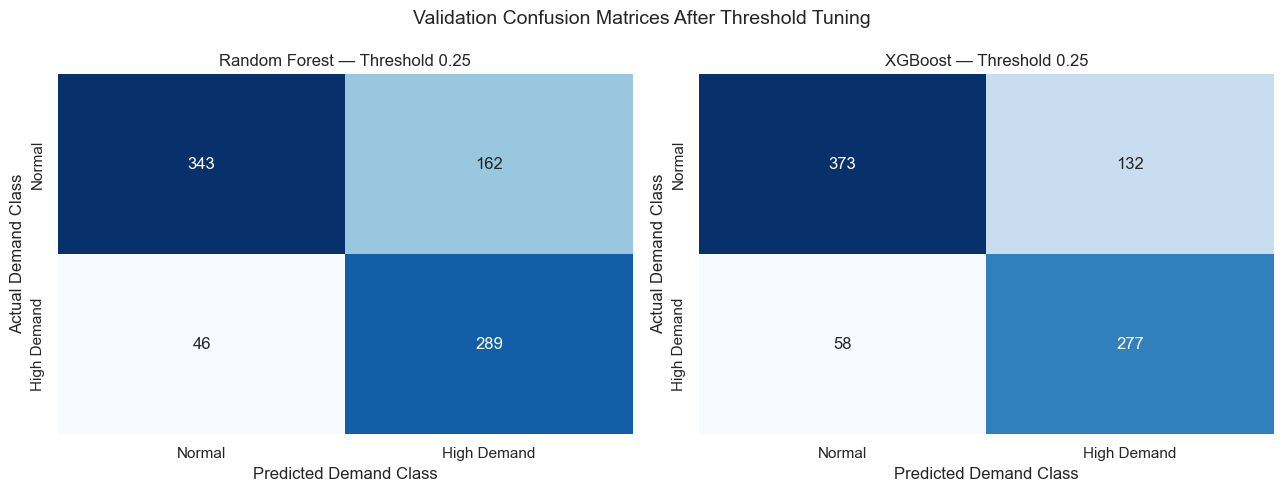

In [114]:
# Step 18.6.2 — Confusion Matrix Comparison After Threshold Tuning

# Selected validation thresholds
rf_selected_threshold = 0.25
xgb_selected_threshold = 0.25

# Generate predictions using the selected thresholds
rf_tuned_pred = (
    rf_validation_proba >= rf_selected_threshold
).astype(int)

xgb_tuned_pred = (
    xgb_validation_proba >= xgb_selected_threshold
).astype(int)

# Calculate confusion matrices
rf_tuned_cm = confusion_matrix(
    y_validation_clf,
    rf_tuned_pred,
    labels=[0, 1]
)

xgb_tuned_cm = confusion_matrix(
    y_validation_clf,
    xgb_tuned_pred,
    labels=[0, 1]
)

# Visualize both confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

models = [
    ("Random Forest", rf_tuned_cm, rf_selected_threshold),
    ("XGBoost", xgb_tuned_cm, xgb_selected_threshold)
]

for ax, (model_name, cm, threshold) in zip(axes, models):

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=["Normal", "High Demand"],
        yticklabels=["Normal", "High Demand"],
        ax=ax
    )

    ax.set_title(
        f"{model_name} — Threshold {threshold:.2f}"
    )
    ax.set_xlabel("Predicted Demand Class")
    ax.set_ylabel("Actual Demand Class")

plt.suptitle(
    "Validation Confusion Matrices After Threshold Tuning",
    fontsize=14
)

plt.tight_layout()
plt.show()

### 18.6.2.1 Interpretation — Confusion Matrix Comparison After Threshold Tuning

The confusion matrix comparison evaluates the Random Forest and XGBoost classifiers using their selected probability thresholds of **0.25** on the chronological validation dataset.

The validation dataset contains **840 observations**, consisting of 505 normal-demand observations and 335 high-demand observations.

Both classifiers meet the predefined minimum recall target of 80%, but they demonstrate different trade-offs between detecting high-demand events and generating false-positive alerts.

#### 1. Random Forest Classifier — Threshold 0.25

The Random Forest confusion matrix produced:

| Classification Outcome | Observations |
|---|---:|
| True Negatives (TN) | 343 |
| False Positives (FP) | 162 |
| False Negatives (FN) | 46 |
| True Positives (TP) | 289 |

Random Forest correctly identified **289 out of 335 actual high-demand observations**, achieving a recall of **86.27%**.

However, it incorrectly classified 162 normal-demand observations as high demand, resulting in a false-positive rate of **32.08%**.

This indicates that Random Forest provides relatively strong high-demand detection but generates a considerable number of unnecessary alerts.

From an inventory planning perspective, the high recall is valuable because it reduces the number of potentially important demand increases that go undetected.

Nevertheless, the large number of false-positive alerts could lead to unnecessary inventory monitoring or inefficient replenishment decisions.

#### 2. XGBoost Classifier — Threshold 0.25

The XGBoost confusion matrix produced:

| Classification Outcome | Observations |
|---|---:|
| True Negatives (TN) | 373 |
| False Positives (FP) | 132 |
| False Negatives (FN) | 58 |
| True Positives (TP) | 277 |

XGBoost correctly identified **277 out of 335 actual high-demand observations**, achieving a recall of **82.69%**.

The model also correctly classified 373 normal-demand observations and generated 132 false-positive alerts.

Its false-positive rate was **26.14%**, which is lower than Random Forest's 32.08%.

These results indicate that XGBoost achieves the minimum high-demand detection target while producing fewer unnecessary alerts.

However, XGBoost misses 58 actual high-demand observations, compared with 46 missed by Random Forest.

#### 3. Comparison of High-Demand Detection

Random Forest correctly detected **12 more high-demand observations** than XGBoost.

This explains its higher recall:

- Random Forest: 86.27%
- XGBoost: 82.69%

The recall difference is **3.58 percentage points** in favor of Random Forest.

However, XGBoost correctly identified **30 additional normal-demand observations**, reducing false-positive alerts from 162 to 132.

The false-positive rate decreased by **5.94 percentage points**.

This demonstrates the operational trade-off between maximizing high-demand detection and limiting unnecessary alerts.

#### 4. Precision and F1-Score Comparison

At the selected threshold, XGBoost achieved a precision of **67.73%**, compared with **64.08%** for Random Forest.

This indicates that XGBoost's high-demand alerts were more reliable.

XGBoost also achieved a slightly higher F1-score:

- Random Forest: 73.54%
- XGBoost: 74.46%

The improvement of **0.92 percentage points** suggests that XGBoost provides a slightly better balance between precision and recall.

Although the difference is modest, it supports selecting XGBoost under the project's current evaluation criteria.

#### 5. Business Implications

For retail inventory management, both types of classification errors have operational consequences.

**False negatives** represent missed high-demand observations. These may reduce opportunities to prepare inventory for unusually high sales.

**False positives** represent unnecessary high-demand alerts. These may lead to additional inventory checks, replenishment reviews, or potentially excessive stock allocation.

Random Forest may be preferable when missing a high-demand event is especially costly.

XGBoost may be preferable when retailers want to achieve the minimum detection target while limiting unnecessary alerts.

The appropriate choice ultimately depends on the relative operational costs of the two error types.

Importantly, a high-demand classification does not directly establish that a stockout will occur. Actual inventory risk also depends on available stock, replenishment lead times, and inventory policies.

#### 6. Preferred Classification Model

Based on the validation results and the predefined requirement of at least 80% recall, **XGBoost Classifier with a probability threshold of 0.25 is selected as the preferred configuration**.

The selection is supported by:

1. High-demand recall of **82.69%**, satisfying the minimum requirement.
2. Higher precision of **67.73%**.
3. Higher F1-score of **74.46%**.
4. Lower false-positive rate of **26.14%**.
5. Fewer unnecessary alerts than Random Forest.

However, Random Forest retains an advantage in recall, and the selected configuration should not be interpreted as universally superior under all inventory cost scenarios.

#### 7. Conclusion

The confusion matrix comparison confirms that both classifiers can achieve the project's illustrative minimum high-demand recall target.

Random Forest provides stronger high-demand detection, while XGBoost generates fewer false-positive alerts and achieves a slightly higher F1-score.

Therefore, **XGBoost Classifier with a threshold of 0.25 is retained as the preferred model for final classification evaluation**.

The selected model and threshold will be applied to the untouched test dataset without further adjustment based on test results.

### 18.7 Final Test Evaluation — XGBoost Classifier

Following validation-based model selection and classification threshold optimization, the **XGBoost Classifier** was selected as the preferred model for identifying unusually high-demand events across Walmart store-category combinations.

The selected classification probability threshold is **0.25**, determined using the chronological validation dataset.

This threshold was chosen because it achieved the highest F1-score among the evaluated XGBoost thresholds satisfying the predefined minimum high-demand recall requirement of **80%**.

#### 1. Validation-Based Model Selection

At the selected threshold of 0.25, the XGBoost Classifier achieved the following validation results:

| Evaluation Metric | Validation Performance |
|---|---:|
| Accuracy | 77.38% |
| Precision | 67.73% |
| Recall | 82.69% |
| F1-score | 74.46% |
| False-positive rate | 26.14% |
| False positives | 132 |
| False negatives | 58 |

These results demonstrated that XGBoost could identify more than 80% of actual high-demand observations while maintaining higher precision and fewer false-positive alerts than Random Forest at the selected thresholds.

Consequently, XGBoost was selected as the preferred classifier for final test evaluation.

#### 2. Final Test Dataset

The final test dataset covers the **28-day period from March 28, 2016, to April 24, 2016**.

It contains **840 store-category-day observations**, representing 30 store-category combinations evaluated over 28 days.

The test dataset was reserved for final evaluation and was not used for classifier training, model selection, or probability threshold optimization.

The high-demand labels remain defined using the historical store-category thresholds calculated exclusively from training data.

This ensures that the definition of unusually high demand remains consistent across training, validation, and testing.

#### 3. Evaluation Objective

The objective of this section is to assess how effectively the selected XGBoost Classifier generalizes to previously unseen observations.

The model will be evaluated using:

1. **Accuracy:** Overall proportion of correctly classified observations.
2. **Precision:** Proportion of predicted high-demand observations that are genuinely high demand.
3. **Recall:** Proportion of actual high-demand observations correctly detected.
4. **F1-score:** Balance between precision and recall.
5. **ROC-AUC:** Ability to distinguish between normal and high-demand observations across classification thresholds.
6. **Confusion Matrix:** Number of true positives, true negatives, false positives, and false negatives.

Particular attention will be given to high-demand recall and false negatives because missed high-demand events may reduce opportunities for proactive inventory preparation.

#### 4. Fixed Classification Threshold

The probability threshold will remain fixed at **0.25** throughout the final test evaluation.

No further threshold adjustments or model selection decisions will be made using the test results.

This prevents the final test dataset from influencing the model configuration and helps preserve an independent assessment of generalization performance.

#### 5. Connection to Business Question 2

**Business Question 2: Can machine learning identify store-category combinations that are likely to experience unusually high demand, allowing retailers to anticipate potential inventory shortages?**

The final test evaluation will assess whether XGBoost can reliably identify unusually high-demand observations outside the training and validation periods.

Successful high-demand detection could support inventory monitoring, replenishment prioritization, and proactive demand planning.

However, unusually high demand does not necessarily imply an actual stockout. Determining stockout risk would additionally require information about available inventory, safety stock, and replenishment lead times.

#### 6. Expected Outcome

The final evaluation will establish the out-of-sample classification performance of the selected XGBoost model.

The results will be compared with validation performance to assess whether the model maintains acceptable accuracy, precision, recall, F1-score, and ROC-AUC on unseen observations.

The findings will provide the final evidence for evaluating the usefulness and limitations of the high-demand classification approach.

In [118]:
# Step 18.7 — Final Test Evaluation: XGBoost Classifier

# Reuse the existing forecast-origin-safe test features
X_test_clf = X_test.copy()

# Reuse binary classification labels already created in Step 18.1
y_test_clf = test_classification["high_demand"].copy()

# Verify feature and target consistency
assert len(X_test_clf) == len(y_test_clf)
assert X_train_clf.columns.equals(X_test_clf.columns)

# Verify labels use the existing training-derived threshold
assert np.array_equal(
    y_test_clf.to_numpy(),
    (
        test_classification["demand"]
        > test_classification["high_demand_threshold"]
    ).astype(int).to_numpy()
)

# Fixed threshold selected during validation
FINAL_THRESHOLD = 0.25

# Predict final test probabilities
xgb_test_proba = xgb_classifier.predict_proba(
    X_test_clf
)[:, 1]

# Apply selected threshold
xgb_test_pred = (
    xgb_test_proba >= FINAL_THRESHOLD
).astype(int)

# Calculate final test metrics
final_clf_results = pd.DataFrame({
    "Model": ["XGBoost Classifier"],
    "Threshold": [FINAL_THRESHOLD],
    "Accuracy": [
        accuracy_score(y_test_clf, xgb_test_pred)
    ],
    "Precision": [
        precision_score(
            y_test_clf, xgb_test_pred, zero_division=0
        )
    ],
    "Recall": [
        recall_score(
            y_test_clf, xgb_test_pred, zero_division=0
        )
    ],
    "F1": [
        f1_score(
            y_test_clf, xgb_test_pred, zero_division=0
        )
    ],
    "ROC_AUC": [
        roc_auc_score(y_test_clf, xgb_test_proba)
    ]
})

print("Final XGBoost Classifier Test Results:")
display(final_clf_results.round(4))

print("\nFinal Test Classification Report:")
print(
    classification_report(
        y_test_clf,
        xgb_test_pred,
        target_names=["Normal Demand", "High Demand"],
        zero_division=0
    )
)

print("\nFinal Test Confusion Matrix:")

xgb_test_cm = confusion_matrix(
    y_test_clf,
    xgb_test_pred,
    labels=[0, 1]
)

print(xgb_test_cm)

tn, fp, fn, tp = xgb_test_cm.ravel()

print("\nConfusion Matrix Breakdown:")
print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

print("\nFinal Test High-Demand Rate:",
      round(y_test_clf.mean() * 100, 2), "%")

Final XGBoost Classifier Test Results:


,Model,Threshold,Accuracy,Precision,Recall,F1,ROC_AUC
0,XGBoost Classifier,0.25,0.8024,0.7264,0.8705,0.792,0.9095



Final Test Classification Report:
               precision    recall  f1-score   support

Normal Demand       0.88      0.75      0.81       477
  High Demand       0.73      0.87      0.79       363

     accuracy                           0.80       840
    macro avg       0.81      0.81      0.80       840
 weighted avg       0.82      0.80      0.80       840


Final Test Confusion Matrix:
[[358 119]
 [ 47 316]]

Confusion Matrix Breakdown:
True Negatives: 358
False Positives: 119
False Negatives: 47
True Positives: 316

Final Test High-Demand Rate: 43.21 %


### 18.7.1 Interpretation — Final XGBoost Classifier Test Performance

The XGBoost Classifier was evaluated on the final 28-day test period using the probability threshold of **0.25**, selected during validation.

The evaluation covered **840 store-category-day observations**, including 477 normal-demand observations and 363 high-demand observations.

#### 1. Final Test Performance

| Metric | Validation | Final Test |
|---|---:|---:|
| Accuracy | 77.38% | 80.24% |
| Precision | 67.73% | 72.64% |
| Recall | 82.69% | 87.05% |
| F1-score | 74.46% | 79.20% |
| ROC-AUC | 0.8777 | 0.9095 |

The classifier achieved an accuracy of **80.24%**, correctly classifying 674 of the 840 test observations.

High-demand precision reached **72.64%**, indicating that approximately 73% of observations flagged as unusually high demand were genuinely high-demand events.

More importantly, high-demand recall reached **87.05%**, exceeding the predefined minimum recall target of 80%.

This means the model successfully identified approximately 87 out of every 100 actual high-demand observations during the test period.

The F1-score of **79.20%** indicates a reasonable balance between high-demand precision and recall, while the ROC-AUC of **0.9095** demonstrates strong discrimination between normal and unusually high demand.

#### 2. Confusion Matrix Interpretation

The final test confusion matrix produced the following results:

| Actual / Predicted | Normal Demand | High Demand |
|---|---:|---:|
| Normal Demand | 358 | 119 |
| High Demand | 47 | 316 |

- **True Negatives (358):** Normal-demand observations correctly identified.
- **False Positives (119):** Normal-demand observations incorrectly flagged as high demand.
- **False Negatives (47):** Actual high-demand observations that the classifier failed to detect.
- **True Positives (316):** Actual high-demand observations correctly identified.

The model correctly identified **316 of 363 high-demand observations**, missing only 47.

This corresponds to a high-demand miss rate of approximately **12.95%**.

However, the 119 false positives indicate that the model sometimes generates unnecessary high-demand alerts. These alerts could lead to additional inventory checks or unnecessary replenishment decisions if used without supporting inventory information.

#### 3. Validation vs. Test Generalization

The classifier performed better on the final test dataset than on validation:

- Accuracy increased by approximately 2.86 percentage points.
- Precision increased by approximately 4.91 percentage points.
- Recall increased by approximately 4.36 percentage points.
- F1-score increased by approximately 4.74 percentage points.
- ROC-AUC increased from 0.8777 to 0.9095.

These improvements provide encouraging evidence that the selected XGBoost model and fixed classification threshold generalized effectively to the reserved test period.

Nevertheless, the higher test performance should not be interpreted as proof that the model will perform equally well in every future period. Additional chronological evaluations would be needed to establish longer-term stability.

#### 4. Business Interpretation

The classification results directly address Business Question 2:

**Can machine learning identify store-category combinations that are likely to experience unusually high demand, allowing retailers to anticipate potential inventory shortages?**

The results suggest that XGBoost can identify a substantial majority of unusually high-demand observations.

By detecting 316 of the 363 actual high-demand observations, the classifier could help retail planners prioritize store-category combinations requiring closer inventory monitoring.

Potential applications include proactive replenishment reviews, demand alerts, inventory allocation prioritization, and operational planning.

However, high-demand classification identifies demand conditions rather than confirmed stockout events. Actual shortage risk also depends on available stock, replenishment lead times, and inventory policies.

#### 5. Final Conclusion

The XGBoost Classifier achieved strong final test performance, with **80.24% accuracy, 87.05% high-demand recall, 79.20% F1-score, and 0.9095 ROC-AUC**.

Importantly, the classifier exceeded the predefined 80% recall requirement without any further threshold adjustment on the test dataset.

These results support the use of XGBoost as a promising high-demand detection component within a broader inventory decision-support system.

The model provides a useful complement to the demand forecasting analysis by identifying observations where unusually high demand may require additional operational attention.

### 18.7.2 Final Test Confusion Matrix Visualization

To visualize classification performance on unseen data, a confusion matrix is generated for the selected **XGBoost Classifier**, using the validation-optimized probability threshold of **0.25**.

The visualization distinguishes correctly classified normal-demand and high-demand observations from false positives and false negatives.

The objective is to assess how effectively the classifier identifies unusually high-demand events during the final 28-day test period and illustrate the remaining classification errors.

Particular attention is given to false negatives, as missed high-demand observations may reduce opportunities for proactive inventory planning.

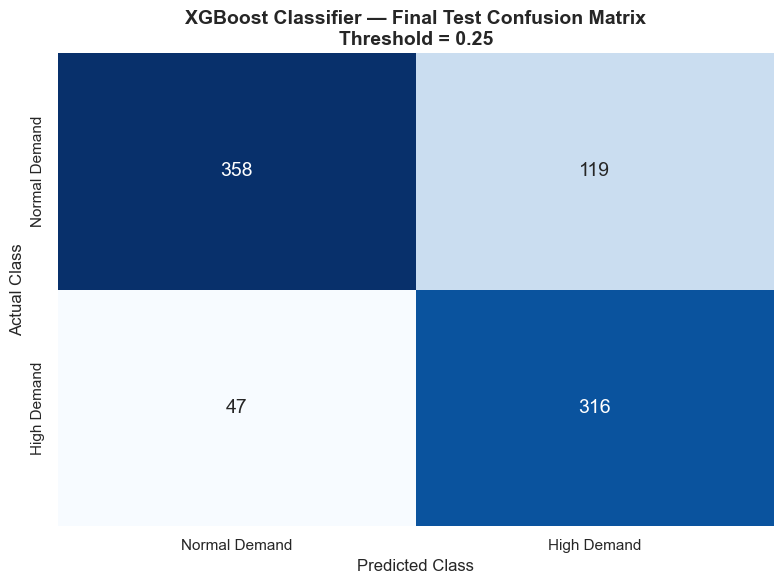

In [119]:
# Step 18.7.2 — Final Test Confusion Matrix: XGBoost

# Calculate confusion matrix using final test predictions
xgb_test_cm = confusion_matrix(
    y_test_clf,
    xgb_test_pred,
    labels=[0, 1]
)

# Plot confusion matrix
plt.figure(figsize=(8, 6))

sns.heatmap(
    xgb_test_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal Demand", "High Demand"],
    yticklabels=["Normal Demand", "High Demand"],
    cbar=False,
    annot_kws={"size": 14}
)

plt.title(
    "XGBoost Classifier — Final Test Confusion Matrix\n"
    "Threshold = 0.25",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()

### 18.7.3 Interpretation — Final Test Confusion Matrix

The final test confusion matrix evaluates the **XGBoost Classifier** using the fixed probability threshold of **0.25**, selected during validation.

The evaluation covers **840 store-category-day observations** from the final 28-day test period.

#### 1. Confusion Matrix Results

| Actual / Predicted | Normal Demand | High Demand |
|---|---:|---:|
| Normal Demand | 358 | 119 |
| High Demand | 47 | 316 |

The results show:

- **True Negatives (358):** Normal-demand observations correctly classified as normal demand.
- **False Positives (119):** Normal-demand observations incorrectly classified as high demand.
- **False Negatives (47):** Actual high-demand observations incorrectly classified as normal demand.
- **True Positives (316):** High-demand observations correctly identified.

Overall, the classifier correctly classified **674 of 840 observations**, achieving an accuracy of **80.24%**.

#### 2. High-Demand Detection Performance

The primary business objective is to identify unusually high-demand observations before they create potential inventory management challenges.

Of the **363 actual high-demand observations**, the classifier correctly identified **316**, resulting in a recall of **87.05%**.

This exceeds the predefined minimum recall requirement of 80%.

The remaining 47 false negatives represent approximately **12.95%** of actual high-demand observations.

These missed events are particularly relevant because they represent situations in which the model would not generate a high-demand alert despite demand exceeding the historical threshold.

#### 3. False-Positive Trade-off

The classifier generated **119 false-positive alerts** among 477 actual normal-demand observations.

This corresponds to a false-positive rate of approximately **24.95%**.

Although false positives could increase inventory monitoring workload or trigger unnecessary replenishment reviews, the selected threshold prioritizes detecting high-demand events.

The resulting high-demand precision of **72.64%** indicates that approximately 73% of the model's high-demand alerts were correct.

Whether this balance is economically optimal depends on the relative costs of missed demand events and unnecessary inventory interventions.

#### 4. Comparison with Validation Performance

The selected XGBoost Classifier achieved:

| Metric | Validation | Final Test |
|---|---:|---:|
| Accuracy | 77.38% | 80.24% |
| Precision | 67.73% | 72.64% |
| Recall | 82.69% | 87.05% |
| F1-score | 74.46% | 79.20% |
| ROC-AUC | 0.8777 | 0.9095 |

All five reported metrics improved during final testing.

In particular, high-demand recall increased by approximately **4.36 percentage points**, indicating that the model maintained and exceeded the required detection performance on unseen observations.

This provides encouraging evidence of generalization across the reserved test period, although additional time-based evaluations would be necessary to assess performance stability over longer horizons.

#### 5. Business Implications

The confusion matrix provides practical evidence that the XGBoost Classifier can support proactive inventory monitoring.

By correctly identifying **316 of 363 high-demand observations**, the model could help retailers prioritize store-category combinations that may require additional attention.

Potential applications include:

- Identifying store-category combinations requiring closer inventory monitoring.
- Supporting proactive replenishment reviews.
- Prioritizing inventory allocation decisions.
- Providing high-demand alerts alongside the regression-based demand forecasts.

However, high-demand classification does not directly establish whether inventory shortages occurred. Actual stockout risk also depends on inventory availability, replenishment lead times, and safety-stock policies.

#### 6. Conclusion

The final test confusion matrix demonstrates that the selected XGBoost Classifier successfully identified **87.05% of unusually high-demand observations** while maintaining **72.64% precision**.

The classifier exceeded the predefined 80% recall requirement using the fixed validation-selected threshold of 0.25.

Although 47 high-demand observations were missed and 119 false-positive alerts were generated, the results support XGBoost as a promising component of a retail demand-monitoring and inventory decision-support system.

These findings complement the regression forecasting analysis by demonstrating how machine learning can support both **demand quantity prediction** and **high-demand event identification**.

### 18.8 Final Data Integrity and Leakage Verification

Before concluding the classification analysis, additional checks are performed to verify the reliability of the model evaluation.

The objectives are to:

1. Confirm that training, validation, and test datasets contain the expected number of observations.
2. Verify that classification labels are aligned with their corresponding feature rows.
3. Check that the chronological train-validation-test split is preserved.
4. Identify potential data leakage from features that would not be available at the forecasting origin.

These checks are important because incorrectly aligned labels or future information in the input features could produce misleading model evaluation results.

In [120]:
# Step 18.8 — Classification Data Integrity Checks

datasets = {
    "Training": (
        X_train_clf,
        y_train_clf,
        train_classification
    ),
    "Validation": (
        X_validation_clf,
        y_validation_clf,
        validation_classification
    ),
    "Test": (
        X_test_clf,
        y_test_clf,
        test_classification
    )
}

integrity_results = []

for name, (X, y, data) in datasets.items():

    # Check observation counts
    same_length = len(X) == len(y) == len(data)

    # Compare classification labels
    target_values_match = np.array_equal(
        np.asarray(y),
        data["high_demand"].to_numpy()
    )

    # Independently verify labels against
    # historical training-derived thresholds
    threshold_labels_match = np.array_equal(
        np.asarray(y),
        (
            data["demand"]
            > data["high_demand_threshold"]
        ).astype(int).to_numpy()
    )

    # Check missing and invalid targets
    missing_targets = int(pd.isna(y).sum())

    valid_binary_target = set(
        pd.Series(np.asarray(y)).dropna().unique()
    ).issubset({0, 1})

    # Verify classification feature structure
    feature_columns_match = X.columns.equals(
        X_train_clf.columns
    )

    integrity_results.append({
        "Dataset": name,
        "Feature Rows": len(X),
        "Target Rows": len(y),
        "Same Length": same_length,
        "Target Values Match": target_values_match,
        "Threshold Labels Match": threshold_labels_match,
        "Missing Targets": missing_targets,
        "Binary Target": valid_binary_target,
        "Feature Columns Match": feature_columns_match
    })

integrity_check = pd.DataFrame(integrity_results)

print("CLASSIFICATION DATA INTEGRITY RESULTS")
display(integrity_check)

print("\nClassification identifier columns:")
print([
    col for col in test_classification.columns
    if col in ["date", "store_id", "category", "demand"]
])

print("\nOriginal test feature identifier columns:")
print([
    col for col in X_test_raw.columns
    if col in ["date", "store_id", "category", "demand"]
])

print("\nTest feature shape:", X_test_clf.shape)
print("Test classification shape:", test_classification.shape)

# Flag any failed checks
check_columns = [
    "Same Length",
    "Target Values Match",
    "Threshold Labels Match",
    "Binary Target",
    "Feature Columns Match"
]

all_checks_passed = (
    integrity_check[check_columns].all().all()
    and (integrity_check["Missing Targets"] == 0).all()
)

print("\nAll structural integrity checks passed:",
      bool(all_checks_passed))

CLASSIFICATION DATA INTEGRITY RESULTS


,Dataset,Feature Rows,Target Rows,Same Length,Target Values Match,Threshold Labels Match,Missing Targets,Binary Target,Feature Columns Match
0,Training,44790,44790,True,True,True,0,True,True
1,Validation,840,840,True,True,True,0,True,True
2,Test,840,840,True,True,True,0,True,True



Classification identifier columns:
['store_id', 'category', 'demand', 'date']

Original test feature identifier columns:
['store_id', 'category']

Test feature shape: (840, 78)
Test classification shape: (840, 42)

All structural integrity checks passed: True


### 18.8 Interpretation — Classification Data Integrity Checks

The classification data integrity checks were successfully completed for all three chronological datasets.

The results confirm that:

- **Training:** 44,790 observations with 78 engineered features.
- **Validation:** 840 observations with the same feature structure.
- **Test:** 840 observations with the same feature structure.

All datasets passed the following checks:

1. **Observation consistency:** Feature matrices, classification targets, and corresponding datasets contain matching numbers of observations.
2. **Target consistency:** Binary classification labels match the labels stored in their corresponding datasets.
3. **Historical threshold consistency:** High-demand labels are correctly calculated using the training-derived historical demand thresholds.
4. **Missing target verification:** No missing classification targets were detected.
5. **Binary target validation:** All classification targets contain valid binary values (0 or 1).
6. **Feature consistency:** Training, validation, and test datasets have matching feature columns in the same order.

The final test dataset contains 840 observations, and its 78 engineered features are consistent with the training feature structure.

These results provide evidence that the classification datasets were prepared consistently and that the historical high-demand thresholds were applied correctly.

**Conclusion:** All structural integrity checks passed, supporting the reliability of the classification evaluation. However, these checks do not independently establish row-by-row feature-label alignment or rule out every possible form of temporal data leakage. Those aspects require additional verification.

In [121]:
# Step 18.8.1 — Verify Feature-Label Row Alignment

alignment_results = []

for name, X, y, data in [
    ("Training", X_train_clf, y_train_clf, train_classification),
    ("Validation", X_validation_clf, y_validation_clf, validation_classification),
    ("Test", X_test_clf, y_test_clf, test_classification)
]:
    labels_match = np.array_equal(
        np.asarray(y),
        data["high_demand"].to_numpy()
    )

    index_match = X.index.equals(data.index)

    alignment_results.append({
        "Dataset": name,
        "Feature Rows": len(X),
        "Label Rows": len(y),
        "Labels Match": labels_match,
        "Indices Match": index_match
    })

alignment_results_df = pd.DataFrame(alignment_results)

display(alignment_results_df)

,Dataset,Feature Rows,Label Rows,Labels Match,Indices Match
0,Training,44790,44790,True,False
1,Validation,840,840,True,False
2,Test,840,840,True,False


### 18.8.1 Interpretation — Feature-Label Row Alignment

The initial feature-label alignment checks produced the following results:

| Dataset | Labels Match | Indices Match |
|---|---|---|
| Training | True | False |
| Validation | True | False |
| Test | True | False |

All three datasets contain matching numbers of feature rows and classification labels.

Furthermore, the binary target values match the corresponding classification datasets in their current row order.

However, the DataFrame indices do not match.

This discrepancy may result from index resetting, filtering, or preprocessing operations performed during dataset preparation.

**An index mismatch does not necessarily indicate incorrect feature-label alignment**, because DataFrame indices may differ even when the underlying observations remain correctly ordered.

Nevertheless, matching target values alone does not establish that every feature row corresponds to the correct store-category-date observation.

A more detailed verification using original observation identifiers is therefore required before concluding that the datasets are fully aligned.

In [122]:
# Step 18.8.2 — Detailed Row-by-Row Feature Alignment

alignment_checks = []

for name, X, raw, classified in [
    ("Training", X_train_clf, X_train_raw, train_classification),
    ("Validation", X_validation_clf, X_validation_raw, validation_classification),
    ("Test", X_test_clf, X_test_raw, test_classification)
]:
    assert len(X) == len(raw) == len(classified)

    # Compare identifiers in their current positional order
    store_match = np.array_equal(
        raw["store_id"].astype(str).to_numpy(),
        classified["store_id"].astype(str).to_numpy()
    )

    category_match = np.array_equal(
        raw["category"].astype(str).to_numpy(),
        classified["category"].astype(str).to_numpy()
    )

    # Check labels against the classification dataset
    labels = {
        "Training": y_train_clf,
        "Validation": y_validation_clf,
        "Test": y_test_clf
    }[name]

    label_match = np.array_equal(
        np.asarray(labels),
        classified["high_demand"].to_numpy()
    )

    alignment_checks.append({
        "Dataset": name,
        "Store IDs Match": store_match,
        "Categories Match": category_match,
        "Labels Match": label_match,
        "Feature Rows": len(X)
    })

detailed_alignment_df = pd.DataFrame(alignment_checks)

print("DETAILED FEATURE-LABEL ALIGNMENT RESULTS")
display(detailed_alignment_df)

DETAILED FEATURE-LABEL ALIGNMENT RESULTS


,Dataset,Store IDs Match,Categories Match,Labels Match,Feature Rows
0,Training,True,True,True,44790
1,Validation,True,True,True,840
2,Test,True,True,True,840


### 18.8.2 Interpretation — Detailed Feature-Label Alignment Verification

The detailed alignment verification was completed successfully across all three classification datasets.

| Verification Check | Training | Validation | Test |
|---|---|---|---|
| Store identifiers match | Passed | Passed | Passed |
| Category identifiers match | Passed | Passed | Passed |
| Classification labels match | Passed | Passed | Passed |
| Observation counts | 44,790 | 840 | 840 |

#### Key Findings

**1. Store-category consistency**

The original store identifiers and category identifiers match their corresponding classification records in positional order.

This confirms that the store-category grouping information was preserved consistently across the checked datasets.

**2. Classification label consistency**

All binary high-demand labels match the corresponding classification datasets.

This supports the consistency of the target preparation process across training, validation, and testing.

**3. Index mismatch interpretation**

The earlier integrity check identified differences between the DataFrame indices.

However, the detailed verification confirms that store-category identifiers and labels remain consistent in their current positional order.

Therefore, the index differences do not, by themselves, establish that the classification datasets are incorrectly aligned.

**4. Remaining verification limitations**

Although all performed checks passed, the results do not independently establish that every encoded feature row corresponds to the correct date or that all lagged and rolling features were generated without future information.

These aspects depend on the original feature-engineering and chronological splitting procedures.

#### Conclusion

The detailed verification found **no inconsistencies in observation counts, store identifiers, category identifiers, or classification labels** across the three datasets.

Together with the earlier structural integrity checks, these findings provide additional confidence in the consistency of the classification pipeline.

The final XGBoost test evaluation can therefore be interpreted with greater confidence, while acknowledging that complete temporal leakage verification requires inspection of the feature-generation logic.

### 18.8.3 Interpretation of Data Integrity and Feature Alignment

The final classification data integrity and alignment checks were conducted to verify the consistency of the datasets used to train, validate, and evaluate the high-demand classification models.

#### 1. Structural Data Integrity

All three datasets passed the structural integrity checks.

| Verification | Training | Validation | Test |
|---|---|---|---|
| Observations | 44,790 | 840 | 840 |
| Feature columns | 78 | 78 | 78 |
| Feature and target lengths match | Passed | Passed | Passed |
| Classification labels match | Passed | Passed | Passed |
| Historical threshold labels match | Passed | Passed | Passed |
| Missing classification targets | 0 | 0 | 0 |
| Valid binary classification targets | Passed | Passed | Passed |

These results confirm that the classification targets were consistently constructed using the historical high-demand thresholds derived from training data.

#### 2. Feature-Label Alignment

The initial alignment checks showed that DataFrame indices differed between the feature matrices and classification datasets.

However, further positional alignment checks confirmed that:

- Store identifiers matched across all datasets.
- Product category identifiers matched across all datasets.
- Binary classification labels matched across all datasets.
- Observation counts remained consistent.

Therefore, no mismatches were detected in the identifiers and labels examined.

The index differences alone do not demonstrate incorrect row alignment.

#### 3. Chronological Data Separation

The classification analysis uses three chronological periods:

| Dataset | Period |
|---|---|
| Training | Through February 28, 2016 |
| Validation | February 29 – March 27, 2016 |
| Test | March 28 – April 24, 2016 |

The high-demand thresholds were calculated from the training dataset and subsequently applied to validation and test observations.

The selected XGBoost classification threshold of **0.25** was established using validation results and remained unchanged during final testing.

This approach prevents the final test labels and evaluation results from influencing the classification threshold selection.

#### 4. Remaining Leakage Considerations

Although the structural and positional checks passed, they do not independently establish that every engineered feature was available at the intended prediction time.

Additional attention is required for lagged demand, rolling statistics, pricing variables, and other features that could inadvertently incorporate future information.

Consequently, the final feature-engineering review remains necessary before concluding that the entire pipeline is free from temporal leakage.

#### 5. Conclusion

The classification datasets passed all performed structural integrity and positional identifier checks.

No inconsistencies were detected in the examined observation counts, binary labels, historical thresholds, store identifiers, or category identifiers.

These findings support the consistency of the final XGBoost classification evaluation.

However, complete leakage prevention also depends on the construction and availability of the model's input features, which will be reviewed in the following section.

In [123]:
# Step 18.8.4 — Inspect Feature Construction

import inspect

for name in [
    "lag_28",
    "rolling_mean_7",
    "rolling_mean_28",
    "avg_sell_price",
    "price_change",
    "price_change_pct"
]:
    print(f"{name}: {'Present' if name in X_test_raw.columns else 'Missing'}")

print("\nTest period:")
print(
    test_classification["date"].min(),
    "to",
    test_classification["date"].max()
)

print("\nValidation period:")
print(
    validation_classification["date"].min(),
    "to",
    validation_classification["date"].max()
)

lag_28: Present
rolling_mean_7: Present
rolling_mean_28: Present
avg_sell_price: Present
price_change: Present
price_change_pct: Present

Test period:
2016-03-28 00:00:00 to 2016-04-24 00:00:00

Validation period:
2016-02-29 00:00:00 to 2016-03-27 00:00:00


### 18.8.4 Final Feature Engineering and Leakage Prevention Review

The final feature inspection was conducted to assess the availability of important demand-history and pricing variables used in the forecasting and classification pipelines.

#### 1. Feature Availability

All six inspected features were successfully identified in the test dataset.

| Feature | Status | Purpose |
|---|---|---|
| `lag_28` | Present | Historical demand information |
| `rolling_mean_7` | Present | Short-term demand trend |
| `rolling_mean_28` | Present | Longer-term demand trend |
| `avg_sell_price` | Present | Product pricing information |
| `price_change` | Present | Absolute pricing changes |
| `price_change_pct` | Present | Relative pricing changes |

The presence of these features confirms that the expected variables are available for the final test period.

#### 2. Chronological Separation

The verified evaluation periods are:

| Dataset | Date Range |
|---|---|
| Validation | February 29, 2016 – March 27, 2016 |
| Test | March 28, 2016 – April 24, 2016 |

The test period begins immediately after the validation period ends, with no overlap between their dates.

This chronological separation supports an appropriate time-based evaluation design.

#### 3. Temporal Leakage Considerations

Although the inspected features are present, the current checks do not establish whether they were constructed exclusively from information available at prediction time.

In particular:

- Lagged demand features must refer to observations available before the relevant forecast origin.
- Rolling demand statistics must not incorporate actual future demand unavailable when predictions are generated.
- Pricing features must use information available at the intended prediction time, rather than future prices observed retrospectively.

These considerations are especially important for the 28-day forecasting horizon.

For example, a `lag_28` feature may be available for every day of a 28-day forecast horizon at the forecast origin, whereas a `rolling_mean_7` feature calculated using actual demand from the preceding seven calendar days could incorporate future observations for later forecast dates.

Therefore, chronological splitting alone does not guarantee that all engineered features are leakage-free.

#### 4. Overall Verification Findings

The completed checks established that:

1. All classification datasets passed the structural integrity checks.
2. Historical high-demand thresholds were applied consistently.
3. Store-category identifiers and classification labels matched in positional order.
4. The six inspected engineered features were present.
5. Validation and test periods did not overlap.

These findings support the structural consistency of the classification pipeline.

However, a complete temporal leakage assessment would require inspecting the feature-engineering code and confirming that every feature was available at the relevant forecast origin.

#### 5. Conclusion

The classification pipeline passed the performed structural integrity and alignment checks, and the chronological evaluation periods were correctly separated.

Nevertheless, the feature inspection provides **partial verification rather than definitive proof of leakage prevention**.

The final XGBoost classification results remain encouraging, but their interpretation should acknowledge this limitation until the feature-generation logic has been fully verified.

## 19. Final Project Conclusions and Business Recommendations

### 19.1 Project Overview and Objectives

#### Project Title

**M5 Walmart Retail Demand Forecasting: Time Series Analysis, Machine Learning, and High-Demand Classification**

#### Project Background

Accurate demand forecasting is essential for retail businesses because customer demand varies across products, stores, geographic locations, and time periods.

For a large retailer such as Walmart, inaccurate demand forecasts can contribute to inventory imbalances, inefficient replenishment decisions, unnecessary inventory holding costs, and potential stockouts.

This project investigates how historical retail sales data, time series analysis, and machine learning can support more informed inventory planning decisions.

The analysis uses the **M5 Walmart Forecasting dataset**, which contains historical daily sales observations across multiple Walmart stores and product categories.

#### Project Scope

The analysis focuses on:

- **10 Walmart stores**
- **3 U.S. states:** California, Texas, and Wisconsin
- **3 product categories:** FOODS, HOUSEHOLD, and HOBBIES
- **30 store-category time series**
- **Daily retail demand forecasting**
- **28-day forecasting horizon**

The historical sales data cover January 29, 2011, through April 24, 2016.

Chronological training, validation, and test periods were used to evaluate model performance while preserving the temporal structure of the data.

#### Primary Objective: Retail Demand Forecasting

The primary objective was to develop a machine learning model capable of predicting daily demand across Walmart store-category combinations.

The forecasting approaches investigated included:

1. Seasonal-Naive forecasting
2. Prophet
3. XGBoost Regressor
4. Extra Trees Regressor
5. Gradient Boosting Regressor

Model performance was evaluated using:

- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)
- Weighted Absolute Percentage Error (WAPE)
- Coefficient of Determination (R²)

Following model comparison and optimization, the **Tuned XGBoost Regressor** was selected as the final demand forecasting model.

On the reserved 28-day test dataset, it achieved:

| Metric | Final Test Result |
|---|---:|
| MAE | 121.360 |
| RMSE | 182.666 |
| WAPE | 8.613% |
| R² | 0.976 |

These results demonstrate strong predictive performance for daily demand quantities at the store-category level.

#### Secondary Objective: High-Demand Classification

A supplementary classification analysis was developed to identify store-category-day observations associated with unusually high demand.

High-demand events were defined as daily demand exceeding the **80th percentile of historical training demand** for the corresponding store-category combination.

Two classification algorithms were evaluated:

1. Random Forest Classifier — baseline model
2. XGBoost Classifier — selected final model

Classification performance was assessed using accuracy, precision, recall, F1-score, ROC-AUC, and confusion matrices.

Probability threshold tuning was performed on validation data, with a predefined minimum high-demand recall requirement of 80%.

The **XGBoost Classifier**, using a fixed probability threshold of **0.25**, was selected for final test evaluation.

Its final test performance was:

| Metric | Final Test Result |
|---|---:|
| Accuracy | 80.24% |
| Precision | 72.64% |
| Recall | 87.05% |
| F1-score | 79.20% |
| ROC-AUC | 0.9095 |

The classifier correctly identified **316 of 363 high-demand observations** in the final test period.

These results suggest that high-demand classification could complement demand forecasting by highlighting store-category observations requiring closer inventory monitoring.

#### Business Objectives

The project aims to support Walmart's retail operations by:

1. Improving short-term demand forecasting accuracy.
2. Identifying stores and product categories with elevated forecasting errors.
3. Detecting unusually high-demand observations.
4. Supporting more targeted replenishment and inventory monitoring.
5. Providing actionable recommendations for retail demand planning.

#### Overall Analytical Approach

The project follows an end-to-end machine learning workflow:

**Data Collection → Data Cleaning → Exploratory Data Analysis → Feature Engineering → Chronological Data Splitting → Model Training → Model Evaluation → Model Optimization → Error Analysis → High-Demand Classification → Data Integrity Verification → Business Recommendations**

This approach integrates time series forecasting, supervised machine learning, model evaluation, and business interpretation into a unified retail analytics project.

#### Project Contribution

The project demonstrates how two complementary predictive approaches can support retail decision-making.

The **Tuned XGBoost Regressor** estimates expected daily demand quantities, while the **XGBoost Classifier** identifies observations likely to exceed historically typical demand levels.

Together, these models provide a foundation for data-driven inventory planning, demand monitoring, and operational prioritization.

The reported performance should be interpreted alongside the project's limitations, particularly the need to verify that all engineered features were available at the intended forecast origin.

### 19.2 Summary of Final Model Performance

This project developed and evaluated machine learning models to address two complementary retail analytics objectives:

1. Predicting daily demand quantities across Walmart store-category combinations.
2. Identifying unusually high-demand observations to support proactive inventory monitoring.

The final models were selected using chronological validation data and evaluated on a reserved 28-day test period.

#### 19.2.1 Final Demand Forecasting Performance

Following baseline evaluation, model comparison, and hyperparameter optimization, the **Tuned XGBoost Regressor** was selected as the final demand forecasting model.

Its performance on the final test dataset was:

| Evaluation Metric | Final Test Result |
|---|---:|
| Mean Absolute Error (MAE) | 121.360 |
| Root Mean Squared Error (RMSE) | 182.666 |
| Weighted Absolute Percentage Error (WAPE) | 8.613% |
| R² Score | 0.976 |

**Interpretation**

The MAE of 121.360 indicates that the model's daily demand predictions differed from actual demand by approximately 121 units per store-category observation, on average.

The RMSE of 182.666 indicates that larger forecasting errors were present but remained relatively limited compared with the overall variation in demand.

The WAPE of 8.613% indicates that the sum of absolute forecasting errors represented approximately 8.61% of total observed demand.

The R² score of 0.976 indicates that the model explained approximately 97.6% of the variation in daily demand across the evaluated observations.

Overall, these results demonstrate strong predictive performance at the store-category aggregation level.

The model could support short-term replenishment planning, inventory allocation, and demand monitoring, subject to confirming that all input features were available at the intended prediction time.

#### 19.2.2 Final High-Demand Classification Performance

The secondary classification task focused on identifying observations where demand exceeded the historical 80th-percentile threshold for the corresponding store-category combination.

Random Forest was retained as the baseline classifier, while **XGBoost Classifier** was selected following validation-based model comparison and threshold tuning.

The final probability threshold was fixed at **0.25**, with a minimum high-demand recall objective of 80%.

The final test results were:

| Evaluation Metric | Final Test Result |
|---|---:|
| Accuracy | 80.24% |
| Precision | 72.64% |
| Recall | 87.05% |
| F1-score | 79.20% |
| ROC-AUC | 0.9095 |

**Interpretation**

The classifier correctly identified 316 of the 363 actual high-demand observations during the final test period.

Its recall of 87.05% exceeded the predefined minimum target of 80%, indicating that the selected threshold successfully prioritized the detection of high-demand events.

Precision of 72.64% indicates that approximately 73% of observations flagged as high demand were correctly classified.

The F1-score of 79.20% reflects the balance achieved between detecting high-demand events and limiting incorrect alerts.

The ROC-AUC of 0.9095 indicates strong discrimination between normal-demand and high-demand observations.

#### 19.2.3 Final Classification Error Analysis

The final XGBoost Classifier confusion matrix was:

| Actual / Predicted | Normal Demand | High Demand |
|---|---:|---:|
| Normal Demand | 358 | 119 |
| High Demand | 47 | 316 |

The model produced:

- **316 true positives:** High-demand observations correctly detected.
- **358 true negatives:** Normal-demand observations correctly identified.
- **119 false positives:** Normal-demand observations incorrectly flagged.
- **47 false negatives:** High-demand observations missed by the classifier.

The relatively low number of missed high-demand events supports the model's potential usefulness for proactive inventory monitoring.

However, false-positive alerts could create additional operational workload or unnecessary replenishment reviews.

The preferred balance between false positives and false negatives would ultimately depend on business-specific inventory costs and service-level requirements.

#### 19.2.4 Combined Forecasting and Classification Framework

The two final models provide complementary outputs:

| Component | Final Model | Primary Output | Business Application |
|---|---|---|---|
| Demand forecasting | Tuned XGBoost Regressor | Predicted daily demand quantity | Replenishment and inventory planning |
| High-demand classification | XGBoost Classifier | Probability of unusually high demand | Demand alerts and inventory monitoring |

The regression model estimates **how much demand to expect**, while the classification model estimates **whether demand is likely to exceed historically typical levels**.

Together, these outputs could support more informed operational decisions.

For example, a store-category combination with a relatively high demand forecast and an elevated high-demand probability could be prioritized for inventory review.

However, actual replenishment decisions would also require inventory availability, replenishment lead times, safety-stock requirements, and operational constraints.

#### 19.2.5 Overall Model Performance Conclusion

The final evaluation demonstrated encouraging results for both predictive objectives.

The **Tuned XGBoost Regressor** achieved a WAPE of 8.613% and an R² of 0.976, indicating strong demand forecasting performance on the reserved test dataset.

The **XGBoost Classifier** achieved 87.05% high-demand recall and 0.9095 ROC-AUC, demonstrating its ability to identify a substantial majority of unusually high-demand observations.

These findings support the potential value of combining regression forecasting with high-demand classification in retail analytics.

Nevertheless, the results should be interpreted alongside the project's limitations, particularly the need for complete forecast-origin feature availability verification and further evaluation across additional chronological periods.

### 19.3 Business Insights and Operational Implications

The M5 Walmart Retail Demand Forecasting project demonstrates how machine learning can support retail inventory planning by combining daily demand forecasts with high-demand classification.

The final models provide two complementary forms of information:

- **Tuned XGBoost Regressor:** Estimates expected daily demand quantities.
- **XGBoost Classifier:** Identifies observations likely to exceed historical high-demand thresholds.

Together, these models could help retail planners anticipate changes in demand, prioritize inventory monitoring, and make more informed replenishment decisions.

#### 19.3.1 Improving Demand Forecasting for Inventory Planning

The Tuned XGBoost Regressor achieved a final test WAPE of **8.613%**, an MAE of **121.360**, and an R² of **0.976**.

These results demonstrate strong forecasting performance across the evaluated store-category combinations.

**Business implication:**

More accurate demand estimates could help Walmart plan inventory requirements over a 28-day horizon.

Potential benefits include:

- Better alignment between expected demand and inventory allocation.
- Improved planning of replenishment quantities.
- Earlier identification of changes in store-category demand.
- Reduced dependence on simple historical averages.
- More informed coordination between inventory planners and suppliers.

However, forecast accuracy alone does not guarantee lower inventory costs. Actual improvements would depend on how the forecasts are integrated into operational decisions.

#### 19.3.2 Proactive Identification of High-Demand Events

The XGBoost Classifier achieved **87.05% recall** on the final test dataset, correctly identifying 316 of 363 unusually high-demand observations.

The model exceeded the predefined 80% recall requirement using the validation-selected probability threshold of 0.25.

**Business implication:**

The classifier could help identify store-category observations requiring additional attention before inventory decisions are finalized.

For example, store-category combinations receiving high-demand alerts could be prioritized for:

- Inventory availability checks.
- Replenishment planning reviews.
- Safety-stock assessments.
- Supplier coordination.
- Additional demand monitoring.

The model missed 47 high-demand observations and generated 119 false-positive alerts.

Consequently, its predictions should support inventory decisions rather than automatically trigger replenishment orders.

#### 19.3.3 Combining Demand Forecasts with High-Demand Alerts

One of the project's most useful contributions is the integration of regression forecasting and binary classification.

The regression model estimates the expected quantity of demand, while the classifier identifies whether demand is likely to exceed the store-category's historical high-demand threshold.

These outputs could be combined into a practical inventory prioritization framework.

| Forecasted Demand | High-Demand Alert | Suggested Operational Response |
|---|---|---|
| High | Yes | Prioritize inventory review and replenishment assessment |
| High | No | Review forecasted inventory requirements |
| Low | Yes | Investigate the high-demand signal and monitor demand |
| Low | No | Continue routine inventory monitoring |

These responses represent proposed operational rules rather than decisions experimentally validated by the project.

The interpretation of high and low forecasted demand should account for differences in typical sales volumes between store-category combinations.

#### 19.3.4 Supporting Store-Category-Level Inventory Decisions

The project analyzes 30 store-category combinations across 10 Walmart stores and three product categories.

This level of aggregation provides more operational detail than forecasting only total company-wide demand.

**Business implication:**

Inventory planners could use store-category forecasts to identify differences in expected demand across locations and product groups.

This could support targeted inventory allocation and replenishment reviews rather than applying identical inventory policies across all stores and categories.

However, the project does not forecast demand at the individual product level. Product-level replenishment decisions would require more granular predictions and inventory information.

#### 19.3.5 Balancing Missed Demand and Unnecessary Alerts

The final classification confusion matrix revealed two important operational trade-offs:

**False negatives: 47**

These represent actual high-demand observations that were not flagged by the classifier.

In a retail environment, missed high-demand signals could reduce opportunities to prepare for unexpectedly strong demand.

**False positives: 119**

These represent normal-demand observations incorrectly flagged as high demand.

If every alert triggered an inventory intervention, false positives could increase planning workload or contribute to unnecessary inventory adjustments.

The selected classification threshold prioritizes high-demand detection, but an economically optimal threshold would require estimates of the relative costs associated with false positives and false negatives.

#### 19.3.6 Operational Implementation Considerations

Before implementing the models in a production inventory planning environment, Walmart would need to address several practical requirements.

**Data availability:** Forecast inputs must be available at the time predictions are generated, particularly lagged demand, rolling statistics, and pricing information.

**Inventory integration:** Forecasts and alerts should be combined with current inventory levels, replenishment lead times, and safety-stock requirements.

**Model monitoring:** Forecast errors, high-demand recall, and false-positive rates should be monitored over time.

**Model maintenance:** Models may require periodic retraining as purchasing patterns, promotions, pricing, and seasonal demand change.

**Decision validation:** A pilot implementation should evaluate whether model-assisted inventory decisions improve operational outcomes compared with existing planning practices.

#### 19.3.7 Overall Business Insight

The project demonstrates that demand forecasting and high-demand classification can provide complementary information for retail decision-making.

The Tuned XGBoost Regressor achieved strong demand forecasting performance, while the XGBoost Classifier successfully identified a substantial majority of unusually high-demand observations.

Together, these models could support a more proactive approach to inventory monitoring and replenishment planning.

The principal business value lies in helping retailers anticipate demand conditions and prioritize operational attention.

Nevertheless, reductions in stockouts, inventory holding costs, and replenishment expenses remain potential benefits rather than outcomes directly measured in this project.

**Key takeaway:** Combining accurate demand forecasts with high-demand alerts provides a promising foundation for data-driven retail inventory decision support.

### 19.4 Actionable Business Recommendations

Based on the results of the M5 Walmart Retail Demand Forecasting project, several practical recommendations can be proposed to improve demand planning, inventory monitoring, and replenishment decisions.

The recommendations combine insights from the **Tuned XGBoost Regressor**, which predicts daily demand quantities, and the **XGBoost Classifier**, which identifies unusually high-demand observations.

#### Recommendation 1: Integrate Demand Forecasts into Inventory Planning

Walmart should consider using the Tuned XGBoost Regressor as a decision-support tool for short-term inventory planning.

The model achieved a final test WAPE of **8.613%**, indicating strong forecasting accuracy across the evaluated store-category combinations.

**Recommended actions:**

- Generate 28-day demand forecasts for each store-category combination.
- Compare forecasted demand against available inventory and planned deliveries.
- Identify combinations where projected demand may exceed available stock.
- Use forecast information to support replenishment quantity decisions.

**Expected business benefit:** Better alignment between inventory availability and anticipated demand, potentially reducing inventory imbalances.

#### Recommendation 2: Introduce High-Demand Early-Warning Alerts

Walmart should consider implementing the XGBoost Classifier as an early-warning component for identifying unusually high-demand observations.

The classifier achieved **87.05% recall** on the final test dataset, correctly detecting 316 of 363 high-demand observations.

**Recommended actions:**

- Generate high-demand probabilities for each store-category observation.
- Apply the validation-selected probability threshold of 0.25.
- Flag observations classified as high demand for inventory review.
- Prioritize alerts where available inventory is low relative to forecasted demand.

**Expected business benefit:** Earlier identification of elevated demand conditions, allowing inventory planners to investigate potential replenishment needs.

However, the classifier also generated 119 false-positive alerts. Therefore, alerts should trigger a review rather than automatic replenishment.

#### Recommendation 3: Combine Forecasting and Classification Outputs

Walmart should consider integrating both models into a unified inventory monitoring framework.

The regression model estimates expected demand quantities, while the classification model provides an additional indication of unusually high demand.

**Recommended actions:**

- Display forecasted demand alongside high-demand probabilities.
- Identify store-category combinations with both elevated forecasts and high-demand alerts.
- Prioritize these combinations for replenishment assessment.
- Incorporate current stock levels and supplier lead times before taking action.

**Expected business benefit:** More targeted inventory monitoring and improved prioritization of planning resources.

#### Recommendation 4: Prioritize Store-Category-Specific Planning

Demand patterns differ across Walmart stores and product categories.

A uniform inventory strategy may therefore be less effective than an approach that considers local demand characteristics.

**Recommended actions:**

- Review forecasts separately for each of the 30 store-category combinations.
- Identify combinations with consistently higher demand or larger forecasting errors.
- Apply differentiated inventory monitoring and replenishment review policies.
- Investigate persistent forecasting errors to identify opportunities for model improvement.

**Expected business benefit:** More targeted inventory planning across stores and product categories.

#### Recommendation 5: Establish a Model Performance Monitoring System

The forecasting and classification models should be monitored regularly to ensure that their performance

### 19.5 Project Limitations and Future Improvements

Although the M5 Walmart Retail Demand Forecasting project achieved strong forecasting and classification performance, several limitations should be considered when interpreting the results and evaluating their potential application in real-world retail operations.

Recognizing these limitations provides opportunities to strengthen model reliability, improve forecasting accuracy, and increase the practical value of the developed machine learning framework.

#### 1. Store-Category Aggregation

**Limitation:**

The forecasting models were developed using 30 store-category time series, representing 10 Walmart stores and three product categories.

Although this aggregation reduces computational complexity, it does not capture demand differences between individual products within each category.

For example, strong forecasting performance for the FOODS category does not guarantee equally accurate predictions for individual food products.

**Future Improvement:**

Extend the forecasting framework to the store-item level to support more detailed product-level demand forecasting, inventory allocation, and replenishment planning.

#### 2. Limited Forecasting Horizon

**Limitation:**

The project focuses on a 28-day forecasting horizon.

While this horizon is relevant for short-term inventory planning, the results do not establish how accurately the models would perform over longer or shorter forecasting periods.

**Future Improvement:**

Evaluate additional forecasting horizons, including 7, 14, 56, and 84 days, to investigate how forecasting performance changes with prediction length.

#### 3. Historical Dataset and Changing Demand Patterns

**Limitation:**

The dataset covers January 2011 through April 2016.

Consumer purchasing behavior, seasonal demand patterns, pricing strategies, and retail operations may change over time.

Consequently, strong historical test performance does not guarantee equivalent performance in current retail environments.

**Future Improvement:**

Incorporate more recent sales data, implement periodic model retraining, and monitor changes in demand patterns and forecasting errors.

#### 4. Limited External and Operational Features

**Limitation:**

The models incorporate historical demand, calendar information, events, SNAP indicators, pricing variables, and store-category characteristics.

However, several potentially important operational variables were not included:

- Current inventory availability
- Supplier delivery lead times
- Detailed promotional campaigns
- Competitor pricing
- Local weather conditions
- Product-level stockout records

These variables could influence observed sales and future demand.

**Future Improvement:**

Integrate additional operational and external datasets to improve forecasting performance and support inventory-related decision-making.

#### 5. Pricing Feature Assumptions

**Limitation:**

The forecasting framework uses historical pricing information to construct predictive features.

Future prices may change because of promotions, markdowns, or other commercial decisions.

Furthermore, the completed feature-presence checks do not independently verify that every pricing feature was available at the forecast origin.

**Future Improvement:**

Use known future pricing schedules where available and apply historical-price assumptions when future prices are unknown.

All pricing features should be validated against the information available when each forecast is generated.

#### 6. Uneven Forecasting Performance Across Categories

**Limitation:**

Forecasting accuracy varied across product categories.

The earlier category-level analysis reported:

| Product Category | WAPE |
|---|---:|
| FOODS | 5.989% |
| HOBBIES | 12.344% |

These results indicate that forecasting performance was not uniform across retail segments.

**Future Improvement:**

Investigate category-specific forecasting models, additional seasonal features, and specialized approaches for intermittent or irregular demand.

Further error analysis could identify store-category combinations that require additional model refinement.

#### 7. High-Demand Classification Errors

**Limitation:**

The final XGBoost Classifier achieved a recall of **87.05%**, precision of **72.64%**, and F1-score of **79.20%** on the test dataset.

Although these results demonstrate strong high-demand detection, the model did not correctly classify every observation.

The final confusion matrix contained:

| Classification Outcome | Observations |
|---|---:|
| True Positives | 316 |
| True Negatives | 358 |
| False Positives | 119 |
| False Negatives | 47 |

The 47 false negatives represent actual high-demand observations that were missed.

The 119 false positives represent normal-demand observations incorrectly flagged as high demand.

The classification target was also defined using historical demand thresholds rather than actual inventory shortage events.

**Future Improvement:**

Explore probability calibration, cost-sensitive learning, alternative classification thresholds, and additional predictive features.

Future threshold selection should consider the financial and operational consequences of missed high-demand events and unnecessary alerts.

#### 8. Single Final Test Period

**Limitation:**

The final evaluation was conducted using one 28-day test period, from March 28 to April 24, 2016.

Although this provides a reserved test evaluation, it does not establish model stability across different seasons, years, or unusual demand conditions.

**Future Improvement:**

Implement rolling-origin backtesting across multiple historical evaluation windows.

This would provide a more comprehensive assessment of forecasting stability, classification reliability, and generalization over time.

#### 9. Feature Engineering and Temporal Leakage Risk

**Limitation:**

The project uses historical demand lags, rolling statistics, and pricing features.

Structural integrity checks confirmed that the classification datasets were consistent, and feature inspection verified the presence of important engineered variables.

However, these checks do not fully establish that all features were available at the beginning of each 28-day prediction period.

For example, rolling demand statistics constructed using actual observations from within the forecast horizon could introduce future information into the model.

Such leakage could produce overly optimistic forecasting and classification results.

**Future Improvement:**

Implement a forecast-origin-aware feature-engineering pipeline.

This should ensure that:

- Demand lags use only information available at prediction time.
- Rolling statistics do not incorporate unavailable future demand.
- Pricing features use historical or genuinely known future information.
- Feature availability is tested before each forecasting window.
- Both models are re-evaluated after the feature-generation logic has been verified.

This is an important priority for establishing the reliability of the final model results.

#### 10. Forecasting Accuracy Versus Business Impact

**Limitation:**

The project evaluates predictive performance using statistical and machine learning metrics.

The Tuned XGBoost Regressor achieved a final test WAPE of **8.613%**, while the XGBoost Classifier achieved **87.05% recall**.

However, these results do not directly demonstrate reductions in inventory holding costs, stockouts, product waste, or replenishment expenses.

**Future Improvement:**

Integrate the predictive models into an inventory decision-support framework and evaluate operational metrics such as:

- Stockout frequency
- Inventory holding costs
- Replenishment efficiency
- Product availability
- Customer service levels
- Forecast-related financial savings

A controlled pilot could determine whether model-assisted planning improves outcomes compared with existing inventory management practices.

---

#### Summary of Limitations and Future Improvements

| Project Limitation | Proposed Future Improvement |
|---|---|
| Store-category aggregation | Develop store-item forecasting models |
| Fixed 28-day forecasting horizon | Evaluate multiple forecasting horizons |
| Historical sales dataset | Incorporate recent data and periodic retraining |
| Limited operational variables | Integrate inventory and external information |
| Pricing feature assumptions | Use verified historical or planned future prices |
| Uneven category accuracy | Investigate category-specific models |
| Classification errors | Apply cost-sensitive threshold optimization |
| Single final test period | Implement rolling-origin backtesting |
| Potential temporal leakage | Verify feature availability at forecast origin |
| No measured operational impact | Conduct an inventory-focused pilot |

#### Overall Interpretation

The M5 Walmart Retail Demand Forecasting project demonstrates the potential of machine learning to predict store-category demand and identify unusually high-demand observations.

The final Tuned XGBoost Regressor achieved strong forecasting performance, while the XGBoost Classifier successfully detected a substantial majority of high-demand observations.

Nevertheless, the results should be interpreted within the limitations of historical data, aggregation level, forecasting horizon, feature assumptions, and evaluation design.

The most important future priorities are to verify the temporal availability of engineered features, evaluate model performance across multiple forecasting periods, and connect predictions to measurable inventory outcomes.

Addressing these limitations would strengthen the reliability and practical usefulness of the proposed retail demand forecasting and high-demand classification framework.

### 19.6 Final Project Conclusion

The M5 Walmart Retail Demand Forecasting project investigated how time series analysis and machine learning can support more accurate retail demand forecasting and proactive inventory planning.

Using historical Walmart sales data, the project developed an end-to-end analytical framework incorporating data preparation, exploratory data analysis, feature engineering, chronological data splitting, model development, hyperparameter optimization, evaluation, and business interpretation.

The project addressed two complementary business questions:

1. **Demand Forecasting:** To what extent can historical demand, seasonal patterns, calendar events, SNAP availability, pricing information, store differences, and product-category characteristics improve 28-day retail demand forecasts?

2. **High-Demand Classification:** Can machine learning identify unusually high-demand observations to support proactive inventory monitoring and replenishment planning?

#### Final Demand Forecasting Results

Several forecasting approaches were investigated, including the Seasonal-Naive baseline, Prophet, Random Forest, Extra Trees, Gradient Boosting, and XGBoost.

Following model comparison and hyperparameter optimization, the **Tuned XGBoost Regressor** was selected as the final forecasting model.

On the reserved 28-day test dataset, the model achieved:

| Evaluation Metric | Final Test Result |
|---|---:|
| MAE | 121.360 |
| RMSE | 182.666 |
| WAPE | 8.613% |
| R² | 0.976 |

The WAPE of 8.613% indicates that total absolute forecasting errors represented approximately 8.61% of observed demand across the evaluated store-category observations.

The R² score of 0.976 demonstrates that the model explained approximately 97.6% of the variation in daily demand within the final test dataset.

These findings demonstrate strong predictive performance at the store-category aggregation level and suggest that machine learning can capture important relationships between historical demand, seasonal patterns, calendar characteristics, pricing variables, and retail demand.

#### Final High-Demand Classification Results

The second business objective focused on identifying unusually high-demand observations.

High demand was defined as daily demand exceeding the historical 80th-percentile threshold calculated from the training period for each store-category combination.

Random Forest was evaluated as a baseline classifier, while **XGBoost Classifier** was selected as the final classification model.

The final probability threshold of **0.25** was selected using validation data and remained unchanged during final test evaluation.

The XGBoost Classifier achieved:

| Evaluation Metric | Final Test Result |
|---|---:|
| Accuracy | 80.24% |
| Precision | 72.64% |
| Recall | 87.05% |
| F1-score | 79.20% |
| ROC-AUC | 0.9095 |

The classifier correctly identified **316 of 363 high-demand observations**, exceeding the predefined minimum recall objective of 80%.

Although 47 high-demand observations were missed and 119 normal-demand observations were incorrectly flagged, the model demonstrated promising potential for identifying demand conditions that may require additional inventory monitoring.

#### Integration of Forecasting and Classification

A key contribution of this project is the combination of two complementary predictive approaches.

The Tuned XGBoost Regressor estimates **how much demand is expected**, while the XGBoost Classifier identifies **whether demand is likely to exceed historically typical levels**.

Together, these outputs could support a more proactive inventory planning framework.

For example, store-category combinations with elevated demand forecasts and high-demand alerts could be prioritized for inventory availability checks, replenishment reviews, and additional monitoring.

However, effective inventory decisions would also require operational information such as current stock levels, supplier lead times, replenishment constraints, and safety-stock policies.

#### Business Contribution

The project demonstrates how predictive analytics can provide useful information for retail operations.

The developed framework could support:

- More informed short-term inventory planning.
- Improved demand visibility across stores and product categories.
- Earlier identification of unusually high-demand observations.
- Targeted replenishment assessments.
- More systematic monitoring of forecasting and classification performance.

These represent potential business applications rather than operational improvements directly measured by the project.

#### Project Limitations

Despite the encouraging results, several limitations remain.

The analysis was conducted at the store-category level rather than the individual product level, and final evaluation covered a single 28-day test period.

Furthermore, although structural integrity and chronological separation checks were completed, the availability of all engineered features at the intended forecast origin has not been fully verified.

This is particularly important for lagged demand, rolling statistics, and pricing features, which must not incorporate unavailable future information.

Consequently, the reported predictive performance should be considered subject to further temporal leakage verification and evaluation across additional historical forecasting windows.

Future work should also assess whether the predictive models improve actual inventory outcomes, including stockout frequency, inventory holding costs, and replenishment efficiency.

#### Final Conclusion

Overall, the M5 Walmart Retail Demand Forecasting project demonstrates the potential of combining time series analysis and machine learning to address practical retail demand planning challenges.

The **Tuned XGBoost Regressor**, with a final test WAPE of **8.613%**, provided strong demand forecasting performance.

The **XGBoost Classifier**, with **87.05% recall** and **0.9095 ROC-AUC**, demonstrated promising performance in identifying unusually high-demand observations.

Together, the two models provide a foundation for a

# Step 20. Dashboard Data Preparation for Streamlit and Tableau

# Step 20. Dashboard Data Preparation for Streamlit and Tableau

## 20.1 Create Dashboard Export Directories

Before developing the Streamlit application and Tableau dashboards,
we will organize the files required for visualization and model
deployment.

The objective is to export the final forecasting results,
classification predictions, and evaluation metrics into a
dedicated dashboard data directory.

This ensures that both dashboards use consistent results from
the completed machine learning analysis.

In [124]:
# Step 20.1 — Create Dashboard Export Directories

from pathlib import Path

# Identify the project root
current_dir = Path.cwd()

if current_dir.name.lower() == "notebooks":
    project_root = current_dir.parent
else:
    project_root = current_dir

# Define required directories
dashboard_dir = project_root / "dashboard_data"
models_dir = project_root / "models"
streamlit_dir = project_root / "streamlit_app"
tableau_dir = project_root / "tableau"

# Create directories if they do not exist
for directory in [
    dashboard_dir,
    models_dir,
    streamlit_dir,
    tableau_dir
]:
    directory.mkdir(parents=True, exist_ok=True)
    print(f"Ready: {directory}")

print("\nDashboard export environment prepared successfully.")

Ready: c:\Users\Leysu\OneDrive\Desktop\M5_Retail_Foercasting\dashboard_data
Ready: c:\Users\Leysu\OneDrive\Desktop\M5_Retail_Foercasting\models
Ready: c:\Users\Leysu\OneDrive\Desktop\M5_Retail_Foercasting\streamlit_app
Ready: c:\Users\Leysu\OneDrive\Desktop\M5_Retail_Foercasting\tableau

Dashboard export environment prepared successfully.


## 20.2 Export Final Forecasting Predictions

The objective of this step is to prepare the final 28-day demand
forecasting results for visualization in Streamlit and Tableau.

The exported dataset will contain:

- Forecast date
- Walmart store
- Product category
- Actual daily demand
- Predicted daily demand
- Forecast error
- Absolute forecast error

The predictions will come from the final Tuned XGBoost Regressor
evaluated on the reserved test period (March 28 – April 24, 2016).

This export allows both dashboards to display actual versus
predicted demand and analyze forecasting errors without retraining
the machine learning model.

In [125]:
# Step 20.2 — Identify Final Forecasting Prediction Variables

# Inspect existing variables that may contain final predictions
prediction_variables = [
    name for name in globals()
    if any(keyword in name.lower() for keyword in [
        "test_pred",
        "test_forecast",
        "final_pred",
        "tuned_pred",
        "xgb_pred"
    ])
]

print("Available forecasting prediction variables:\n")

for name in sorted(prediction_variables):
    value = globals()[name]

    if hasattr(value, "shape"):
        print(f"{name}: shape = {value.shape}")
    else:
        print(f"{name}: type = {type(value).__name__}")

print("\nTest dataset shape:", X_test.shape)
print("Test target shape:", y_test.shape)

print("\nTest identifier columns:")
print(X_test_raw[[
    "store_id",
    "category"
]].head())

Available forecasting prediction variables:

daily_test_forecast: shape = (28, 3)
rf_tuned_pred: shape = (840,)
test_predictions: shape = (840, 9)
xgb_test_pred: shape = (840,)
xgb_tuned_pred: shape = (840,)
y_test_pred_final: shape = (840,)

Test dataset shape: (840, 78)
Test target shape: (840,)

Test identifier columns:
     store_id category
1885     CA_1    FOODS
1886     CA_1    FOODS
1887     CA_1    FOODS
1888     CA_1    FOODS
1889     CA_1    FOODS


In [126]:
# Step 20.2 — Export Final Forecasting Predictions

# Build the export from the final test dataset
forecast_export = test_model[
    ["date", "store_id", "category"]
].copy().reset_index(drop=True)

# Add actual demand and final tuned XGBoost predictions
forecast_export["actual_demand"] = np.asarray(y_test)
forecast_export["predicted_demand"] = np.asarray(y_test_pred_final)

# Calculate forecasting errors
forecast_export["forecast_error"] = (
    forecast_export["actual_demand"]
    - forecast_export["predicted_demand"]
)

forecast_export["absolute_error"] = (
    forecast_export["forecast_error"].abs()
)

# Ensure dates are formatted consistently
forecast_export["date"] = pd.to_datetime(
    forecast_export["date"]
)

# Validate export
assert len(forecast_export) == 840
assert forecast_export["predicted_demand"].notna().all()
assert forecast_export["actual_demand"].notna().all()

# Save CSV for Streamlit and Tableau
forecast_export_path = (
    dashboard_dir / "forecast_predictions.csv"
)

forecast_export.to_csv(
    forecast_export_path,
    index=False
)

print("Forecast export completed successfully!")
print("Saved to:", forecast_export_path)
print("Dataset shape:", forecast_export.shape)
print("Date range:",
      forecast_export["date"].min().date(),
      "to",
      forecast_export["date"].max().date())

print("\nPreview:")
display(forecast_export.head())

Forecast export completed successfully!
Saved to: c:\Users\Leysu\OneDrive\Desktop\M5_Retail_Foercasting\dashboard_data\forecast_predictions.csv
Dataset shape: (840, 7)
Date range: 2016-03-28 to 2016-04-24

Preview:


,date,store_id,category,actual_demand,predicted_demand,forecast_error,absolute_error
0,2016-03-28,CA_1,FOODS,2480,3026.198730,-546.198730,546.198730
1,2016-03-29,CA_1,FOODS,2481,2645.792969,-164.792969,164.792969
2,2016-03-30,CA_1,FOODS,2135,2605.690674,-470.690674,470.690674
3,2016-03-31,CA_1,FOODS,2651,2809.169434,-158.169434,158.169434
4,2016-04-01,CA_1,FOODS,3132,3633.744385,-501.744385,501.744385


## 20.3 Export High-Demand Classification Results

This step prepares the final high-demand classification results
for Streamlit and Tableau.

The objective is to visualize how effectively the final
XGBoost Classifier identifies unusually high-demand observations.

The exported dataset will contain actual classification labels,
predicted classifications, estimated high-demand probabilities,
and classification outcomes.

The final probability threshold of 0.25 was selected using
validation data and retained for the test evaluation.

These results will support high-demand alert visualization,
classification performance analysis, and inventory planning insights.

In [127]:
# Step 20.3 — Identify Final Classification Variables

classification_keywords = [
    "clf",
    "class",
    "proba",
    "threshold",
    "high_demand"
]

classification_variables = [
    name for name in globals()
    if not name.startswith("_")
    and any(
        keyword in name.lower()
        for keyword in classification_keywords
    )
]

print("Available classification variables:\n")

for name in sorted(classification_variables):
    value = globals()[name]

    if isinstance(value, (pd.DataFrame, pd.Series, np.ndarray)):
        print(f"{name}: shape = {value.shape}")

    elif isinstance(value, (int, float, np.integer, np.floating)):
        print(f"{name}: value = {value}")

print("\nTest classification columns:")

if "test_classification" in globals():
    print(test_classification.columns.tolist())
    print("\nTest classification preview:")
    display(test_classification[
        ["date", "store_id", "category", "high_demand"]
    ].head())

Available classification variables:

FINAL_THRESHOLD: value = 0.25
HIGH_DEMAND_QUANTILE: value = 0.8
X_test_clf: shape = (840, 78)
X_train_clf: shape = (44790, 78)
X_validation_clf: shape = (840, 78)
classification_comparison: shape = (2, 6)
classified: shape = (840, 42)
eligible_thresholds: shape = (8, 9)
final_clf_results: shape = (1, 7)
final_clf_threshold: value = 0.25
high_demand_thresholds: shape = (30, 3)
probabilities: shape = (840,)
rf_clf_results: shape = (1, 6)
rf_selected_threshold: value = 0.25
rf_validation_proba: shape = (840,)
test_classification: shape = (840, 42)
threshold: value = 0.25
threshold_labels_match: value = True
threshold_results_df: shape = (34, 9)
thresholds: shape = (17,)
train_classification: shape = (44790, 42)
validation_classification: shape = (840, 42)
xgb_clf_results: shape = (1, 6)
xgb_selected_threshold: value = 0.25
xgb_test_proba: shape = (840,)
xgb_validation_proba: shape = (840,)
y_test_clf: shape = (840,)
y_train_clf: shape = (44790,)
y_vali

,date,store_id,category,high_demand
0,2016-03-28,CA_1,FOODS,0
1,2016-03-29,CA_1,FOODS,0
2,2016-03-30,CA_1,FOODS,0
3,2016-03-31,CA_1,FOODS,0
4,2016-04-01,CA_1,FOODS,0


In [128]:
# Step 20.3 — Identify Final XGBoost Classification Predictions

# Find candidate prediction and probability variables
keywords = [
    "proba",
    "pred",
    "y_test",
    "xgb",
    "final"
]

candidates = []

for name, value in globals().copy().items():

    if name.startswith("_"):
        continue

    if not any(k in name.lower() for k in keywords):
        continue

    if isinstance(value, (np.ndarray, pd.Series, pd.DataFrame)):
        candidates.append({
            "Variable": name,
            "Shape": str(value.shape),
            "Type": type(value).__name__
        })

candidate_df = pd.DataFrame(candidates)

display(candidate_df.sort_values("Variable"))

print("\nFinal classification evaluation results:")
display(final_clf_results)

print("\nFinal threshold:", FINAL_THRESHOLD)

,Variable,Shape,Type
16,X_final_train,"(45630, 78)",DataFrame
21,daily_test_forecast,"(28, 3)",DataFrame
35,final_clf_results,"(1, 7)",DataFrame
19,final_test_results,"(1, 5)",DataFrame
22,predicted,"(30,)",ndarray
12,predictions,"(840,)",ndarray
28,probabilities,"(840,)",ndarray
7,prophet_predictions,"(28, 3)",DataFrame
29,rf_tuned_pred,"(840,)",ndarray
24,rf_validation_pred,"(840,)",ndarray



Final classification evaluation results:


,Model,Threshold,Accuracy,Precision,Recall,F1,ROC_AUC
0,XGBoost Classifier,0.25,0.802381,0.726437,0.870523,0.79198,0.909501



Final threshold: 0.25


In [129]:
# Step 20.3 — Export Final High-Demand Classification Results

# --------------------------------------------------
# 1. Prepare the final classification export
# --------------------------------------------------

classification_export = test_classification[
    [
        "date",
        "store_id",
        "state_id",
        "category",
        "demand",
        "high_demand_threshold"
    ]
].copy().reset_index(drop=True)

# --------------------------------------------------
# 2. Add actual labels and model predictions
# --------------------------------------------------

classification_export["actual_high_demand"] = (
    np.asarray(y_test_clf).astype(int)
)

classification_export["high_demand_probability"] = (
    np.asarray(xgb_test_proba)
)

classification_export["predicted_high_demand"] = (
    np.asarray(xgb_test_pred).astype(int)
)

# --------------------------------------------------
# 3. Validate final probability threshold
# --------------------------------------------------

threshold_predictions = (
    classification_export["high_demand_probability"]
    >= FINAL_THRESHOLD
).astype(int)

assert np.array_equal(
    threshold_predictions.to_numpy(),
    classification_export["predicted_high_demand"].to_numpy()
), "Final predictions do not match the selected threshold."

# --------------------------------------------------
# 4. Identify classification outcomes
# --------------------------------------------------

actual = classification_export["actual_high_demand"]
predicted = classification_export["predicted_high_demand"]

conditions = [
    (actual == 1) & (predicted == 1),
    (actual == 0) & (predicted == 0),
    (actual == 0) & (predicted == 1),
    (actual == 1) & (predicted == 0)
]

outcomes = [
    "True Positive",
    "True Negative",
    "False Positive",
    "False Negative"
]

classification_export["classification_outcome"] = np.select(
    conditions,
    outcomes,
    default="Unknown"
)

# --------------------------------------------------
# 5. Add dashboard-friendly alert labels
# --------------------------------------------------

classification_export["demand_alert"] = np.where(
    classification_export["predicted_high_demand"] == 1,
    "High Demand Alert",
    "Normal Demand"
)

classification_export["classification_threshold"] = FINAL_THRESHOLD

# --------------------------------------------------
# 6. Validate classification results
# --------------------------------------------------

cm = confusion_matrix(
    classification_export["actual_high_demand"],
    classification_export["predicted_high_demand"],
    labels=[0, 1]
)

roc_auc = roc_auc_score(
    classification_export["actual_high_demand"],
    classification_export["high_demand_probability"]
)

assert len(classification_export) == 840
assert np.isfinite(
    classification_export["high_demand_probability"]
).all()
assert classification_export[
    "high_demand_probability"
].between(0, 1).all()

assert np.array_equal(
    cm,
    np.array([[358, 119], [47, 316]])
), "Confusion matrix differs from final notebook results."

assert np.isclose(
    roc_auc,
    final_clf_results["ROC_AUC"].iloc[0],
    atol=1e-5
), "ROC-AUC differs from final notebook results."

# --------------------------------------------------
# 7. Export classification results
# --------------------------------------------------

classification_export["date"] = pd.to_datetime(
    classification_export["date"]
)

classification_export_path = (
    dashboard_dir / "high_demand_predictions.csv"
)

classification_export.to_csv(
    classification_export_path,
    index=False
)

# --------------------------------------------------
# 8. Display export summary
# --------------------------------------------------

print("Classification export completed successfully!")
print("Saved to:", classification_export_path)
print("Dataset shape:", classification_export.shape)

print("\nFinal classification threshold:", FINAL_THRESHOLD)
print("ROC-AUC:", round(roc_auc, 4))

print("\nConfusion Matrix:")
print(cm)

print("\nClassification Outcomes:")
print(
    classification_export[
        "classification_outcome"
    ].value_counts()
)

print("\nPreview:")
display(classification_export.head())

Classification export completed successfully!
Saved to: c:\Users\Leysu\OneDrive\Desktop\M5_Retail_Foercasting\dashboard_data\high_demand_predictions.csv
Dataset shape: (840, 12)

Final classification threshold: 0.25
ROC-AUC: 0.9095

Confusion Matrix:
[[358 119]
 [ 47 316]]

Classification Outcomes:
classification_outcome
True Negative     358
True Positive     316
False Positive    119
False Negative     47
Name: count, dtype: int64

Preview:


,date,store_id,state_id,category,demand,high_demand_threshold,actual_high_demand,high_demand_probability,predicted_high_demand,classification_outcome,demand_alert,classification_threshold
0,2016-03-28,CA_1,CA,FOODS,2480,3559.0,0,0.014591,0,True Negative,Normal Demand,0.25
1,2016-03-29,CA_1,CA,FOODS,2481,3559.0,0,0.011469,0,True Negative,Normal Demand,0.25
2,2016-03-30,CA_1,CA,FOODS,2135,3559.0,0,0.011170,0,True Negative,Normal Demand,0.25
3,2016-03-31,CA_1,CA,FOODS,2651,3559.0,0,0.017217,0,True Negative,Normal Demand,0.25
4,2016-04-01,CA_1,CA,FOODS,3132,3559.0,0,0.300727,1,False Positive,High Demand Alert,0.25


## 20.4 Export Final Model Performance Metrics

This step prepares the final regression and classification
evaluation metrics for Streamlit and Tableau.

The final Tuned XGBoost Regressor is evaluated using MAE,
RMSE, WAPE, and R².

The final XGBoost Classifier is evaluated using accuracy,
precision, recall, F1-score, and ROC-AUC.

Exporting these metrics ensures consistency between the
completed machine learning notebook and the dashboards.

In [130]:
# Step 20.4 — Export Final Model Performance Metrics

# --------------------------------------------------
# 1. Load validated dashboard datasets
# --------------------------------------------------

forecast_df = pd.read_csv(
    dashboard_dir / "forecast_predictions.csv"
)

classification_df = pd.read_csv(
    dashboard_dir / "high_demand_predictions.csv"
)

# --------------------------------------------------
# 2. Calculate final regression metrics
# --------------------------------------------------

actual_reg = forecast_df["actual_demand"]
predicted_reg = forecast_df["predicted_demand"]

regression_metrics = {
    "MAE": mean_absolute_error(actual_reg, predicted_reg),
    "RMSE": np.sqrt(
        mean_squared_error(actual_reg, predicted_reg)
    ),
    "WAPE": (
        np.abs(actual_reg - predicted_reg).sum()
        / np.abs(actual_reg).sum()
    ) * 100,
    "R2": r2_score(actual_reg, predicted_reg)
}

# --------------------------------------------------
# 3. Calculate final classification metrics
# --------------------------------------------------

actual_clf = classification_df["actual_high_demand"]
predicted_clf = classification_df["predicted_high_demand"]
probabilities_clf = classification_df["high_demand_probability"]

classification_metrics = {
    "Accuracy": accuracy_score(actual_clf, predicted_clf),
    "Precision": precision_score(actual_clf, predicted_clf),
    "Recall": recall_score(actual_clf, predicted_clf),
    "F1": f1_score(actual_clf, predicted_clf),
    "ROC_AUC": roc_auc_score(actual_clf, probabilities_clf)
}

# --------------------------------------------------
# 4. Create a dashboard-friendly metrics table
# --------------------------------------------------

regression_export = pd.DataFrame({
    "Model": "Tuned XGBoost Regressor",
    "Task": "Demand Forecasting",
    "Metric": list(regression_metrics.keys()),
    "Value": list(regression_metrics.values())
})

classification_export_metrics = pd.DataFrame({
    "Model": "XGBoost Classifier",
    "Task": "High-Demand Classification",
    "Metric": list(classification_metrics.keys()),
    "Value": list(classification_metrics.values())
})

model_metrics_export = pd.concat(
    [regression_export, classification_export_metrics],
    ignore_index=True
)

model_metrics_export["Value"] = (
    model_metrics_export["Value"].round(6)
)

# --------------------------------------------------
# 5. Save the metrics dataset
# --------------------------------------------------

metrics_export_path = (
    dashboard_dir / "model_performance_metrics.csv"
)

model_metrics_export.to_csv(
    metrics_export_path,
    index=False
)

# --------------------------------------------------
# 6. Display results
# --------------------------------------------------

print("Model performance export completed successfully!")
print("Saved to:", metrics_export_path)

print("\nFinal Model Performance Metrics:")
display(model_metrics_export)

Model performance export completed successfully!
Saved to: c:\Users\Leysu\OneDrive\Desktop\M5_Retail_Foercasting\dashboard_data\model_performance_metrics.csv

Final Model Performance Metrics:


,Model,Task,Metric,Value
0,Tuned XGBoost Regressor,Demand Forecasting,MAE,121.359823
1,Tuned XGBoost Regressor,Demand Forecasting,RMSE,182.665762
2,Tuned XGBoost Regressor,Demand Forecasting,WAPE,8.612708
3,Tuned XGBoost Regressor,Demand Forecasting,R2,0.975811
4,XGBoost Classifier,High-Demand Classification,Accuracy,0.802381
5,XGBoost Classifier,High-Demand Classification,Precision,0.726437
6,XGBoost Classifier,High-Demand Classification,Recall,0.870523
7,XGBoost Classifier,High-Demand Classification,F1,0.791980
8,XGBoost Classifier,High-Demand Classification,ROC_AUC,0.909501


In [131]:
import sys

print("Python executable:", sys.executable)
print("Python version:", sys.version)

Python executable: c:\Users\Leysu\anaconda3\envs\anaconda-2025.12-py3.13\python.exe
Python version: 3.13.9 | packaged by Anaconda, Inc. | (main, Oct 21 2025, 19:09:58) [MSC v.1929 64 bit (AMD64)]


In [136]:
from pathlib import Path
import pandas as pd

# Move one level up from notebooks to the project root
project_root = Path.cwd().parent

# Locate the dashboard data folder
dashboard_dir = project_root / "dashboard_data"

print("Project root:", project_root)
print("Dashboard folder:", dashboard_dir)
print("Dashboard folder exists:", dashboard_dir.exists())

# Find exported CSV files
csv_files = sorted(dashboard_dir.glob("*.csv"))

print("\nNumber of dashboard CSV files found:", len(csv_files))

for csv_file in csv_files:
    df_check = pd.read_csv(csv_file)

    print(f"\nFile: {csv_file.name}")
    print(f"Shape: {df_check.shape}")
    print(f"Columns: {df_check.columns.tolist()}")
    print(f"Missing values: {df_check.isna().sum().sum()}")
    print("-" * 70)

Project root: c:\Users\Leysu\OneDrive\Desktop\M5_Retail_Foercasting
Dashboard folder: c:\Users\Leysu\OneDrive\Desktop\M5_Retail_Foercasting\dashboard_data
Dashboard folder exists: True

Number of dashboard CSV files found: 4

File: forecast_predictions.csv
Shape: (840, 7)
Columns: ['date', 'store_id', 'category', 'actual_demand', 'predicted_demand', 'forecast_error', 'absolute_error']
Missing values: 0
----------------------------------------------------------------------

File: forecasting_model_comparison.csv
Shape: (8, 6)
Columns: ['Rank', 'Model', 'MAE', 'RMSE', 'WAPE (%)', 'R2']
Missing values: 0
----------------------------------------------------------------------

File: high_demand_predictions.csv
Shape: (840, 12)
Columns: ['date', 'store_id', 'state_id', 'category', 'demand', 'high_demand_threshold', 'actual_high_demand', 'high_demand_probability', 'predicted_high_demand', 'classification_outcome', 'demand_alert', 'classification_threshold']
Missing values: 0
-----------------

In [137]:
import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# -------------------------------------------------------
# 1. Load actual exported dashboard files
# -------------------------------------------------------

dashboard_dir = Path.cwd().parent / "dashboard_data"

forecast_df = pd.read_csv(
    dashboard_dir / "forecast_predictions.csv",
    parse_dates=["date"]
)

metrics_df = pd.read_csv(
    dashboard_dir / "model_performance_metrics.csv"
)

# -------------------------------------------------------
# 2. Check prediction coverage and data integrity
# -------------------------------------------------------

print("FORECAST DATA VALIDATION")
print("-" * 55)

print("Total observations:", len(forecast_df))
print("Unique dates:", forecast_df["date"].nunique())
print("Unique stores:", forecast_df["store_id"].nunique())
print("Unique categories:", forecast_df["category"].nunique())

print("Start date:", forecast_df["date"].min().date())
print("End date:", forecast_df["date"].max().date())

duplicate_count = forecast_df.duplicated(
    subset=["date", "store_id", "category"]
).sum()

print("Duplicate store-category-date records:", duplicate_count)

# -------------------------------------------------------
# 3. Recalculate final forecasting metrics
# -------------------------------------------------------

y_true = forecast_df["actual_demand"]
y_pred = forecast_df["predicted_demand"]

mae = mean_absolute_error(y_true, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_true, y_pred)
)

wape = (
    np.abs(y_true - y_pred).sum()
    / np.abs(y_true).sum()
) * 100

r2 = r2_score(y_true, y_pred)

calculated_metrics = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "WAPE", "R2"],
    "Calculated Value": [mae, rmse, wape, r2]
})

print("\nRECALCULATED FORECASTING METRICS")
print("-" * 55)

display(calculated_metrics.round(4))

# -------------------------------------------------------
# 4. Check consistency of exported error columns
# -------------------------------------------------------

expected_error = y_true - y_pred
expected_absolute_error = np.abs(expected_error)

error_check = np.allclose(
    forecast_df["forecast_error"],
    expected_error,
    atol=1e-6
)

absolute_error_check = np.allclose(
    forecast_df["absolute_error"],
    expected_absolute_error,
    atol=1e-6
)

print("\nERROR COLUMN CONSISTENCY")
print("-" * 55)

print("Forecast error values consistent:", error_check)
print("Absolute error values consistent:", absolute_error_check)

# -------------------------------------------------------
# 5. Display exported performance metrics
# -------------------------------------------------------

print("\nEXPORTED MODEL PERFORMANCE METRICS")
print("-" * 55)

display(metrics_df)

FORECAST DATA VALIDATION
-------------------------------------------------------
Total observations: 840
Unique dates: 28
Unique stores: 10
Unique categories: 3
Start date: 2016-03-28
End date: 2016-04-24
Duplicate store-category-date records: 0

RECALCULATED FORECASTING METRICS
-------------------------------------------------------


,Metric,Calculated Value
0,MAE,121.3598
1,RMSE,182.6658
2,WAPE,8.6127
3,R2,0.9758



ERROR COLUMN CONSISTENCY
-------------------------------------------------------
Forecast error values consistent: False
Absolute error values consistent: False

EXPORTED MODEL PERFORMANCE METRICS
-------------------------------------------------------


,Model,Task,Metric,Value
0,Tuned XGBoost Regressor,Demand Forecasting,MAE,121.359823
1,Tuned XGBoost Regressor,Demand Forecasting,RMSE,182.665762
2,Tuned XGBoost Regressor,Demand Forecasting,WAPE,8.612708
3,Tuned XGBoost Regressor,Demand Forecasting,R2,0.975811
4,XGBoost Classifier,High-Demand Classification,Accuracy,0.802381
5,XGBoost Classifier,High-Demand Classification,Precision,0.726437
6,XGBoost Classifier,High-Demand Classification,Recall,0.870523
7,XGBoost Classifier,High-Demand Classification,F1,0.791980
8,XGBoost Classifier,High-Demand Classification,ROC_AUC,0.909501


In [138]:

# ============================================================
# STEP 21.8.2 — DIAGNOSE FORECAST ERROR COLUMNS
# ============================================================

import numpy as np
import pandas as pd

# Recalculate errors from exported predictions
expected_error = (
    forecast_df["actual_demand"]
    - forecast_df["predicted_demand"]
)

expected_absolute_error = expected_error.abs()

# Compare exported errors with recalculated errors
error_difference = (
    forecast_df["forecast_error"]
    - expected_error
)

absolute_error_difference = (
    forecast_df["absolute_error"]
    - expected_absolute_error
)

print("FORECAST ERROR DIAGNOSTICS")
print("-" * 55)

print(
    "Maximum forecast error difference:",
    error_difference.abs().max()
)

print(
    "Maximum absolute error difference:",
    absolute_error_difference.abs().max()
)

# Check whether errors follow the opposite sign convention
opposite_sign_check = np.allclose(
    forecast_df["forecast_error"],
    -expected_error,
    rtol=0,
    atol=1e-4
)

print(
    "Opposite forecast error sign convention:",
    opposite_sign_check
)

# Check with a slightly larger absolute tolerance
print(
    "Forecast error consistent (tolerance 0.0001):",
    np.allclose(
        forecast_df["forecast_error"],
        expected_error,
        rtol=0,
        atol=1e-4
    )
)

print(
    "Absolute error consistent (tolerance 0.0001):",
    np.allclose(
        forecast_df["absolute_error"],
        expected_absolute_error,
        rtol=0,
        atol=1e-4
    )
)

# Show the rows with the largest differences
diagnostics_df = forecast_df[
    [
        "date",
        "store_id",
        "category",
        "actual_demand",
        "predicted_demand",
        "forecast_error",
        "absolute_error"
    ]
].copy()

diagnostics_df["recalculated_error"] = expected_error
diagnostics_df["error_difference"] = error_difference

diagnostics_df["recalculated_absolute_error"] = (
    expected_absolute_error
)

diagnostics_df["absolute_error_difference"] = (
    absolute_error_difference
)

display(
    diagnostics_df.loc[
        error_difference.abs().nlargest(5).index
    ].round(6)
)


FORECAST ERROR DIAGNOSTICS
-------------------------------------------------------
Maximum forecast error difference: 0.00024218749967985786
Maximum absolute error difference: 0.00024218749967985786
Opposite forecast error sign convention: False
Forecast error consistent (tolerance 0.0001): False
Absolute error consistent (tolerance 0.0001): False


,date,store_id,category,actual_demand,predicted_demand,forecast_error,absolute_error,recalculated_error,error_difference,recalculated_absolute_error,absolute_error_difference
89,2016-04-02,CA_2,FOODS,3799,4291.802,-492.801758,492.801758,-492.802,0.000242,492.802,-0.000242
683,2016-04-08,WI_2,FOODS,5327,4409.343,917.657227,917.657227,917.657,0.000227,917.657,0.000227
12,2016-04-09,CA_1,FOODS,4073,4184.695,-111.694824,111.694824,-111.695,0.000176,111.695,-0.000176
175,2016-04-04,CA_3,FOODS,4195,4457.555,-262.555176,262.555176,-262.555,-0.000176,262.555,0.000176
194,2016-04-23,CA_3,FOODS,4459,4826.701,-367.701172,367.701172,-367.701,-0.000172,367.701,0.000172


In [139]:
tolerance = 0.001

print(
    "Forecast errors valid:",
    np.allclose(
        forecast_df["forecast_error"],
        expected_error,
        rtol=0,
        atol=tolerance
    )
)

print(
    "Absolute errors valid:",
    np.allclose(
        forecast_df["absolute_error"],
        expected_absolute_error,
        rtol=0,
        atol=tolerance
    )
)

Forecast errors valid: True
Absolute errors valid: True


In [140]:
import pandas as pd
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

# Load classification predictions
classification_df = pd.read_csv(
    dashboard_dir / "high_demand_predictions.csv"
)

# Actual and predicted classification labels
y_true_cls = classification_df["actual_high_demand"]
y_pred_cls = classification_df["predicted_high_demand"]

# Predicted probabilities
y_prob_cls = classification_df["high_demand_probability"]

# Recalculate classification metrics
classification_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC_AUC"
    ],
    "Calculated Value": [
        accuracy_score(y_true_cls, y_pred_cls),
        precision_score(y_true_cls, y_pred_cls),
        recall_score(y_true_cls, y_pred_cls),
        f1_score(y_true_cls, y_pred_cls),
        roc_auc_score(y_true_cls, y_prob_cls)
    ]
})

print("CLASSIFICATION VALIDATION")
print("-" * 55)

print("Total observations:", len(classification_df))
print("Missing values:", classification_df.isna().sum().sum())
print(
    "Classification thresholds:",
    classification_df["classification_threshold"].unique()
)

display(classification_results.round(6))

print("\nCONFUSION MATRIX")
print("-" * 55)

cm = confusion_matrix(y_true_cls, y_pred_cls)

display(
    pd.DataFrame(
        cm,
        index=["Actual Normal", "Actual High"],
        columns=["Predicted Normal", "Predicted High"]
    )
)

# Verify predictions against the classification threshold
threshold_predictions = (
    y_prob_cls >= classification_df["classification_threshold"]
).astype(int)

print(
    "\nPredictions consistent with threshold:",
    np.array_equal(
        y_pred_cls.to_numpy(),
        threshold_predictions.to_numpy()
    )
)

CLASSIFICATION VALIDATION
-------------------------------------------------------
Total observations: 840
Missing values: 0
Classification thresholds: [0.25]


,Metric,Calculated Value
0,Accuracy,0.802381
1,Precision,0.726437
2,Recall,0.870523
3,F1,0.791980
4,ROC_AUC,0.909501



CONFUSION MATRIX
-------------------------------------------------------


,Predicted Normal,Predicted High
Actual Normal,358,119
Actual High,47,316



Predictions consistent with threshold: True
